# S6E11 fraud: AUC and review budgets

By [Georgy Mamarin](https://www.kaggle.com/georgymamarin)

Which model catches more fraud when you can review only 2% of transactions? On reused out-of-fold predictions, a shallow-tree model catches **6,470 fraud cases in 14,000 reviews**; an earlier blend with higher AUC catches 6,461. This is a descriptive comparison, not a deployment estimate.

In the notebook outline, choose **22. Does higher AUC catch more fraud at a fixed review budget?** for the comparison or **17. Fit the current recipe and export** to run H10.

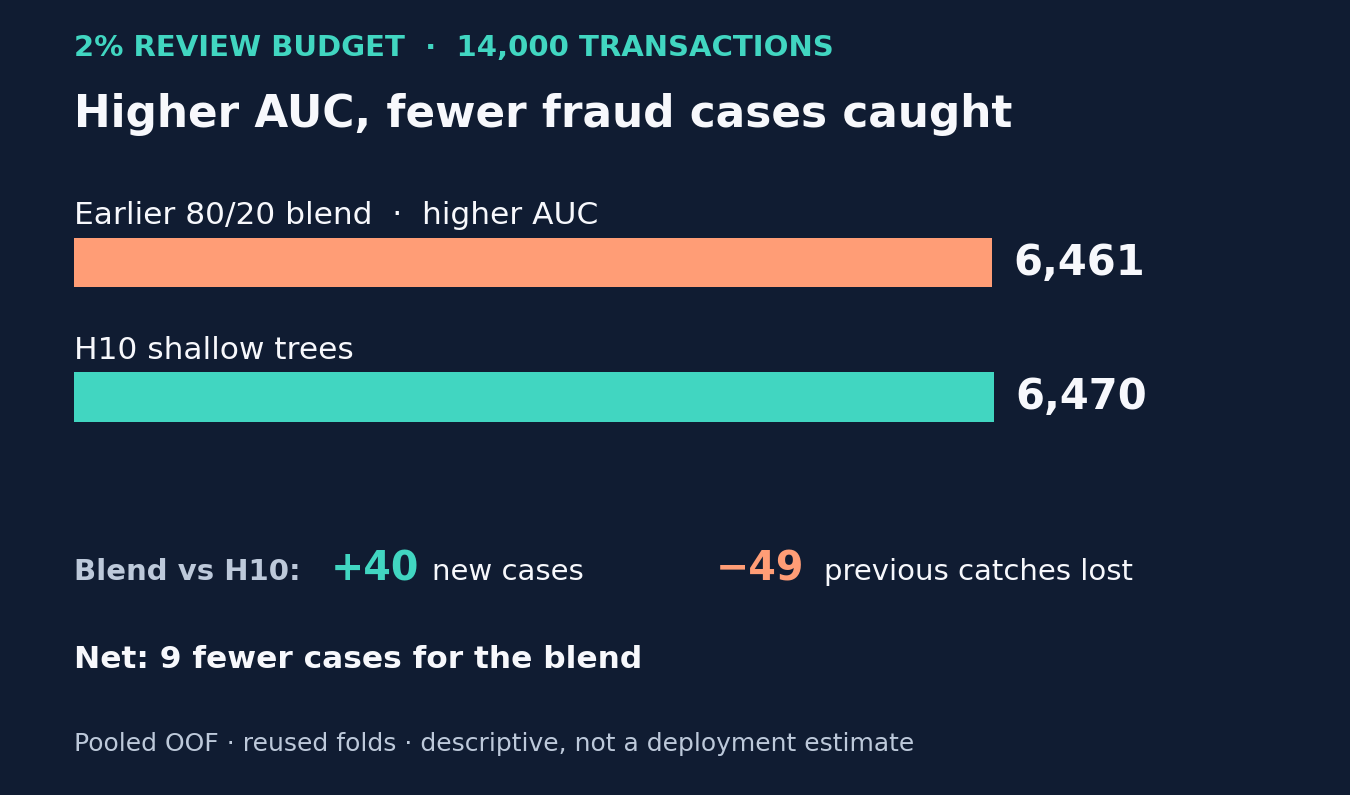

### Choose a path

| If you want to… | Start here |
|---|---|
| See how AUC and review capacity compare | Section 22, review-budget analysis |
| Fit the included H10 model | Section 17; use **Run All**, since earlier cells prepare its inputs |
| Understand the data and validation | Sections 1–6, data and folds |
| Inspect recorded model experiments | Sections 10 and 21, controls and comparisons |

### What the notebook reproduces

The default run fits the five-fold **H10** model. It keeps predictions in temporary storage and does not submit them. The review-budget comparison uses recorded H10 and **earlier 80/20 H10–GLM** out-of-fold predictions; those saved row-level predictions are not distributed here. A later GLM-boost blend scored **0.95142 public AUC**, but its training code and test predictions are not included. These are different model comparisons, not interchangeable scores.

The OOF comparisons reuse development folds. Public scores are exploratory results on the public test split and do not measure final private performance. The supplied data do not establish when every fraud feature becomes available.

The default run fits 31 models; set `CFG['run_research']=False` for ten. A full refit adds one. The primary CSV stays in temporary storage unless `EXPORT_SUBMISSION_TO_WORKING` is enabled in a copy with suitable output visibility.

<a id="s0"></a>

## 0. Run settings

The default run keeps row-level predictions and fold files in temporary storage outside the published output. Two aggregate review-budget tables are copied to the output at the end. To export `submission.csv`, use Copy & Edit, choose output visibility appropriate for competition data, set `EXPORT_SUBMISSION_TO_WORKING = True`, and run all cells. A public copy with this option enabled can expose its predictions and IDs. The notebook never submits a file.

Use `CURRENT_CFG` to change the model that produces the primary `submission.csv`. Its `drop_predictors` removes a raw predictor and all model columns derived from it. Its parameters and split settings are live. The printed report describes the run you actually make; changed settings do not inherit a recorded public score.

`export_mode='cv_average'` averages five fold models for test. `export_mode='full_refit'` retains their OOF evaluation and additionally fits the same recipe on all training rows for the test export. The full refit has no separate OOF score. The default selection and its evidence are described in section 19.

`CFG` controls the original reference and historical experiments. Changing its model or drop settings changes that reference, while the current fit uses `CURRENT_CFG`. Historical diagnostic replays use their own fixed protocols. Disable `run_current_recipe` only if you want the reference CSV restored as the primary export. No cell uploads predictions.

### Current model settings

In [ ]:
EXPORT_SUBMISSION_TO_WORKING = False  # Enable only in a copy whose output visibility you control.

CURRENT_CFG = {'recipe_key': 'h10_small_trees',
 'view': 'digits',
 'model_params': {'n_estimators': 1600,
                  'num_leaves': 4,
                  'learning_rate': 0.03,
                  'random_state': 42,
                  'n_jobs': 4,
                  'min_child_samples': 100,
                  'reg_lambda': 1.0,
                  'subsample': 0.8,
                  'subsample_freq': 1,
                  'colsample_bytree': 0.5,
                  'verbosity': -1,
                  'deterministic': True,
                  'force_col_wise': True},
 'drop_predictors': [],
 'n_splits': 5,
 'split_seed': 42,
 'export_mode': 'cv_average'}

### Reference and historical experiment settings

In [ ]:
CFG = {'competition': 'playground-series-s6e11',
 'title': 'S6E11 Fraud | GLM-Offset Trees & Review Budgets',
 'confirmed': True,
 'task': 'binary',
 'metric': 'auc',
 'target': 'is_fraud',
 'id_col': 'id',
 'positive_class': 1,
 'class_columns': None,
 'split': 'iid',
 'seed': 42,
 'n_splits': 5,
 'n_estimators': 300,
 'num_leaves': 31,
 'learning_rate': 0.05,
 'n_jobs': 4,
 'drop_features': [],
 'category_view': 'auth_method',
 'run_research': True,
 'run_repeated_frequency': False,
 'run_repeated_h4': False,
 'run_candidate_studies': False,
 'run_h5_diagnosis': False,
 'run_overlap_probe': False,
 'run_prospective_audit': False,
 'run_current_recipe': True,
 'run_digit_screen': False,
 'run_digit_audit': False,
 'run_representation_study': False,
 'run_shallow_refit_study': False,
 'run_seed_bag': False,
 'run_glm_study': False}

In [ ]:
import time
notebook_started = time.perf_counter()
import hashlib
import importlib.metadata
import json
import os
from pathlib import Path
import numpy as np
import pandas as pd
from IPython import get_ipython
_shell = get_ipython()
if _shell is not None and hasattr(_shell, "kernel"):
    _shell.run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
from IPython.display import display

plt.rcParams.update({"figure.figsize": (7.4, 3.8), "figure.dpi": 98,
                     "font.size": 10, "axes.spines.top": False, "axes.spines.right": False})

def locate_data():
    override = os.environ.get("LOCAL_DATA")
    candidates = [Path(override)] if override else [
        Path("/kaggle/input/competitions") / CFG["competition"],
        Path("/kaggle/input") / CFG["competition"], Path("data")]
    for path in candidates:
        if all((path / name).is_file() for name in ("train.csv", "test.csv", "sample_submission.csv")):
            return path
    return None

DATA = locate_data()
if Path('/kaggle/working').is_dir():
    prior_root = Path('/kaggle/working').resolve()
    safe_aggregates = {'queue_budget_comparison.csv', 'queue_primary_folds.csv', 'category_fraud_rates.csv', 'experiment_results.csv', 'experiment_fold_deltas.csv'}
    row_formats = {'.csv', '.tsv', '.parquet', '.npy', '.npz', '.pkl', '.pickle', '.feather', '.arrow', '.jsonl'}
    prior_rows = [p for p in prior_root.rglob('*') if p.is_file() and p.suffix.lower() in row_formats and not (p.parent == prior_root and p.name in safe_aggregates)]
    if prior_rows:
        raise RuntimeError('Existing row-level output artifacts found. Start a clean session or remove your own old artifacts before running.')
ready = DATA is not None and CFG["confirmed"]
if not ready:
    raise FileNotFoundError("Attach the S6E11 competition files and set CFG['confirmed']=True. "
                            "For a local run, set LOCAL_DATA to their directory.")
else:
    from sklearn.preprocessing import LabelEncoder, OrdinalEncoder
    from sklearn.model_selection import KFold, StratifiedKFold
    from sklearn.metrics import (roc_auc_score, log_loss, mean_squared_error,
                                 mean_absolute_error, accuracy_score, balanced_accuracy_score)
    from lightgbm import LGBMClassifier, LGBMRegressor
    task, metric = CFG["task"], CFG["metric"]
    allowed = {"binary": {"auc", "logloss", "accuracy", "balanced_accuracy"},
               "multiclass": {"logloss", "accuracy", "balanced_accuracy", "map@3"},
               "regression": {"rmse", "mae", "rmsle"}}
    if task not in allowed or metric not in allowed[task]:
        raise ValueError("Set a supported official task/metric pair in CFG; do not infer the metric.")
    if CFG["split"] != "iid":
        raise ValueError("Replace the split with a group/time-aware design before running this task.")
    train = pd.read_csv(DATA / "train.csv")
    test = pd.read_csv(DATA / "test.csv")
    sample = pd.read_csv(DATA / "sample_submission.csv")
    id_col = CFG["id_col"] or sample.columns[0]
    targets = [c for c in train if c not in test]
    target = CFG["target"] or (targets[0] if len(targets) == 1 else None)
    if target is None or target not in train or target in test:
        raise ValueError(f"Confirm target explicitly; train-only columns: {targets}")
    if id_col not in train or id_col not in test or id_col not in sample:
        raise ValueError("Confirm the ID column in train, test and sample_submission.")
    for name, frame in [("train", train), ("test", test), ("sample", sample)]:
        if frame[id_col].isna().any() or not frame[id_col].is_unique:
            raise ValueError(f"{name} IDs must be nonmissing and unique.")
    if len(sample) != len(test) or set(sample[id_col]) != set(test[id_col]):
        raise ValueError("sample_submission and test must contain the same IDs.")
    if train[target].isna().any():
        raise ValueError("Target contains missing values.")
    schema_features = [c for c in train if c not in {id_col, target}]
    if not schema_features or set(schema_features) != set(test.columns) - {id_col}:
        raise ValueError("Train/test feature columns differ.")
    drop_features = CFG.get("drop_features", [])
    if set(drop_features) - set(schema_features):
        raise ValueError("drop_features contains an unknown column.")
    features = [c for c in schema_features if c not in drop_features]
    if not features:
        raise ValueError("At least one model feature is required.")
    categorical = [c for c in features if not pd.api.types.is_numeric_dtype(train[c])]
    numeric = [c for c in features if c not in categorical]
    print(json.dumps({"competition": CFG["competition"], "task": task, "metric": metric,
                      "target": target, "train_rows": len(train), "test_rows": len(test),
                      "features": len(features)}, indent=2))
    print("Excluded model features:", drop_features or "none")

In [ ]:
"""Presentation helpers only; experiment calculations stay in visible notebook cells."""
import base64
from html import escape
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import HTML, display


COLOURS = {"Original": "#D55E00", "S6E11 train": "#0072B2"}


def setup_style():
    """Apply a light, colourblind-safe style for the notebook's figures."""
    plt.rcParams.update({
        "figure.figsize": (7.3, 4.5), "figure.dpi": 110,
        "savefig.dpi": 150, "font.family": "DejaVu Sans", "font.size": 14,
        "axes.titlesize": 15, "axes.titleweight": "bold", "axes.titlepad": 16,
        "axes.labelsize": 14, "axes.labelpad": 10,
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.edgecolor": "#B8C4CC", "axes.labelcolor": "#233441",
        "text.color": "#14212B", "xtick.color": "#52616E",
        "ytick.color": "#52616E", "xtick.labelsize": 14, "ytick.labelsize": 14,
        "axes.facecolor": "white", "figure.facecolor": "white",
        "grid.color": "#E4EAF0", "grid.linewidth": .7, "axes.axisbelow": True,
        "legend.frameon": False, "legend.fontsize": 14,
        "axes.prop_cycle": plt.cycler(color=["#0072B2", "#D55E00", "#009E73", "#CC79A7"]),
    })


def styled_table(frame, formats=None):
    """Return a compact 13px Styler without changing any table values."""
    styler = frame.style
    if formats:
        styler = styler.format(formats, na_rep="n/a")
    return (styler.set_properties(**{
        "font-size": "13px", "color": "#233441", "padding": "7px 9px",
        "border-bottom": "1px solid #E4EAF0", "background-color": "white",
        "white-space": "nowrap",
    }).set_table_styles([
        {"selector": "", "props": [("display", "block"), ("max-width", "100%"),
                                     ("overflow-x", "auto"), ("font-family", "Arial, sans-serif"),
                                     ("font-size", "13px"), ("border-collapse", "collapse")]},
        {"selector": "th", "props": [("font-size", "13px"), ("background-color", "#F5F8FA"),
                                      ("color", "#233441"), ("padding", "7px 9px"),
                                      ("border-bottom", "1px solid #D5DEE5"),
                                      ("text-align", "left")]},
        {"selector": "caption", "props": [("font-size", "13px"), ("text-align", "left"),
                                           ("color", "#52616E"), ("padding", "6px 0")]},
    ]))


def callout(text):
    """Return the shared information-callout treatment; text is plain text."""
    body = escape(str(text)).replace("\n", "<br/>")
    return HTML('<div class="alert alert-info" style="background:#EEF6FB;'
                'border:1px solid #D3E7F4;border-left:4px solid #0072B2;'
                'border-radius:5px;padding:12px 15px;margin:15px 0;'
                'color:#233441;font-size:14px;line-height:1.55;">' + body + '</div>')


def source_hero(source_summary, amount_quantiles):
    """Plot supplied summary values and amount quantiles; return an unsaved Figure."""
    labels = ("Original", "S6E11 train")
    summary = source_summary.set_index("dataset").loc[list(labels)]
    amounts = amount_quantiles.sort_values("quantile")
    if (amounts[list(labels)] <= 0).any().any():
        raise ValueError("Logarithmic amount display requires positive supplied quantiles.")

    fig, (rates, ecdf) = plt.subplots(2, 1, figsize=(7.3, 8.6))
    fig.subplots_adjust(left=.16, right=.97, top=.86, bottom=.12, hspace=.80)
    # Larger text than the ordinary EDA figures: the first-screen hero also fits a phone.
    fig.suptitle("Original source and S6E11 train", fontsize=18, weight="bold", x=.565)
    values = summary["fraud_rate"].to_numpy() * 100
    rates.bar(labels, values, color=[COLOURS[label] for label in labels], width=.48)
    for position, label in enumerate(labels):
        row = summary.loc[label]
        rates.annotate(f'{row.fraud_rate:.2%}\n{int(row.fraud):,} / {int(row.rows):,}',
                       (position, values[position]), xytext=(0, 9), textcoords="offset points",
                       ha="center", va="bottom", fontsize=15, color="#233441", linespacing=1.35)
    rates.set_ylim(0, max(values.max() * 1.65, .1))
    rates.set_ylabel("Fraud share (%)", fontsize=15)
    rates.set_title("Label prevalence", fontsize=16, loc="left", pad=17)
    rates.tick_params(axis="both", labelsize=15)
    rates.grid(axis="y")
    rates.set_xlim(-.65, 1.65)

    for label, linestyle in zip(labels, ("--", "-")):
        ecdf.plot(amounts[label], amounts["quantile"], label=label,
                  color=COLOURS[label], linestyle=linestyle, linewidth=2.5)
    ecdf.set_xscale("log")
    ecdf.set_ylim(0, 1)
    ecdf.yaxis.set_major_formatter(PercentFormatter(1))
    ecdf.set_xlabel("Transaction amount (USD, log scale)", fontsize=15)
    ecdf.set_ylabel("Cumulative share", fontsize=15)
    ecdf.set_title("Transaction amounts", fontsize=16, loc="left", pad=43)
    ecdf.tick_params(axis="both", labelsize=15)
    ecdf.legend(loc="lower left", bbox_to_anchor=(0, 1.015), ncol=2, fontsize=14,
                borderaxespad=0, handlelength=2.2, columnspacing=1.4)
    ecdf.grid(axis="both", which="major")
    return fig


def show_figure(fig, caption, filename):
    """Save and display a figure, place its caption below, and release it."""
    path = Path(filename)
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path, facecolor="white")
    encoded = base64.b64encode(path.read_bytes()).decode()
    display(HTML('<img src="data:image/png;base64,' + encoded + '" width="730" '
                 'style="max-width:100%;height:auto;" alt="' + escape(str(caption), quote=True) + '"/>'))
    display(HTML('<p style="font-size:13px;line-height:1.5;color:#52616E;'
                 'margin:5px 0 18px;">' + escape(str(caption)) + '</p>'))
    plt.close(fig)
    return None

setup_style()

<a id="s1"></a>

## 1. What is being predicted?

Each row is a transaction. The target is `is_fraud`, with **1 meaning fraud**. The competition scores ROC AUC: how often a positive transaction receives a higher score than a negative one, with half credit for ties. A 0.5 classification threshold is irrelevant to that ranking score.

The training file has 699,960 rows, and the test file has 299,984 rows. The target has 11,689 positive training rows (1.670%). `id` is an identifier and is excluded from modelling.

The dictionary groups all 24 supplied predictors. The supplied files do not establish how the generator computed its scores or when its flags became available.

In [ ]:
dictionary = [('Amounts', 'amount_usd; account_balance_usd', 'USD'),
 ('Timing and activity',
  'hours_since_last_txn; txn_count_last_24h; time_of_day_hour; day_of_week',
  'Hours, count, hour, coded day'),
 ('Customer and card',
  'distance_from_home_km; card_age_months; customer_age',
  'km, months, age'),
 ('Supplied scores and counts',
  'cvv_retry_count; velocity_score; merchant_risk_score; prior_disputes',
  'Counts or supplied scores'),
 ('Categories',
  'merchant_category; card_type; auth_method; channel; device_type',
  'Observed text levels'),
 ('Boolean flags',
  'is_foreign_transaction; is_new_merchant; used_vpn; ip_country_mismatch; '
  'billing_shipping_mismatch; is_ai_generated_scam_attempt',
  'False / True')]
display(styled_table(pd.DataFrame(dictionary, columns=["group", "columns", "units / coding"]).set_index("group")).set_properties(**{"white-space":"normal", "overflow-wrap":"anywhere"}).set_table_styles([{"selector":"th.row_heading", "props":[("white-space","normal"), ("max-width","130px")]}], overwrite=False))

The source does not establish whether the AI flag, risk scores or recent-activity aggregates were available when a transaction was classified. We use them as supplied for this competition and would need a provenance audit before using them in a live fraud system. Their names alone cannot establish leakage.

<a id="s2"></a>

## 2. The source is synthetic too

The organisers identify [Credit Card Fraud Detection 2026](https://www.kaggle.com/datasets/uditjain13/credit-card-fraud-detection-2026) as the source. Its author describes 20,000 NumPy-generated transactions, with no real customer records. The downloaded archive contains the CSV; it does not contain the advertised generator script, so its generation logic has not been independently reconstructed.

The files share the same 24 predictors. The original uses `transaction_id` instead of the competition's `id`; neither identifier is a model feature.

In [ ]:
from scipy.stats import ks_2samp
original_paths = [Path('original/credit_card_fraud_2026.csv'),
    Path('/kaggle/input/credit-card-fraud-detection-2026/credit_card_fraud_2026.csv'),
    Path('/kaggle/input/datasets/uditjain13/credit-card-fraud-detection-2026/credit_card_fraud_2026.csv')]
original_path = next((p for p in original_paths if p.is_file()), None)
if original_path is None:
    raise FileNotFoundError('Attach Credit Card Fraud Detection 2026 to reproduce the source comparison.')
original = pd.read_csv(original_path)
assert set(original[target].unique()) <= {0, 1}
assert set(schema_features) <= set(original.columns)
frames = {'Original': original, 'S6E11 train': train, 'S6E11 test': test}
source_summary = pd.DataFrame([
    dict(dataset=name, rows=len(frame), fraud=int(frame[target].sum()),
         fraud_rate=frame[target].mean(), median_amount=frame.amount_usd.median())
    for name, frame in list(frames.items())[:2]])
amount_quantiles = pd.DataFrame({'quantile': np.linspace(0, 1, 401)})
for name in ['Original', 'S6E11 train']:
    amount_quantiles[name] = frames[name].amount_usd.quantile(amount_quantiles['quantile']).to_numpy()
display(styled_table(source_summary.set_index('dataset'),
    {'rows': '{:,.0f}', 'fraud': '{:,.0f}', 'fraud_rate': '{:.3%}', 'median_amount': '${:.2f}'}))

Both datasets are synthetic. Their fraud shares are similar, but the median amount falls from **USD 57.51 to USD 27.25**.

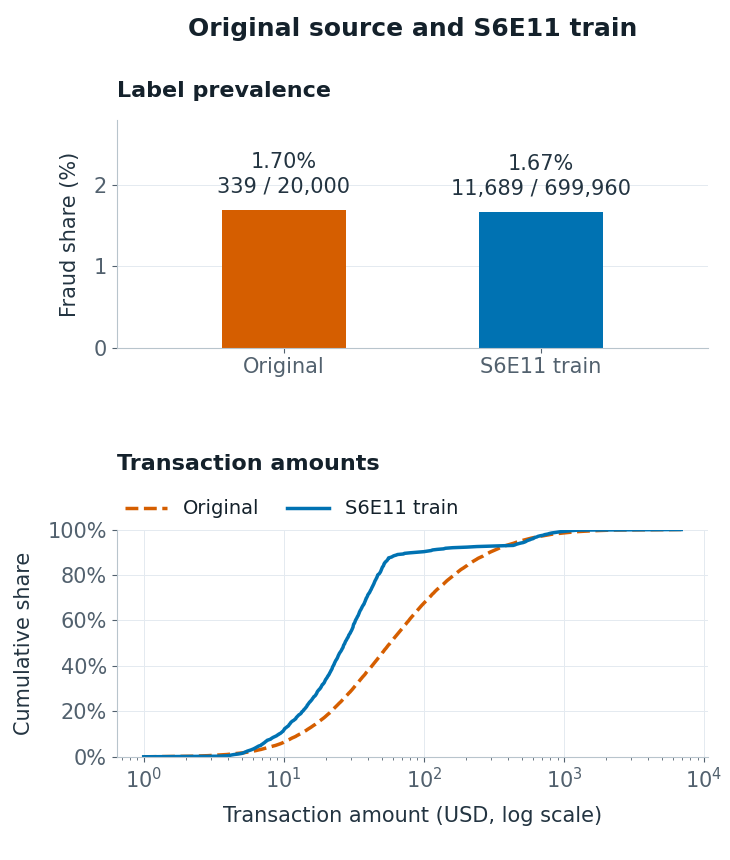

*This snapshot uses the files checked on 1 November 2026. The lower panel joins a 401-point quantile grid on a log amount axis. The calculations above reproduce the numbers from the attached CSVs.*

**Takeaway:** similar label prevalence does not imply matching feature distributions. The amount medians differ by more than a factor of two. We test source transfer in section 8 instead of assuming that more labelled rows must help.

<a id="s3"></a>

## 3. Check every supplied predictor

Check missingness, constants, duplicate feature rows, ID overlap and infinities before fitting. Duplicate checks below use full-row hashes as a screening tool. Zero matches do not prove that the datasets are independent.

In [ ]:
# Audit every supplied predictor, even when a model ablation excludes one.
audit_numeric = [c for c in schema_features if pd.api.types.is_numeric_dtype(train[c])
                 and not pd.api.types.is_bool_dtype(train[c])]
audit_categories = [c for c in schema_features if c not in audit_numeric]
quality = pd.DataFrame({'type': train[schema_features].dtypes.astype(str),
    'missing train': train[schema_features].isna().sum(),
    'missing test': test[schema_features].isna().sum(),
    'distinct train': train[schema_features].nunique(),
    'distinct test': test[schema_features].nunique()})
train_hash = pd.util.hash_pandas_object(train[schema_features], index=False)
test_hash = pd.util.hash_pandas_object(test[schema_features], index=False)
checks = {'duplicate_feature_rows_train': int(train_hash.duplicated().sum()),
    'duplicate_feature_rows_test': int(test_hash.duplicated().sum()),
    'test_rows_matching_train_features': int(test_hash.isin(train_hash).sum()),
    'shared_train_test_ids': len(set(train[id_col]) & set(test[id_col])),
    'constant_train_features': [c for c in schema_features if train[c].nunique(dropna=False) == 1],
    'numeric_infinities_train': int(np.isinf(train[audit_numeric].to_numpy(float)).sum()),
    'numeric_infinities_test': int(np.isinf(test[audit_numeric].to_numpy(float)).sum())}
assert not checks['numeric_infinities_train'] and not checks['numeric_infinities_test']
display(styled_table(quality))
display(styled_table(pd.DataFrame({'check': checks.keys(), 'result': [str(x) for x in checks.values()]}).set_index('check')))
display(callout(f"The training dataset contains {len(train):,} rows, of which "
                f"{int(train[target].sum()):,} are labelled as fraud ({train[target].mean():.3%}). "
                "No threshold is needed to calculate ROC AUC."))

**Takeaway:** the attached files have no missing predictors, constant predictors, numeric infinities or duplicate full feature rows. Train and test IDs are disjoint, and no test full-feature hash matches train. Feature availability needs a separate provenance audit.

<a id="s4"></a>

## 4. Where did the distributions move?

For a numeric predictor, its empirical cumulative distribution function (CDF) gives the fraction of rows at or below each value. The Kolmogorov-Smirnov (KS) distance is the largest vertical gap between two such curves. For text and boolean predictors, total variation is half the sum of the absolute differences in category shares. Both distances run from 0 to 1; compare features within each measure. These marginal checks leave interactions and the target relationship untested.

In [ ]:
# KS is a distance between empirical CDFs, including for tied/discrete values.
# We compare distances, not significance p-values from huge samples.
shift_rows = []
for column in audit_numeric:
    shift_rows.append({'feature': column,
        'source to train': ks_2samp(original[column], train[column]).statistic,
        'train to test': ks_2samp(train[column], test[column]).statistic,
        'source median': original[column].median(),
        'train median': train[column].median(), 'test median': test[column].median()})
numeric_shifts = pd.DataFrame(shift_rows).set_index('feature')
category_shifts = []
for column in audit_categories:
    frequencies = {name: f[column].astype('string').fillna('<missing>').value_counts(normalize=True)
                   for name, f in frames.items()}
    support = frequencies['Original'].index.union(frequencies['S6E11 train'].index).union(frequencies['S6E11 test'].index)
    values = {name: freq.reindex(support, fill_value=0) for name, freq in frequencies.items()}
    category_shifts.append({'feature': column,
        'source to train': float((values['Original'] - values['S6E11 train']).abs().sum()/2),
        'train to test': float((values['S6E11 train'] - values['S6E11 test']).abs().sum()/2)})
category_shifts = pd.DataFrame(category_shifts).set_index('feature')
display(styled_table(numeric_shifts.sort_values('source to train', ascending=False),
                    {c: '{:.4f}' for c in numeric_shifts.columns}))
display(styled_table(category_shifts.sort_values('source to train', ascending=False),
                    {c: '{:.4f}' for c in category_shifts.columns}))

In [ ]:
ordered = numeric_shifts.sort_values('source to train')
fig, ax = plt.subplots(figsize=(7.3, 6.4))
ax.barh([x.replace('_', ' ') for x in ordered.index], ordered['source to train'])
ax.set(xlabel='KS distance: original source to S6E11 train', title='The amount distribution moved most')
ax.grid(axis='x'); fig.tight_layout()
show_figure(fig, 'All 13 numeric predictors are shown. Amount has KS distance '
    f"{numeric_shifts.loc['amount_usd', 'source to train']:.3f}; the largest train-to-test distance is "
    f"{numeric_shifts['train to test'].max():.4f}. These are marginal comparisons, not a guarantee that CV will match the leaderboard.",
    'figures/numeric_shift.png')

**Takeaway:** amount is the clearest source shift (KS 0.3831), followed by account balance (0.1880) and distance from home (0.1593). The largest numeric train/test KS distance is only 0.0038. The competition data will be the main training distribution. Section 8 tests one way to use the original.

<a id="s5"></a>

## 5. Which subsets contain more fraud?

A high fraud rate in a rare subset can be based on few positives. Calculate both counts and 95% Wilson intervals. The saved `category_fraud_rates.csv` covers every level of all five text predictors and six boolean flags. The selected text table is controlled by `category_view`; the table and plot below cover all six flags.

These are exploratory, marginal associations. The intervals describe each subset and are not simultaneous intervals for a search over all features.

In [ ]:
def wilson(positives, count, z=1.959963984540054):
    p = positives / count
    centre = (p + z*z/(2*count)) / (1 + z*z/count)
    half = z*np.sqrt(p*(1-p)/count + z*z/(4*count*count)) / (1 + z*z/count)
    return centre-half, centre+half

strata_rows = []
for column in audit_categories:
    for level, subset in train.groupby(column, observed=True, dropna=False):
        count, positives = len(subset), int(subset[target].sum())
        low, high = wilson(positives, count)
        strata_rows.append(dict(feature=column, level=str(level), rows=count, fraud=positives,
            rate=positives/count, low=low, high=high))
strata = pd.DataFrame(strata_rows)
assert strata.groupby('feature').rows.sum().eq(len(train)).all()
assert strata.groupby('feature').fraud.sum().eq(int(train[target].sum())).all()
# All category/flag strata are saved; choose the displayed category in CFG.
strata.to_csv('category_fraud_rates.csv', index=False)
selected = CFG['category_view']
if selected not in audit_categories:
    raise ValueError('category_view must name a categorical or boolean predictor.')
selected_strata = strata[strata.feature.eq(selected)].copy()
display(styled_table(selected_strata.drop(columns='feature').set_index('level'),
    {'rows':'{:,.0f}', 'fraud':'{:,.0f}', 'rate':'{:.2%}', 'low':'{:.2%}', 'high':'{:.2%}'}))
flag_strata = strata[strata.feature.isin([c for c in audit_categories if pd.api.types.is_bool_dtype(train[c])])]
display(styled_table(flag_strata.set_index(['feature','level']),
    {'rows':'{:,.0f}', 'fraud':'{:,.0f}', 'rate':'{:.2%}', 'low':'{:.2%}', 'high':'{:.2%}'}))

In [ ]:
true_flags = flag_strata[flag_strata.level.eq('True')].sort_values('rate')
short_names = {'is_foreign_transaction':'Foreign transaction', 'is_new_merchant':'New merchant',
    'used_vpn':'Used VPN', 'ip_country_mismatch':'IP country mismatch',
    'billing_shipping_mismatch':'Billing / shipping mismatch',
    'is_ai_generated_scam_attempt':'AI scam flag'}
fig, ax = plt.subplots(figsize=(7.3, 4.7))
positions = np.arange(len(true_flags))
ax.errorbar(true_flags.rate*100, positions,
    xerr=np.vstack([(true_flags.rate-true_flags.low)*100, (true_flags.high-true_flags.rate)*100]),
    fmt='o', capsize=4, color='#0072B2')
ax.set_yticks(positions, [short_names[c] for c in true_flags.feature])
ax.axvline(train[target].mean()*100, color='#D55E00', ls='--', label='All training rows')
ax.set(xlabel='Fraud share when flag is True (%)', title='Several flags mark higher-risk subsets')
ax.grid(axis='x'); ax.legend(loc='lower right'); fig.tight_layout()
show_figure(fig, 'Points show marginal fraud rates; bars are 95% Wilson intervals for each subset. '
    'Counts and both flag states are in the table. AI=True contains 350 fraud labels among 2,299 rows (15.22%). '
    'Correlated features and selection can explain these associations; the chart does not establish causality.',
    'figures/flag_rates.png')

**Takeaway:** `ip_country_mismatch=True` contains 1,866 fraud labels among 11,312 rows (16.50%). The AI flag's true subset has 350 among 2,299 (15.22%, Wilson 13.81% to 16.75%). Neither rate tells us how much new information a flag adds after the other predictors. The ablation in section 8 addresses that narrower question.

In [ ]:
# ID order is not documented event time. Check it before inventing a temporal split.
id_auc = roc_auc_score(train[target], train[id_col])
id_bins = pd.qcut(train[id_col], 20, labels=False, duplicates='drop')
id_summary = train.groupby(id_bins, observed=True)[target].agg(['count', 'sum', 'mean'])
print(f'ID as a score: ROC AUC {id_auc:.5f}; 20 ordered-bin fraud shares '
      f"{id_summary['mean'].min():.3%} to {id_summary['mean'].max():.3%}.")

**Split check:** ID alone has AUC 0.49855, and fraud share across 20 ordered ID bins ranges from 1.563% to 1.814%. ID order is not documented transaction time. Without a documented time variable, shuffled stratified folds are the starting assumption.

<a id="s6"></a>

## 6. Freeze validation before testing ideas

Assign every row to one of five stratified folds, shuffled with seed 42. Every true-label recipe comparison in sections 7, 8, 12, 13, 15 and 18 uses these same held-out rows. Save a fingerprint of IDs, labels and assignments so a later run can verify the split.

There is no customer identifier for a group split and no documented event timestamp for a temporal split. The split treats rows as independent and identically distributed (IID). That is a competition assumption; it does not estimate performance on future bank transactions.

In [ ]:
if ready:
    encoder = None
    probability_order = None
    if task == "regression":
        y = train[target].to_numpy(dtype=float)
        if not np.isfinite(y).all() or (metric == "rmsle" and (y < 0).any()):
            raise ValueError("Invalid target for the configured regression metric.")
    else:
        encoder = LabelEncoder().fit(train[target])
        y = encoder.transform(train[target])
        if (task == "binary" and len(encoder.classes_) != 2) or (task == "multiclass" and len(encoder.classes_) < 3):
            raise ValueError("Task and observed class count disagree.")
        if task == "binary":
            if CFG["positive_class"] not in encoder.classes_:
                raise ValueError("Set positive_class explicitly, with the same type as the training labels.")
            y = (train[target].to_numpy() == CFG["positive_class"]).astype(int)
            probability_order = [next(c for c in encoder.classes_ if c != CFG["positive_class"]), CFG["positive_class"]]
        else:
            probability_order = encoder.classes_.tolist()
        if pd.Series(y).value_counts().min() < CFG["n_splits"]:
            raise ValueError("Too few examples of a class for n_splits.")
    splitter = (KFold(CFG["n_splits"], shuffle=True, random_state=CFG["seed"]) if task == "regression"
                else StratifiedKFold(CFG["n_splits"], shuffle=True, random_state=CFG["seed"]))
    folds = list(splitter.split(train, y))
    fold_ids = np.full(len(train), -1, dtype=np.int16)
    for fold, (_, validation) in enumerate(folds):
        fold_ids[validation] = fold
    data_fp = hashlib.sha256(pd.util.hash_pandas_object(train[[id_col, target]], index=False).values.tobytes()).hexdigest()
    split_fp = hashlib.sha256(data_fp.encode() + fold_ids.tobytes()).hexdigest()
    print("Split: IID", CFG["n_splits"], "folds, seed", CFG["seed"], "fingerprint", split_fp[:12])

    def score(actual, prediction):
        if metric == "auc": return float(roc_auc_score(actual, prediction[:, 1]))
        if metric == "logloss": return float(log_loss(actual, prediction, labels=np.arange(prediction.shape[1])))
        if metric == "accuracy": return float(accuracy_score(actual, prediction.argmax(axis=1)))
        if metric == "balanced_accuracy": return float(balanced_accuracy_score(actual, prediction.argmax(axis=1)))
        if metric == "map@3":
            top = np.argsort(-prediction, axis=1, kind="stable")[:, :3]
            return float(((top == actual[:, None]) / np.arange(1, top.shape[1] + 1)).sum(axis=1).mean())
        if metric == "mae": return float(mean_absolute_error(actual, prediction))
        if metric == "rmsle": return float(np.sqrt(mean_squared_error(np.log1p(actual), np.log1p(np.maximum(prediction, 0)))))
        return float(np.sqrt(mean_squared_error(actual, prediction)))

<a id="s7"></a>

## 7. Measure the baseline

Fit category encoders only on the training part of each fold. Unknown categories map to -1. LightGBM uses native categorical columns, 300 trees, 31 leaves and learning rate 0.05. There is no early stopping on outer validation labels.

Collect predictions only where a row was held out, then calculate pooled OOF AUC. Fold scores describe split variation; their standard deviation is not an improvement threshold.

In [ ]:
if ready:
    shape = () if task == "regression" else (len(np.unique(y)),)
    oof = np.full((len(train),) + shape, np.nan)
    test_prediction = np.zeros((len(test),) + shape)
    fold_scores = []
    cat_indices = list(range(len(numeric), len(features)))

    def matrix(frame, category_encoder=None, fit=False):
        numbers = frame[numeric].to_numpy(dtype=np.float32)
        if not categorical: return pd.DataFrame(numbers, columns=numeric, index=frame.index), None
        categories = frame[categorical].astype("string").fillna("<missing>").astype(str)
        if fit:
            category_encoder = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
            codes = category_encoder.fit_transform(categories)
        else:
            codes = category_encoder.transform(categories)
        result = pd.DataFrame(np.column_stack([numbers, codes]).astype(np.float32),
                              columns=numeric + categorical, index=frame.index)
        return result, category_encoder

    for fold, (fitting, validation) in enumerate(folds):
        X_fit, category_encoder = matrix(train.iloc[fitting], fit=True)
        X_valid, _ = matrix(train.iloc[validation], category_encoder)
        X_test, _ = matrix(test, category_encoder)
        parameters = dict(n_estimators=CFG["n_estimators"], num_leaves=CFG["num_leaves"],
                          learning_rate=CFG["learning_rate"], random_state=CFG["seed"],
                          n_jobs=CFG["n_jobs"], verbosity=-1, deterministic=True, force_col_wise=True)
        if task == "regression":
            model = LGBMRegressor(**parameters, objective="regression_l1" if metric == "mae" else "regression")
            fit_y = np.log1p(y[fitting]) if metric == "rmsle" else y[fitting]
        else:
            model = LGBMClassifier(**parameters)
            fit_y = y[fitting]
        model.fit(X_fit, fit_y, categorical_feature=cat_indices)
        if task == "regression":
            valid_pred, test_pred = model.predict(X_valid), model.predict(X_test)
            if metric == "rmsle":
                valid_pred, test_pred = np.maximum(np.expm1(valid_pred), 0), np.maximum(np.expm1(test_pred), 0)
        else:
            valid_pred, test_pred = model.predict_proba(X_valid), model.predict_proba(X_test)
        oof[validation] = valid_pred
        test_prediction += test_pred / len(folds)
        fold_scores.append(score(y[validation], valid_pred))
        print(f"Fold {fold}: {metric} = {fold_scores[-1]:.7f}")
    if not np.isfinite(oof).all() or not np.isfinite(test_prediction).all():
        raise ValueError("Predictions are incomplete or nonfinite.")
    pooled_score = score(y, oof)
    print(f"Pooled OOF {metric}: {pooled_score:.7f}")
    print(f"Fold mean: {np.mean(fold_scores):.7f}; fold SD: {np.std(fold_scores, ddof=1):.7f}")
    print("Fold SD describes variation between folds. It is not a significance threshold for a model change.")

<a id="s8"></a>

## 8. Test three hypotheses

Write down the comparisons before interpreting their scores:

1. **Does the original add useful signal?** Add the probability from a source-only LightGBM teacher (100 trees, 15 leaves). Keep the same five folds and 300-tree student. Retain the feature only if the paired results support it.
2. **Does the AI flag contribute after the other inputs?** Remove only `is_ai_generated_scam_attempt`. Keep the same five folds and baseline settings. Interpret the difference as predictive contribution under this recipe.
3. **Do category frequencies work better than native categories?** Replace each of the five text columns with its frequency in the fitting rows. Map unseen values to 0. Keep boolean flags, all other inputs and the 300-tree budget unchanged. LightGBM treats these frequencies as numeric inputs. Validation and test rows never contribute to the frequency maps.

The teacher fits on the original source labels; competition labels train the student. Before fitting, exclude source rows whose full predictor hash matches either competition file. The competition was generated from this source, so the datasets may still be related even with no exact matches. Treat the result as source transfer within this competition, rather than validation on an independent dataset. The hash check says nothing about the generator's logic.

Frequency encoding uses no target labels, but it replaces category identity with a numeric frequency order. Equal frequencies merge categories. A difference from the baseline therefore measures this whole representation choice, rather than the isolated value of rarity. The [LightGBM categorical guide](https://lightgbm.readthedocs.io/en/stable/Advanced-Topics.html#categorical-feature-support) describes how native category splits differ from numeric thresholds.

These are exploratory comparisons on a shared development split. There is no nested model-selection estimate, and the five fold deltas are not five independent replications.

In [ ]:
"""Fixed-budget experiments on exactly the baseline's held-out folds."""
import time
research_started = time.perf_counter()
experiment_rows = [dict(recipe='Baseline', auc=pooled_score, delta=0.0)]
experiment_fold_deltas = {}
research_predictions = {}

def experiment_matrices(fitting_frame, other_frames, columns):
    cats = [c for c in columns if not pd.api.types.is_numeric_dtype(fitting_frame[c])]
    nums = [c for c in columns if c not in cats]
    enc = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
    if cats:
        enc.fit(fitting_frame[cats].astype('string').fillna('<missing>').astype(str))
    result = []
    for frame in [fitting_frame] + other_frames:
        values = frame[nums].to_numpy(dtype=np.float32)
        if cats:
            codes = enc.transform(frame[cats].astype('string').fillna('<missing>').astype(str))
            values = np.column_stack([values, codes]).astype(np.float32)
        result.append(pd.DataFrame(values, columns=nums+cats, index=frame.index))
    return result, list(range(len(nums), len(columns)))

def frequency_matrices(fitting_frame, other_frames, columns):
    # Only the fitting rows determine each map. No labels enter the encoding.
    cats = [c for c in columns if not pd.api.types.is_numeric_dtype(fitting_frame[c])]
    nums = [c for c in columns if c not in cats]
    maps = {c: fitting_frame[c].astype('string').fillna('<missing>')
              .value_counts(normalize=True) for c in cats}
    result = []
    for frame in [fitting_frame] + other_frames:
        values = frame[nums].to_numpy(dtype=np.float32)
        codes = np.column_stack([
            frame[c].astype('string').fillna('<missing>').map(maps[c])
                 .fillna(0.0).to_numpy(dtype=np.float32) for c in cats]) if cats else np.empty((len(frame), 0))
        result.append(pd.DataFrame(np.column_stack([values, codes]).astype(np.float32),
                                   columns=nums+cats, index=frame.index))
    # Frequencies are ordinary numeric inputs, with no native categorical columns.
    return result, []

def evaluate_variant(name, fitting_frame, test_frame, columns, representation='native'):
    variant_oof = np.full(len(train), np.nan)
    variant_test = np.zeros(len(test))
    deltas = []
    for fold, (fitting, validation) in enumerate(folds):
        transform = frequency_matrices if representation == 'frequency' else experiment_matrices
        (a, b, c), cat_idx = transform(
            fitting_frame.iloc[fitting], [fitting_frame.iloc[validation], test_frame], columns)
        fitted = LGBMClassifier(**parameters).fit(a, y[fitting], categorical_feature=cat_idx)
        variant_oof[validation] = fitted.predict_proba(b)[:, 1]
        variant_test += fitted.predict_proba(c)[:, 1] / len(folds)
        deltas.append(roc_auc_score(y[validation], variant_oof[validation])
                      - roc_auc_score(y[validation], oof[validation, 1]))
        print(f'{name}, fold {fold}: delta {deltas[-1]:+.6f}')
    assert np.isfinite(variant_oof).all() and np.isfinite(variant_test).all()
    auc = roc_auc_score(y, variant_oof)
    experiment_rows.append(dict(recipe=name, auc=auc, delta=auc-pooled_score))
    experiment_fold_deltas[name] = deltas
    research_predictions[name] = (variant_oof, variant_test)

if CFG['run_research']:
    # No competition labels enter this teacher. Exact feature-row matches are excluded.
    source_hash = pd.util.hash_pandas_object(original[schema_features], index=False)
    competition_hash = pd.util.hash_pandas_object(
        pd.concat([train[schema_features], test[schema_features]], ignore_index=True), index=False)
    source_overlap = source_hash.isin(competition_hash)
    source_fit = original.loc[~source_overlap]
    print('Source rows excluded by full-feature hash match:', int(source_overlap.sum()))
    (a, b, c), cat_idx = experiment_matrices(source_fit, [train, test], features)
    teacher_parameters = {**parameters, 'n_estimators': 100, 'num_leaves': 15}
    teacher = LGBMClassifier(**teacher_parameters).fit(
        a, source_fit[target].astype(int), categorical_feature=cat_idx)
    teacher_train, teacher_test = teacher.predict_proba(b)[:, 1], teacher.predict_proba(c)[:, 1]
    teacher_auc = roc_auc_score(y, teacher_train)
    print(f'Source-only teacher AUC: {teacher_auc:.7f}')
    evaluate_variant('Add source teacher',
        train.assign(source_teacher_probability=teacher_train),
        test.assign(source_teacher_probability=teacher_test),
        features + ['source_teacher_probability'])
    flag = 'is_ai_generated_scam_attempt'
    if flag in features:
        evaluate_variant('Drop AI flag', train, test, [c for c in features if c != flag])
    else:
        print('AI flag already excluded in CFG; its ablation is skipped.')
    print('Frequency-encoded columns:', categorical)
    evaluate_variant('Frequency encoding', train, test, features, representation='frequency')
else:
    print('Research disabled in CFG. The baseline still runs and exports predictions.')
experiment_results = pd.DataFrame(experiment_rows).set_index('recipe')
display(styled_table(experiment_results, {'auc':'{:.7f}', 'delta':'{:+.7f}'}))
if experiment_fold_deltas:
    display(styled_table(pd.DataFrame(experiment_fold_deltas).rename_axis('fold'),
                         {name:'{:+.6f}' for name in experiment_fold_deltas}))
print(f'Research cells: {time.perf_counter()-research_started:.1f} seconds on this machine.')

In [ ]:
"""Plot measured comparisons; this cell does not fit or select a model."""
if experiment_fold_deltas:
    names = list(experiment_fold_deltas)
    labels = {'Add source teacher': 'Source teacher', 'Drop AI flag': 'Drop AI flag',
              'Frequency encoding': 'Frequency encoding'}
    fig, ax = plt.subplots(figsize=(7.3, 4.4))
    for row, name in enumerate(names):
        values = np.asarray(experiment_fold_deltas[name])
        ax.scatter(values, row + np.linspace(-.11, .11, len(values)),
                   s=37, color='#0072B2', alpha=.8,
                   label='Individual folds' if row == 0 else None)
        ax.scatter(experiment_results.loc[name, 'delta'], row, marker='D',
                   s=65, color='#14212B', zorder=4,
                   label='Pooled OOF' if row == 0 else None)
    ax.axvline(0, color='#52616E', linewidth=1, linestyle='--')
    ax.set_yticks(range(len(names)), [labels.get(name, name) for name in names])
    ax.set_ylim(-.5, len(names)-.5)
    ax.invert_yaxis()
    ax.set(title='Change from the native-category baseline', xlabel='AUC difference')
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:+.3f}'))
    ax.grid(axis='x')
    ax.legend(loc='upper center', bbox_to_anchor=(.5, -.30), ncol=2, fontsize=14)
    fig.subplots_adjust(left=.32, right=.97, top=.82, bottom=.35)
    show_figure(fig,
        'Small circles show each fold difference; black diamonds show pooled OOF differences. '
        'Positive values favour the variant. Pooled AUC compares all held-out rows together, '
        'so its difference is not the mean of the five fold differences. '
        'The folds share training rows and are not independent replications.',
        'experiment_comparisons.png')

### Check the frequency pipeline with shuffled labels

Permute the labels once with seed 0, then rebuild the complete frequency pipeline. This control constructs new stratified folds from the shuffled labels. The three true-label comparisons above retain their frozen original folds. Frequencies still use fitting rows only, and the model still fits all 300 trees.

The diagnostic rule remains an absolute AUC distance below 0.003 from 0.5. A single pass cannot certify a clean pipeline; the archive explains the scale of that cutoff. This control also cannot establish when the supplied predictors became available.

In [ ]:
"""Repeat the complete frequency pipeline after shuffling labels."""
frequency_control = None
if CFG['run_research']:
    shuffled_y = np.random.RandomState(0).permutation(y)
    # This control re-stratifies after shuffling, like the earlier LightGBM control.
    # The true-label folds used for the three model comparisons stay unchanged.
    control_folds = list(StratifiedKFold(CFG['n_splits'], shuffle=True,
                                       random_state=CFG['seed']).split(train, shuffled_y))
    control_oof = np.full(len(train), np.nan)
    control_fold_ids = np.full(len(train), -1, dtype=np.int16)
    control_scores = []
    for k, (fitting, validation) in enumerate(control_folds):
        (a, b), cats = frequency_matrices(train.iloc[fitting],
                                         [train.iloc[validation]], features)
        fitted = LGBMClassifier(**parameters).fit(a, shuffled_y[fitting],
                                                categorical_feature=cats)
        control_oof[validation] = fitted.predict_proba(b)[:, 1]
        control_fold_ids[validation] = k
        control_scores.append(roc_auc_score(shuffled_y[validation], control_oof[validation]))
        print(f'Frequency control, fold {k}: AUC {control_scores[-1]:.7f}')
    assert np.isfinite(control_oof).all() and (control_fold_ids >= 0).all()
    frequency_control = {'auc': float(roc_auc_score(shuffled_y, control_oof)),
                         'fold_auc': [float(v) for v in control_scores],
                         'permutation_seed': 0, 're_stratified_after_shuffle': True}
    print(f"The shuffled-label frequency pipeline has pooled AUC {frequency_control['auc']:.7f}.")
    print('This single control cannot certify absence of leakage or event-time feature availability.')
else:
    print('The frequency control is skipped because run_research is False.')

Recorded result with the default settings: baseline OOF AUC is 0.9450912. The source teacher alone scores 0.9276153, but adding its probability reduces student AUC to 0.9414197 (delta **-0.0036715**). All five fold deltas are negative. This 100-tree teacher is rejected for this baseline; the result does not rule out other uses of the source.

Removing the AI flag gives 0.9437649 (delta **-0.0013263**), also lower on every fold. Keep the supplied flag in this competition baseline. This result says nothing by itself about causality or availability before a transaction is classified.

Frequency encoding scores 0.9452147 (delta +0.0001236), with 3 positive and 2 negative fold differences. The full shuffled-label frequency control scores 0.5058717, outside the unchanged +/-0.003 diagnostic band. The variant **stays on hold** and receives no submission. That single result does not establish leakage. This comparison leaves the reference export unchanged. The archive records five additional full controls for this frequency recipe. Those runs have not calibrated the diagnostic or cleared the candidate. If the diagnostic is resolved in a separate study, a second predeclared true-label split can test whether the small gain persists. This exploratory comparison does not establish a reliable improvement.

If you change the configuration, use the computed tables above as your run's results. The paragraph records the default recipe, not every possible fork.

<a id="s9"></a>

## 9. Export the reference and preserve its history

In temporary storage, align the reference predictions to `sample_submission.csv` by ID. Preserve them as `reference_submission.csv`, with reference OOF/test arrays, folds, fingerprint, versions and metrics. Section 17 later replaces the primary `submission.csv` with the current recipe after its checks. The current report and final manifest identify the primary model; the reference arrays keep their historical meaning.

In [ ]:
if ready:
    submission = sample.copy()
    prediction_columns = [c for c in sample if c != id_col]
    order = pd.Index(test[id_col]).get_indexer(sample[id_col])
    aligned = test_prediction[order]
    if task == "regression":
        if len(prediction_columns) != 1: raise ValueError("Expected one regression prediction column.")
        submission[prediction_columns[0]] = aligned
    elif task == "binary" and metric in {"auc", "logloss"} and len(prediction_columns) == 1:
        submission[prediction_columns[0]] = aligned[:, 1]
    elif metric in {"accuracy", "balanced_accuracy", "map@3"} and len(prediction_columns) == 1:
        if task == "binary":
            negative = next(c for c in encoder.classes_ if c != CFG["positive_class"])
            labels = np.array([negative, CFG["positive_class"]])
        else: labels = encoder.classes_
        if metric == "map@3":
            indices = np.argsort(-aligned, axis=1, kind="stable")[:, :3]
            submission[prediction_columns[0]] = [" ".join(map(str, labels[row])) for row in indices]
        else: submission[prediction_columns[0]] = labels[aligned.argmax(axis=1)]
    else:
        mapping = CFG["class_columns"]
        if task != "multiclass" or not mapping or set(mapping) != set(prediction_columns):
            raise ValueError("Set class_columns as {submission_column: class_label} for class probabilities.")
        if set(mapping.values()) != set(encoder.classes_):
            raise ValueError("class_columns must cover each class exactly once.")
        for column in prediction_columns:
            submission[column] = aligned[:, int(encoder.transform([mapping[column]])[0])]
    if submission[prediction_columns].isna().any().any(): raise ValueError("Submission contains missing predictions.")
    import tempfile
    output = Path(tempfile.mkdtemp(prefix="s6e11-run-", dir="/tmp")).resolve()
    public_output = Path("/kaggle/working").resolve() if Path("/kaggle/working").is_dir() else Path("artifacts/public").resolve()
    if output == public_output or public_output in output.parents:
        raise RuntimeError("The scratch directory must be outside the public output directory.")
    output.mkdir(parents=True, exist_ok=True)
    submission.to_csv(output / "submission.csv", index=False)
    pd.DataFrame({id_col: train[id_col], "fold": fold_ids}).to_csv(output / "folds.csv", index=False)
    np.save(output / "oof.npy", oof)
    np.save(output / "test.npy", test_prediction)
    report = {"config": CFG, "data_fp": data_fp, "split_fp": split_fp, "pooled_oof": pooled_score,
              "fold_scores": fold_scores, "features": features, "checks": checks,
              "classes": None if encoder is None else encoder.classes_.tolist(),
              "probability_order": None if probability_order is None else [str(c) for c in probability_order],
              "libraries": {name: importlib.metadata.version(name)
                            for name in ("numpy", "pandas", "scikit-learn", "lightgbm", "matplotlib")}}
    (output / "metrics.json").write_text(json.dumps(report, indent=2, ensure_ascii=False))
    print("Saved artifacts:", output.resolve())
    print("Row-level predictions are kept in temporary storage for this run.")

In [ ]:
import shutil
shutil.copyfile(output/'submission.csv',output/'reference_submission.csv')
s10_reference_metrics=json.loads((output/'metrics.json').read_text())
s10_reference_metrics['artifact_scope']='Reference model only; submission_manifest.json identifies the final primary CSV and its model report.'
(output/'metrics.json').write_text(json.dumps(s10_reference_metrics,indent=2))
(output/'reference_metrics.json').write_text(json.dumps(s10_reference_metrics,indent=2))
print('Reference export preserved as reference_submission.csv. Section 17 writes the primary current-model file.')

In [ ]:
for name, (variant_oof, variant_test) in research_predictions.items():
    stem = name.lower().replace(' ', '_')
    np.save(output / (stem + '_oof.npy'), variant_oof)
    np.save(output / (stem + '_test.npy'), variant_test)
if frequency_control is not None:
    np.save(output / 'frequency_control_oof.npy', control_oof)
    np.save(output / 'frequency_control_labels.npy', shuffled_y)
    np.save(output / 'frequency_control_fold_ids.npy', control_fold_ids)
    (output / 'frequency_control.json').write_text(json.dumps(frequency_control, indent=2))
experiment_results.to_csv(output / 'experiment_results.csv')
pd.DataFrame(experiment_fold_deltas).to_csv(output / 'experiment_fold_deltas.csv', index_label='fold')
print(f'Elapsed time through the reference export: {time.perf_counter()-notebook_started:.1f} seconds.')

### Record the first submission and the later result

The first baseline has OOF AUC 0.9450912. Kaggle accepted its first submission (reference 57859978) with a public AUC of **0.94587**. In the [public leaderboard](https://www.kaggle.com/competitions/playground-series-s6e11/leaderboard) snapshot taken on 1 November 2026 at 05:37 UTC, it ranked 27th of 32 teams. The separate organiser benchmark scored 0.94241 and is excluded from that team count; the leader scored 0.94945. Our score was 0.00346 above the benchmark and 0.00358 below the leader. This is an initial reference with room to improve.

The public board uses about 20% of test; the remaining 80% determines the private standings. This early position will change as teams submit. Research variants are evaluated on the frozen folds before any submission decision; their OOF scores are not leaderboard scores. This notebook records the snapshot without refreshing it.

A second accepted submission, reference 57876877, uses the fixed H5 recipe from section 10 and scores **0.94709**. At 15:57 UTC on 1 November, the archived public board placed it 94th of 166 ranked teams, excluding the organiser benchmark. That is a different field from the early snapshot above. The archive records the separate review, its limitations and the exact submitted file. H6 was not included. The preserved reference export above provides the reproducible 300-tree predictions. Section 17 produces the primary current-model CSV. Section 10 records the later H9 result.

Further work should preserve the frozen comparisons, investigate feature availability and test specific hypotheses before viewing new public scores. The frequency and historical XGBoost candidates remain held. The historical H5 operational decision neither clears those recipes nor resolves all possible leakage.

The source is synthetic, event-time availability is unresolved, and the public board covers only part of test. These limits remain even when a CV comparison looks consistent.

<a id="s10"></a>
<a id="s11"></a>
<a id="s12"></a>
<a id="s13"></a>
<a id="s14"></a>
<a id="s15"></a>
<a id="s16"></a>

## 10. Earlier experiments and controls

A single shuffled-label score can vary by chance. The old ±0.003 rule was an operational filter, not a calibrated test. The recorded model decisions are:

| Historical recipe | Recorded result | Decision |
|---|---|---|
| H5, 600 trees | OOF 0.9464870; shuffled AUC 0.5064052 | Original HOLD; a later separate audit supported one public probe at 0.94709 |
| H6, flag count | +0.0001930 OOF over H5 | Below the fixed gain gate; not submitted |
| H9, value and digit encodings | Public 0.95009 | Passed its separate recorded audit |
| H10, shallow trees | Public 0.95095 | Original HOLD remains; a later audit supported a separate probe. H10 CV is the included default |

All comparisons reuse development data. A passed control is a limited check, not proof of no leakage. The full earlier notebook is available via Version History → Version 41.

The later H5 review used overlapping holdouts and controls specified after the original failure. It supported one exploratory probe. Shuffled-label and deliberate-leak controls for the frequency and XGBoost recipes used different protocols and should not be pooled.

H6 added a row-local count of six flags; its gain missed the +0.0005 gate. H9 used fitting-row labels with inner cross-fitting and passed a separate audit; that audit does not rule out all leakage. The value and digit ablations were motivated by [goodpjw2008](https://www.kaggle.com/code/goodpjw2008/s6e11-part-3-digits-leak-the-label-lb-0-95113) and [Alex Chilton](https://www.kaggle.com/code/alexchilton/credit-card-fraud-lb-0-9496-shallow-tree-stack); our recipes differ.

To read the historical notes, open **Output → model_studies_archive.html**, then use the file preview's download icon. It opens a readable archive in a new tab.

In [ ]:
# A fixed score under random assignment of n1 positive labels has the Mann-Whitney
# null SD below (untied ranks). This is a reference, not a refitted-OOF null law.
n1 = int(y.sum()); n0 = len(y)-n1
fixed_score_null_sd = np.sqrt((n0+n1+1)/(12*n0*n1))
print(f'Fixed-score, untied-rank reference SD: {fixed_score_null_sd:.5f}')
print(f'A +/-0.003 band is only {0.003/fixed_score_null_sd:.2f} reference SDs wide.')

In [ ]:
recorded_controls = {'recorded_date': '1 November 2026',
 'scope': 'Two separately measured protocols; default display does not refit them.',
 'seeds': [11, 23, 47, 101, 211],
 'rule': 'abs(AUC-.5)<.003, unchanged',
 'pipelines': {'frequency': {'label': 'LightGBM with fitting-fold frequencies',
                             'fold_protocol': 'Re-stratify each permuted label vector, 5 '
                                              'folds, split seed42',
                             'device': 'CPU',
                             'model': {'n_estimators': 300,
                                       'num_leaves': 31,
                                       'learning_rate': 0.05,
                                       'random_state': 42,
                                       'n_jobs': 4,
                                       'verbosity': -1,
                                       'deterministic': True,
                                       'force_col_wise': True},
                             'libraries': {'lightgbm': '4.6.0',
                                           'numpy': '2.2.6',
                                           'pandas': '2.2.3',
                                           'scikit-learn': '1.6.1'},
                             'train_sha256': '87eaa10b8d17a7e4f657b8da1c66242431338bdd8b6ad45861521ac0c0e9fbd5',
                             'private_report_sha256': '0445fcd3b678a8357f94e9b05e7154d124d83241cfcbbb9d86335f13977098d9',
                             'arms': [{'seed': 11,
                                       'control': 'shuffle',
                                       'auc': 0.49925097751324077,
                                       'fold_auc': [0.501899894322263,
                                                    0.5044101411303079,
                                                    0.4964144784950273,
                                                    0.49194702229016374,
                                                    0.502051737360168]},
                                      {'seed': 23,
                                       'control': 'shuffle',
                                       'auc': 0.4999769529649386,
                                       'fold_auc': [0.49882136987150455,
                                                    0.502196044202171,
                                                    0.5033258263615114,
                                                    0.5022828200204867,
                                                    0.4941099299525646]},
                                      {'seed': 47,
                                       'control': 'shuffle',
                                       'auc': 0.4903986519044923,
                                       'fold_auc': [0.49056051600415523,
                                                    0.4856697057348496,
                                                    0.49274912261576775,
                                                    0.49152356313258255,
                                                    0.4914487453032307]},
                                      {'seed': 101,
                                       'control': 'shuffle',
                                       'auc': 0.5025771868597659,
                                       'fold_auc': [0.49919775812062767,
                                                    0.5058995997738618,
                                                    0.5061098146015494,
                                                    0.4927213552860613,
                                                    0.5096328957356702]},
                                      {'seed': 211,
                                       'control': 'shuffle',
                                       'auc': 0.5002233806571335,
                                       'fold_auc': [0.5000682282190876,
                                                    0.5066768628421493,
                                                    0.4878527557029431,
                                                    0.500113528653181,
                                                    0.5064020434915212]},
                                      {'seed': 11,
                                       'control': 'target copy leak',
                                       'auc': 1.0,
                                       'fold_auc': [1.0000000000000002,
                                                    1.0,
                                                    1.0,
                                                    0.9999999999999999,
                                                    1.0]}]},
               'xgboost': {'label': 'Historical XGBoost with cross-fitted target '
                                    'encoding',
                           'fold_protocol': 'Original true-label stratified folds held '
                                            'fixed under all permutations',
                           'device': 'cuda',
                           'model': {'n_estimators': 1200,
                                     'learning_rate': 0.02,
                                     'max_depth': 6,
                                     'min_child_weight': 5,
                                     'subsample': 0.8,
                                     'colsample_bytree': 0.4,
                                     'reg_lambda': 2.0,
                                     'reg_alpha': 0.1,
                                     'max_bin': 1024,
                                     'tree_method': 'hist',
                                     'device': 'cuda',
                                     'eval_metric': 'auc',
                                     'random_state': 42,
                                     'n_jobs': 4},
                           'libraries': {'xgboost': '3.4.1',
                                         'scikit-learn': '1.6.1',
                                         'numpy': '2.1.3',
                                         'pandas': '2.3.3',
                                         'scipy': '1.16.3'},
                           'train_sha256': '87eaa10b8d17a7e4f657b8da1c66242431338bdd8b6ad45861521ac0c0e9fbd5',
                           'private_report_sha256': 'b2f48efe7417be7cb0464214e91667cd3aae810988289a883712c90234c83c4f',
                           'arms': [{'seed': 11,
                                     'control': 'shuffle',
                                     'auc': 0.5037117612418591,
                                     'fold_auc': [0.5035042044399397,
                                                  0.493227635673,
                                                  0.5070754373127241,
                                                  0.5013884384815226,
                                                  0.5137934035202791]},
                                    {'seed': 23,
                                     'control': 'shuffle',
                                     'auc': 0.497128319394553,
                                     'fold_auc': [0.49459901243225535,
                                                  0.49919826637860687,
                                                  0.4959514887384038,
                                                  0.5013210764845434,
                                                  0.4942300724195321]},
                                    {'seed': 47,
                                     'control': 'shuffle',
                                     'auc': 0.5015362399233932,
                                     'fold_auc': [0.49948773636567756,
                                                  0.49596461972823336,
                                                  0.49795944227273914,
                                                  0.507017367748154,
                                                  0.5082105925711986]},
                                    {'seed': 101,
                                     'control': 'shuffle',
                                     'auc': 0.4980984725010778,
                                     'fold_auc': [0.4918950479329962,
                                                  0.49862399546903435,
                                                  0.501241118926723,
                                                  0.50017661782656,
                                                  0.49932298401953795]},
                                    {'seed': 211,
                                     'control': 'shuffle',
                                     'auc': 0.49955263372871894,
                                     'fold_auc': [0.5084871062239789,
                                                  0.4978568428342482,
                                                  0.49929143904082895,
                                                  0.4977667052346681,
                                                  0.4951262233909697]},
                                    {'seed': 11,
                                     'control': 'validation TE leak',
                                     'auc': 0.46792899579725156,
                                     'fold_auc': [0.46599409814133413,
                                                  0.4648408749621926,
                                                  0.4769919818727415,
                                                  0.461641852915222,
                                                  0.4684302383620612]}]}}}
reproduction_sources = {'run_frequency_controls.py': '"""Optional S6E11 frequency-control reproduction. No submission is uploaded.\n\nThis file contains the same fold-fitted frequency_matrices function as section 8.\nCall run_repeated_frequency(data_directory, output_directory) to run six arms.\nThe default notebook displays a recorded snapshot and leaves this rerun disabled.\n"""\nfrom pathlib import Path\nfrom datetime import datetime, timezone\nimport hashlib, json, time, importlib.metadata\nimport numpy as np\nimport pandas as pd\nfrom lightgbm import LGBMClassifier\nfrom sklearn.metrics import roc_auc_score\nfrom sklearn.model_selection import StratifiedKFold\n\n# The builder inserts the exact frequency_matrices definition at this marker.\ndef frequency_matrices(fitting_frame, other_frames, columns):\n    # Only the fitting rows determine each map. No labels enter the encoding.\n    cats = [c for c in columns if not pd.api.types.is_numeric_dtype(fitting_frame[c])]\n    nums = [c for c in columns if c not in cats]\n    maps = {c: fitting_frame[c].astype(\'string\').fillna(\'<missing>\')\n              .value_counts(normalize=True) for c in cats}\n    result = []\n    for frame in [fitting_frame] + other_frames:\n        values = frame[nums].to_numpy(dtype=np.float32)\n        codes = np.column_stack([\n            frame[c].astype(\'string\').fillna(\'<missing>\').map(maps[c])\n                 .fillna(0.0).to_numpy(dtype=np.float32) for c in cats]) if cats else np.empty((len(frame), 0))\n        result.append(pd.DataFrame(np.column_stack([values, codes]).astype(np.float32),\n                                   columns=nums+cats, index=frame.index))\n    # Frequencies are ordinary numeric inputs, with no native categorical columns.\n    return result, []\n\ndef run_repeated_frequency(data, output_directory):\n    output_directory = Path(output_directory)\n    output_directory.mkdir(parents=True, exist_ok=True)\n    parameters = dict(n_estimators=300, num_leaves=31, learning_rate=.05,\n                      random_state=42, n_jobs=4, verbosity=-1,\n                      deterministic=True, force_col_wise=True)\n    seeds = [11, 23, 47, 101, 211]\n    protocol = {\'created_utc\': datetime.now(timezone.utc).isoformat(), \'seeds\': seeds,\n        \'model\': parameters, \'folds\': \'Re-stratify each shuffled label vector, five folds, seed42\',\n        \'encoding\': \'Fitting-row-only text frequencies; unknown0; boolean inputs unchanged\',\n        \'positive_control\': \'Seed11: add a numeric input equal to the shuffled target, including held-out rows\',\n        \'gate\': \'abs(AUC-.5)<.003 unchanged; no admission or calibration from five repeats\',\n        \'train_file_sha256\': hashlib.sha256((Path(data)/\'train.csv\').read_bytes()).hexdigest(),\n        \'libraries\': {p: importlib.metadata.version(p) for p in [\'lightgbm\', \'numpy\', \'pandas\', \'scikit-learn\']}}\n    (output_directory/\'protocol.json\').write_text(json.dumps(protocol, indent=2))\n    train = pd.read_csv(Path(data)/\'train.csv\')\n    true_y = train.is_fraud.to_numpy()\n    assert len(train) == 699960 and true_y.sum() == 11689\n    features = [c for c in train if c not in {\'id\', \'is_fraud\'}]\n    report = {\'status\': \'running\', \'protocol\': protocol, \'arms\': []}\n    for seed, leak in [(s, False) for s in seeds] + [(11, True)]:\n        started = time.perf_counter()\n        name = (\'target_copy_\' if leak else \'null_\') + str(seed)\n        frame = train.copy() if leak else train\n        labels = np.random.RandomState(seed).permutation(true_y)\n        columns = features\n        if leak:\n            frame[\'deliberately_leaked_shuffled_target\'] = labels\n            columns = features + [\'deliberately_leaked_shuffled_target\']\n        oof = np.full(len(frame), np.nan)\n        fold_ids = np.full(len(frame), -1, np.int16)\n        fold_scores = []\n        for k, (fit, valid) in enumerate(StratifiedKFold(5, shuffle=True, random_state=42).split(frame, labels)):\n            (a, b), cats = frequency_matrices(frame.iloc[fit], [frame.iloc[valid]], columns)\n            model = LGBMClassifier(**parameters).fit(a, labels[fit], categorical_feature=cats)\n            oof[valid] = model.predict_proba(b)[:, 1]\n            fold_ids[valid] = k\n            fold_scores.append(float(roc_auc_score(labels[valid], oof[valid])))\n            print(f\'{name}, fold {k}: AUC {fold_scores[-1]:.7f}\', flush=True)\n        assert np.isfinite(oof).all() and (fold_ids >= 0).all()\n        np.savez_compressed(output_directory/(name+\'.npz\'), oof=oof, labels=labels, fold_ids=fold_ids)\n        auc = float(roc_auc_score(labels, oof))\n        report[\'arms\'].append({\'name\': name, \'seed\': seed, \'deliberate_leak\': leak, \'auc\': auc,\n            \'fold_auc\': fold_scores, \'old_gate_pass\': bool(abs(auc-.5) < .003),\n            \'seconds\': time.perf_counter()-started,\n            \'fold_ids_sha256\': hashlib.sha256(fold_ids.tobytes()).hexdigest(),\n            \'labels_sha256\': hashlib.sha256(labels.tobytes()).hexdigest()})\n        (output_directory/\'report.json\').write_text(json.dumps(report, indent=2))\n    report[\'status\'] = \'complete\'\n    (output_directory/\'report.json\').write_text(json.dumps(report, indent=2))\n    return report\n', 'run_h4_controls.py': '# Optional H4 reproduction: historical transductive pipeline diagnostics.\n# Global train+test feature-only statistics differ from the fold-only H3 recipe.\n"""Optional H4 controls for the historical transductive XGBoost pipeline.\nThis source defines run_controls and leaves expensive refits disabled by default.\nStandalone use after saving as run_h4_controls.py:\n    import run_h4_controls\n    run_h4_controls.run_controls(data=\'DATA_DIR\', out=\'OUTPUT_DIR\', device=\'cuda\')\nNotebook use: execute this source in an isolated namespace, then explicitly call\nthat namespace\'s run_controls function. Do not execute it in the baseline\'s\nnamespace: the historical adapter deliberately owns y, FOLDS and model settings.\nChanging RUN_REPEATED_NULL to True also runs all 30 costly fits in a dedicated\nnotebook cell. No command-line argument parser is provided by this adapter.\n"""\nimport os, glob, json, time, hashlib, platform, importlib.metadata, gc\nfrom pathlib import Path\nfrom datetime import datetime, timezone\nimport numpy as np, pandas as pd\nimport xgboost as xgb\nfrom sklearn.model_selection import StratifiedKFold, KFold\nfrom sklearn.preprocessing import TargetEncoder\nRUN_REPEATED_NULL = False\nTASK = \'binary\'\n_TE_TYPE = \'binary\'\nMETRICS = {\'auc\': (lambda y, p: __import__(\'sklearn.metrics\', fromlist=[\'roc_auc_score\']).roc_auc_score(y, p), True)}\n\ndef build_y(train, comp):\n    """Construct the target according to the binary task contract."""\n    s = train[comp[\'target\']]\n    if comp[\'task\'] == \'binary\':\n        pos = comp.get(\'positive\')\n        return (s == pos).astype(int).to_numpy() if pos is not None else s.astype(int).to_numpy()\n    if comp[\'task\'] == \'multiclass\':\n        idx = {c: i for i, c in enumerate(comp[\'classes\'])}\n        yy = s.map(lambda v: idx.get(v, idx.get(str(v))))\n        assert yy.notna().all(), \'Training data contain a class absent from the task contract.\'\n        return yy.astype(int).to_numpy()\n    return s.astype(float).to_numpy()\n\ndef make_folds(y, comp, n_splits=None, seed=None):\n    """Construct frozen folds: stratified for classification, KFold for regression."""\n    k = n_splits or comp.get(\'n_splits\', 5)\n    sd = comp.get(\'seed\', 42) if seed is None else seed\n    if comp[\'task\'] == \'regression\':\n        cv = KFold(k, shuffle=True, random_state=sd)\n    else:\n        cv = StratifiedKFold(k, shuffle=True, random_state=sd)\n    return list(cv.split(np.zeros(len(y)), y))\n\ndef fingerprint(folds, n):\n    ids = np.empty(n, np.int8)\n    for i, (_, va) in enumerate(folds):\n        ids[va] = i\n    return hashlib.md5(ids.tobytes()).hexdigest()[:12]\n\ndef _auc(y, p):\n    from sklearn.metrics import roc_auc_score\n    return roc_auc_score(y, p)\n\ndef score(y, p, comp):\n    return float(METRICS[comp[\'metric\']][0](y, p))\n\ndef pred_shape(comp, n):\n    return (n, len(comp[\'classes\'])) if comp[\'task\'] == \'multiclass\' else (n,)\nPROTOCOL = json.loads(\'{"experiment": "H4 repeated full-pipeline shuffled XGBoost controls", "seeds": [11, 23, 47, 101, 211], "positive_control": {"permutation_seed": 11, "mechanism": "historical encode_fold(leak_yB=y[outer_valid]): validation target encoder fit on A union B; training encodings remain inner-cross-fitted", "expected_detection": "absolute pooled AUC deviation >= .003; failure would limit sensitivity claims, not trigger another control tuned after viewing"}, "frozen_folds": "StratifiedKFold(5,shuffle=True,random_state=42) constructed once from original true labels before any permutation", "expected_factory_split_fp": "c7358c075703", "permutation": "np.random.RandomState(seed).permutation(n); permute both train[TARGET] and y identically, never re-stratify afterwards", "model_random_state": 42, "params": {"n_estimators": 1200, "learning_rate": 0.02, "max_depth": 6, "min_child_weight": 5, "subsample": 0.8, "colsample_bytree": 0.4, "reg_lambda": 2.0, "reg_alpha": 0.1, "max_bin": 1024, "tree_method": "hist", "device": "cuda", "eval_metric": "auc", "random_state": 42, "n_jobs": 4}, "feature_recipe": "verbatim historical build_matrix and encode_fold; global train+test feature-only frequency/ladder construction; target dropped before build; inner 5-fold TargetEncoder for fitting, outer fitting-label-only encoder for validation in honest arms", "early_stopping": false, "n_jobs": 4, "sequential_arms": true, "gate": "retain abs(AUC-.5)<.003 unchanged; no candidate admission or submission", "analysis": "Report each pooled/fold AUC, signed deviations, descriptive mean/SD/range, exceedance count and positive control; five repeats do not calibrate a 5% tail or certify no leakage. Fixed historical tree budget; no seed or cutoff selection after viewing.", "input_file_sha256": {"data/train.csv": "87eaa10b8d17a7e4f657b8da1c66242431338bdd8b6ad45861521ac0c0e9fbd5", "data/test.csv": "10f516959020357b565abaaa4fd25baae97fc2f536d0805695bb7cc15c1660f0"}, "source_sha256": {"core.py": "c914308f1832d87620d8c23b9c5bd3ea53a53b04938e9a4103ffecc4e8aae349", "header.py": "987fd2a4a0f0c502d3540ea1d784844115b057d33440370d28f01ae26779f8f4", "lib_gbdt.py": "30a020012df59ddecf5173e46c065117a6e922acb33d9a64e7d07a2e3cb5ba33", "base_xgb_1200.py": "d838e2c7da96e769823a5784c4ab45dab0228e335af4659c0351c018314fde3a", "base_xgb_1200_shuf.py": "85383cb2dd0c20b41646a16670ca71cf20893053d60f52922d3e7f06a9902543", "comp.json": "b514c06dd6923ab8dfa65dcf169cf25278a09c0f5171c19d76e81219349b94d4", "meta.json": "7ea40c3d50ce0d5accc5b9d577078b41b5e25279f6338c095ad83003f1236e23"}, "provenance": "Frozen historical factory implementation; diagnostic adapter for the historical transductive pipeline, not an endorsed model recipe. All measurements are recreated from attached competition CSVs; no workshop arrays are loaded."}\')\nCOMP = json.loads(\'{"competition": "playground-series-s6e11", "task": "binary", "target": "is_fraud", "id_col": "id", "positive": null, "metric": "auc", "n_splits": 5, "seed": 42, "split_fp": "c7358c075703", "n_train": 699960, "n_test": 299984}\')\nTARGET = COMP[\'target\']\n\ndef build_matrix(train, test, extra=None, drop=(), flags=None, steps=(0.1, 1, 10, 100, 1000, 10000), lo=8, hi=20000):\n    """Build feature-only numeric ladder keys and transductive train+test frequencies."""\n    comb = pd.concat([train.assign(_tr=1), test.assign(_tr=0)], ignore_index=True)\n    comb.drop(columns=[TARGET], inplace=True, errors=\'ignore\')\n    added = extra(comb) if extra else []\n    comb.drop(columns=list(drop), inplace=True, errors=\'ignore\')\n    idc = COMP.get(\'id_col\', \'id\')\n    CAT = comb.select_dtypes(include=[\'object\', \'string\', \'category\']).columns.tolist()\n    NUM = [c for c in comb.columns if c not in CAT + [idc, \'_tr\'] + added]\n    LADDER = []\n    for c in NUM:\n        v = comb[c]\n        span = float(v.max()) - float(v.min())\n        for st in steps:\n            k = int(np.floor(v / st).nunique())\n            if lo <= k <= hi and st <= max(span, 1):\n                comb[f\'L_{c}_{st}\'] = np.floor(v / st).astype(str)\n                LADDER.append(f\'L_{c}_{st}\')\n    KEYS = CAT + LADDER\n    for c in KEYS:\n        comb[f\'{c}_fe\'] = comb[c].map(comb[c].value_counts(normalize=True).to_dict()).astype(float)\n    if flags:\n        flags(comb)\n    tr = comb[comb._tr == 1].drop(columns=[\'_tr\']).reset_index(drop=True)\n    te = comb[comb._tr == 0].drop(columns=[\'_tr\']).reset_index(drop=True)\n    const = [c for c in tr.columns if tr[c].nunique() == 1]\n    tr.drop(columns=const, inplace=True)\n    te.drop(columns=const, inplace=True)\n    FEATS = [c for c in te.columns if c != idc]\n    TEC = [c for c in KEYS if c in FEATS]\n    print(f\'Features: {len(FEATS)}, target-encoding keys: {len(TEC)}, added: {added}\', flush=True)\n    return (tr, te, FEATS, TEC)\n\ndef _te_put(X, col, tag, E, i, K):\n    if K == 1:\n        X[f\'{col}_TE_{tag}\'] = E[:, i].astype(\'float32\')\n    else:\n        for j in range(K):\n            X[f\'{col}_TE_{tag}_{j}\'] = E[:, i * K + j].astype(\'float32\')\n\ndef encode_fold(A, B, C, TEC, yA, leak_yB=None):\n    """Cross-fit training encodings; transform held-out rows using fitting labels only, unless explicitly injecting the leaky control."""\n    K = len(COMP[\'classes\']) if TASK == \'multiclass\' else 1\n    for tag, sm in ((\'auto\', \'auto\'), (\'10\', 10.0)):\n        e = TargetEncoder(target_type=_TE_TYPE, shuffle=True, cv=5, smooth=sm, random_state=42)\n        ea = e.fit_transform(A[TEC], yA)\n        ec = e.transform(C[TEC])\n        if len(B) == 0:\n            eb = np.zeros((0, ea.shape[1]))\n        elif leak_yB is None:\n            eb = e.transform(B[TEC])\n        else:\n            eL = TargetEncoder(target_type=_TE_TYPE, smooth=sm).fit(pd.concat([A[TEC], B[TEC]]), np.r_[yA, leak_yB])\n            eb = eL.transform(B[TEC])\n        for i, col in enumerate(TEC):\n            for X_, E_ in ((A, ea), (B, eb), (C, ec)):\n                _te_put(X_, col, tag, E_, i, K)\n    for X_ in (A, B, C):\n        X_.drop(columns=TEC, inplace=True)\n\ndef _link(z):\n    """Convert a raw model margin to a prediction in the metric contract."""\n    if TASK == \'binary\':\n        return 1 / (1 + np.exp(-z))\n    if TASK == \'multiclass\':\n        z = z - z.max(1, keepdims=True)\n        e = np.exp(z)\n        return e / e.sum(1, keepdims=True)\n    return z\n\ndef _xgb_model(P):\n    return xgb.XGBRegressor(**P) if TASK == \'regression\' else xgb.XGBClassifier(**P)\n\ndef _xgb_raw(m, X, margin):\n    kw = dict(base_margin=margin) if margin is not None else {}\n    z = m.predict(X, output_margin=True, **kw)\n    if TASK == \'multiclass\':\n        z = np.asarray(z).reshape(len(X), -1)\n    return z\n\ndef run_xgb(tr, te, FEATS, TEC, margin=None, P=None, note=\'\', fixed_iter=None, leak=False):\n    if globals().get(\'REFIT_MODE\'):\n        return _refit(tr, te, FEATS, TEC, \'xgb\', margin, P)\n    P = dict(XGB_P, **P or {})\n    if fixed_iter:\n        P.update(n_estimators=int(fixed_iter))\n        P.pop(\'early_stopping_rounds\', None)\n    oof = np.zeros(pred_shape(COMP, len(tr)))\n    tp = np.zeros(pred_shape(COMP, len(te)))\n    iters = []\n    for k, (i1, i2) in enumerate(FOLDS, 1):\n        A, B, C = (tr.iloc[i1][FEATS].copy(), tr.iloc[i2][FEATS].copy(), te[FEATS].copy())\n        encode_fold(A, B, C, TEC, y[i1], leak_yB=y[i2] if leak else None)\n        m = _xgb_model(P)\n        ma, mb, mc = margin(i1, i2) if margin is not None else (None, None, None)\n        kw = dict(base_margin=ma) if margin is not None else {}\n        if not fixed_iter:\n            kw.update(eval_set=[(B, y[i2])])\n            if margin is not None:\n                kw.update(base_margin_eval_set=[mb])\n        m.fit(A, y[i1], verbose=False, **kw)\n        oof[i2] = _link(_xgb_raw(m, B, mb))\n        tp += _link(_xgb_raw(m, C, mc)) / len(FOLDS)\n        it = int(fixed_iter) if fixed_iter else int(m.best_iteration)\n        iters.append(it)\n        print(f\'  fold {k}: #{it} {COMP[\'metric\']} {score(y[i2], oof[i2], COMP):.5f} {time.time() - T0:.0f}s\', flush=True)\n    save(oof, tp, note=note, params=P, iters=iters, n_features=A.shape[1], fixed_iter=fixed_iter, leak=leak)\n\ndef digest(a):\n    return hashlib.sha256(np.ascontiguousarray(a).tobytes()).hexdigest()\n\ndef file_sha(path):\n    h = hashlib.sha256()\n    with open(path, \'rb\') as f:\n        for block in iter(lambda: f.read(1 << 20), b\'\'):\n            h.update(block)\n    return h.hexdigest()\n\ndef write_json(path, value):\n    path = Path(path)\n    tmp = path.with_suffix(\'.tmp\')\n    tmp.write_text(json.dumps(value, indent=2, default=str) + \'\\n\')\n    tmp.replace(path)\n\ndef run_controls(data=None, out=\'repeated_null_outputs\', device=None, benchmark=False):\n    global train, test, y, FOLDS, SPLIT_FP, T0, XGB_P\n    import shutil\n    data = Path(data) if data else next((Path(p) for p in [\'/kaggle/input/competitions/playground-series-s6e11\', \'/kaggle/input/playground-series-s6e11\', \'data\'] if (Path(p) / \'train.csv\').is_file()), None)\n    if data is None:\n        raise FileNotFoundError(\'Attach S6E11 train.csv and test.csv.\')\n    out = Path(out)\n    out.mkdir(parents=True, exist_ok=True)\n    device = device or (\'cuda\' if shutil.which(\'nvidia-smi\') else \'cpu\')\n    train = pd.read_csv(data / \'train.csv\')\n    test = pd.read_csv(data / \'test.csv\')\n    true_y = build_y(train, COMP)\n    all_folds = make_folds(true_y, COMP)\n    SPLIT_FP = fingerprint(all_folds, len(train))\n    assert SPLIT_FP == \'c7358c075703\'\n    assert len(train) == 699960 and len(test) == 299984 and (true_y.sum() == 11689)\n    fold_ids = np.empty(len(train), np.int8)\n    for k, (_, v) in enumerate(all_folds):\n        fold_ids[v] = k\n    np.save(out / \'frozen_fold_ids.npy\', fold_ids)\n    np.save(out / \'true_y.npy\', true_y)\n    environment = {\'utc\': datetime.now(timezone.utc).isoformat(), \'platform\': platform.platform(), \'packages\': {p: importlib.metadata.version(p) for p in [\'xgboost\', \'scikit-learn\', \'numpy\', \'pandas\', \'scipy\']}, \'device\': device, \'n_jobs\': 4, \'OMP_NUM_THREADS\': os.environ.get(\'OMP_NUM_THREADS\'), \'fold_md5_12\': SPLIT_FP, \'fold_ids_sha256\': digest(fold_ids), \'true_y_sha256\': digest(true_y), \'train_id_sha256\': digest(train[COMP[\'id_col\']].to_numpy()), \'input_file_sha256\': {p.name: file_sha(p) for p in [data / \'train.csv\', data / \'test.csv\']}, \'run_source_sha256\': file_sha(__file__) if \'__file__\' in globals() else None, \'historical_device\': \'cuda\', \'bitwise_reproduction_claim\': False, \'benchmark_only\': benchmark}\n    if device == \'cuda\':\n        import subprocess\n        environment[\'nvidia_smi\'] = subprocess.check_output([\'nvidia-smi\'], text=True)\n    write_json(out / \'environment.json\', environment)\n    write_json(out / \'protocol.json\', PROTOCOL)\n    for p in [\'train.csv\', \'test.csv\']:\n        assert environment[\'input_file_sha256\'][p] == PROTOCOL[\'input_file_sha256\'][\'data/\' + p], \'Raw input differs\'\n    tr, te, feats, tec = build_matrix(train, test)\n    assert len(feats) == 85 and len(tec) == 33\n    write_json(out / \'feature_manifest.json\', {\'before_TE\': feats, \'TE_keys\': tec, \'post_TE_count\': 118, \'dtypes\': {c: str(tr[c].dtype) for c in tr}})\n    XGB_P = dict(PROTOCOL[\'params\'])\n    XGB_P[\'device\'] = device\n    assert \'early_stopping_rounds\' not in XGB_P\n    summary = {\'status\': \'running\', \'environment\': environment, \'arms\': []}\n    arms = [(s, False) for s in PROTOCOL[\'seeds\']] + [(11, True)]\n    if benchmark:\n        arms = arms[:1]\n    for seed, leak in arms:\n        name = (\'positive_control_seed_\' if leak else \'null_seed_\') + str(seed)\n        arm = out / name\n        arm.mkdir(exist_ok=True)\n        perm = np.random.RandomState(seed).permutation(len(train))\n        y = true_y[perm].copy()\n        train[TARGET] = train[TARGET].to_numpy()\n        train[TARGET] = true_y[perm]\n        assert np.array_equal(build_y(train, COMP), y) and y.sum() == true_y.sum()\n        FOLDS = all_folds[:1] if benchmark else all_folds\n        T0 = time.time()\n\n        def save_arm(oof, tp, **meta):\n            oof = np.asarray(oof, np.float64)\n            tp = np.asarray(tp, np.float64)\n            from sklearn.metrics import roc_auc_score\n            assert oof.shape == (len(train),) and tp.shape == (len(test),)\n            assert np.isfinite(oof).all() and np.isfinite(tp).all()\n            fs = [float(roc_auc_score(y[v], oof[v])) for _, v in FOLDS]\n            a = float(roc_auc_score(y, oof)) if not benchmark else None\n            np.save(arm / \'oof.npy\', oof)\n            np.save(arm / \'test.npy\', tp)\n            np.save(arm / \'shuffled_y.npy\', y)\n            meta.update(name=name, seed=seed, status=\'benchmark_one_fold\' if benchmark else \'complete\', pooled_auc=a, fold_auc=fs, fold_positive_counts=[int(y[v].sum()) for _, v in FOLDS], original_fold_fp=SPLIT_FP, fold_ids_sha256=digest(fold_ids), shuffled_y_sha256=digest(y), permutation_sha256=digest(perm), oof_sha256=file_sha(arm / \'oof.npy\'), test_sha256=file_sha(arm / \'test.npy\'), elapsed_seconds=time.time() - T0, model_seed=42, device=device, abs_deviation=None if a is None else abs(a - 0.5), old_gate_pass=None if a is None else bool(abs(a - 0.5) < 0.003), leakage=\'validation TE fit on A union B\' if leak else \'outer-fitting-label-only TE\')\n            write_json(arm / \'meta.json\', meta)\n            summary[\'arms\'].append(meta)\n            write_json(out / \'report.json\', summary)\n        globals()[\'save\'] = save_arm\n        print(\'START\', name, \'device\', device, \'positive counts\', [int(y[v].sum()) for _, v in FOLDS], flush=True)\n        run_xgb(tr, te, feats, tec, fixed_iter=1200, P={\'n_jobs\': 4, \'device\': device}, leak=leak, note=\'H4 predeclared \' + name)\n        gc.collect()\n    summary[\'status\'] = \'benchmark_complete\' if benchmark else \'complete\'\n    summary[\'interpretation\'] = \'Five full refits describe repeated null behavior; no 5% tail calibration, no automatic gate/candidate change. Positive control assesses one intentional validation-TE leak only.\'\n    if not benchmark:\n        vals = np.array([a[\'pooled_auc\'] for a in summary[\'arms\'] if not a[\'leak\']])\n        summary[\'descriptive_null_summary\'] = {\'mean\': float(vals.mean()), \'sample_sd\': float(vals.std(ddof=1)), \'min\': float(vals.min()), \'max\': float(vals.max()), \'old_gate_exceedances\': int((np.abs(vals - 0.5) >= 0.003).sum()), \'n\': len(vals)}\n    write_json(out / \'report.json\', summary)\n    print(json.dumps(summary, indent=2), flush=True)\n    return summary\nif __name__ == \'__main__\' and RUN_REPEATED_NULL:\n    repeated_null_results = run_controls()\n'}
for filename, source in reproduction_sources.items():
    (output/filename).write_text(source)

"""Summarise complete recorded refits; these tables do not refit the pipelines."""
recorded_null_tables = {}
for key, pipeline in recorded_controls['pipelines'].items():
    print(pipeline['label'])
    frame = pd.DataFrame(pipeline['arms'])
    frame['outside band'] = (frame['auc']-.5).abs() >= .003
    table = frame[['seed', 'control', 'auc', 'outside band']].rename(columns={'auc':'OOF AUC'})
    table = table.set_index(['seed', 'control'])
    assert table.index.is_unique
    display(styled_table(table, {'OOF AUC':'{:.7f}'}))
    honest = frame.loc[frame.control.eq('shuffle')].copy()
    assert len(honest) == 5 and honest.seed.tolist() == [11, 23, 47, 101, 211]
    recorded_null_tables[key] = honest
    print(f"The five predeclared null refits range from {honest.auc.min():.7f} "
          f"to {honest.auc.max():.7f}; {int(honest['outside band'].sum())} of 5 "
          'are outside the unchanged diagnostic band.')
    print('This count describes these five refits; it does not estimate a false-positive rate.')
(output/'recorded_repeated_controls.json').write_text(json.dumps(recorded_controls, indent=2))
print('The recorded results and optional reproduction scripts are saved with the notebook outputs.')

"""Display the two diagnostic protocols separately on a common AUC scale."""
all_null = np.concatenate([frame.auc.to_numpy() for frame in recorded_null_tables.values()])
low, high = min(float(all_null.min()), .497), max(float(all_null.max()), .503)
padding = max((high-low)*.12, .001)
fig, axes = plt.subplots(2, 1, figsize=(7.3, 7.6), sharex=True)
titles = {'frequency':'Frequency encoding: folds rebuilt after shuffling',
          'xgboost':'Historical XGBoost: original folds held fixed'}
for ax, (key, frame) in zip(axes, recorded_null_tables.items()):
    ax.axvspan(.497, .503, color='#E8EDF1', zorder=0)
    ax.axvline(.5, color='#52616E', linestyle='--', linewidth=1)
    ax.scatter(frame.auc, np.arange(len(frame)), color='#0072B2', s=55, zorder=3)
    ax.set_yticks(np.arange(len(frame)), [f'Seed {seed}' for seed in frame.seed])
    ax.invert_yaxis()
    ax.set_ylim(4.6, -.6)
    ax.set_xlim(low-padding, high+padding)
    ax.set_title(titles[key], loc='left', fontsize=14, pad=16)
    ax.grid(axis='x')
    ax.tick_params(axis='x', labelbottom=True)
    ax.xaxis.set_major_locator(plt.MaxNLocator(5))
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.3f}'))
axes[-1].set_xlabel('Shuffled-label OOF AUC')
fig.subplots_adjust(left=.18, right=.97, top=.91, bottom=.12, hspace=.65)
show_figure(fig,
    'Each point is the pooled AUC from a complete five-fold refit on one label permutation. '
    'The shaded 0.497 to 0.503 band is the existing diagnostic rule, not a confidence interval. '
    'The deliberately contaminated controls are reported in the tables. '
    'The protocols differ in preprocessing, fold assignments and device.',
    'repeated_null_controls.png')

"""Optional reproduction runs in separate modules with their own output folders."""
import importlib.util

def load_reproducer(filename):
    path = output/filename
    spec = importlib.util.spec_from_file_location(path.stem, path)
    module = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(module)
    return module

if CFG.get('run_repeated_frequency', False):
    frequency_module = load_reproducer('run_frequency_controls.py')
    recomputed_frequency = frequency_module.run_repeated_frequency(DATA, output/'recomputed_frequency')
else:
    print('The frequency table is a recorded snapshot. Its six-arm reproduction is disabled.')
if CFG.get('run_repeated_h4', False):
    h4_module = load_reproducer('run_h4_controls.py')
    recomputed_h4 = h4_module.run_controls(data=DATA, out=output/'recomputed_h4', device='cuda')
else:
    print('The historical XGBoost table is a recorded GPU snapshot. Its six-arm reproduction is disabled.')
print('Optional refits use the original recorded protocols, independently of edited baseline settings.')

import base64 as s15_h5_b64, zlib as s15_h5_zlib
h5_payload=json.loads(s15_h5_zlib.decompress(s15_h5_b64.b64decode('...')))
recorded_h5_study=h5_payload["record"]
h5_reproduction_sources=h5_payload["sources"]
for filename, source in h5_reproduction_sources.items():
    (output/filename).write_text(source)

def h5_gate_figure(study):
    fig,ax=plt.subplots(figsize=(7.3,4.0))
    fig.subplots_adjust(left=.36,right=.96,top=.82,bottom=.22)
    values=[.5,study['raw_flag']['auc_no_fit'],study['h5']['control_auc']]
    labels=['Constant score','Raw new-merchant flag','H5 shuffled-label model']
    ax.axvspan(.497,.503,color='#E8EDF1',zorder=0)
    ax.axvline(.5,color='#52616E',linestyle='--',linewidth=1)
    for row,(value,colour) in enumerate(zip(values,['#52616E','#0072B2','#D55E00'])):
        ax.scatter(value,row,s=60,color=colour,zorder=3)
        ax.annotate(f'{value:.7f}',(value,row),xytext=(9,0),textcoords='offset points',va='center',fontsize=14)
    ax.set_yticks(range(3),labels);ax.set_ylim(2.6,-.6);ax.set_xlim(.496,.510)
    ax.set(title='One shuffled label vector, three scores',xlabel='AUC on the seed-0 shuffled labels')
    ax.xaxis.set_major_locator(plt.MaxNLocator(4));ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x,_:f'{x:.3f}'))
    ax.grid(axis='x')
    return fig


fig=h5_gate_figure(recorded_h5_study)
fig.savefig('h5_gate_snapshot.png',dpi=100,facecolor='white');plt.close(fig)

In [ ]:
study = recorded_h5_study
recipe_table = pd.DataFrame({
    'Reference':[study['h5']['baseline_auc'],0.0,study['d1']['seed0_reproductions']['baseline']['new_auc']],
    'H5':[study['h5']['auc'],study['h5']['delta'],study['h5']['control_auc']]},
    index=['OOF AUC','Delta vs reference','First shuffled AUC'])
display(styled_table(recipe_table,{'Reference':'{:.7f}','H5':'{:.7f}'}))
distance = abs(study['h5']['control_auc']-.5)
display(callout(f"The original H5 control is {distance:.7f} from 0.5, beyond the old 0.003 filter. "
                "This reproduces its recorded failure. The filter was an operational rule without a calibrated significance level."))

"""Optional H5/H6 reproduction. Importing this module performs no fits or submissions.

Call run_candidates(data, baseline_output, output_directory). The baseline folder
must contain oof.npy, folds.csv and metrics.json from the default five-fold run:
300 trees, 31 leaves, learning_rate=.05 and all 24 raw predictors. Presentation and
optional flags may vary.
"""
from pathlib import Path
from datetime import datetime,timezone
import hashlib,json,time,importlib.metadata
import numpy as np,pandas as pd
from sklearn.preprocessing import OrdinalEncoder
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
from lightgbm import LGBMClassifier

def experiment_matrices(fitting_frame, other_frames, columns):
    cats = [c for c in columns if not pd.api.types.is_numeric_dtype(fitting_frame[c])]
    nums = [c for c in columns if c not in cats]
    enc = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
    if cats:
        enc.fit(fitting_frame[cats].astype('string').fillna('<missing>').astype(str))
    result = []
    for frame in [fitting_frame] + other_frames:
        values = frame[nums].to_numpy(dtype=np.float32)
        if cats:
            codes = enc.transform(frame[cats].astype('string').fillna('<missing>').astype(str))
            values = np.column_stack([values, codes]).astype(np.float32)
        result.append(pd.DataFrame(values, columns=nums+cats, index=frame.index))
    return result, list(range(len(nums), len(columns)))

PARAMS=dict(n_estimators=600,num_leaves=15,learning_rate=.03,random_state=42,n_jobs=4,
    min_child_samples=40,reg_lambda=12,subsample=.85,subsample_freq=1,colsample_bytree=.85,
    verbosity=-1,deterministic=True,force_col_wise=True)
FLAGS=['is_foreign_transaction','is_new_merchant','used_vpn','ip_country_mismatch',
       'billing_shipping_mismatch','is_ai_generated_scam_attempt']

def run_candidates(data,baseline_output,output_directory):
    data=Path(data);baseline_output=Path(baseline_output);output_directory=Path(output_directory)
    output_directory.mkdir(parents=True,exist_ok=True)
    train=pd.read_csv(data/'train.csv');test=pd.read_csv(data/'test.csv');sample=pd.read_csv(data/'sample_submission.csv')
    y=train.is_fraud.to_numpy();features=[c for c in test if c!='id']
    assert len(train)==699960 and len(test)==299984 and y.sum()==11689 and len(features)==24
    # The reference must be the default native300/31 baseline, not an edited fork.
    baseline_metrics=json.loads((baseline_output/'metrics.json').read_text())
    config=baseline_metrics['config']
    required_config={'competition':'playground-series-s6e11','task':'binary','metric':'auc',
        'target':'is_fraud','id_col':'id','positive_class':1,'split':'iid',
        'n_estimators':300,'num_leaves':31,'learning_rate':.05,'seed':42,'n_splits':5}
    for key,value in required_config.items():
        if config.get(key)!=value:
            raise ValueError(f'Default baseline required: {key} must be {value!r}, got {config.get(key)!r}.')
    if config.get('drop_features',[])!=[] or baseline_metrics.get('features')!=features:
        raise ValueError('Default baseline must use exactly the same ordered 24 raw predictors, with no dropped features.')
    reference=np.load(baseline_output/'oof.npy')
    if reference.ndim==2:
        if reference.shape!=(len(train),2):
            raise ValueError('Default binary baseline must have two probability columns.')
        reference=reference[:,1]
    assert reference.shape==y.shape
    if not np.isfinite(reference).all() or not ((reference>=0)&(reference<=1)).all():
        raise ValueError('Baseline OOF must contain finite probabilities in [0,1].')
    reference_auc=float(roc_auc_score(y,reference))
    if abs(reference_auc-float(baseline_metrics['pooled_oof']))>1e-12:
        raise ValueError('Baseline OOF and metrics do not describe these training labels.')
    folds=list(StratifiedKFold(5,shuffle=True,random_state=42).split(train,y))
    ids=np.full(len(train),-1,np.int16)
    for k,(_,v) in enumerate(folds):ids[v]=k
    saved=pd.read_csv(baseline_output/'folds.csv')
    np.testing.assert_array_equal(saved.id,train.id);np.testing.assert_array_equal(saved.fold,ids)
    protocol={'created_utc':datetime.now(timezone.utc).isoformat(),'params':PARAMS,'flags':FLAGS,
        'scope':'Fixed original H5/H6 protocols. Paired OOF gains are exploratory; no automatic admission or submission.',
        'input_sha256':{p:hashlib.sha256((data/p).read_bytes()).hexdigest() for p in ['train.csv','test.csv']},
        'libraries':{p:importlib.metadata.version(p) for p in ['lightgbm','numpy','pandas','scikit-learn']}}
    (output_directory/'protocol.json').write_text(json.dumps(protocol,indent=2))
    report={}
    for name in ['h5','h6']:
        tr,te=train,test
        columns=features
        if name=='h6':
            tr,te=train.copy(),test.copy()
            for frame in [tr,te]:
                assert not frame[FLAGS].isna().any().any() and frame[FLAGS].isin([True,False]).all().all()
                frame['supplied_flag_count']=frame[FLAGS].astype(np.uint8).sum(axis=1).astype(np.uint8)
            columns=features+['supplied_flag_count']
        destination=output_directory/name;destination.mkdir(exist_ok=True)
        pred=np.zeros(len(test));oof=np.full(len(train),np.nan);deltas=[]
        compare=reference if name=='h5' else report['h5']['oof']
        for k,(fit,valid) in enumerate(folds):
            (a,b,c),cats=experiment_matrices(tr.iloc[fit],[tr.iloc[valid],te],columns)
            model=LGBMClassifier(**PARAMS).fit(a,y[fit],categorical_feature=cats)
            oof[valid]=model.predict_proba(b)[:,1];pred+=model.predict_proba(c)[:,1]/5
            deltas.append(float(roc_auc_score(y[valid],oof[valid])-roc_auc_score(y[valid],compare[valid])))
            print(name,'true fold',k,'delta',deltas[-1],flush=True)
        assert np.isfinite(oof).all() and np.isfinite(pred).all()
        np.save(destination/'oof.npy',oof);np.save(destination/'test.npy',pred)
        pd.DataFrame({'id':train.id,'fold':ids}).to_csv(destination/'folds.csv',index=False)
        labels=np.random.RandomState(0).permutation(y);control=np.full(len(y),np.nan);control_ids=np.full(len(y),-1,np.int16);scores=[]
        for k,(fit,valid) in enumerate(StratifiedKFold(5,shuffle=True,random_state=42).split(tr,labels)):
            (a,b),cats=experiment_matrices(tr.iloc[fit],[tr.iloc[valid]],columns)
            model=LGBMClassifier(**PARAMS).fit(a,labels[fit],categorical_feature=cats)
            control[valid]=model.predict_proba(b)[:,1];control_ids[valid]=k
            scores.append(float(roc_auc_score(labels[valid],control[valid])))
            print(name,'null fold',k,'AUC',scores[-1],flush=True)
        assert np.isfinite(control).all()
        np.savez_compressed(destination/'control.npz',oof=control,labels=labels,fold_ids=control_ids)
        auc=float(roc_auc_score(y,oof));null_auc=float(roc_auc_score(labels,control))
        measured={'auc':auc,'reference_auc':float(roc_auc_score(y,compare)),
            'delta':auc-float(roc_auc_score(y,compare)),'fold_deltas':deltas,
            'control_auc':null_auc,'control_fold_auc':scores,'old_single_control_pass':bool(abs(null_auc-.5)<.003),
            'disposition':'Research output only; no automatic admission or submission'}
        (destination/'report.json').write_text(json.dumps(measured,indent=2))
        order=pd.Index(test.id).get_indexer(sample.id);assert (order>=0).all()
        candidate=sample.copy();candidate.is_fraud=pred[order];candidate.to_csv(destination/'submission.csv',index=False)
        report[name]={**measured,'oof':oof}
    return {name:{k:v for k,v in value.items() if k!='oof'} for name,value in report.items()}

raw_auc = roc_auc_score(np.random.RandomState(0).permutation(train[target].to_numpy()),
                        train['is_new_merchant'].astype(int))
print(f'The fixed raw new-merchant flag scores {raw_auc:.7f} on the seed-0 shuffled labels, without fitting.')
assert abs(raw_auc-study['raw_flag']['auc_no_fit']) < 1e-12
audit_rows = [
    ['Saved labels and fold assignments', 'Reconstructed exactly'],
    ['CSV round trip and native matrices', 'Identical model inputs'],
    ['Held-out target-column poisoning', 'Ordinary matrices unchanged; copied-target canary detected'],
    ['AUC after ranking within each fold', f"{study['no_fit_audit']['within_fold_rank_normalised_auc']:.7f}"],
    ['Raw new-merchant flag without fitting', f'{raw_auc:.7f}']]
display(styled_table(pd.DataFrame(audit_rows,columns=['check','recorded result']).set_index('check'))
        .set_properties(**{'white-space':'normal','overflow-wrap':'anywhere'}))

paired = pd.DataFrame(study['d1']['paired_new_seed_results'])
display(styled_table(paired[['seed','baseline_auc','h5_auc','h5_minus_baseline']].set_index('seed')
        .rename(columns={'baseline_auc':'Reference','h5_auc':'H5','h5_minus_baseline':'H5 minus reference'}),
        {'Reference':'{:.7f}','H5':'{:.7f}','H5 minus reference':'{:+.7f}'}))
summary = study['d1']['descriptive_summary']
for key,label in [('baseline','Reference'),('h5','H5')]:
    row=summary[key]
    display(callout(f"{label}: the 10 prescribed null AUCs range from {row['min']:.7f} to {row['max']:.7f}. "
                    f"The old filter excludes {row['outside_old_band_count']} of these 10 runs. "
                    "These are descriptive counts, not an estimated false-positive rate."))
holdout_summary = {}
for row in study['d1']['holdouts']:
    holdout_summary[f"Seed {row['seed']}"]={
        'Held-out rows':f"{row['rows']:,}",'Positive labels':f"{row['positives']:,}",
        'AUC':f"{row['auc']:.7f}",'Conditional MC p':f"{row['conditional_MC_p_two_sided']:.4f}",
        'Bonferroni p (2)':f"{row['Bonferroni_2_p']:.4f}"}
display(styled_table(pd.DataFrame(holdout_summary)))

fig,ax=plt.subplots(figsize=(7.3,6.0))
rows=pd.DataFrame(recorded_h5_study['d1']['paired_new_seed_results'])
for k,row in rows.iterrows():
    ax.plot([row.baseline_auc,row.h5_auc],[k,k],color='#C5CDD3',linewidth=1,zorder=1)
ax.axvspan(.497,.503,color='#E8EDF1',zorder=0)
ax.axvline(.5,color='#52616E',linestyle='--',linewidth=1)
ax.scatter(rows.baseline_auc,np.arange(len(rows)),color='#0072B2',s=45,label='300-tree reference',zorder=3)
ax.scatter(rows.h5_auc,np.arange(len(rows)),color='#D55E00',marker='D',s=45,label='H5 recipe',zorder=3)
values=np.r_[rows.baseline_auc,rows.h5_auc,.497,.503]
ax.set_xlim(values.min()-.001,values.max()+.001)
ax.set_yticks(np.arange(len(rows)),[str(int(seed)) for seed in rows.seed]);ax.set_ylim(len(rows)-.4,-.6)
ax.set(title='Complete null refits on 10 new permutations',xlabel='Pooled shuffled-label OOF AUC',ylabel='Permutation seed')
ax.xaxis.set_major_locator(plt.MaxNLocator(5));ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x,_:f'{x:.3f}'))
ax.grid(axis='x');ax.legend(loc='upper center',bbox_to_anchor=(.5,-.23),ncol=2,fontsize=14)
fig.subplots_adjust(left=.16,right=.97,top=.88,bottom=.22)
show_figure(fig,
    'Each pair uses the same shuffled labels and rebuilt folds for the reference and H5. '
    'Every point summarises a complete five-fold refit. The shaded band is the old operational rule, '
    'not a confidence interval. These 10 permutations do not calibrate a 5% tail or establish a false-positive rate.',
    'paired_null_diagnosis.png')

probe = pd.DataFrame(study['d2']['arms'])
probe['arm'] = probe.name.map({'balanced_overlap':'Overlap 195','edit_count_matched':'Overlap 239'})
display(styled_table(probe[['seed','arm','relabel_only_auc','combined_auc']].set_index(['seed','arm'])
        .rename(columns={'relabel_only_auc':'Original score / edited labels','combined_auc':'Refit score / edited labels'}),
        {'Original score / edited labels':'{:.7f}','Refit score / edited labels':'{:.7f}'}))

In [ ]:
feature_comparison=pd.DataFrame({'value':[
    f"{study['h5']['auc']:.7f}",f"{study['h6']['auc']:.7f}",
    f"{study['h6']['delta_vs_h5']:+.7f}",f"{study['h6']['control_auc']:.7f}"]},
    index=['H5 OOF AUC','H6 OOF AUC','H6 minus H5','H6 shuffled AUC'])
display(styled_table(feature_comparison))
display(styled_table(pd.DataFrame({'H5 minus reference':study['h5']['fold_deltas'],
                                  'H6 minus H5':study['h6']['fold_deltas']}).rename_axis('fold'),
                    {'H5 minus reference':'{:+.7f}','H6 minus H5':'{:+.7f}'}))

fig,ax=plt.subplots(figsize=(7.3,3.8))
values=[recorded_h5_study['h5']['baseline_auc'],recorded_h5_study['h5']['auc'],recorded_h5_study['h6']['auc']]
names=['300-tree reference','H5 regularised recipe','H6 adds a flag count']
for row,(value,colour) in enumerate(zip(values,['#52616E','#0072B2','#D55E00'])):
    ax.scatter(value,row,s=60,color=colour,zorder=3)
    ax.annotate(f'{value:.7f}',(value,row),xytext=(7,0),textcoords='offset points',va='center',fontsize=14)
ax.set_yticks(range(3),names);ax.set_ylim(2.6,-.6)
ax.set_xlim(min(values)-.0005,max(values)+.0007)
ax.set(title='Recorded recipe scores on the same folds',xlabel='Pooled true-label OOF AUC')
ax.xaxis.set_major_locator(plt.MaxNLocator(3));ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x,_:f'{x:.4f}'))
ax.grid(axis='x');fig.subplots_adjust(left=.32,right=.97,top=.82,bottom=.24)
show_figure(fig,
    'All three scores use the same five true-label folds. H5 changes a complete training recipe. '
    'H6 adds one row-local flag count to H5 and also changes column-subsampling behaviour. '
    'Its small extra gain did not meet the predeclared selection criterion. '
    'OOF scores are exploratory development measurements, not private-leaderboard guarantees.',
    'recorded_recipe_scores.png')

In [ ]:
v2=study['v2']
true_comparison=pd.DataFrame(v2['true_comparisons'])
true_comparison['partition']=['A','B']
display(styled_table(true_comparison[['partition','baseline','h5','delta']].set_index('partition')
      .rename(columns={'baseline':'Reference AUC','h5':'H5 AUC','delta':'H5 minus reference'}),
      {'Reference AUC':'{:.7f}','H5 AUC':'{:.7f}','H5 minus reference':'{:+.7f}'}))
for split_seed,label in zip(study['v2_protocol']['splits'],['A','B']):
    display(callout(f'Partition {label}: the following three negative controls form part of the single six-test family.'))
    rows=pd.DataFrame([r for r in v2['negative_controls'] if r['split_seed']==split_seed])
    display(styled_table(rows[['label_seed','auc','p','bonferroni_p']].set_index('label_seed')
          .rename(columns={'auc':'AUC','p':'Raw MC p','bonferroni_p':'Bonferroni p (6)'}),
          {'AUC':'{:.7f}','Raw MC p':'{:.4f}','Bonferroni p (6)':'{:.4f}'}))
canaries=pd.DataFrame(v2['canaries'])
canaries['partition']=['A','B']
display(styled_table(canaries[['partition','auc','p','bonferroni_p']].set_index('partition')
      .rename(columns={'auc':'Copied-target AUC','p':'Raw MC p','bonferroni_p':'Bonferroni p (2)'}),
      {'Copied-target AUC':'{:.7f}','Raw MC p':'{:.4f}','Bonferroni p (2)':'{:.4f}'}))
(output/'recorded_h5_studies.json').write_text(json.dumps(study,indent=2));

if CFG.get('run_candidate_studies', False):
    module = load_reproducer('run_candidate_studies.py')
    candidate_replay = module.run_candidates(DATA, output, output/'recomputed_candidates')
    print(candidate_replay)
if CFG.get('run_h5_diagnosis', False):
    module = load_reproducer('run_h5_diagnosis.py')
    module.run('all', data=DATA, out=output/'recomputed_h5_diagnosis')
if CFG.get('run_overlap_probe', False):
    control_path = output/'recomputed_candidates'/'h5'/'control.npz'
    if not control_path.exists():
        raise FileNotFoundError('Run candidate studies first to create the H5 control archive.')
    module = load_reproducer('run_overlap_probe.py')
    module.run_overlap_probe(DATA, control_path, output/'recomputed_overlap_probe')
if CFG.get('run_prospective_audit', False):
    module = load_reproducer('run_prospective_audit.py')
    module.run_prospective_audit(DATA, output/'recomputed_prospective_audit')
print('Recorded investigations are displayed above. Optional reruns write separate reports; no file is uploaded.')

In [ ]:
import base64 as s10_b64,zlib as s10_zlib
s10_payload=json.loads(s10_zlib.decompress(s10_b64.b64decode('...')))
recorded_digit_study=s10_payload["study"]
digit_reproduction_sources=s10_payload["modules"]
for s10_filename,s10_source in digit_reproduction_sources.items():
    (output/s10_filename).write_text(s10_source)

from sklearn.preprocessing import TargetEncoder

FLOATS = ['amount_usd','hours_since_last_txn','distance_from_home_km',
          'account_balance_usd','velocity_score','merchant_risk_score']

RECIPES = ['h7_cents','h8_per_value','h9_digits','h10_small_trees']

def digit_keys(frame):
    """Round only the derived keys to cents; retain every raw predictor unchanged."""
    result={}
    for name in FLOATS:
        x=frame[name].to_numpy(dtype=np.float64)
        if not (np.isfinite(x).all() and (x>=0).all()):
            raise ValueError('The recorded digit-key protocol requires finite nonnegative values.')
        k=np.rint(100*x).astype(np.int64);integer=k//100
        length=np.ones(len(k),dtype=np.int64)
        positive=integer>0
        length[positive]=np.floor(np.log10(integer[positive])).astype(np.int64)+1
        result['cent_'+name]=k%100
        result['integer_'+name]=integer
        result['tens_'+name]=k//1000
        result['tenths_'+name]=k//10
        result['leading1_'+name]=integer//np.power(10,length-1)
        result['leading2_'+name]=integer//np.power(10,np.maximum(length-2,0))
        result['length_'+name]=length
    return pd.DataFrame(result,index=frame.index)

def native_matrices(fitting,others,columns):
    cats=[c for c in columns if not pd.api.types.is_numeric_dtype(fitting[c])]
    nums=[c for c in columns if c not in cats]
    encoder=OrdinalEncoder(handle_unknown='use_encoded_value',unknown_value=-1)
    if cats:encoder.fit(fitting[cats].astype('string').fillna('<missing>').astype(str))
    out=[]
    for frame in [fitting]+others:
        values=frame[nums].to_numpy(dtype=np.float32)
        if cats:values=np.column_stack([values,encoder.transform(frame[cats].astype('string').fillna('<missing>').astype(str))]).astype(np.float32)
        out.append(pd.DataFrame(values,columns=nums+cats,index=frame.index))
    return out,list(range(len(nums),len(columns)))

def make_views(fitting,others,labels,features,modes):
    """Held-out labels are not arguments. TE training rows use inner cross-fitting."""
    frames=[fitting.loc[:,features].reset_index(drop=True).copy()]+[
        f.loc[:,features].reset_index(drop=True).copy() for f in others]
    keys=[digit_keys(f) for f in frames] if any(m in {'cents','digits'} for m in modes) else None
    encoded=[{} for _ in frames];audit=[]
    if any(m in {'per_value','digits'} for m in modes):
        key_columns=[('value_'+c,[f[c] for f in frames]) for c in features]
        if 'digits' in modes:key_columns += [('digit_'+c,[k[c] for k in keys]) for c in keys[0].columns]
        for name,series in key_columns:
            arrays=[s.to_numpy().reshape(-1,1) for s in series]
            encoder=TargetEncoder(target_type='binary',smooth=20.0,cv=5,shuffle=True,random_state=0)
            encoded[0]['te_'+name]=encoder.fit_transform(arrays[0],labels).ravel().astype(np.float32)
            unseen=[]
            for j in range(1,len(frames)):
                encoded[j]['te_'+name]=encoder.transform(arrays[j]).ravel().astype(np.float32)
                unseen.append(int((~series[j].isin(encoder.categories_[0])).sum()))
            audit.append({'name':name,'fitting_unique':len(encoder.categories_[0]),'unseen_other_rows':unseen})
    result={}
    for mode in modes:
        prepared=[]
        for j,frame in enumerate(frames):
            additions={}
            if mode in {'cents','digits'}:
                additions.update({c:keys[j][c].to_numpy(dtype=np.float32) for c in keys[j] if c.startswith('cent_')})
            if mode in {'per_value','digits'}:
                additions.update({c:v for c,v in encoded[j].items() if mode=='digits' or c.startswith('te_value_')})
            prepared.append(pd.concat([frame,pd.DataFrame(additions,index=frame.index)],axis=1))
        result[mode]=native_matrices(prepared[0],prepared[1:],list(prepared[0].columns))
    return result,audit

s10_audit=pd.DataFrame(recorded_digit_study['input_audit'])
display(styled_table(s10_audit[['file','column','non_cent_aligned_rows']]
    .set_index(['file','column']).rename(columns={'non_cent_aligned_rows':'Rows beyond cent precision'})))
s10_examples=[1371.37,9.987,0.0]
s10_example_frame=pd.DataFrame({c:s10_examples for c in FLOATS})
s10_example_keys=digit_keys(s10_example_frame)
s10_example_table=pd.DataFrame({str(v):{'Raw value':str(v),**{
    name:str(int(s10_example_keys.iloc[j][name+'_amount_usd']))
    for name in ['cent','integer','tens','tenths','leading1','leading2','length']}}
    for j,v in enumerate(s10_examples)})
display(styled_table(s10_example_table))

def digit_comparison_figure(study):
    s10_names=['H5: raw comparator','H7: cent keys','H8: value encoding','H9: value + digit keys','H10: four-leaf limit']
    s10_values=[study['screen']['reference_auc']]+[study['screen']['recipes'][k]['auc'] for k in RECIPES]
    s10_selected=study['screen']['selected_for_final_audit']
    fig,ax=plt.subplots(figsize=(7.3,5.0))
    for j,value in enumerate(s10_values):
        colour='#0072B2' if j>0 and RECIPES[j-1]==s10_selected else '#52616E'
        ax.scatter(value,j,color=colour,s=65,zorder=3)
        ax.annotate(f'{value:.7f}',(value,j),xytext=(8,0),textcoords='offset points',va='center',fontsize=14)
    ax.set_yticks(range(5),s10_names);ax.set_ylim(4.6,-.6)
    span=max(s10_values)-min(s10_values)
    ax.set_xlim(min(s10_values)-max(.0005,span*.10),max(s10_values)+max(.002,span*.55))
    ax.set(title='Value encodings on the frozen folds',xlabel='Recorded true-label OOF AUC')
    ax.xaxis.set_major_locator(plt.MaxNLocator(4));ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x,_:f'{x:.4f}'))
    ax.grid(axis='x');fig.subplots_adjust(left=.37,right=.97,top=.84,bottom=.20)
    return fig


s10_fig=digit_comparison_figure(recorded_digit_study)
s10_fig.savefig('digit_ablation_snapshot.png',dpi=100,facecolor='white');plt.close(s10_fig)

s10_rows=[]
for s10_key,s10_result in recorded_digit_study['screen']['recipes'].items():
    s10_rows.append({'Recipe':s10_key.split('_')[0].upper(),
        'Inputs':recorded_digit_study['protocol']['recipes'][s10_key]['feature_count'],
        'OOF AUC':s10_result['auc'],'Delta vs H5':s10_result['delta_vs_h5'],
        'Better folds':f"{s10_result['positive_folds']}/5"})
display(styled_table(pd.DataFrame(s10_rows).set_index('Recipe'),
    {'OOF AUC':'{:.7f}','Delta vs H5':'{:+.7f}'}))
for s10_keys in [('h7_cents','h8_per_value'),('h9_digits','h10_small_trees')]:
    s10_fold_table=pd.DataFrame({k.split('_')[0].upper():recorded_digit_study['screen']['recipes'][k]['fold_deltas'] for k in s10_keys})
    display(styled_table(s10_fold_table.rename_axis('fold'),{c:'{:+.7f}' for c in s10_fold_table.columns}))
s10_parameter_table=pd.DataFrame({
    'H5/H7/H8/H9':{k:str(recorded_digit_study['protocol']['h5_params'][k]) for k in
        ['n_estimators','num_leaves','learning_rate','min_child_samples','reg_lambda','subsample','colsample_bytree']},
    'H10':{k:str(recorded_digit_study['protocol']['recipes']['h10_small_trees']['params'][k]) for k in
        ['n_estimators','num_leaves','learning_rate','min_child_samples','reg_lambda','subsample','colsample_bytree']}})
display(styled_table(s10_parameter_table))

s10_uni=pd.DataFrame(recorded_digit_study['screen']['univariate_numeric'])
s10_labels=['Amount','Activity gap (hours)','Distance','Balance','Velocity score','Merchant risk score']
s10_fig,s10_ax=plt.subplots(figsize=(7.3,5.7))
for j,row in s10_uni.iterrows():
    s10_ax.plot([row.raw_auc,row.heldout_per_value_te_auc],[j,j],color='#C5CDD3',linewidth=1,zorder=1)
s10_ax.scatter(s10_uni.raw_auc,range(6),s=55,color='#52616E',label='Raw magnitude',zorder=3)
s10_ax.scatter(s10_uni.heldout_per_value_te_auc,range(6),s=55,marker='D',color='#0072B2',label='Held-out value encoding',zorder=3)
s10_ax.axvline(.5,color='#B8C4CC',linestyle='--',linewidth=1)
s10_ax.set_yticks(range(6),s10_labels);s10_ax.set_ylim(5.6,-.6)
s10_ax.set(title='Value identity changes the ranking',xlabel='Single-feature AUC')
s10_ax.set_xlim(min(.48,s10_uni.raw_auc.min()-.02),max(s10_uni.heldout_per_value_te_auc.max(),s10_uni.raw_auc.max())+.025)
s10_ax.xaxis.set_major_locator(plt.MaxNLocator(4));s10_ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x,_:f'{x:.2f}'))
s10_ax.grid(axis='x');s10_ax.legend(loc='upper center',bbox_to_anchor=(.5,-.20),fontsize=14,ncol=1)
s10_fig.subplots_adjust(left=.33,right=.97,top=.85,bottom=.28)
show_figure(s10_fig,
    'The six float columns were specified before fitting. A raw score ranks by increasing magnitude; '
    'we did not choose its direction from the labels. The encoded score for each row uses only its outer fitting folds. '
    'These exploratory single-feature scores are not conditional feature importance or proof of a generator mechanism.',
    'value_identity_auc.png')

In [ ]:
s10_null_rows=[]
for s10_key,s10_result in recorded_digit_study['screen']['recipes'].items():
    s10_null_rows.append({'Recipe':s10_key.split('_')[0].upper(),
        'Shuffled AUC':s10_result['control_auc'],'Distance from 0.5':abs(s10_result['control_auc']-.5),
        'Old filter': 'Pass' if s10_result['old_null_pass'] else 'Hold',
        'Eligible for audit':'Yes' if s10_result['eligible_for_final_audit'] else 'No'})
display(styled_table(pd.DataFrame(s10_null_rows).set_index('Recipe'),
    {'Shuffled AUC':'{:.7f}','Distance from 0.5':'{:.7f}'}))
print('Fixed selection for the separate audit:',recorded_digit_study['screen']['selected_for_final_audit'])
print('These are recorded controls; passing an operational filter is not a leakage or feature-availability certificate.')

s10_final=recorded_digit_study.get('audit')
if s10_final:
    s10_selected=s10_final['recipe']
    s10_true=pd.DataFrame(s10_final['true_comparisons'])
    s10_true['Partition']=['A','B']
    display(styled_table(s10_true[['Partition','h5',s10_selected,'delta']].set_index('Partition')
        .rename(columns={'h5':'H5 AUC',s10_selected:'Selected AUC','delta':'Delta'}),
        {'H5 AUC':'{:.7f}','Selected AUC':'{:.7f}','Delta':'{:+.7f}'}))
    for s10_seed,s10_label in zip(recorded_digit_study['protocol']['final_audit']['splits'],['A','B']):
        display(callout(f'Partition {s10_label}: these three negative controls belong to the single six-test family.'))
        s10_frame=pd.DataFrame([r for r in s10_final['negative_controls'] if r['split_seed']==s10_seed])
        display(styled_table(s10_frame[['label_seed','auc','p','bonferroni_p']].set_index('label_seed')
            .rename(columns={'auc':'AUC','p':'Raw MC p','bonferroni_p':'Bonferroni p (6)'}),
            {'AUC':'{:.7f}','Raw MC p':'{:.4f}','Bonferroni p (6)':'{:.4f}'}))
    s10_canary=pd.DataFrame(s10_final['canaries']);s10_canary['Partition']=['A','B']
    display(styled_table(s10_canary[['Partition','auc','p','bonferroni_p']].set_index('Partition')
        .rename(columns={'auc':'Copied-target AUC','p':'Raw MC p','bonferroni_p':'Bonferroni p (2)'}),
        {'Copied-target AUC':'{:.7f}','Raw MC p':'{:.4f}','Bonferroni p (2)':'{:.4f}'}))
    display(styled_table(pd.DataFrame({'Passed':s10_final['criteria']})))
else:
    print('No recipe qualified for the predeclared audit. No audit fits or new submission were made.')
(output/'recorded_digit_study.json').write_text(json.dumps(recorded_digit_study,indent=2));

<a id="s17"></a>

## 17. Fit the current recipe and export

The files described in this section are stored in the temporary run directory. To make the checked primary submission available as an output, enable `EXPORT_SUBMISSION_TO_WORKING` in section 0 and run all cells in your own copy. Check the visibility of that copy first.

`CURRENT_CFG` controls the fresh fit below and the primary `submission.csv`. Section 19 records the default selection and its evidence. This cell fits the stated settings and does not select an argmax again. Change its model parameters, view, split settings or `drop_predictors` to run your own comparison. Dropping a raw predictor removes its raw, per-value and digit-derived model columns together. It can also change column subsampling. The public score belongs to the recorded submitted file. A fresh default fit reproduces its method; compare its saved arrays and report rather than assuming byte-identical CSVs across platforms.

`CFG` still controls the original reference and historical experiments. Its model/drop settings do not silently change the current model. The current report says whether its folds match the reference before calling the fold differences paired. Every run prints its selected key, settings and actual feature/tree counts. Changed settings produce a new exploratory run; they do not inherit a recorded public score or admission decision.

A run using `export_mode='cv_average'` fits **31 models**: the original 26 plus five current-recipe fits. Set `CFG['run_research']=False` for five reference fits and five current fits, giving **10 models**. Choosing `export_mode='full_refit'` adds one full-training fit, giving 32 or 11 models respectively. It uses the same tree budget, without a multiplier. The recorded study tables remain labelled snapshots. The sidebar reports the entire Kaggle run; the current report times the current fitting and export.

The original arrays and `metrics.json` describe the reference. `reference_submission.csv` preserves its predictions. `current_oof.npy` evaluates the CV recipe; `current_test.npy` supplies the selected export. A full refit additionally preserves the five-fold test average in `current_cv_test.npy`, with its own hash. `current_report.json` and `submission_manifest.json` identify the export mode, primary CSV and evaluation scope. The primary CSV is replaced only after all fitting and ID/probability checks succeed. Disabling `run_current_recipe` restores the reference and prints that fallback. Interactive reruns archive old current artifacts in a timestamped `previous_current` folder.

In [ ]:
"""Live current-recipe fit. Historical reference artifacts retain their meaning."""
import shutil
from datetime import datetime, timezone

def fit_current_recipe():
    cur_primary=output/'submission.csv'
    cur_reference=output/'reference_submission.csv'
    if not cur_reference.exists():
        raise FileNotFoundError('Run the reference export in section 9 first.')
    # Reset the primary export before fitting, so an interrupted/disabled rerun has a labelled reference fallback.
    shutil.copyfile(cur_reference,cur_primary)
    cur_stamp=datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%f')
    for cur_name in ['current_oof.npy','current_test.npy','current_cv_test.npy','current_folds.csv','current_report.json']:
        cur_path=output/cur_name
        if cur_path.exists():
            cur_archive=output/'previous_current'/cur_stamp
            cur_archive.mkdir(parents=True,exist_ok=True)
            cur_path.rename(cur_archive/cur_name)
    cur_manifest={'primary_csv':'submission.csv','primary_model':'reference',
        'prediction_files':['oof.npy','test.npy'],'metrics_file':'metrics.json',
        'csv_sha256':hashlib.sha256(cur_primary.read_bytes()).hexdigest(),
        'status':'current_training_disabled' if not CFG.get('run_current_recipe',True) else 'current_fit_running_reference_fallback'}
    (output/'submission_manifest.json').write_text(json.dumps(cur_manifest,indent=2))
    if not CFG.get('run_current_recipe',True):
        cur_report={'status':'disabled','primary_model':'reference',
            'message':'The primary submission.csv was restored from reference_submission.csv. No current recipe was fitted.'}
        (output/'current_report.json').write_text(json.dumps(cur_report,indent=2))
        print(cur_report['message']);return cur_report
    cur_settings=CURRENT_CFG
    cur_export_mode=cur_settings.get('export_mode','cv_average')
    if cur_export_mode not in {'cv_average','full_refit'}:
        raise ValueError('Choose cv_average or full_refit as CURRENT_CFG export_mode.')
    cur_features=recorded_digit_study['protocol']['features']
    cur_drop=set(cur_settings['drop_predictors'])
    if cur_drop-set(cur_features):raise ValueError('CURRENT_CFG contains an unknown raw predictor to drop.')
    if len(cur_drop)==len(cur_features):raise ValueError('Keep at least one raw predictor.')
    if cur_settings['view'] not in {'raw','cents','per_value','digits'}:
        raise ValueError('Choose raw, cents, per_value or digits in CURRENT_CFG.')
    cur_y=train['is_fraud'].to_numpy()
    cur_folds=list(StratifiedKFold(cur_settings['n_splits'],shuffle=True,
                                  random_state=cur_settings['split_seed']).split(train,cur_y))
    cur_ids=np.full(len(train),-1,np.int16)
    for cur_k,(_,cur_valid) in enumerate(cur_folds):cur_ids[cur_valid]=cur_k
    cur_oof=np.full(len(train),np.nan);cur_test=np.zeros(len(test));cur_scores=[]
    cur_sources={c:c for c in cur_features}
    cur_sources.update({'te_value_'+c:c for c in cur_features})
    for cur_column in FLOATS:
        cur_sources['cent_'+cur_column]=cur_column
        for cur_key in ['cent','integer','tens','tenths','leading1','leading2','length']:
            cur_sources['te_digit_'+cur_key+'_'+cur_column]=cur_column
    cur_reference_metric_path=output/'reference_metrics.json'
    if not cur_reference_metric_path.exists():cur_reference_metric_path=output/'metrics.json'
    cur_reference_metrics=json.loads(cur_reference_metric_path.read_text())
    cur_reference_config=cur_reference_metrics['config']
    cur_reference_array=np.load(output/'oof.npy')
    cur_reference_oof=cur_reference_array[:,1] if cur_reference_array.ndim==2 else cur_reference_array
    cur_saved_folds=pd.read_csv(output/'folds.csv')
    np.testing.assert_array_equal(cur_saved_folds.id,train.id)
    if cur_reference_oof.shape!=cur_y.shape:raise ValueError('The saved reference predictions do not match these rows.')
    cur_data_fp=hashlib.sha256(pd.util.hash_pandas_object(train[['id','is_fraud']],index=False).values.tobytes()).hexdigest()
    cur_reference_comparable=(cur_reference_config['target']=='is_fraud' and cur_reference_config['positive_class']==1
        and cur_reference_config['task']=='binary' and cur_reference_config['metric']=='auc'
        and cur_reference_metrics['data_fp']==cur_data_fp)
    cur_same_folds=np.array_equal(cur_ids,cur_saved_folds.fold.to_numpy())
    cur_paired=cur_reference_comparable and cur_same_folds
    cur_started=time.perf_counter()
    print('Current recipe key:',cur_settings['recipe_key'])
    print('Current live settings:',json.dumps(cur_settings,indent=2))
    print('CURRENT_CFG sets this fit. The reference comparison uses its saved metrics and folds.')
    cur_report={'status':'running','current_settings':cur_settings,'folds':[],
        'reference_same_folds':bool(cur_same_folds),'reference_target_data_comparable':bool(cur_reference_comparable),
        'paired_reference_comparison':bool(cur_paired),'positive_class':1,'target':'is_fraud',
        'reference_saved_config':cur_reference_config,
        'dropped_raw_predictors':sorted(cur_drop),
        'scope':'Fresh fit from the visible current-recipe code; recorded study results are a separate snapshot.'}
    (output/'current_report.json').write_text(json.dumps(cur_report,indent=2))
    for cur_k,(cur_fit,cur_valid) in enumerate(cur_folds):
        cur_views,_=make_views(train.iloc[cur_fit],[train.iloc[cur_valid],test],
                               cur_y[cur_fit],cur_features,{cur_settings['view']})
        (cur_a,cur_b,cur_t),cur_cats=cur_views[cur_settings['view']]
        cur_cat_names=[cur_a.columns[i] for i in cur_cats]
        cur_keep=[c for c in cur_a if cur_sources[c] not in cur_drop]
        cur_a,cur_b,cur_t=[d.loc[:,cur_keep] for d in [cur_a,cur_b,cur_t]]
        cur_cats=[cur_keep.index(c) for c in cur_cat_names if c in cur_keep]
        cur_model=LGBMClassifier(**cur_settings['model_params']).fit(cur_a,cur_y[cur_fit],categorical_feature=cur_cats)
        np.testing.assert_array_equal(cur_model.classes_,[0,1])
        cur_oof[cur_valid]=cur_model.predict_proba(cur_b)[:,1]
        cur_test+=cur_model.predict_proba(cur_t)[:,1]/len(cur_folds)
        cur_auc=float(roc_auc_score(cur_y[cur_valid],cur_oof[cur_valid]));cur_scores.append(cur_auc)
        cur_row={'fold':cur_k,'auc':cur_auc,'features':len(cur_keep),'actual_trees':int(cur_model.n_estimators_)}
        if cur_paired:cur_row['delta_vs_reference']=cur_auc-float(roc_auc_score(cur_y[cur_valid],cur_reference_oof[cur_valid]))
        cur_report['folds'].append(cur_row)
        (output/'current_report.json').write_text(json.dumps(cur_report,indent=2))
        print('Current fold:',cur_row)
        del cur_views,cur_a,cur_b,cur_t,cur_model
    assert np.isfinite(cur_oof).all() and np.isfinite(cur_test).all()
    assert ((cur_oof>=0)&(cur_oof<=1)).all() and ((cur_test>=0)&(cur_test<=1)).all()
    cur_refit_report=None
    if cur_export_mode=='full_refit':
        # Preserve the five-fold deployment vector separately from the full-training export.
        np.save(output/'current_cv_test.npy',cur_test)
        cur_full_views,_=make_views(train,[test],cur_y,cur_features,{cur_settings['view']})
        (cur_full_a,cur_full_t),cur_full_cats=cur_full_views[cur_settings['view']]
        cur_full_cat_names=[cur_full_a.columns[i] for i in cur_full_cats]
        cur_full_a,cur_full_t=[d.loc[:,cur_keep] for d in [cur_full_a,cur_full_t]]
        cur_full_cats=[cur_keep.index(c) for c in cur_full_cat_names if c in cur_keep]
        cur_full_model=LGBMClassifier(**cur_settings['model_params']).fit(
            cur_full_a,cur_y,categorical_feature=cur_full_cats)
        np.testing.assert_array_equal(cur_full_model.classes_,[0,1])
        assert cur_full_model.n_estimators_==cur_settings['model_params']['n_estimators']
        cur_test=cur_full_model.predict_proba(cur_full_t)[:,1]
        assert np.isfinite(cur_test).all() and ((cur_test>=0)&(cur_test<=1)).all()
        cur_refit_report={'fit_rows':len(train),'features':len(cur_keep),
            'actual_trees':int(cur_full_model.n_estimators_),
            'cv_test_sha256':hashlib.sha256((output/'current_cv_test.npy').read_bytes()).hexdigest(),
            'evaluation':'No OOF estimate for the full-training refit. The reported OOF evaluates its CV recipe.'}
        del cur_full_views,cur_full_a,cur_full_t,cur_full_model
    cur_order=pd.Index(test.id).get_indexer(sample.id)
    assert (cur_order>=0).all() and len(np.unique(cur_order))==len(test)
    cur_submission=sample.copy();cur_submission['is_fraud']=cur_test[cur_order]
    np.testing.assert_array_equal(cur_submission.id,sample.id)
    cur_auc=float(roc_auc_score(cur_y,cur_oof))
    np.save(output/'current_oof.npy',cur_oof);np.save(output/'current_test.npy',cur_test)
    pd.DataFrame({'id':train.id,'fold':cur_ids}).to_csv(output/'current_folds.csv',index=False)
    cur_report.update(status='complete',auc=cur_auc,cv_recipe_auc=cur_auc,
        export_mode=cur_export_mode,full_refit=cur_refit_report,
        predictive_fits=len(cur_folds)+(cur_export_mode=='full_refit'),feature_names=cur_keep,
        reference_auc=float(roc_auc_score(cur_y,cur_reference_oof)) if cur_reference_comparable else None,
        delta_vs_reference=cur_auc-float(roc_auc_score(cur_y,cur_reference_oof)) if cur_reference_comparable else None,
        elapsed_seconds=time.perf_counter()-cur_started,
        data_fingerprint=cur_data_fp,
        split_fingerprint=hashlib.sha256(cur_data_fp.encode()+cur_ids.tobytes()).hexdigest(),
        libraries={p:importlib.metadata.version(p) for p in ['lightgbm','numpy','pandas','scikit-learn']},
        output_oof_sha256=hashlib.sha256((output/'current_oof.npy').read_bytes()).hexdigest(),
        output_test_sha256=hashlib.sha256((output/'current_test.npy').read_bytes()).hexdigest())
    (output/'current_report.json').write_text(json.dumps(cur_report,indent=2))
    cur_temp=output/'current_submission.tmp.csv';cur_submission.to_csv(cur_temp,index=False);cur_temp.replace(cur_primary)
    cur_manifest.update(status='complete',primary_model='current',recipe_key=cur_settings['recipe_key'],
        export_mode=cur_export_mode,oof_scope='CV recipe only; not an evaluation of a full refit',
        prediction_files=['current_oof.npy','current_test.npy'],metrics_file='current_report.json',
        csv_sha256=hashlib.sha256(cur_primary.read_bytes()).hexdigest())
    if cur_export_mode=='full_refit':
        cur_manifest['cv_average_test_file']='current_cv_test.npy'
        cur_manifest['cv_average_test_sha256']=cur_refit_report['cv_test_sha256']
    (output/'submission_manifest.json').write_text(json.dumps(cur_manifest,indent=2))
    cur_formats={'auc':'{:.7f}'}
    if cur_paired:cur_formats['delta_vs_reference']='{:+.7f}'
    display(styled_table(pd.DataFrame(cur_report['folds']).set_index('fold'),cur_formats))
    display(callout(f'The CV recipe has pooled OOF AUC {cur_auc:.7f}. '
                    f'The primary submission.csv uses {cur_export_mode}. '
                    'A full-training refit has no separate OOF estimate. '
                    'current_report.json and submission_manifest.json describe that file; '
                    'the original reference remains in reference_submission.csv.'))
    print('Current recipe export complete. No file was uploaded.')
    return cur_report

current_recipe_report=fit_current_recipe()

Optional replay: `run_digit_screen=True` adds 45 fits; `run_digit_audit=True` adds 12. Both are off by default. A replay does not recreate the historical submission decision or upload a file.

In [ ]:
if CFG.get('run_digit_screen',False):
    s10_replay=load_reproducer('reproduce_digit_study.py')
    s10_replay.run_screen(DATA,output/'recomputed_digit_screen',recorded_digit_study['protocol'])
if CFG.get('run_digit_audit',False):
    s10_selected=recorded_digit_study['screen']['selected_for_final_audit']
    if s10_selected is None:
        raise ValueError('The recorded study selected no recipe for this audit.')
    s10_replay=load_reproducer('reproduce_digit_study.py')
    s10_replay.run_audit(DATA,output/'recomputed_digit_audit',s10_selected,recorded_digit_study['protocol'])
print('Optional method replays never replace submission.csv or upload predictions.')

<a id="s18"></a>

## 18. Separate representation groups from column sampling

H9 combines repeated-value encodings, cent keys and integer or leading-digit keys. Which groups help under the same tree budget? The earlier H9 versus H8 comparison also changed how many columns could be sampled for each tree. Here we separate the groups and repeat the bundle comparison with column sampling disabled.

This recorded representation study ended before the H10 review in section 19. It selected no new submission and changed no primary export. At that stage, the accepted H9 file scored **0.95009 public AUC**. The measurements below are cross-validation results from that stage.

For this public notebook, a descriptive single-row example was removed from the replay protocol. Its file hash therefore differs from the original; the model settings, data hashes and source bindings are unchanged.

In [ ]:
import base64 as s11_base64, zlib as s11_zlib
s11_payload = json.loads(s11_zlib.decompress(s11_base64.b64decode('...')))
recorded_representation_study = s11_payload['study']
representation_reproduction_sources = s11_payload['sources']
for s11_filename, s11_source in representation_reproduction_sources.items():
    (output/s11_filename).write_text(s11_source)
(output/'recorded_representation_study.json').write_text(json.dumps(recorded_representation_study, indent=2));

### Partition the added columns before fitting

All recipes retain the same 24 raw predictors. V, C and I partition the 72 additions in H9. C deliberately combines numeric cent remainders with their target encodings; this experiment does not separate those two parts. I contains six key types for each of the six float predictors, including the tenths key.

We fit all eight on/off combinations of V, C and I with `colsample_bytree=1.0`. We also fit V alone and V+C+I afresh at 0.85, the original H8/H9 setting. That makes **ten recipes, five folds each: 50 fits and 30,000 trees**. Every recipe uses the fixed 600-tree H9 parameters apart from the specified column fraction. There is no outer-validation early stopping, tree-budget search or selection by public score.

In [ ]:
s11_groups = pd.DataFrame([
    {'Group': 'Raw', 'Inputs': 24, 'Representation': 'The original predictors, always retained.'},
    {'Group': 'V', 'Inputs': 24, 'Representation': 'Target encodings of the 24 raw values.'},
    {'Group': 'C', 'Inputs': 12, 'Representation': 'Six numeric cent remainders and six target-encoded cent remainders.'},
    {'Group': 'I', 'Inputs': 36, 'Representation': 'Target encodings of integer, tens, tenths, leading-one, leading-two and length keys for each of six floats.'}
]).set_index('Group')
display(styled_table(s11_groups).set_properties(**{'white-space': 'normal', 'overflow-wrap': 'anywhere'}))

### Select literal column subsets

The two functions below partition the full H9 matrix by column name and retain the original raw predictors in every view.

In [ ]:
def groups_for(full,features):
    cols=list(full.columns)
    groups={
        'V':[c for c in cols if c.startswith('te_value_')],
        'C':[c for c in cols if c.startswith('cent_') or c.startswith('te_digit_cent_')],
        'I':[c for c in cols if c.startswith('te_digit_') and not c.startswith('te_digit_cent_')],
    }
    assert {g:len(v) for g,v in groups.items()}=={'V':24,'C':12,'I':36}
    additions=sum(groups.values(),[])
    assert len(set(additions))==72 and set(cols)==set(features)|set(additions)
    assert len(cols)==96 and not {'id','is_fraud'} & set(cols)
    return groups

def project(matrices,full_cats,features,groups,active):
    allowed=set(features)|{c for g in active for c in groups[g]}
    columns=[c for c in matrices[0] if c in allowed]
    cat_names=[matrices[0].columns[i] for i in full_cats]
    cats=[columns.index(c) for c in cat_names if c in columns]
    result=[a.loc[:,columns] for a in matrices]
    assert len(columns)==24+sum(len(groups[g]) for g in active)
    assert [columns[i] for i in cats]==cat_names
    return result,cats

### Inspect the actual fitting loop

The following is the exact allocation-and-fitting excerpt from `representation_study.py`. It is displayed for inspection and does not execute a second study. The complete runnable file in the temporary run folder includes the checked inputs, fixed fold construction and final OOF validation. Enable the optional replay below to run that file in its own temporary folder.

An excerpt from the recorded runner (the full excerpt is in Version History → 47):

```python
model=LGBMClassifier(**params).fit(a,y[fit],categorical_feature=pcats)
assert model.n_estimators_==600 and model.booster_.num_trees()==600
np.testing.assert_array_equal(model.classes_,[0,1])
values=model.predict_proba(b)[:,1]
```

The runner builds the full 96-column H9 matrices once per outer fold, then projects their named columns for every recipe. The functions above are the exact selection functions embedded in the standalone runner. Each subset preserves its column order and recomputes the categorical indices. All variants within a fold share the same fitting-only encodings. Editing these displayed functions does not change the fixed replay, which loads the checked source files written above. A different study needs an updated protocol and source binding.

The encoder is unchanged from the fitting-row procedure described in section 10: its outer-fitting rows receive inner cross-fitted encodings, while outer-validation rows receive transforms fitted on outer-fitting labels. The original five stratified folds and assigned true labels are fixed. Before fitting, real-data checks reconstruct all 66 encoded maps, compare the raw and V projections with their separate preparations, test every subset projection and poison held-out target values. These checks concern the implemented data path; they do not certify the absence of every possible leak.

### Compare all eight full-column recipes

The table reports the complete factorial at column fraction 1.0. Its comparator is the fresh raw-only 600-tree recipe at that same fraction, not the original 300-tree reference. A pooled AUC difference and the number of positive fold differences answer different questions; both are calculated below.

In [ ]:
# Pooled-AUC differences and fold differences are distinct quantities.
s11_report = recorded_representation_study['report']
if s11_report['status'] != 'complete':
    raise ValueError('The recorded representation study is not complete.')
s11_recipes = s11_report['recipes']
s11_factorial_keys = ['raw_100', 'V_100', 'C_100', 'I_100',
                      'VC_100', 'VI_100', 'CI_100', 'VCI_100']
s11_sampling_keys = ['V_085', 'VCI_085']
s11_expected_keys = s11_factorial_keys + s11_sampling_keys
if set(s11_recipes) != set(s11_expected_keys):
    raise ValueError('The recorded recipe list differs from the fixed ten-recipe design.')

def representation_label(groups):
    return '+'.join(groups) if groups else 'Raw only'

def representation_delta(with_key, without_key):
    with_recipe, without_recipe = s11_recipes[with_key], s11_recipes[without_key]
    with_folds = {row['fold']: row['auc'] for row in with_recipe['folds']}
    without_folds = {row['fold']: row['auc'] for row in without_recipe['folds']}
    if set(with_folds) != set(range(5)) or set(without_folds) != set(range(5)):
        raise ValueError('A recorded comparison needs all five aligned folds.')
    fold_deltas = [with_folds[k] - without_folds[k] for k in range(5)]
    return {'delta': with_recipe['auc'] - without_recipe['auc'],
            'fold_deltas': fold_deltas,
            'positive_folds': sum(value > 0 for value in fold_deltas)}

s11_result_rows = []
s11_plot_records = []
for s11_key in s11_expected_keys:
    s11_result = s11_recipes[s11_key]
    s11_expected_count = 24 + sum({'V': 24, 'C': 12, 'I': 36}[g] for g in s11_result['groups'])
    if s11_result['feature_count'] != s11_expected_count:
        raise ValueError('A recorded feature count differs from its representation groups.')
    if len(s11_result['folds']) != 5:
        raise ValueError('A recorded recipe has an incomplete fold list.')
    s11_label = representation_label(s11_result['groups'])
    s11_plot_records.append({'key': s11_key, 'label': s11_label,
        'colsample': s11_result['colsample_bytree'], 'auc': s11_result['auc'],
        'fold_aucs': [r['auc'] for r in sorted(s11_result['folds'], key=lambda r: r['fold'])],
        'feature_count': s11_result['feature_count']})
    if s11_key in s11_factorial_keys:
        s11_vs_raw = representation_delta(s11_key, 'raw_100')
        s11_result_rows.append({'Groups': s11_label, 'Inputs': s11_expected_count,
            'OOF AUC': s11_result['auc'], 'Delta vs raw': s11_vs_raw['delta'],
            'Better folds': f"{s11_vs_raw['positive_folds']}/5" if s11_key != 'raw_100' else 'Reference'})
display(styled_table(pd.DataFrame(s11_result_rows).set_index('Groups'),
    {'OOF AUC': '{:.7f}', 'Delta vs raw': '{:+.7f}'}))
print('Every row above is a fresh five-fold recipe with colsample_bytree=1.0.')
print('These are pooled AUC differences; Better folds counts paired fold differences.')

In [ ]:
"""Plot recorded representation ablations; importing this module performs no fits."""


def representation_factorial_figure(report):
    """Show pooled OOF AUC for the eight fixed full-column representations."""
    import numpy as np
    import matplotlib.pyplot as plt
    from matplotlib.ticker import MaxNLocator, FuncFormatter

    keys = ['raw_100', 'V_100', 'C_100', 'I_100',
            'VC_100', 'VI_100', 'CI_100', 'VCI_100']
    recipes = report['recipes']
    rows = [recipes[key] for key in keys]
    if any(abs(row['colsample_bytree'] - 1.0) > 1e-12 for row in rows):
        raise ValueError('The factorial figure requires the full-column arm.')
    values = np.asarray([row['auc'] for row in rows], dtype=float)
    if not np.isfinite(values).all():
        raise ValueError('The recorded factorial AUCs must be finite.')
    labels = []
    for row in rows:
        additions = ' + '.join(row['groups'])
        label = 'Raw' + (' + ' + additions if additions else '')
        labels.append(f"{label}  ({row['feature_count']})")

    fig, ax = plt.subplots(figsize=(7.3, 5.7))
    ax.scatter(values, np.arange(len(rows)), s=58, color='#0072B2', zorder=3)
    for position, value in enumerate(values):
        ax.annotate(f'{value:.6f}', (value, position), xytext=(9, 0),
                    textcoords='offset points', va='center', fontsize=13)
    ax.set_yticks(np.arange(len(rows)), labels, fontsize=13)
    ax.set_ylim(len(rows) - 0.45, -0.65)
    span = max(float(np.ptp(values)), 0.0005)
    ax.set_xlim(float(values.min()) - span * 0.12,
                float(values.max()) + span * 0.49)
    ax.set_title('Compare eight representations', fontsize=15, pad=20)
    ax.set_xlabel('Pooled OOF AUC', fontsize=14, labelpad=13)
    ax.xaxis.set_major_locator(MaxNLocator(4))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda value, _: f'{value:.4f}'))
    ax.tick_params(axis='x', labelsize=12)
    ax.grid(axis='x', color='#DCE2E6', linewidth=0.8)
    ax.set_axisbelow(True)
    fig.subplots_adjust(left=0.34, right=0.98, top=0.85, bottom=0.18)
    return fig


def representation_sampling_figure(report):
    """Compare VCI minus V at the two fixed column-sampling settings."""
    import numpy as np
    import matplotlib.pyplot as plt
    from matplotlib.ticker import MaxNLocator, FuncFormatter

    recipes = report['recipes']
    comparisons = [('085', 0.85), ('100', 1.0)]
    values = []
    fold_deltas = []
    for suffix, fraction in comparisons:
        base = recipes['V_' + suffix]
        full = recipes['VCI_' + suffix]
        for row in [base, full]:
            if abs(row['colsample_bytree'] - fraction) > 1e-12:
                raise ValueError('The sampling figure requires matched column fractions.')
        base_folds = {row['fold']: row['auc'] for row in base['folds']}
        full_folds = {row['fold']: row['auc'] for row in full['folds']}
        if len(base_folds) != 5 or set(base_folds) != set(full_folds):
            raise ValueError('The sampling figure requires the same five paired folds.')
        fold_deltas.append(np.asarray([full_folds[k] - base_folds[k]
                                       for k in sorted(base_folds)], dtype=float))
        values.append(float(full['auc'] - base['auc']))
    if not np.isfinite(values).all() or not np.isfinite(fold_deltas).all():
        raise ValueError('The recorded paired differences must be finite.')

    fig, ax = plt.subplots(figsize=(7.3, 3.8))
    for position, (pooled, folds) in enumerate(zip(values, fold_deltas)):
        ax.scatter(folds, position + np.linspace(-0.11, 0.11, 5), s=38,
                   facecolors='none', edgecolors='#52616E', linewidths=1.2,
                   label='Individual paired folds' if position == 0 else None,
                   zorder=3)
        ax.scatter([pooled], [position], s=78, marker='D', color='#0072B2',
                   label='Pooled OOF difference' if position == 0 else None,
                   zorder=4)
    ax.axvline(0, color='#A8B3BC', linestyle='--', linewidth=1.1, zorder=1)
    all_values = np.concatenate([np.asarray(values), *fold_deltas, [0.0]])
    span = max(float(np.ptp(all_values)), 0.0005)
    ax.set_xlim(float(all_values.min()) - span * 0.12,
                float(all_values.max()) + span * 0.12)
    ax.set_yticks([0, 1], ['Column fraction 0.85', 'Column fraction 1.00'], fontsize=13)
    ax.set_ylim(1.4, -0.4)
    ax.set_title('Add C and I to value encoding', fontsize=15, pad=18)
    ax.set_xlabel('AUC difference: V + C + I minus V', fontsize=14, labelpad=12)
    ax.xaxis.set_major_locator(MaxNLocator(5))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda value, _: f'{value:+.4f}'))
    ax.tick_params(axis='x', labelsize=12)
    ax.grid(axis='x', color='#DCE2E6', linewidth=0.8)
    ax.set_axisbelow(True)
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.43),
              ncol=1, fontsize=12, frameon=False)
    fig.subplots_adjust(left=0.33, right=0.97, top=0.77, bottom=0.40)
    return fig

In [ ]:
show_figure(representation_factorial_figure(s11_report),         'All eight registered combinations retain the 24 raw predictors. The points show pooled OOF AUC; numbers in parentheses count model inputs. Every tree can use all supplied columns.',         'representation_factorial.png')

### Add each group in every context

Adding V to raw inputs is a different comparison from adding V when C and I are already present. We therefore show all four contexts for each group. Each delta subtracts the pooled OOF AUC of the recipe without that group from the recipe with it. The fold count uses the corresponding five paired fold differences. The temporary `recorded_representation_study.json` preserves all five differences for every comparison.

The next summary is the equal-weight mean of the four conditional deltas. It describes this fixed factorial, rather than estimating the effect of a group across independent datasets. We also show the smallest and largest conditional delta so that the average cannot hide a change of direction.

In [ ]:
# Each group is added in all four combinations of the other two groups.
s11_by_groups = {frozenset(s11_recipes[key]['groups']): key for key in s11_factorial_keys}
s11_effect_rows = []
s11_recomputed_effects = []
for s11_group in ['V', 'C', 'I']:
    for s11_without_groups, s11_without_key in s11_by_groups.items():
        if s11_group in s11_without_groups:
            continue
        s11_with_key = s11_by_groups[s11_without_groups | {s11_group}]
        s11_effect = representation_delta(s11_with_key, s11_without_key)
        s11_recomputed_effects.append({'group': s11_group, 'without': s11_without_key,
            'with': s11_with_key, **s11_effect})
        s11_effect_rows.append({'Add': s11_group,
            'Already present': representation_label(s11_recipes[s11_without_key]['groups']),
            'Delta OOF AUC': s11_effect['delta'],
            'Better folds': f"{s11_effect['positive_folds']}/5"})
# Recompute the contrasts from recorded recipe scores, then verify the stored report.
s11_stored_effects = {(row['group'], row['without'], row['with']): row
                      for row in s11_report['conditional_effects']}
if len(s11_stored_effects) != 12:
    raise ValueError('The recorded study needs twelve conditional group contrasts.')
for s11_effect in s11_recomputed_effects:
    s11_stored = s11_stored_effects[(s11_effect['group'], s11_effect['without'], s11_effect['with'])]
    np.testing.assert_allclose(s11_effect['delta'], s11_stored['delta'], rtol=0, atol=1e-12)
    np.testing.assert_allclose(s11_effect['fold_deltas'], s11_stored['fold_deltas'], rtol=0, atol=1e-12)
    assert s11_effect['positive_folds'] == s11_stored['positive_folds']
display(styled_table(pd.DataFrame(s11_effect_rows).set_index(['Add', 'Already present']),
    {'Delta OOF AUC': '{:+.7f}'}))
s11_marginal_rows = []
for s11_group in ['V', 'C', 'I']:
    s11_deltas = [row['delta'] for row in s11_recomputed_effects if row['group'] == s11_group]
    s11_mean_delta = float(np.mean(s11_deltas))
    s11_stored_mean = next(row['mean_conditional_delta'] for row in s11_report['marginal_effects']
                          if row['group'] == s11_group)
    np.testing.assert_allclose(s11_mean_delta, s11_stored_mean, rtol=0, atol=1e-12)
    s11_marginal_rows.append({'Group': s11_group,
        'Mean of four conditional deltas': s11_mean_delta,
        'Smallest conditional delta': min(s11_deltas),
        'Largest conditional delta': max(s11_deltas)})
display(styled_table(pd.DataFrame(s11_marginal_rows).set_index('Group'),
    {column: '{:+.7f}' for column in ['Mean of four conditional deltas',
        'Smallest conditional delta', 'Largest conditional delta']}))

### Check the interaction with column sampling

We repeat the complete V to V+C+I comparison at fractions 1.0 and 0.85. Both 0.85 endpoints are fresh five-fold fits on the same worker; earlier H8/H9 arrays are not substituted. Subtracting the two bundle deltas describes how this particular representation comparison changes with column sampling.

The anchor table compares the newly fitted 0.85 recipes with their frozen historical OOF arrays. Probability differences and the byte check are reported separately. Matching ranks or AUC does not make two array files byte-identical; these checks do not concern the submitted CSV.

In [ ]:
s11_verification = recorded_representation_study['measurement_verification']
s11_anchor_checks = s11_verification.get('anchors', s11_verification)
s11_anchor_rows = []
for s11_key, s11_name in [('V_085', 'H8 / V'), ('VCI_085', 'H9 / V+C+I')]:
    s11_original = recorded_representation_study['protocol']['anchors'][s11_key]
    s11_fresh = recorded_representation_study['report']['recipes'][s11_key]
    s11_check = s11_anchor_checks[s11_key]
    s11_difference = s11_fresh['auc'] - s11_original['auc']
    np.testing.assert_allclose(s11_difference, s11_check['auc_difference'], rtol=0, atol=1e-12)
    if s11_check['max_probability_difference'] < 0:
        raise ValueError('A maximum absolute probability difference cannot be negative.')
    s11_anchor_rows.append({'Recipe': s11_name, 'Original OOF AUC': s11_original['auc'],
        'Fresh OOF AUC': s11_fresh['auc'], 'AUC difference': s11_difference,
        'Maximum probability difference': s11_check['max_probability_difference'],
        'Spearman correlation': s11_check['spearman'],
        'OOF .npy bytes equal': 'Yes' if s11_check['byte_identical'] else 'No'})
display(styled_table(pd.DataFrame(s11_anchor_rows).set_index('Recipe'),
    {'Original OOF AUC': '{:.7f}', 'Fresh OOF AUC': '{:.7f}',
     'AUC difference': '{:+.2e}', 'Maximum probability difference': '{:.2e}',
     'Spearman correlation': '{:.8f}'}))
print('The comparison is between frozen historical OOF arrays and newly fitted arrays from this worker, not between submission CSV files.')

The next table uses the fresh endpoint scores to calculate the bundle delta at each column fraction. Its interaction subtracts the full-column delta from the 0.85 delta.

In [ ]:
s11_sampling_rows = []
s11_sampling_deltas = {}
for s11_setting, s11_without, s11_with, s11_stored_key in [
        (1.0, 'V_100', 'VCI_100', 'at_1_0'),
        (0.85, 'V_085', 'VCI_085', 'at_0_85')]:
    s11_effect = representation_delta(s11_with, s11_without)
    s11_sampling_deltas[s11_setting] = s11_effect
    s11_stored = s11_report['sampling_comparison'][s11_stored_key]
    assert s11_stored['without'] == s11_without and s11_stored['with'] == s11_with
    np.testing.assert_allclose(s11_effect['delta'], s11_stored['delta'], rtol=0, atol=1e-12)
    np.testing.assert_allclose(s11_effect['fold_deltas'], s11_stored['fold_deltas'], rtol=0, atol=1e-12)
    s11_sampling_rows.append({'Column fraction': s11_setting,
        'V OOF AUC': s11_recipes[s11_without]['auc'],
        'V+C+I OOF AUC': s11_recipes[s11_with]['auc'],
        'Bundle delta': s11_effect['delta'], 'Better folds': f"{s11_effect['positive_folds']}/5"})
s11_interaction = s11_sampling_deltas[0.85]['delta'] - s11_sampling_deltas[1.0]['delta']
s11_fold_interaction = np.asarray(s11_sampling_deltas[0.85]['fold_deltas']) - np.asarray(s11_sampling_deltas[1.0]['fold_deltas'])
np.testing.assert_allclose(s11_interaction,
    s11_report['sampling_comparison']['difference_of_deltas'], rtol=0, atol=1e-12)
np.testing.assert_allclose(s11_fold_interaction,
    s11_report['sampling_comparison']['fold_difference_of_deltas'], rtol=0, atol=1e-12)
display(styled_table(pd.DataFrame(s11_sampling_rows).set_index('Column fraction'),
    {'V OOF AUC': '{:.7f}', 'V+C+I OOF AUC': '{:.7f}', 'Bundle delta': '{:+.7f}'}))
display(callout(f'The bundle difference at column fraction 0.85 minus its difference at 1.0 is {s11_interaction:+.7f} AUC. '
                'This is a descriptive interaction between the representation bundle and column sampling.'))

In [ ]:
show_figure(representation_sampling_figure(s11_report),         'The bundle comparison uses fresh V and V+C+I fits at each column fraction. Hollow points are the five paired fold differences; blue diamonds are pooled OOF differences. Fold differences are dependent and are not confidence intervals.',         'representation_sampling.png')

### What the complete comparison supports

All **12 conditional group additions** improve pooled OOF AUC, with positive differences on all five paired folds in each comparison. With the other two groups already present, adding C gives +0.0005160, adding I gives +0.0008817, and adding V gives +0.0008892. These conditional differences belong to different pairs of fitted models. They are not additive shares of the total improvement.

The full bundle improves on V alone by **0.0014034** when column sampling is disabled and 0.0013875 at fraction 0.85. Their difference is -0.0000159 AUC. The bundle gain also occurs with random column subsampling disabled under this recipe. The small difference between the two gains does not establish statistical equivalence or promise the same result on another dataset.

At full column availability, all groups together score 0.9492956, versus 0.9463874 for raw inputs. The original H9 fraction 0.85 scores 0.9493735 again and remains the highest OOF recipe among these ten. These results support keeping all three groups in H9 under this recipe. This recorded stage did not improve the best score. Its primary model remained H9, with its previously accepted public AUC of 0.95009. No new competition file was submitted.

Disabling column sampling removes that source of variation from the comparisons at 1.0. Other consequences of adding representations remain: competing splits, regularisation and the model's optimisation path can change. These transforms are functions of existing predictors; a gain describes how this fixed model uses them, rather than demonstrating new underlying information or a generator mechanism.

These folds have been used repeatedly during development, their training partitions overlap, and the five fold deltas are dependent. This stage adds no shuffled-label series and grants no new recipe a control-based admission. H5's original failed check, the H6 hold and the H10 hold remain unchanged. Feature availability before a transaction is still unresolved.

### Recorded execution and environment

The tables below print the completed worker's measured budget, timestamps and library versions. These values describe the recorded study; enabling the replay produces its own report.

In [ ]:
s11_run = recorded_representation_study['report']
s11_protocol = recorded_representation_study['protocol']
if s11_run['actual_fits'] != s11_protocol['fit_budget'] or s11_run['actual_trees'] != s11_protocol['tree_budget']:
    raise ValueError('The completed study does not match its registered fit/tree budget.')
s11_start = pd.Timestamp(s11_run['started_utc'])
s11_end = pd.Timestamp(s11_run['completed_utc'])
if s11_end < s11_start:
    raise ValueError('The recorded study completion precedes its start.')
s11_wall_minutes = (s11_end - s11_start).total_seconds() / 60
s11_run_facts = pd.DataFrame({'Recorded execution': {
    'Protocol fixed (UTC)': pd.Timestamp(s11_protocol['created_utc']).strftime('%Y-%m-%d %H:%M:%S'),
    'Study started (UTC)': s11_start.strftime('%Y-%m-%d %H:%M:%S'),
    'Study completed (UTC)': s11_end.strftime('%Y-%m-%d %H:%M:%S'),
    'Completed predictive fits': str(s11_run['actual_fits']),
    'Actual fitted trees': f"{s11_run['actual_trees']:,}",
    'Study wall time (minutes)': f'{s11_wall_minutes:.2f}'
}})
display(styled_table(s11_run_facts))
s11_environment = pd.DataFrame({'Recorded version': s11_run['libraries']})
display(styled_table(s11_environment))
print('These are the recorded study worker timings and versions. Study wall time includes preparation and file operations.')

Optional `run_representation_study=True` adds 50 fits and creates no test predictions. It repeats the method, not the historical decision.

In [ ]:
if CFG.get('run_representation_study', False):
    from datetime import datetime, timezone
    s11_runner = load_reproducer('representation_study.py')
    s11_stamp = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%f')
    s11_replay_output = output/'recomputed_representation'/s11_stamp
    s11_recomputed = s11_runner.run(DATA, s11_replay_output,
        recorded_representation_study['protocol'])
else:
    print('The representation study is a recorded snapshot. Its 50-fit replay is disabled.')
print('This study does not change the primary CSV, the current model or submission decisions.')

<a id="s19"></a>

## 19. Compare shallow trees and test exports

The four-leaf H10 recipe had the highest OOF AUC in the recorded digit screen (see the archive), but its shuffled-label score failed that screen. That original **HOLD remains recorded**. After that result was known, we specified a separate audit and a limited public-probe policy. This is a new decision on reused development data, with its selection history visible.

We ask two practical questions. Does the fixed H10 recipe improve on H9 on two newly specified holdouts? Does one H10 model trained on more rows beat an average of five models trained on smaller subsets? The second comparison changes both training size and aggregation. It is a proxy for a deployment choice, rather than a measurement of ensembling alone.

[goodpjw2008's Part 4](https://www.kaggle.com/code/goodpjw2008/s6e11-part-4-refit-bag-joint-glm-lb-0-95154) motivated the refit comparison. We keep our own fixed tree budget and encodings; its reported public gains are not measurements of our recipe.

In [ ]:
import base64 as s12_b64, zlib as s12_zlib
s12_payload=json.loads(s12_zlib.decompress(s12_b64.b64decode('...')))
recorded_shallow_study=s12_payload['record']
shallow_reproduction_sources=s12_payload['sources']
shallow_source_dir=output/'shallow_refit_source'
shallow_source_dir.mkdir(exist_ok=True)
for s12_name,s12_text in shallow_reproduction_sources.items():
    (shallow_source_dir/s12_name).write_text(s12_text)
(output/'recorded_shallow_study.json').write_text(json.dumps(recorded_shallow_study,indent=2));

### Fix the model and deployment comparisons

Both recipes retain all 96 H9 inputs and the same fitting-only encodings. H10 uses 1,600 trees with four leaves; H9 uses 600 trees with 15 leaves. Other hyperparameters also differ, so the model comparison concerns the whole recipe.

For each of two label-independent outer holdouts, we fit H9 and H10 on the same 80% of rows. We also average five H10 models, each trained on 64% of all rows within that outer fitting partition. All seven models predict the same untouched outer 20%. Each bag member rebuilds its encoders using only its own fitting rows. We keep fixed tree counts and use no outer-validation early stopping.

The partitions use KFold seeds 20261112 and 20261113. The inner bag splits use 20261114 and 20261115. These partitions overlap and reuse data already used for development. They are not two independent confirmations.

In [ ]:
s12_report=recorded_shallow_study['report']
s12_rows=[]
for s12_row in s12_report['true_comparisons']:
    s12_single=s12_row['single_models']
    s12_rows.append({'Outer split':s12_row['split_seed'],
        'H9 single':s12_single['h9']['auc'],'H10 single':s12_single['h10']['auc'],
        'H10 bag':s12_row['h10_bag_auc'],'H10 - H9':s12_row['h10_minus_h9'],
        'Single - bag':s12_row['single_minus_bag']})
s12_table=pd.DataFrame(s12_rows).set_index('Outer split')
display(styled_table(s12_table,{'H9 single':'{:.7f}','H10 single':'{:.7f}',
    'H10 bag':'{:.7f}','H10 - H9':'{:+.7f}','Single - bag':'{:+.7f}'}))
print('Every AUC above is on an outer holdout. These are not pooled five-fold OOF scores.')

In [ ]:
"""Display the two predeclared contrasts; no fitting or inference test."""
fig,axes=plt.subplots(2,1,figsize=(7.3,7.5))
for ax,key,title,gate in zip(axes,['h10_minus_h9','single_minus_bag'],
        ['Compare the fixed H10 and H9 recipes', 'Compare one larger fit with five smaller fits'],
        [.0005,.0001]):
    values=[r[key] for r in s12_report['true_comparisons']]
    labels=[str(r['split_seed']) for r in s12_report['true_comparisons']]
    ax.scatter(values,range(2),color='#0072B2',s=65,zorder=3)
    ax.set_yticks(range(2),labels,fontsize=13)
    ax.set_ylim(1.6,-.6)
    ax.axvline(0,color='#526271',linewidth=1)
    ax.axvline(gate,color='#c47e2d',linestyle=':',label=f'Fixed gate: {gate:.4f}')
    ax.set_title(title,fontsize=15,pad=15)
    ax.set_xlabel('Held-out AUC: H10 minus H9' if key=='h10_minus_h9'
                  else 'Held-out AUC: single 80% minus bag of five 64% fits',
                  fontsize=13,labelpad=10)
    ax.set_ylabel('Outer split seed',fontsize=13)
    ax.xaxis.set_major_locator(plt.MaxNLocator(4))
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x,_:f'{x:.4f}'))
    ax.tick_params(axis='x',labelsize=12)
    ax.grid(axis='x',alpha=.15)
    low=min(0,min(values));high=max(gate,max(values));pad=max(.0003,(high-low)*.65)
    ax.set_xlim(low-pad,high+pad)
    for i,v in enumerate(values):
        ax.annotate(f'{v:+.7f}',(v,i),xytext=(8 if v>=0 else -8,0),
                    textcoords='offset points',va='center',ha='left' if v>=0 else 'right',fontsize=13)
    ax.legend(loc='lower right',fontsize=11,frameon=True,facecolor='white',
              edgecolor='white',framealpha=1)
fig.subplots_adjust(left=.25,right=.96,top=.90,bottom=.11,hspace=.75)
show_figure(fig,
    'The upper panel compares H10 with H9 on the same fitting and held-out rows. '
    'The lower panel compares one H10 fit on 80% of all rows with five smaller fits on 64% each. '
    'Each point is a paired difference on one outer holdout. The dotted lines mark fixed operational gates; '
    'the overlapping holdouts are not independent replications.',
    'shallow_refit_comparisons.png')

H10 beats H9 by +0.0012897 and +0.0008529 on the two outer holdouts. Averaging five smaller H10 fits beats one larger H10 fit by 0.0000462 and 0.0004576. The model comparison changes the whole recipe. The single-versus-bag comparison changes training size and aggregation together; it does not isolate either effect.

### Translate ranking quality into a review budget

As a descriptive follow-up, we ranked the saved historical H9 and H10 OOF scores at four review fractions. The table counts fraud cases among the highest-scoring transactions, using exactly the same review budget for both recipes. We did not use this table to select a threshold or pass an audit. These repeatedly used OOF rows do not establish live fraud-review performance.

In [ ]:
s12_review=pd.DataFrame(recorded_shallow_study['review_budget']['rows'])
s12_review_table=s12_review.pivot(index='reviewed_rows',columns='recipe',values='frauds_found')
s12_review_table=s12_review_table.rename(columns={'h9_digits':'H9 frauds found','h10_small_trees':'H10 frauds found'})
s12_review_table.index.name='Transactions reviewed'
display(styled_table(s12_review_table))
print('The full training target contains 11,689 fraud cases. Fractions: 0.5%, 1%, 2% and 5%.')

At a 1% review budget, both recipes flag 7,000 transactions. H10 finds **4,640** fraud cases, compared with **4,583** for H9: 57 more in these OOF rows. This corresponds to 39.70% versus 39.21% of the 11,689 fraud cases. The table retains all four chosen budgets.

### Keep the failed screen and the new audit separate

The original H10 shuffled OOF AUC was **0.5034036**, outside the then-required +/-0.003 band. That band was an uncalibrated operational filter. The new audit does not explain the old excursion or turn the original failure into a pass.

The new gate requires H10 to beat H9 by at least 0.0005 on both outer holdouts. Six negative controls rebuild the full H10-single pipeline with permuted labels and fixed outer indices. Their conditional Monte Carlo tests use 4,999 fixed-count label assignments and two-sided distance from AUC 0.5, with tie-aware ranks and plus-one p-values. All six Bonferroni-adjusted p-values must be at least 0.05. Two deliberate target-copy canaries form a separate family and must have adjusted p-values below 0.01. The downloadable protocol gives every seed and exact counting rule.

The bag reuses the same fitting helper, rebuilds each member's encoders and passes matrix target-poison checks for all five members. It has no separately fitted bag-level null study. These checks have limited sensitivity; they do not certify that the pipeline is free of every possible leak.

In [ ]:
s12_control_rows=[]
for s12_kind,s12_values,s12_family in [('Negative',s12_report['negative_controls'],6),
                                    ('Target-copy canary',s12_report['canaries'],2)]:
    for s12_r in s12_values:
        s12_control_rows.append({'Control':s12_kind,'Outer split':s12_r['split_seed'],
            'Seed':s12_r.get('label_seed',2521),'AUC':s12_r['auc'],'MC p':s12_r['p'],
            'Adjusted p':min(1.,s12_family*s12_r['p'])})
display(styled_table(pd.DataFrame(s12_control_rows).set_index(['Control','Outer split','Seed']),
    {'AUC':'{:.7f}','MC p':'{:.4f}','Adjusted p':'{:.4f}'}))
print('Combined new audit gate:',s12_report['new_audit_pass'])
print('Full-training policy proxy gate:',s12_report['refit_proxy_pass'])
print('Actual predictive fits:',s12_report['fit_count'],'of at most 23.')

The combined new audit gate passed, qualifying the exact prebound H10 CV file for one exploratory public probe under the new policy. The original HOLD remains. These checks do not establish whether the supplied features existed at transaction time. The study completed 22 predictive fits. The refit proxy failed, so no conditional full-training fit or second submission was made.

### Inspect the shared fitting path

This exact fitting excerpt is shown for inspection and does not trigger an extra fit. The `prepare` helper calls the fitting-only `make_views` implementation used in section 17. The full runner in `shallow_refit_source/` also saves predictions before scoring, checks indices and records matrix hashes.

```python
def fit_predict(train, fit, valid, labels, features, params, out, name, poison=False, canary=False):
    assert len(np.intersect1d(fit, valid)) == 0
    matrices, cats = prepare(train, fit, [train.iloc[valid]], labels[fit], features, poison)
    a, b = matrices
    if canary:
        a=a.copy();b=b.copy()
        a['assigned_target_canary']=labels[fit]
        b['assigned_target_canary']=labels[valid]
    began=time.perf_counter()
    model=LGBMClassifier(**params).fit(a,labels[fit],categorical_feature=cats)
    assert model.n_estimators_ == params['n_estimators']
    np.testing.assert_array_equal(model.classes_,[0,1])
    pred=model.predict_proba(b)[:,1]
```

### Compare the submitted prediction files

Before viewing a new public result, we bound the eligible CSV files, their hashes and the decision about the second probe. The budget was at most two new submissions: the fixed historical H10 five-fold CSV, followed by one full-training H10 refit only if its separate proxy gate passed. The first public score could not change the second file or its eligibility.

A full refit uses all competition training rows and the same 1,600 trees. Its training encodings use inner cross-fitting; test encodings use maps fitted on competition train. It has no new OOF estimate. The historical H10 OOF score describes the CV recipe, and is not an evaluation of the full refit.

In [ ]:
s12_public=pd.DataFrame(recorded_shallow_study['exports']).set_index('Export')
display(styled_table(s12_public,{'CV recipe OOF':'{:.7f}','Accepted public':'{:.5f}'}))
print(recorded_shallow_study['selection_statement'])

Kaggle accepted the frozen H10 CV file as receipt 57900848, with public AUC **0.95095**: +0.00086 over H9. The primary export now uses H10 CV. We chose this default after observing the bounded public comparison; the final-slot decision was recorded before that public score.

The public leaderboard snapshot at 2026-11-02 08:10:38 UTC placed this H10 submission at 68/297. This dated observation preserves the original result; it is not a live rank.

Optional `CFG['run_shallow_refit_study']=True` adds 22 fits and at most one conditional fit. It does not change the primary export or submit a file.

In [ ]:
if CFG.get('run_shallow_refit_study',False):
    from datetime import datetime, timezone
    import importlib.util as s12_import, sys as s12_sys
    s12_stamp=datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%f')
    s12_work=output/('shallow_refit_replay_'+s12_stamp)
    s12_work.mkdir(exist_ok=False)
    for s12_name,s12_text in shallow_reproduction_sources.items():
        (s12_work/s12_name).write_text(s12_text)
    s12_old_path=list(s12_sys.path)
    s12_old_core=s12_sys.modules.pop('digit_core',None)
    try:
        s12_sys.path.insert(0,str(s12_work.resolve()))
        s12_spec=s12_import.spec_from_file_location('s12_fixed_runner',s12_work/'shallow_refit.py')
        s12_module=s12_import.module_from_spec(s12_spec);s12_spec.loader.exec_module(s12_module)
        s12_protocol=json.loads((s12_work/'protocol.json').read_text())
        s12_module.preflight(DATA,s12_protocol,s12_work/'preflight')
        s12_module.run(DATA,s12_work/'results',s12_protocol)
    finally:
        s12_sys.path[:]=s12_old_path
        s12_sys.modules.pop('digit_core',None)
        if s12_old_core is not None:s12_sys.modules['digit_core']=s12_old_core
else:
    print('The fixed shallow/refit study is disabled. Its recorded results are shown above.')

<a id="s20"></a>

## 20. Average three fixed model seeds

We keep H10's model settings and all five validation folds fixed, then average predictions from model seeds 42, 137 and 271 with equal weights. Seed 42 is the same H10 baseline used in section 19. The two other seeds require ten new fits.

The model seed controls random choices such as row and column sampling. The target encoder keeps its existing inner-fold seed, smoothing and fitting rows. This comparison therefore measures this fixed average of model seeds. It does not estimate the benefit of changing encoding seeds.

[goodpjw2008's Part 4](https://www.kaggle.com/code/goodpjw2008/s6e11-part-4-refit-bag-joint-glm-lb-0-95154) motivated the seed average. Its experiment changed both model and encoding seeds; our study keeps the encoding path fixed.

In [ ]:
import base64 as s13_b64, zlib as s13_zlib
s13_payload=json.loads(s13_zlib.decompress(s13_b64.b64decode('...')))
recorded_seed_study=s13_payload['record']
seed_reproduction_sources=s13_payload['sources']
seed_source_dir=output/'seed_bag_source'
seed_source_dir.mkdir(exist_ok=True)
for s13_name,s13_text in seed_reproduction_sources.items():
    (seed_source_dir/s13_name).write_text(s13_text)
(output/'recorded_seed_study.json').write_text(json.dumps(recorded_seed_study,indent=2));

### Compare the fixed average with its members

Each model sees the same 96 columns and uses 1,600 trees with four leaves. Fitting-row target encodings use inner cross-fitting; validation and test encodings use maps fitted only on that model's training rows. There is no early stopping or choice of a favourable seed after scoring.

The test average combines 15 fitted models and 24,000 trees, compared with five models and 8,000 trees for seed 42. Each OOF row uses only the three models from its held-out fold. The recorded study adds ten fits to that existing reference. Any gain therefore comes with three times the model count at prediction time.

We average probabilities, first across the five fold models within each seed and then across the three seeds. The OOF average combines the three held-out predictions for each training row. We report every member, the complete average and all five paired fold differences. These repeatedly used folds have overlapping training partitions; the five differences are dependent.

In [ ]:
s13_report=recorded_seed_study['report']
s13_member_rows=recorded_seed_study['member_rows']
display(styled_table(pd.DataFrame(s13_member_rows).set_index('Predictor'),
    {'OOF AUC':'{:.7f}','Delta vs seed 42':'{:+.7f}'}))
s13_fold_table=pd.DataFrame(recorded_seed_study['fold_rows']).set_index('Fold')
display(styled_table(s13_fold_table,
    {'Seed 42':'{:.7f}','Three-seed average':'{:.7f}','Average - seed 42':'{:+.7f}'}))
print('The pooled OOF score is not the mean of the five fold scores. Fold differences are dependent.')

In [ ]:
s13_deltas=[r['Average - seed 42'] for r in recorded_seed_study['fold_rows']]
s13_pooled=recorded_seed_study['report']['average']['delta_vs_baseline']
s13_values=s13_deltas+[s13_pooled]
s13_labels=[f"Fold {r['Fold']}" for r in recorded_seed_study['fold_rows']]+['Pooled OOF']
fig,ax=plt.subplots(figsize=(7.3,5.8))
ax.scatter(s13_values[:5],range(5),s=55,color='#526271',zorder=3)
ax.scatter([s13_pooled],[5],s=90,marker='D',color='#0072B2',zorder=3)
ax.axvline(0,color='#526271',linewidth=1)
ax.axhline(4.5,color='#cbd5df',linewidth=1)
ax.set_yticks(range(6),s13_labels,fontsize=13)
ax.set_ylim(5.7,-.7)
ax.set_title('Average three fixed model seeds',fontsize=15,pad=15)
ax.set_xlabel('OOF AUC: equal average minus seed 42',fontsize=13,labelpad=10)
ax.xaxis.set_major_locator(plt.MaxNLocator(4))
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x,_:f'{x:.4f}'))
ax.tick_params(axis='x',labelsize=12)
ax.grid(axis='x',alpha=.15)
lo=min(0,min(s13_values));hi=max(0,max(s13_values));pad=max(.00015,(hi-lo)*.55)
ax.set_xlim(lo-pad,hi+pad)
for i,value in enumerate(s13_values):
    ax.annotate(f'{value:+.7f}',(value,i),xytext=(8 if value>=0 else -8,0),
                textcoords='offset points',va='center',ha='left' if value>=0 else 'right',fontsize=12)
fig.subplots_adjust(left=.23,right=.96,bottom=.15,top=.89)
show_figure(fig,
    'Each fold point subtracts seed 42 from the equal probability average of seeds 42, 137 and 271. '
    'The blue diamond recomputes AUC after pooling every OOF row. It is not the mean fold difference. '
    'The reused folds overlap in training and do not provide independent replications or confidence intervals.',
    'seed_bag_comparisons.png')

The equal average scores 0.9503056 OOF AUC, versus 0.9502590 for seed 42, a difference of **+0.0000466**. It improves 3/5 paired folds. Both new seeds score below seed 42 individually. Averaging all three raises pooled OOF AUC. We use the fixed equal average rather than selecting a member or tuning weights.

### Apply the fixed candidate gate

The protocol fixes both new seeds and equal weights before their fits. Its numerical gate uses the pooled gain and the count of positive fold differences. The exact margins and measured decision appear below. This stage adds no new shuffled-label or target-copy series. It inherits the audited fitting path and its limitations from section 19; the numerical gate alone does not certify that the pipeline is free of leakage.

In [ ]:
display(styled_table(pd.DataFrame([recorded_seed_study['gate_summary']]).set_index('Comparison'),
    {'Minimum pooled gain':'{:+.7f}','Measured pooled gain':'{:+.7f}'}))

The measured gain of +0.0000466 is below the fixed +0.0000500 margin, and 3/5 folds improve versus the required 4/5. **The fixed numerical gate failed**, so the protocol permits no public probe of this average. We retain the full result and make no fallback choice of seeds, weights or a two-seed average. The primary model and pinned final slots remain unchanged.

### Inspect the fitting and averaging code

These excerpts come from the exact recorded runner. They are shown for inspection and do not fit another model. The shared fitting-only encoding helper described in section 10 is used in section 17. The runner prepares one fold's matrices, uses them for both new model seeds and retains the same validation rows.

```python
params = dict(protocol['model_params'])
params['random_state'] = seed
report['fit_attempt_count'] += 1
assert report['fit_attempt_count'] <= expected_fits
fit_began = time.perf_counter()
model = LGBMClassifier(**params).fit(a, y[fitting], categorical_feature=cats)
```

The candidate uses the arithmetic mean below for OOF and test probabilities. The fixed protocol lists seeds 42, 137 and 271. The individual-seed table is a transparency check; it does not choose a member or its weight.

```python
average = {n: sum(arrays[str(s)][n] / 3 for s in protocol['model_seeds']) for n in ['oof', 'test']}
```

### Keep the study export separate from the primary model

The default notebook still fits the single-seed H10 CV recipe in section 17 and writes its primary `submission.csv` to temporary storage. The recorded seed-average study does not add fits to that default run or replace its predictions. A saved candidate and an accepted public submission have different statuses; the table states which applies here.

In [ ]:
display(styled_table(pd.DataFrame(recorded_seed_study['exports']).set_index('Export'),
    {'CV recipe OOF':'{:.7f}','Accepted public':'{:.5f}'}))

The recorded seed-average CSV is a separate research artifact. Its predictions are not embedded in the notebook, and the default run does not generate that historical candidate. The optional method replay writes a fresh average CSV in its own results folder.

Optional `CFG['run_seed_bag']=True` adds 15 fits, preserves the primary CSV and does not submit. The replay does not inherit the historical admission decision.

In [ ]:
if CFG.get('run_seed_bag',False):
    from datetime import datetime, timezone
    import importlib.util as s13_import, sys as s13_sys
    s13_stamp=datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%f')
    s13_work=output/('seed_bag_replay_'+s13_stamp)
    s13_work.mkdir(exist_ok=False)
    for s13_name,s13_text in seed_reproduction_sources.items():
        (s13_work/s13_name).write_text(s13_text)
    s13_old_path=list(s13_sys.path)
    s13_old_core=s13_sys.modules.pop('digit_core',None)
    try:
        s13_sys.path.insert(0,str(s13_work.resolve()))
        s13_spec=s13_import.spec_from_file_location('s13_fixed_runner',s13_work/'seed_bag.py')
        s13_module=s13_import.module_from_spec(s13_spec);s13_spec.loader.exec_module(s13_module)
        s13_protocol=json.loads((s13_work/'protocol.json').read_text())
        s13_module.preflight(DATA,s13_protocol,s13_work/'preflight',rebuild_reference=True)
        s13_module.run(DATA,s13_work/'results',s13_protocol,rebuild_reference=True)
    finally:
        s13_sys.path[:]=s13_old_path
        s13_sys.modules.pop('digit_core',None)
        if s13_old_core is not None:s13_sys.modules['digit_core']=s13_old_core

### Three leaves did not improve this fixed recipe

[goodpjw2008's Part 5](https://www.kaggle.com/code/goodpjw2008/s6e11-part-5-3-leaves-plain-glm-lb-0-95160) motivated a test of three-leaf trees. We kept the budget at 1,600 trees and averaged seeds 42, 137 and 271 on the same five folds. The candidate combined 80% of this tree average with 20% of the frozen logistic model used in section 21.

The candidate scored 0.9504153 OOF AUC, below the existing blend's 0.9504790: a change of −0.0000637, with gains on 1/5 folds. The tree average alone also fell from 0.9503056 for four leaves to 0.9502257 for three, with gains on 2/5 folds.

The predefined rule required at least +0.00005 AUC and gains on 4/5 folds for the blend comparison and both tree comparisons, plus improvement for at least two matched seeds. The candidate failed this rule, so **we made no submission**. The H9/H10 final slots and the default export remain unchanged.

The study completed 23 fits: six shuffled-label controls, two deliberate target-copy controls and 15 ordinary fits. The controls passed; they checked the three-leaf seed-42 path, not the whole ensemble.

These are reused development folds with overlapping training data. The result supports keeping the existing recipe under this fixed budget. It does not establish that four leaves are generally better or that three leaves would fail with a different training budget.

<a id="s21"></a>

## 21. Compare model ideas

These recorded comparisons cover logistic models, tree variants, source data and a small GPT-2. They reuse development folds; a fixed gate is not independent validation. Earlier notebook versions retain the longer descriptions. A model can score below H10 on its own and still improve their average. The useful question is whether it changes the ranking in a helpful way on held-out rows.

Here we combine our shallow-tree model with one fixed logistic regression. It uses the same observed values and digit keys, but adds their contributions on the log-odds scale. The eligible mixture is fixed before fitting: **80% H10 probabilities and 20% logistic-model probabilities**. We do not learn blend weights from the OOF scores.

[goodpjw2008's joint GLM](https://www.kaggle.com/code/goodpjw2008/s6e11-part-4-refit-bag-joint-glm-lb-0-95154) motivated this different model family. Our representation, regularization and mixture are fixed separately. No external predictions enter this comparison.

In [ ]:
import base64 as s14_b64,zlib as s14_zlib
s14_payload=json.loads(s14_zlib.decompress(s14_b64.b64decode('...')))
recorded_glm_study=s14_payload['record']
glm_sources=s14_payload['sources']
glm_source_dir=output/'joint_glm_source'
glm_source_dir.mkdir(exist_ok=True)
for name,text in glm_sources.items():(glm_source_dir/name).write_text(text)
(output/'recorded_glm_study.json').write_text(json.dumps(recorded_glm_study,indent=2));

### Give the second model a different representation

The 66 keys consist of 24 raw predictor values and 42 derived digit keys. Each key has two representations: a one-hot indicator block and a target-encoding logit. One-hot columns give frequent values their own coefficients; values seen fewer than five times share a column within that key. An unseen value uses that rare-value column when one exists, otherwise its one-hot block is zero.

The other view contains 66 smoothed target encodings, converted to log-odds and standardized. Fitting rows use five inner folds; held-out and test rows use maps learned only from fitting rows. The scaler also learns from fitting rows. The logistic regression uses L2 regularization with `C=0.01`, an intercept and no class weighting. It adds no explicit pairwise interactions. The fixed `lbfgs` solver has a 1,000-iteration cap; a convergence warning or reaching that cap stops the study.

All five validation folds match H10's original folds. There is no outer-validation early stopping, regularization search or favourable-weight selection. A neighbouring 10% or 30% logistic weight is reported only as sensitivity analysis; neither can replace the fixed 20% candidate.

In [ ]:
s14=recorded_glm_study
s14_rows=[{'GLM weight':x['glm_weight'],'OOF AUC':x['auc'],'Gain vs H10':x['delta'],'Positive folds':x['positive_folds'],'Role':x['role']} for x in s14['comparisons']]
display(styled_table(pd.DataFrame(s14_rows).set_index('GLM weight'),{'OOF AUC':'{:.7f}','Gain vs H10':'{:+.7f}'}))
s14_base=s14['comparisons'][0]
s14_candidate=s14['candidate']
s14_folds=pd.DataFrame({'H10':s14_base['fold_aucs'],'80/20 mixture':s14_candidate['fold_aucs'],'Mixture minus H10':s14_candidate['fold_deltas']})
s14_folds.index.name='Fold'
display(styled_table(s14_folds,{'H10':'{:.7f}','80/20 mixture':'{:.7f}','Mixture minus H10':'{:+.7f}'}))

In [ ]:
fig,ax=plt.subplots(figsize=(7.3,3.9),dpi=100)
s14_d=s14_candidate['fold_deltas']+[s14_candidate['delta']]
for i,v in enumerate(s14_d):
    ax.scatter(v,i,color='#2775a3' if i==5 else '#65717d',s=65 if i==5 else 30,marker='D' if i==5 else 'o')
    ax.annotate(f'{v:+.7f}',(v,i),xytext=(7 if v>=0 else -7,0),textcoords='offset points',ha='left' if v>=0 else 'right',va='center',fontsize=12)
span=max(abs(v) for v in s14_d) or .0001
ax.set_xlim(-span*1.75,span*1.75);ax.axvline(0,color='#97a1ab',lw=1)
ax.set_yticks(range(6),[f'Fold {i}' for i in range(5)]+['Pooled OOF']);ax.invert_yaxis()
ax.set_xlabel('OOF AUC: fixed 80/20 mixture minus H10');ax.set_title('Does an additive model help shallow trees?',loc='left',fontsize=15)
ax.tick_params(axis='both',labelsize=12)
ax.spines[['top','right']].set_visible(False);fig.tight_layout()
show_figure(fig,'The mixture uses 80% H10 and 20% logistic probabilities. The pooled point recomputes AUC across all OOF rows; it is not the average fold difference. These reused folds are dependent.','glm_comparison.png')

The fixed 80/20 mixture scores 0.9504790 OOF AUC, compared with 0.9502590 for H10: a change of **+0.0002200**. It improves 5/5 paired folds. The standalone logistic model scores 0.9499797. The 10% and 30% rows show the behaviour of neighbouring weights; they were not eligible alternatives.

### Check the new fitting path before trusting its score

The study first fits six negative controls: three global label permutations on each of two label-independent 80/20 splits. Every encoding and model is rebuilt. For each held-out prediction vector, 4,999 fixed-count label randomizations give a two-sided rank-sum reference. We use Bonferroni-adjusted p-values across the six checks; an adjusted value below 0.05 holds the candidate.

Two small positive controls deliberately copy the assigned target into both fitting and held-out features. Each uses 8,000 fitting and 2,000 held-out rows. These invalid models test whether the diagnostic notices a known leak; their adjusted p-values must be below 0.01. They never contribute predictions to the candidate.

These checks concern the new logistic fitting path. They do not rerun a complete shuffled-label mixture with H10, certify every possible leak or validate feature availability in a real fraud system.

In [ ]:
s14_control_rows=[]
for kind,entries in [('Shuffled labels',s14['report']['controls']),('Copied target (invalid)',s14['report']['canaries'])]:
    for x in entries:s14_control_rows.append({'Check':x['name'],'Kind':kind,'AUC':x['auc'],'Adjusted p':x['bonferroni_p'],'Solver iterations':x['n_iter']})
display(styled_table(pd.DataFrame(s14_control_rows).set_index('Check'),{'AUC':'{:.7f}','Adjusted p':'{:.4f}'}))

All six negative controls pass the fixed check; their smallest adjusted p-value is 0.3996. Both deliberately contaminated models are detected; their largest adjusted p-value is 0.0004. All 13 fits converged within the fixed iteration cap (range 23 to 208). The recorded study took 1043.6 seconds, including preprocessing and controls, on the private Kaggle CPU worker. The existing H10 arrays were reused; this runtime excludes their earlier training.

### Apply the predeclared decision

The fixed mixture needs at least **+0.00005 pooled OOF AUC**, improvement on at least **4/5 paired folds**, completed controls and a converged solver. These are operational thresholds, not a significance test. The repeatedly used development folds overlap in training and are not independent replications.

In [ ]:
display(styled_table(pd.DataFrame([recorded_glm_study['gate_row']]).set_index('Candidate'),{'OOF gain':'{:+.7f}','Required gain':'{:+.7f}'}))

The fixed mixture passed every predeclared condition and was submitted once. Kaggle accepted that separate CSV with **0.95109 public AUC**, a gain of **+0.00014** over H10 (receipt `57906121`, 2 November 2026). This bounded public comparison adds evidence on a reused public leaderboard; it is not independent validation. The mixture remains unselected. The H9/H10 final slots and the default H10 export are unchanged. The optional replay below saves the mixture CSV separately.

### Inspect and repeat the calculation

The fitting code below constructs the two representations. Its target-encoding maps never receive held-out labels. The only exception in the full runner is the explicitly named, deliberately invalid target-copy control. The exact runner and protocol are in the temporary `joint_glm_source` folder.

An excerpt from the recorded runner (the full excerpt is in Version History → 47):

```python
te=TargetEncoder(target_type='binary',smooth=20.,cv=5,shuffle=True,random_state=0)
prob=[te.fit_transform(arr[0],y).ravel()]+[te.transform(x).ravel() for x in arr[1:]]
```

The fixed regression fit uses the settings recorded in the protocol. Convergence is checked before this fit can enter a comparison.

```python
with warnings.catch_warnings(record=True) as caught, threadpool_limits(limits=4):
   warnings.simplefilter('always',ConvergenceWarning)
   model=LogisticRegression(**protocol['model_params']).fit(matrices[0],labels[fit])
```

The mixture is a probability average. It adds five fitted logistic models to H10's five tree models for test prediction; each OOF row combines one held-out prediction from each family. The six shuffled fits and two target-copy controls are research checks, not inference members.

Set `CFG['run_glm_study']=True` to repeat the study with up to 13 additional GLM fits in a separate timestamped folder. It requires the unchanged H10 CV settings and at least 8 GB available memory, and it stops if the fixed solver or control checks fail. The default is False. A successful replay uses section 17's freshly computed H10 predictions, saves a separate mixture CSV and preserves the primary `submission.csv`. It never uploads predictions or reproduces a historical public score.

In [ ]:
if CFG.get('run_glm_study',False):
    import sys as s14_sys,importlib.util as s14_import,psutil as s14_psutil
    from datetime import datetime as s14_dt,timezone as s14_tz
    if CURRENT_CFG!=s14_payload['baseline_cfg'] or not CFG.get('run_current_recipe',True):
        raise ValueError('This fixed replay requires the original H10 CV settings and current-model run.')
    if s14_psutil.virtual_memory().available<8_000_000_000:
        raise MemoryError('The sparse replay requires at least 8 GB available memory.')
    s14_work=output/('joint_glm_replay_'+s14_dt.now(s14_tz.utc).strftime('%Y%m%dT%H%M%S%f'));s14_work.mkdir()
    for name,text in glm_sources.items():(s14_work/name).write_text(text)
    s14_path=list(s14_sys.path);s14_previous=s14_sys.modules.pop('digit_core',None)
    try:
        s14_sys.path.insert(0,str(s14_work.resolve()))
        s14_spec=s14_import.spec_from_file_location('s14_fixed_glm',s14_work/'joint_glm.py');s14_module=s14_import.module_from_spec(s14_spec);s14_spec.loader.exec_module(s14_module)
        s14_protocol=json.loads(glm_sources['protocol.json'])
        s14_module.preflight(DATA,s14_work/'preflight.json')
        s14_report=s14_module.run(DATA,s14_work/'results',s14_protocol)
        if s14_report['status']=='complete':
            s14_g=np.load(s14_work/'results/oof.npy');s14_gt=np.load(s14_work/'results/test.npy')
            s14_h=np.load(output/'current_oof.npy');s14_ht=np.load(output/'current_test.npy')
            s14_current=json.loads((output/'current_report.json').read_text())
            assert s14_current['status']=='complete' and s14_current['current_settings']==s14_payload['baseline_cfg']
            assert s14_current['export_mode']=='cv_average'
            assert s14_current['output_oof_sha256']==s14_module.sha(output/'current_oof.npy')
            assert s14_current['output_test_sha256']==s14_module.sha(output/'current_test.npy')
            s14_folds=pd.read_csv(output/'current_folds.csv');s14_ids=pd.read_csv(DATA/'train.csv',usecols=['id','is_fraud'])
            np.testing.assert_array_equal(s14_folds.id,s14_ids.id)
            np.testing.assert_array_equal(s14_folds.fold,np.load(s14_work/'results/fold_ids.npy'))
            assert s14_h.shape==s14_g.shape==(len(s14_ids),) and s14_ht.shape==s14_gt.shape
            assert all(np.isfinite(x).all() and ((x>=0)&(x<=1)).all() for x in [s14_h,s14_ht,s14_g,s14_gt])
            s14_mix=.8*s14_h+.2*s14_g;s14_mix_test=.8*s14_ht+.2*s14_gt
            s14_sample=pd.read_csv(DATA/'sample_submission.csv');s14_test_ids=pd.read_csv(DATA/'test.csv',usecols=['id'])
            s14_order=pd.Index(s14_test_ids.id).get_indexer(s14_sample.id);assert (s14_order>=0).all()
            s14_sample['is_fraud']=s14_mix_test[s14_order];s14_sample.to_csv(s14_work/'mixture_submission.csv',index=False)
            np.save(s14_work/'mixture_oof.npy',s14_mix);np.save(s14_work/'mixture_test.npy',s14_mix_test)
            s14_y=s14_ids.is_fraud.to_numpy();s14_gain=float(roc_auc_score(s14_y,s14_mix)-roc_auc_score(s14_y,s14_h))
            s14_deltas=[float(roc_auc_score(s14_y[s14_folds.fold==k],s14_mix[s14_folds.fold==k])-roc_auc_score(s14_y[s14_folds.fold==k],s14_h[s14_folds.fold==k])) for k in range(5)]
            s14_result={'status':'complete','auc':float(roc_auc_score(s14_y,s14_mix)),'gain':s14_gain,'fold_deltas':s14_deltas,'operational_gate':bool(s14_gain>=.00005 and sum(x>0 for x in s14_deltas)>=4),'historical_eligibility_inherited':False,'submitted':False,'primary_unchanged':True,'sha256':{n:s14_module.sha(s14_work/n) for n in ['mixture_oof.npy','mixture_test.npy','mixture_submission.csv']}}
            (s14_work/'mixture_report.json').write_text(json.dumps(s14_result,indent=2))
            print('Fresh fixed-mixture OOF:',s14_result['auc'])
        print('Replay status:',s14_report['status'],'; primary submission.csv is unchanged.')
    finally:
        s14_sys.path[:]=s14_path;s14_sys.modules.pop('digit_core',None)
        if s14_previous is not None:s14_sys.modules['digit_core']=s14_previous

### Recorded model studies at a glance

These fixed comparisons reuse development folds. Deltas use each study's stated baseline; the practical gate is not independent validation. In **Output**, open `model_studies_archive.html` for the original public methods and control descriptions. The archive contains prose, not the original tables or predictions. For the full earlier notebook, choose **Version History → Version 41**.

| Idea | AUC change | Recorded decision |
|---|---:|---|
| Character tokens in the 80/20 H10 and GLM blend | +0.0000350 | Below gate; no submission |
| Average three target-encoding seeds | +0.0000610 | Gate passed; public 0.95100, not selected |
| Shallow XGBoost, 90/10 blend | -0.0000083 | Below gate; no submission |
| Native-category XGBoost, 90/10 blend | -0.0000122 | Below gate; no submission |
| Source-only logistic model, 90/10 blend | -0.0000099 | Below gate; no submission |
| Flag interactions in the 80/20 blend | -0.0000097 | Below gate; no submission |
| GLM-offset trees added to the earlier blend | +0.0000822 | Gate passed; public 0.95120, not selected |
| XGBoost added to that offset blend | +0.0000444 | Below gate; no submission |
| CatBoost controls | No true-label OOF | Stopped at shuffled-label alarm |

The source-only model is not competition-fold OOF. The offset models used in-sample fitting margins. The 0.95120 receipt was associated with the local file by time and description; submitted bytes were not independently downloaded. CatBoost's alarm does not establish its cause; its copied-target canaries were detected. The archive specifies the folds and controls for each study.

In [ ]:
import base64 as s17_b64, zlib as s17_zlib
s17_payload=json.loads(s17_zlib.decompress(s17_b64.b64decode('eNpcu9eOhNqWpf0qW/vmXLD74F1JfYGHwHtT1TrCEwTeQ6vf/WeXSr+6S5lSZhCLBaw51xjfSEX+7z+Xct277c9/+99/rlu67euf//anbGr8v+p0K//8688sXct/pXv+579B/6RxCCNpCIUpHMdpmP7rzzwdim/xjvy/huAwSlMIShEoAr1D6vQ7/Plv6D+xv99CIRKhaBpDMbz8HxD+15/V2BX/KspuS98L/zv1TwKnUZiEMBrGURSj/nPQ/4D/iVIQjkAUDmMISiMk8Z/HiX/COI4i72gCoQgCod+jxF/oPyEMw2CCICmUohAKQ/5rMP3eEkbixDsxjhH/ef3/9def07h+t+9R/uvvO3nvAfvr73UYirQbh/Jf2/grh3/VXf//P9/7GCSNYDRGvN8U+f+Mnpby+I77+t9OoEmahNF3RRAMxv7vNVubFMGJv5d+HKt/DtP9rj2F5ghRwBWepyie0unfl0HylKAymirpHK4oosKoPC+LHKKLd0kQkq5SHEsJFMYqOn9LtpXr9l+z0XSWI3CO5WkOQyiEUnQFoSmS/10lusogCiXSHElhukhLnK6o9ydcwkWFExAE5/jfs6171n/X9TsO/8zX450ThtKUysgypbAcgwsiIyg4g1E8I4kMwxGkqBASzii0qKiSqugUw6CSxCsyx0gkI4v8z//zf/768xyXX7m8s337aVy2P8b1P4ZqXP74lfcf3+GPf/+HqVv/Mnz9X57sCAzv/uOvf5iWYLAa4/63w7qq/bcj7yshspz/5+j/+rf3Ev8sh+O7jMO/v1f5X//zH9g/3msuY//HlG5N983++K97sd6X/zH814u/+5/A/vrjeQf89Ue7jsNff6z3+tcf07pv3+6v/zrpffeffbmlb13Tv/5o0vXvCf9jYH2D14Q//ucf/yiNGa7C7sGer0uIYEPvGOD2QfqZuyzrMsGTaOuhPBMq5CADS95dV8Yt2D4kNF/pgi7AoipDaZzhWMV38YhEPSN2RFmphR/1UzjAegwN3L+LaZJkiEOlNfV49DzDQT4trBBlJYw6VPzCQIhkwntOGATxzoPVaE3NCEzkKpP3b3sM1gzMKl8H7dyBHGdRmrkPFurMPvnhB8KUjIXUW3AvKJyFrSpTBkGdd5LiPtT8uUx4UfYCFgcCQa0TfMDNBXsgEIdvKef2dc432WnW7uRBfbh5REz0nfo0TuhYN7J5Us7+RKPN7UiBf+E68pN8KfWY6gSSc/6o3P3tqe82O2VOZZzPyA5iUgOfT6Q6r5Y5f5QnGMAKppGQeADPyVFM4qXoAVJSakYy2WFnxTOBz+Ddp/iqtAtpY48qAgPYgf2I+JEnGf8scu3Mj7uWAarPUNNdBQnDtCiHjvho5PM+03b1UCWDKkXAVEHXYeGUwqLQYrj3M6QG8WComHtUcjZVXXyPFqJgE1ggQKP2wA/xZxDf5LALJxKj3USp6Go6wqndjHg5tx+X6bzkiVEgywjnmUxb0cd6/cjOQ+OBiZeRuK0G1qw8b10GGdZTcvnSNQXpzi0jvKX6lkf0wDmL/QU2IPGCQVsBxr3rKTHHlMFrVKQRMF+WMA4zD80GXjXHcIWG807AMIR1uKZvq11x8JzSiN0RjG/XBdcpgoEhWxduQe/kerJc4KiCTeZAhdMAGtASeyyr6oUJ5Dzkskh/ZJa/dzzUaVtSysTnILjkHZXgp3XEOQ+5UQCjLzVfRg/5ZHcpBQCI024QsuqSf9n8lsradXxG0pj0kiO1Ko+FiC5qIqlBmWLe+eFp+BX1cii51d1T5HtQujtC5FUfcDlZlek1d+7fwVU5uq18TGvVWo0s9O2TD6vUqflAgtEUsx9RCj8Rw48LPJDegPkm3IkEer9KWS1dLjYM1kTrSFwNBvCkVoMUx7JVzLDr54bTYXouB40ZzZYB2z1/4iV5ghTr+ncLt7PsZvS35lzIApi8eugH0WD1iELAa4uhyTrC/f5Sy7aYPR7zWpcNOmcZXjoVQEMR46zr2sVAhkkWrcEzr8CIEG5nOg303NYkiYAcTkrDn3l3AIKIjVNvAwfWDVWMkS0n1+p17FKftW5b+cAUJSO0ThSeWv15YlOUtASDETboBhbslrtSynHu0RY5FxXRPSDg94qOnR535u6O5+fsv0NMJxN/gZ1deW3klV0MyqEtqPdRkT+f5scqlkU23JiMUfBWk+TGD21R3U+55n0dQsXLiSYLuLkaVNYp/nStY/Iz3IpzXgS8F0CXsf96FmYuhawSRg3ksSUfiAHdX9yQCiEIGRJhUfAESkfVA65w2YeWiG5BldKnzt5UeZTBbM9tfjHRPcAii5cIUHXFuUqYfPq3YqT4M60mlJn4VpoTstLcx7+/LDyQS8IGzk682D7pVWgeubD3QeAAD4aZfady8Oz6QVLrp1MkxEaZm0tP5u0bRE4k3mCO0L+FIQLK82tmv0X5Tmh1Aywf0tZOfu4AY/JChoWPZpvGRCzdl7XtU/hhKoGszVN3amQP2UpDvaQLYK8vNjfMPYcIUcg1iFlYi9d3llyhYjzyhIkU7Klnly/cO6xzvT/1u0xV89Lk/dh/t2vKvVGmP8EdPYdCSS1UEKVy1T854wrRDOvgAlJpg6OwU4d5UQFlllij3lL7qHyHGEM2ZHaLtQGtRxzs8FYjIyZdt6laBE4Gqms25a1J+bvcRzG98ipGJMPxulnIJi/oVmE3etDRyfOUDVrodyrhPbOarrnZrOC8Uk/NkwywfpaetBAUpcMt25agpP6htb1BHQ9mE9dvm1H7iVWMpJr6vbQO33UF5keW1aZNcw4p/zW0AskGV+CDSPfjfmscXTzpuMnJI1sGexUHdD9oTfp8QfoSH5Sw9R0nspwuVlAHRgj3LuLGFlhInqcYt3XQ9iOMvqPd7lCnVrfeBk2FxespjHjcNS+7BsM5Yh9At9g0brpaiy7boXFjHbO14CkIuxNTigGloa+IX+X+ZJ0w7r+oL999xOSAdEbS5xlFSBmT4PfhCqDFTp1bRQFOHk+D6e/qKDAZCyzEsXm6UmJ7pfXFl+bWxd9aD10AcDBeObLJ59aZUHdUrW2/YlroJM8b079QLbUg5VbObN7HxxOtH0UZ2HA4jPIp/DrPPmBRYdyJQT+++ozA6T0MPOWBQ1tpjNxsk/EXsrt0TZzib2z2GCa4vobklTU2muUhqTBt03e7Rq5/OpdKomx9lGHpNls0Z+eSyea7PQAr8FegM2K2+uuNle5SGfaPJxG2J9Sc5GB8WVzdHENZgme8veRffX2xkeML8Lfgdx5QQFQzGMT2u5h1ZMeAfNKEDXVnefP9UF8XmVmcOA3X8nD8q7u3nU5CfVaY/DO/1U99rU5uoADm47HJrCpWAlsLy4YwSQzEIfeDvWCBYWUzf3byYJEZNs0rj9TDM1D7OopLVkjF9Qy4bEAsWXQ6L/iewoIrlCvhE+pnxOW17ZlGbdguvm6EH2/mW4mk6xeQATDdgTXVYm9kYWdB5TnHOyZAVFvAIs47cW0wU25iiEtziViCXQH2AarfrLrSNpre4vkNdqQDEuKDon0YRuf9CPsaRc5bbpkdZSCb7V4WN/cBFtqoFVg5v7QCkj+8o5hRrwTgClJaHFNopqKfZ45R+LVggnUyjAf0T7dpCDcrbHPmAsnUBlSBIL/LCRPnnFjj+7ezTUyXMnJA121j56A1bFOubFES09vngU/MqdwpxggSPi71MbPy4mlQfnSVHBew/BKXw5nqyFck9EhBylGVzRn3L8tT9Rx6jXKOcfuGT+Sl2YS2c+g8RMSs1sr4Jkh9UsRfhpIGQI0q9aiu1UwsQIuXf9W2Lnw/JpKtpiMJy7NdLUGgxNzqTzEc2g2jVwqt+HahiQ1091ymfu4TrUeBGidIxZoVPJAvZGxnylc65gy0JTNA66rmXdQir1vXS5ZowWdiqQlnvpC5hE/tHf4uwpWa8hOl8uJ5rvJVaoP17y8q5CXPv2DBMj6m7ZHaFswM5cRZFzZh8pYZX5RTfb71qCwP/AtrVwRf1mA/87fc+Jd0yaKrErnNmVLqvxHMfO9m4/th8H+J8sNNz7VrV/hgU86Y1y/WDf23N7sZKynr1hrBch3aBE6V8Nbj0dBleffS7sfbl+A4dpgovzd9di9Cry5jdoSeoGuBJg3i1K39luLVhS5Hqq96o+Oo/l4BmjpZn14qssZlnhZa8KckyLGP8HU/B2MFE1KtGd3nLLUvfsAogJQ8RlC3D4PMlhy3/JdpBi96woCBZUKFoYViVwxxo2tSRjB5tgzwWFq8XI4SlvRVPbiJBZ7vtExuJJL6GCuc70G3zmbwve6lnn4Cogu6uM4e9hF/gQNN2QZ13/zyxXJFERGsEW5NUXi8LtULKlCQsFGoPjuPOvrvOGIQwm0mmnpuiLhhSS+m9wMTzPWnqi1aFGb7hTTxbbDREduPNXx3+GWCGS9eTkuUzgDXYUQVCC8tsw8rcr0U7+X/Y/xgC1TO7MBC8JECV6Kq7duRgTOo9zh3ppv1MsU2AKxXi99c7sQ04If1FVq+Pqg97cyP/bKBwgJXyuaW/iGAKnbbg9nk+TdS6RG2Ut997CWebXbU+xc5QgWiocg7Q+aJVICKGVOV3v65kYAPsgS0UwZ2s/QXNn2qfhGSA8R5Pjcy2wsHuEdvBoGFggh1SXVRHSZawHvvSyZUPn5H1uuLOwj1q7VnFGGqO7x/heKrjbUO0kcumDIvJKZxtXG4VLTw5ZbAbcDu1kwFlcV4dQD/JF3aHh9zu0oIvk2Be35Nf4nxl847jX5ePMJWMMboULXmO0gXvJ2HQVG/7dYdwo99RqaaB/xR4V3dNJoxXeaEXNz06dYE0pBT1WZGnOq7+p1U8ob0+FJTh1HgXPm0uEs3fr0vNyEC6OR7bT1jcbiqwhTOCwlVhFCUNTM34rN0msReY3v0twFqTqBB5viFy4bkOzoBS5kyafyFDpc3RHUuUWH2MVn8QHw3Aw4AFCBo+SDWz2CTKFegzJlSJferVu5YYaH95iQNlegQ4RPbwsAzazlVpkHLJFgdRD7FfMZW19ChvV8h2LzM+Pkxy5T+PmVQDylSK4s4Z2Qln+LXGNTglzmds2dTEzVkRygPixaFrTDTitnKj/mZKxfDeD+IHDAc1G7A2hCLvfreWUmqVvThYWv7qa3+QdkKYBED8zKzhRt9xoVq9ODe2hiYh+s2nvPvJYsbrXT+d9rPmMJEkSq4THTCYP90dXbqhjvjtmMLh4Q7FuQ2a3ghvRtC2i+6fhgunvGoEl/W6DZUdIO3W/A0kSxaqgq6rU+dybBBS4Zw+bIhd6Dfz+YsXVbvY149CWblZeUlwdBde93HzSXOaiSy1c4aaxwNsS+TAcH5O3KK2RuIWjVicac+3FXWqToPA3v/zMwxg3qQQyxp+4UAjpI6P8cH4TiYr23he0KbPyrqq2M71QONqclVMAjsVeoPoeQsZxz0GN880pgp2LWdsLRCRBrAV/xF+O1r1LnsLXQ8bzQNu+W5IguCGncLzuMODdFe4LypKq5kiT1oNpDqls5jdKDPjURHTYrIELk6pAEGiWNYPOuhHKhmQqQReBp5fS1rq3PSirE1H5N0dJ2wQ7DIoAKAxDetS8gDokR+fGuNZ4nyN000vCowEqqHwAxphd3VZoXQQ3UZX5ijLDFl9Um/soF96VuneUcB7tIExlqNuS6+kFAr+q1kr7fb9RfSp7qy/CPLpAeuMNRNGw42iQedhlRCSkNa8HX4pt4vaSeqGjYEcfMEsNmaubJLCTyVPnqlI8JMjYqgk+vrWtuIgBN32gSgmxzO7jbJUj15mqkMIh+T6fixqKugVZMoN2T3I86KbFFfHA6dhnwaiyYNr/6MxzqOmh4txtsjrqrOZ3h2P95IvtLhT8EPEC6L1zbzuLR5mAvLxTfZBvzjy6xvqPEXVZYBjpCHSKHtJyX3DCeunL0QCkOB9eQXm1FCuKOz3TWKlmQWD6vjbZaML76y5KLAtUxkbBPq02ftRE0EBwGKkGIYU1OTGD+Pb92IifZW0FYOWELWduXLN4I5XwOtVC1q/4KRBS8OhsTXynNe7SXorHbaC4mK5MQIokStl3o6wW/LnA81HJCse6AmVQKmgEX+CueUw32zwINfymAtNH2feFk/Ze2BDZEQ89YLWH3foigeVx0tiqOe51SUC9RZlrYzmtiJIeVLJZVcGFpzDEYszRrwgnkpkOVDJHkNEpBSnylM2Gq5TbpHz5K16fVnkCetTMp2V6L6xrXA8+sopRQfkX1CkUafOgLSkcuk5EjAmavI21KOnX8BhoZRNQQQjK1XpJcrY4WNhbWLQSUVlICVIH9FP6zbSLoMPRAAjOVG4edUBTWYjvLQlF6C1UvBgvTQb5E3DwXp66KBai+EUxjW1m3RaqCIYOah+onfrfqMIOi3muijKsHgnmCdVAWV8N7yzxHEYxmAy+/7majwg4gfhz0aNnvzqe/RF38z7MTSO7z5lyTqljq8yfh4JgAAAWq30NaQaUtPiuVcrjD3GK03vzZ45dfP1Ts2wvLM5w/bDUfB2c5zNMfLv2zl4+XbB1cDW/+SkK8VqSreVkPzmo+u9bUM+VWutypju9Myv6W9yjqrEW+ssw5BJ/RrsVFEnjGMcZVIaRJnMYu95kzN/MoTSjfI47JOq/lZlt8YTHm+8JH2a/pdq+Iynk6MJPM6OkYa2o6a8owVMazjTIcmWRC9ZypzlED9zVwOlS/OB6iAwDoO4iMkyqc0HA+XWLFM7/tMq4dOLkH1bKSbtYQX+htETP7SQhL088+ZODo4ClnZHCDnByHQTECDvezTJKSXi2hrLWL/KIRrOnXUQDCLIP5E0m1ja4bXBqe2n+V9bsyr0S3QQznZMrk7uiZKqADxo6oRK2Pp29qw7SE0Q6lsvbJKGMO0xKeN1N2kGpFxcHmWdHdYRtHMEoVO60wKwWGyZEeAbQTzXT+Wn0GqNDGzOeroVUBLP5MjVtCZVbCdKF2eJyOVSFxd6EVMyj8U2mlwlVZ5+Yb9+6p1QXayI+tZsHkQGRJkLrotB4gJScQEQcN0RjW1SzIvE4AkrstGIDfK/NMstSUO3wuBiz0JVuYSGYtzJUM8VlzVhCawqA0y+hZCTkBGZDiEagBNKftrf4e+dr+E/OtZjLn3jpWcdnEUNVSleDBI+HtQY80lHodX2vCFi3CpeONGCV83vESrtXY70dmOdQIeD+kghZJzHb14z+7iPBxiPqqCTVHp4TzxmJApT1SKr2P7MMEwLW2h34iixJwX5RTjKS0MetYW2REyjzdr/z49FvtsaNSHbM09uOkAMSGUU+zEASfngytJ+fS9YtpOHRCM/8b4pdkGDRYYoHr7gMNP/0QrF25qsytu3NCR1MRVim+VlUEa+B5Emm/5Wuk3Lx6caWmQHwqIjZhJg+tCUdEOjgskk8PgvWY/IjfPzZng+UrcqvH1MYiUQ0Jyl7mpbo0SnlXk0/k+dJPwXv5FCT7bn4WrHFqbpsnyo44Ki1/PvPZRZIFbS73mIvxnSRfJDWPxV+UJn7KaSaA7pvlQVu5YmtjOosuo6aIw8n3M9migIiHiS2ob19Yf32/m/AO1Cfez5nZOQEkbTHLS2qyRx9dhuxU1UNiZT9iVVLeG+69G390P5i8Z0dflUjlZItOPuOrjNvMPPy2Mm56Uw7/JRbIJg7ugz4X/QFWyZYpWwmM96DI++zoJQrgiVvrqU6Wek/uIv7jK64kHc1UWPjT90Ir5We0y9XEZIiKxCopyhpP0ThRtDgpysfetMVthjgcT3toWhelgOzfijS6XH3P1CgKhUmlqdBMVy7+V3+lR9fkRXO9BxVBxJWl0EZNNJCjQwkH5DpaaegsS/CT41fpFD9udOUYMBgMql8Mm7CTSM7T0DtsaDEGultAOw8KbDacCce+k9B04xXSVGGJs/Qx7V27oh4lTNLUtm7TMBdtQCj5DqgiOz6ib43P12y2pF5k2NBU6Io83zHqVOAeSrSuyvFWlSljLYR3lYbyhwETK9OSAmQ5dIJKd5WUnxmNvjleDgAxRJtsz0SmO8j7DZqERIdogtXad6s7yCHpWeX71V89+OWhcsbkQwud3khEzGN+F0UWGVO9gfs4yn1qTXVDzmo1l8YdKknwpSLdP2mbHN2eqQJ9j6XfkZgVd/mYnbUtzYYJ0/XWgrA6NbX46QUpzk43wfhq4gFqlz9KF7V0NpAqAPyMtlgx4SyeyA9DoQSYxLwQAONrMYfn5rfcErq4qmefUDi9NaClm5G3/5KUkJIFoObGN1VWoCsURvBDjHgXI4KGEZ1Owk8ptqcizjohwSeAbzQ7SFVPBzUsyUCsyHBbmQlSSvsNUy+HolNOGn/L+TWZZ2cl4FE6a5BebY1K01wkXXfRmtgDzxmAspaBIk7+F5dO7moAB8vf1o7b7x3jxGtkLiXj9tejkJGJ7SEgiJuLD2+NGyhX8NsS9k0t4kmFWX9wjLEqdQDr9qqlSmJsZIoegI9gZYeUM5IL5GUJUOStEfPu2FXsCHCyyslF0zOg7TdIUBcoZrk4fPBK+trDTNnA7asaQ9RzQu4Fa1Nkz+AgfvggiPZHtVvvJl1/uN98QVWQsLRoPqlha3axgKVGH8RyJePnjBW+77KNaTco0X5JC4pVX/59drELzNOf9eH0ZfsUzJvlBGbKogJIIqpzBBE+56jXsp63pa8XK1E+9qT2sK0VWUNArsQ962w0j1L66RGlmCWD7FMFggUUgf8fDGtXnd/EzTgO45KQuwz3mfOV26bfp7WfhdQk5BqLkIXq9PvtjQp9d7qdy64/mR9dQe7K7SmP1VwBCE6WmqxzivrlnyNst2+gnSyiuH84q+URfXtMaX7N2rDGmczuKziItKGsoTMC7jnA+PrYmogEcpt8F6PkQvZGf5/BScuFt9SE05DM2rCvieoi+EGsEwq5ZW711jZslYRU7Ysh7deJQgZk58oAXza5SCj2tq+h9TjIb/cRpnoMmB9jxdjQBnN9FaW2w7UtN7xnaHESaRXk7eNHrPQ43dQhv7Vqt4+gJ7zXNJQdL41pcSaDmfsoHu2bz1qJlrYkoI8UoMrhZLZhXsXdzu4Q7YT6CH1igYlhM38SDf0uxiaizBP/oeZE1yh1o2H3kDzKfdRRNrzpUCHlWlA6YRN4EYxw/YrrD1EVXvLhSRN8An1SDDCi8A6mQreYlVPToFJzhU44hTmMZ7dJUCz5rNgZUap8yBSubjLbZ5Hok+iOdTMe6DYranrFTEjl1eIIA9ucLD80qB3udcsMDFk96wDJZUVRdvkSNSUPz+0HMgI14u5+9rWlQc7BnjRfP7QM0UQ8HkZf6z+Z7xy6FVDgM58VkxPrKVrHxaMKiZ9JLEl5ipXRrznWhQ0uIi/gss5GDY1AWwK7BDqDhqM+R3W7SJd/5RJA065iFxiVTKbsFB6wLP/hDv5VL4txPB+dtP46PlT5Td6QyX2hTwHEZHvsEoURKigPAVRrnYTqh0UTwOGwIv4mJ+Ce/CZ0y0MI5u7SWogZZL+ISIuRMIxk65eCEgjUCxXEaRPSYZrTIwxDrJTC0foAskuUKb0WYJg9RJNRv/QxLaRiYIAkT2niOta5wYUX1vu3AnlpOrnDXVwzcazmDJ1QKhBuvxHmyRktw1Pjlv+DdToc8DXonmGpkon0cBOB1Q7vC9Ijk0tv+NCq04TGenkhyfhCXTNIPzney2ZD27L+ebJ7ihZ7PUWxYT737UMSQkwZpJxnElLlN3pCQ60dmiYVidci8juadC7JyqsSZVWO367HABcwz+vUTo3WJoAP5tN73GG02yKqxCsIrkH1n4DdkG/apoeQtrJwCr3s/L7byR8o5hy6c/uAWtN6Ue9oaHUCnzROv+2JI+6u7Ts1mOi+YbE7otuITuNLV4ehshw8oPI9/+apPQxRfyThYljRmMRGsJl4BhuJIogDQTzlXti9131iEY8zkIzTIRUs3XLb4gg0vFi+J+rDgejXQA1vZ+a/qFhIV6NrJ9N2obU0y/eo6QMhcgALy++aR5iNG6p4v3hyhtSCBaKkjOAjqfhI9mX7e+czgoFl3S66vZLQMxPEVodOgEwpOB82EZ3FmdzG+cojIsJdujNrJ3splcOHsuvBmwsF8Ah/IMJeeYM4jcsPEpoBdZOWqX5Gv6k0N+fs4ujcAqwN4QUvsToUnenmJn87KkMZ4WrqI6dfi6706T1YhmvInBopEDaxkG6BuMfgbOOJPFlmR3hezXstqFrRff4glx69A2TvqEMyCYpqHARE0m9uacIu6K5sWmxSz6TNmmcjlZpmKmEl8spmcia9n6eGeuyHG+7ZtEyVWOGgi7kPjPEeq+0fwYenHKX++9MGCeoxsbCbPx/+xN0Ol0b1A4YSmUrheqHCdr1D9jlUgy8TEbwix/a7rl6SeNoMjtfIn8BAWASXr+t+CfDWDTxXbFh0W6s9hx0EH/kz4raOyKh1vv2gi1fwqVvCxGettNBRA1GZij4DzmO8ENyLBKGX4bihIKxjN40Jw62iX+evHohLdTuyc8s7mJsB0ISTlWYeW3CLTRLXKWs/Q2zaev+IpW+ni4qH9uRrCE10BdBs0Oo9jgL8IWZOIX5aGEMiDVPQ1aP0rSjeJIZaIFdTSyExEawgV6d/YHQXsDX9q24H6gfjSTzsCfuYXl0Le4oasS6pJnyuG+Q17TX/ihe/Dv1szW9dbiR/EEhyRHtCVCeJNWzeCdpikVyNuNVlMFTGKj5z5EOPFh33+Ry61MkBfid43CA3x3/XJzVWqhaduggT+CpkNv6vb+AXbfkl0DYCMvmd+OWTT6Nw9I0SB4R5v78OyvtUdgBt1yGEMkxxDOHSWzoQLyNryxHIMusqC+MLPUDZTSX15RPaD1lp39del1hRHQW7BDSs+Tx+NR9eXKxmvxIvfu1FT3TK8oU8gVhHMzA/EEuWM9kX93MZAX/MM6JsD8mCgVRgJBPTRtz9qBg2ykqAuCektlCwSr+jtPCUSS1sllK9Gt8WwO0QlicbX5S9Elpdoyt6nasmuybQpvdxjb5fg1ci9E8UIdk4sGIOUQ/n54vwWQCl3etOG+OJt1vm04g/Rp8QZKhSHsQhKS9SWmSlJul5A/wPBSFjNQLwyE0Vu5aLm0x0T6oVrOYYdd0DV/WYakhe2TmN6a4iAvw8o5V6v4lfFnAJ9pUT/CyduT52SHgXFw9pGpMYfJzZa3CyqKkDkmfzo+M6/Y5xPX0ejfYBtUEFnXdw78Fiv5A8k2kgF022Gv2RecuMe3hzo5YUG/STuqXZgwBsiMJoINdXyrSINuQv6CySN6XD4AzfQNwI6YV2VSNs6gV6Ge1pqwkfI4CCgn5N3mYEi48DEPTLvEb4nsEGyENmxTu566i3I5zCSYLlCf7snI0f60dQfFdIar3XkPBI3lmlU3HIbquDIKkugOTXojipD48skJw6qakiqIVKLDa7LwcfcA3w9eRTJRYdZW6NkEPfD5UAxkPs1JJWG0+FnFQT33ZzABDSf+nA1BjvA39vURHW+5ONvzcI5ilp8XYP0c8ZxE1f4uPYRpBWiA4ZZBuTnO27tm+l1piYoeiMpLG7UCP1EhVThVxLoFhcC1nnHcmGt1SBP94vIY857Pz1PoEDUrhlTyUnnb5PUYNSE7WmKKcQudwo6ijKNaeBcVID3Mvp5prslnA+GUv6I708g3rTyDQBK8aNFb5NgDjc3PvayU6kaTfLd5wUqUpa5kSZRgHlbhpZI8XGLj3+qpmvXY6DaLucoVs1YepTfts/QQ11j6uO+ewjIwI6PXdpLFLU2+XSAVnTP4gXnv3g8qXO9yP0Vm/KCPbO+PDmsJ6O9hctGH4mFfEkvcPD9OIqna7UPoMJhgYLa7RHC3qSXmMjfrXb91ugAG1aB5g0H0b7cZmsREW5plnKFBNFHIOQlSUlnCnEotEHitF2IYq9D2GHXM6l81NW1GHqVf+5rkVaAGoIBsLleGR+SAJs9tPIUKF74f541yICTDSinRq0gQU+ZNDZvpE86mEeLUCbgUpAgdhdPOCp6DSw+g7ZBUimLBcnwKPapJELfxi0JGLUUgNVq7TLcTFQL5X1yhWuGiM0lqxoZfiE6dLT2+Vb5gKz5N/xAc0608EhC0fwVbnxe78x+XWhGYafkp2InW7+Esgp0SjAgnN2KtPH5bTCFRaSREb92oKSFvt+bBV7pTz5wZG1Np84LMIyVPFp03dTF4KnEs0Oe1FJCGAJDacoHSBqD1cwRRjdHI7XgsJ7R0de/Ag+ncmcQTmPn000n9H2QCq6EFVxFHDw/Vqp5YDnOp4WoDr1C8LG4m9xod3EvcoMXsWbtEbseAKhU/Q4ObTmLpov+XqciHGSJnIjoZiFIMvyod+uSVPzBThcg4ZNMOlArlhYaLFDey8yDc3IPjMBUtsCpCBqGG+q6uM1/ESuSACsTPLeD7NLiMvFqSj+7zMAVNOprGVwE7tVTowZf8oCFmSWIEUAgI5kFAjFy/K453iydv/TpoLf6ac2Z4Noi8fCgJguYYM3+mfw3I4WY2WRjmW2SfP6YZRQ6Y68is+A2QyqGSxFvTnJ42+syk4QPgPSs0ZdofhHMWuj2AWDklUvi1MV1jiDuXtKIEZJHszQbHGQSw4t/x/W1G2f6+HmSyD+ITrBNBmDDmT0e1BoJ5Qd+WqJqjSowMcqTPEKIY0gIsF7rLjdK+AKznHTeeD9YcIe9Rl+wXP6ccYLKI8NG7FwKgh0amUsQz4zKFBGZL4sAfrf1tVu+e5R7GMt8oypK7LU98PqD7k7N3loK1XmBhlPfLja7iF/tt9CzTxI9wohJB4sdFn0ofOOa32uAFq7vL4EwJf/9TL6mcKL4O4vyt7UVcX/rcmWt7LdY0uCVtIUkiadSjV7bPuCSFv/5EiIsiKGBpMlzDWRRZouYw/Oxtu3LvuCoOn3ZjujQ64a5VBUbL1PatA1n+F+m680A816d3pl3kVtJL6e85CHdjC1mS5noOOGHYv2arjA+LuNpmEP2nZjdVZXGjLndrvQk+Px4sWI531iPL9I+Rt6sSvpbiV85f/qVRTkGo5J6MbN6UVngXlN/MZ8oE8eAVLWwKAa6CfYDkxjDiaLQflomi9JiQlnIP/Jr4NPPVre+wyaT/jO627iFaf8uk03SQkjZ9kYpxPgoBNiFaRVB9Wmo0WH2NWGWDvH4bWWbj2as6IP09jSky+W4h9jJQTZRPt0v2mWQth25XvkbDE+Q79z7bWwgPGrqJx2EkKRGfRZZD9HzuIEIcVzocBGNy3rvE4Nb+pNkUh/H585PQku1ew/GaAbUGeWdSNY0ikwIyKaSkk9BbYZ40YcDFZNFA1CFNyxkpcETlzCHfSWzQ4gjAuuejrtsHuMefLs3UKu17d7yN/sJZE6Xs6IxhjobcTJuhM2Rte6pR2OW+ksyhH1X7ZxABtRwOnJxXD6LDXL0tqkPAhveM7kZbMGV7PFqayYG0XnUG+Bj7HnP/DQXdSx++BJyuS688ZXTKQZwjC/mZcBkkIei9ju6inrX9yyEB1qh93kdlIG7EcAdTRQb6tgc42dzG5pCP+R4MwIbntDwAzZj/Njb80Ib08Yuiulcg5IwxtWvrrPZk/1q9adXxRqFOL0tOAR7J7s9uETEpH7x5DvIYJz58UqQbtCjqKtZO5jr437eZXVlydVrc5ZcTXhTSpycC0VYiKg3mZLp6jg4ATs6Wap70bOO2VJlj367hm0Y+2xIXf3syPwr9rRy56+2DZH/cuycn1PqXpxe9/yTjJOaNl/zHP7+XQXzIkay9wv1dmkJm67ZdoIzgodT+UH7lC0eaY/ybeHoI3t+3UhaFjG0bjzw5t7DGysW3nMfK/n6yYf4CCaND3cWbXnKnqgVbV31VeLhpzD7AoYNW135h6B+h7cozT3BgTfuX0g4YXdgmYluDA9GvW5/DOwXEAy0Cy1x5paDBepPk3Wj5Svebo/XKsoJ32xcT8r9p3Fnt/+CFd1uNlvtaO+Dq1qxchoMIiKSRcZZEarkr1D8WDkR4X6qmSWOm77syNwlpVHjXm+xagveMjmBpxk51itNuyVZWprfTxkJpTzgcbR55awMiELF8+NksyMTZOG40XOH8Z8CvDxQ4WUz9r/gDItY9tu0nC02zM9gSyZrnsfwIP7+d4MQhxxK4Nn8wDrl1dOuLNfgMznhU0FAQ7tzRJm1QRr1NqZfhEzg0WTgnyJW3sdJ99iRn4BVl7ACX19A8eWCYmFGP4FtPSGoj46A82v/98c5JsUVP91Gm7FA//0xR1hzz22aMDErplra+8Ie4leprT6pRG077/KI3Z62UPFzdGPxxnzv2VszjtA9XtLgE0OLEL9alnv+mifRrz1JL2t2ULW16FFEdYWRAk5hVmFApzbizcsyo45pTjOvTk8teKnOTPI2zo5P8R09kaPbOlBx2KXCkXgZHGHkLzgDD1ODMZ9ix8qoiFZX1q7DzLdvlNSzu91Ibp6z/VpTuKnIdsEDmu1imxoI0eZwiDcJ4KejksrozbDDgjI2eJlm3KLMDbthXtxC0pKtEVYVYFTuwJdQCy4czeiwwvk0Da54oym2Aoahx0b6030+tPF6c1MPNsLdVZOwt35h6+++so8nuR4RKqGnG8wkk/ONhGViWCiK1tK6zFJtC3LVYkayHhNUg7Sec/kzx1/B/+jU91XXGsAHs5h6AZRX6qoAUR9713sMBulTj8uArDuYkqB3SIL1lfR621vx3dC9tWryRYpv2b1py7ABvaOIucB39j2XtZ4yaXUR+e2K1N+9+XYV/x4OwOIaX1RH6Xb5MQwivYlhMLIVC1yUQN90xFDdcK7f1uLvDAmQaIdXPKy+vR4yYCTvD1p2/TIM6tuTL3fB0LLvdpUuh9fY0HWQPCsFP5Kc+joD7c+J7MXFjuenRMaWh3qbgmWVvd+Ngk2TChanZiUyz+jsb3KC6InooGtQ0eC4td0I5jtoxt9/VbJFQc1y5HcoPPUR9yxxr5r9KhGa3dSeqDvETBYVp+p9DIEpBj+sCDHbtD4A3okUvxO0W2KEF2et6M/kePB1RUGBLvWNIVZ6juIMT6mNT4IFk0NAIEFIhLZ23IO/H3HfxTSMULTSv5/0xjNR8UTZSOOfpl+LAUGdKuWsZX3yVq2etGDxlRrOUHUnsScGJvOmXBFXJkRYoHVduxbIGAj9BxAm59AnkmUSahO3mwN60a777zaYHUiA/ecOdud0l0REahUf1ImDFygopY2WcdpNcBebqO6rJ5CG4tR2trZW/xzzc39yr0lZHrwE99PrV9D234e/Eo+o8M1IhnHHe85JhPHm8VAL8UCRKMmmqMiaNIolIvcOMdSWUGlGbq7wfjn6Y5op9aSK4VZ9HTho0BlSOT+aWPFJxvGUdxf13/+0QsY7a8fPnLVE1VZazCx1mheTcjQVL+tCmVincN7IabZhMHEdnD1TwfYj7GE5KNf+I15mulXZZT0H9OMDJWadhk4kIpE58AeNOXAija7v3BQjfJ5PGrbnXxaulldvur5qR5mb6rVD0NI5lYix3wAZKG8zJbePgjN6O11TVOuv+uzaMqS5Wvk/MVfzDisUiT1HBzSX0aqRmgb54wlKjbzP4t2XzFcMyCbDpz1d/GZfpnWbAGOVv9dTkaOytrxhh5r+QbE4+QzHB8T1Ry2eCnh4ECifPKkPO3S7383qwkCp7s1usbgfg6f9yiTD7KxWdLjRqIc/u0vtJdNr7ZH9UYNuu+9ju1T1hHbNfX5XJ9aJJsST3Y6+PoEmXocn6G/fL1HS2Kdq2POaOjVL4XEqtlSnMCvpe/2t6rOnGSh+q/K7Wl/aM6Kmg3jOQGvfbMcrf6jUcU9UC2rsB0Fo+3TiLwJupLvDDUwabTMFUh9iG7lLbuFTzlF94Oq38YO6hzU0ElE5OOMJGozxeY/ykztZFYX1pCaDqmWhtFWiP3z46Sx+MBAdXxFr2Ks3hib+SMUXZUwEtsSC/Jh5CeESLzcmej9J2YKghSpAiGcye6sikwCRypYcjbSV/yGiWofgKIfNSbUQbyPcD440vqTBJiW9b/iENUjaJj/M1wc0gPUREGahbc2UrxmZOSH6XCFptkKWJ2j635sjQne9mt+YIvcD4KR8lLf6pVn/Ug4GkHKlfanWWcOHqgkIv064yDRUPHCDMHX1ismvT7Um6mRSymzPyYg9xAWwas90/JvBBYAfp4r54qvL5G0+GbC1zsAbVtdTLYAQ5o68DCFK0NGZslaQzY3dOxoBdAMj2rJg1bZvFJR7ZWs8/A8ReICd25f+jlLaweO6WkKCHf/jisUv2LgNKQ1Mf7kHNb+AGWTIiY49MPrldwulZuu5vCpxnxDoQZOoQiy/+eyIXCaLanaIX0tVO6zRoUuKP9cB8YrmPb3wIPyafCR/GwoeE1aElG2gqO2ROKm1xXnyTTHAflZ4BP84qfY3bXJhfgJMccbCs/P5RYLTdeuRzP91usRpWSzcI1jQaxHGXd17p2tdNSoritkJSulGyDGnPrfIXvgYWpNatJ1gLqK8XmfPdxL3qWmCMVIgvy9y+QZ2e2tLsXKtu/2QbCetXro9TJ6wJ5a8I6jvhvZL/zr0ISA9uHEH7WWAWsTPQ8hvOVzdB5X2c1cfaaJtYR8/DWg/0I1ib7xKVbX3ZAdLH+9yp6/EVXvblL/XOKUCwh6NuZiCvuJzBmg0lTKZt3U+CEx1/SJoD/bWL17nUz9PgzcY7qOVFbI1nLJy0QMoVAY3lrTd7rdDWiKOLoF5Lh9mi2xBFYvLFRa8P9lge9rwfZtrp6ETmqNCgoBExMS6MttzmWm8h+TxR8dCbWyqZ25nWjlosFU8iFbdg/Fb5NVfENEgJqVpry4d2+64OK7hNa+oj76EoFIC0zL+TMVhcSaFdwEXgJYfZ1hOKvUmoQFWyoGnji4ZqSE2EnO3+Mvmw0nTvpmuNc6KVfdc9TY3wJJZ+5VtB5Hn6Zf9FT87s1sOet0mB5dfSp8BFHF01ZC+/rKan3plaFIS5i6rLoze5jdbiWD1YeWM0iz/ZVfHYC4Y35qbCT9YrMWvzfIrJ4vwfq4jUMYA9yYUUxB+NiuuvsH132jFxhwEf8iL4XmxDyYzRJTNZqyHyllZOxH25jWqCvour6c2BLykOTHfyMS9sapix2n9jZ1ehGLQjkSiDvcMwmPqJ3VOs2RMo/2otP7jdGhwKhZPvltWMSWU0eGIm9TM1Czbxp9A96irD7P0xsdj7n66MgJfhsjI7ywIPK39f41cWXOiShj9K1ZekKujgCyaW04VIq64RROFScpiFRQQaBBwKv/9NqJGM5k7k6rEpbvPd74VyMOpHkTF8WI3HjCxRoe0SM4nbWeitBup3xmr8kZIzf7Oaz9XaSIhqH19bMWGxnXEF26hDnWsR3hmfQLwg82+tFXW6LRFV+iPR2ogLFm2O2mXNtOB5WMHuT+lTRzwY3837XMJ5gwxmR9z/EzlfZH3VsOnWjDHa3RjGeL0aOkpURd/GYVSjU/Doa1qQd3HvR4x3m7ms45CuPDRbuuzSUD1Yj8pHfVe7QjYoYN7jhtssXbX9w4jwgkZXx0vnqJlBzjsUU/GVirP9dgCRkvc+pqwh5Nv5Sj7lgTNr0TBlZ574ynTHRGb/rTd7iaLujoXImV37DiNqlDt4S8kU1K2sMpwt7GaVb2X7jQu4YFiAx5eN/wxfwREq7vqjSZVsua3arGmmS9OvHe6koXFT7DFY37Zac/IpZqwjeekM/GwHXlMBIqZJqI5nBiLltghD51uXwSOirl14hgJ1cGoJdQHm6Pobfo84BMeYMfWiOrOlxa/W3pt1iMXqXh0xLncYp0+fDh+WkhjU+IGrVF/gBkq3RWnnelAr3LiyrCfSFoemHjNZGhpwfWegj6lcS/qYqSUaqzBrVJqN/WYYX2eqpy03RicuBQDWt1W8U13R3ca/DPZNgQJPgG6AeHHU02QXqZBa9LCDmK320kXQ0kQhATepfH6QKHn6W6+7B0l0du5vtTe9lixxI9YxYvG3qQDQKdKcQdf6Uy3/SnAZ45hmXshZtmjqVlANdsTtXqUJIsfCboJA7KyaLs/CG1xASZJMiBYnoMXpEQbJLTLl9LBsKS0GsKyT3XVuiMed1MphPcv3HOM9fj5wlfMp67kjVjdWsowudImqqermXIcSlR1DFgznvhtDz751uU2wMJxvxNq1nRLrdInVtjHI33a0YWhmr7saC4RS74z4PpD3klrrM8eS1octSczfFPifYnsqgnP9UNCMn0TTJa+3wlmktTvDRdcW4BMjbbTXs64mFzMFo5qHYnVjJ5X4Q32aGK3j6PBYhyt4pdZ9KSY4sJTtnxLjj2JSFpmrAgysIUoYcTx0kmIDQFs9ejO3dlS7QCpN1YJu7F6PoLh0t6pM9o4Jp7ZU6uqrpACQx3cKktygslgTeTVBfsoUPVmJs1RRKo7ebOx9WomImK5m+qHSku+DUH/LeTvKs5Os4IimouLuLKjlwuhnoSZxkim5VGx97IGipm4R0XT1b3jBToAxVz0o6LQZPalphdzHQ8URStWqDugiD4WirmFagaKVuIALqwz6GL2BxoEKahkwiIVywV6EBaxMgiD8yEUveqLbPeWG2bcIbGTG4YuhxFkUS5ALoZtbcwwl6EBr67XvCF9IYDA61G4V/d2JVtE0Eqgy1pOBb1z/KKtUkTuLVW8FCmfv8sxz8o0CFouIp9Z3O7+WLsceHt8dQvwRwaZ0xchlEq+XLyP2YmnkoY6jCdaMfVEy/7DDVk3m95JouXVhezyxP+EFkPZRh5z2ZXKwQrCSLbXju7sg7SIVk7LZUQ+yJYtK7b++53XLeWcav6DQJqBHFg6QB5/Jo+/qrpUDnqQqeAUE7SQxTTJdWqAau2s8Juty4EL4wI/nuLjRs7p1cvEgQDy9v7+6n5dvLkSzvri6SWJNwV1yrkGAUHxsqtsuZruhk0iy7AXwBL6WDLsCJjNRRDpcO2ch8vij5sAvX1v1tcYhl1+C5DqzcaPeLxl+UAC3Y+sQNfWNwuvriOHqqmD5g8PFnsAKZ1i42WxuXfXcr0ozIpzY+8VWIGBbJ0EhRC0YBmFy+lKVhnNJuLZcroJ9pGrfYP8oa1vgNZxHHn791JZtu4Wz8ZhveDl8/tXN8tV8/zpBwYpXjusci3X4kmm55dUnLSurpvOmcji+6kDgsj9DcKntrhC7ANrY7my3bwjk/kMCetGYQMfmDVdKxpWGEKc8j40YbWV0/J1GqiyKwfpGqZOt0FzvHd19Nxq0NfAUuEWOdKssPm5t3Mz69gKzTP/4oVN+S/NobkhmKcs6udD6Hcqr5vHjza6Flfzj833cejEP8kHQRNETvHkxw/k9nvkDb05cAKDI+EKtpaNEPbQJRLI40eP38M83n4qI9CVdbCP4fe3jt3NhfN0uFb/zYBx5KR410Fl8p9bfBSOo8wVSCd7ef+A/XoSGJFtn2TIzuH6/1GQ77kbBBf4fCAgI340eRLXXI/nhkj5IyR3MbibFtc85j12PfK9mVv78VUc3soFJFOMgz0PIsOwVCsbA9f1c7oKpxSdk13Iq1IO4TxFcrOBDgvP/VTMn5o3K+TmuVWya0M2om866vdtmd0a5Dp3ACl715GJdPpjVljPF+zieY6Uc0A40k86eNCvu9g8lB/UvRsGeztTqvv5kE2qh8cHN0saTpG1NV4nanDTWfeNbBBMrUYxmeocU8cpuKBtIxDC0HkPj3gFey9/hdFoNG4xGiRB0gxDMUQDxzK1ub8BIfAa/gFCYXSdwuqQHcFQdbL+Zwya/uwM7HScwRsEmUn64Rjzlxh3zlA4WaOZGkMyNYzGKPoeA6tgDfpLlM/e1Gs0jWE1jGQYmqA+ozTq9foNzHmMZWG5YEC2v5jGMPKLQ9D6nw69vf8HGlge9g==')))
s17_dir=output/'token_glm_source'; s17_dir.mkdir(exist_ok=True)
(s17_dir/'worker.py').write_text(s17_payload['worker'])
(s17_dir/'recorded_result.json').write_text(json.dumps({'result':s17_payload['result'],'controls':s17_payload['controls']},indent=2));

s17_result=s17_payload['result']
s17_folds=pd.DataFrame({'Fold':range(5), 'Token blend minus original blend':s17_result['fold_deltas']}).set_index('Fold')
display(styled_table(s17_folds, {'Token blend minus original blend':'{:+.7f}'}))

import base64 as s18_b64, zlib as s18_zlib
s18_payload=json.loads(s18_zlib.decompress(s18_b64.b64decode('eNq8u9eOxMqWHfgrjfPSDzxz6V0DeqC3SZP0lIQLepf0noL+fXhaPcBtqaWZp6lCFTIZETsitll7LVTWf/tjKdb9t/3xL//tj3VLtn3941/+KH5N1aS/4o8//8iSIW/yZCv+nuzZH/8C/Y3GIRyDIBinEYTEMfzPP9Jk/cdRjKQhFKZwHKdh+s8/qqQZ/vgX4m8QTWEQQcIEgtMYTRb/F/QuLcdf/ve8+G3Ju+1/hv+GUQiGUgiJITRMohD1r7Ogv0HvfghJ0ySCYTRNESRFIX8ifyPgf52MYMg7lfgfk/G/ERQCQyhC4CT6TqD/9Sn1N5h8V+IwheIECsHEX0//659/TOPabM1R/P2vg7xHeI+0LUXx9zSp/uFGKIFS6GsUh1H8nVHD0D8MvteBYBLHUYKgqX/011onCE785ddxLP82TPfrWIiASxpPc5ymcJiEswLLcpigYKpE8jInUBwq8YIo0xQiIIJK0TSDIbqEKJzMixTDyjcgW7Fu/2bt3blAMoiEsddkjmA5XSAUVGDvXRGYzkk6xUsUzUgkp7MiyTOKxkiSynKMwAuyoPHX2rqnfbOuzTj8LVuP1yYBQUiBZ0iGIGhWImleYFRSpGiJZASCUlmBwCVF5BlJwxlNQO8RKCIj8Dwv3jsUJfTHf//vrxPGYVvG318x/W9/DElfvIaH/ff7++t6+O8ogsPv1v/mQox+k4jAEZSgkTcxXv8mebuvW5H/ffrjX+C/Qf/9z//IBkr+gw38XwOOwiSF0wSBwP/exl97oDD9D1/kf2wTo//xXH95C4Iw9E1YFEf/V5sEikD/8EX8LzZhAv1f7opR0Jusf+UwSry2/98v+69G/v1lIfINIEK/v2kE+ivn/j/Z+PeXowmEgF5/E+/93nr+P9l4MzpZ7n910f9j4J3wP7vj9QD2Hyx6t/5/W/SW4TkuXbG8y5p+Gpftn8b1vwzluPzTX8b+qRn+6T//s/mx/m54n7+78ldgeOef//xn0xIMVmec/+nxR9P/pyfvOyG0vv/u6X/9l3H9WzEczTIO//mvXf7rf/pn7J/fTZex/6cp2epfk/7Tvx3Get/+l+Hf3vyFdQT25/OO/9mu4/Dneq9/1sn614I/p3Xfmt+f/2Pq++BvfbElLxYk/2VgPYPXhf/0z4WxbGWwu9iTOJgI1sVumN20//Bjrz81chGkPxg93ue9tSI3PbP2Rzi5mfBVZXU231/2liTjQmXPn/MTFn99I7hLDIk0kGMzqoIzu/q1dLg/LYtDlb8yh1pJDgAcFwCIH4Gv92zUO3AAQrr3oY/vRI8f3G7VT3zTD4HQUXNRFtJ9zzmpYZS44XpLwzwgt3aNIrQ1zHlZkrRoyLrMZw8AkHZzTBlAfT8wwjZdVjCwKLUlZqGzP6Cv0JkI/AaE0kGQJHNKoFI//MppsRcw0yr+FtY4eH/ls4GUJYUTEs1vOTZ6Cr2yMm+6fElIdUJ3cMJmI5lBcKqf7AdUMI+ICQp/rDjtp0/7BDuBlgYAO2hLkE+fQJj1EcMcN0sygvsdyAAyD4NziSmrgNhvEMrIgZLJMnXcmpA7WdHolRg7hWcgWGxlCTfuviYJgCTCos8L3/6Q1jNDG2ygKL0hYlhvNIMCeMLK9tiN75pl4bDVhhBQ9iFSzznoDZ7xC1E8SHkX1mkwYQ30n/MnWLH0ZHxCmpEUpyfpo6FILp8f4MJEBRz3adkgRL3VTZmDidYJ+NRJadQphQT+bOuFnPIlGLLoTl3T6fOwpYIWjyEYRwJFE4Rk9WDZpG9Adka6751s458sklEV1RNPiFAgXvf3PVANgS8fq4OA0pj1a9jBoBa0I6ku5lces+lnfER4xc3T6UE/T79u993vOiNFbKGHA3EVnWATh+4rBcDioxQ0xcLBKgCnl3IwIEqxs3WImY3X+slMtBsVzOjftqyxik4PwK7+NGA7C55cW+gT78cDr0T4VtpZHmoSd3X8owLcjz5mafkhxPzErTsB/uDgJGEovOrlY2TjxPZ5Dh6IEQZh0QNDCUQBYuhAytCxHsZiagOXijy01oySmlSMYwN7706eubQerFpZuIpDc1xhEPkihJ4e1lahteNHomn6zAD1XPGj2XpYgdv90P1f8aq2R1G/ouH3uhCIXZXpjPhrXdjEoSjPGokUwdtwOgFGBSQIfTZlyDfrx3G5i2XKTTFvxg3vaKrF1NmcfxPtM3lafQ8XYSEBzYonR1W4gGAX2xEm/cK+uNuMEUrsgOEI7+OohuBhqHD0R19ciRPQwSJOsTcxzhENxa6Z9OqY1aHmw7hdjPyMHB6Ptqt6fckshX8dMbEDQUp8FuMI2aPw1Z2XiN9sRHNn/g6+6XAy67sEWQIvQPWYJtkeoQrKGpnoqdTDqPNtQpVZJ80eJVE4EugHwPpVeyK+tOWsFk9hSZJ7o38cL2FTMt93fWKEmAKKVMPEyRe4wGf0XLFmfYZK2GTY2n/owK4b5kxyxKrn8mQouaKhdeOJ6EW7csJn0dXkse6rzF559nyLqj9VOFV61a6TrK2q9mS964oOwkowM2oGy3krmfE3MwTuQMNXNwwJzushqPebYFcH6Nzs50f6hQwXocb1OP5jyNZscr77Nif0oB9p7th5SDZtRmOt0BRpnm96G655kaaPHgteHddT8ONV3L5IfNM64PsIVJ8hgCOwzqKYNmA0C/TVl8UX5WUyZ+VLQUKhzHGgTvlwlU79PIcT/36qowAbUqzYWEyjlifXUSJxVCnbxuFLtMkcOYInnMvXb26PsaIjdXO8vh7A9uEbO4c+/vE98QM8Y2hkvB1sBixMvVhagU3ZdEM8MO07ajDjVXsPqJX6eZMGmFC00lN5J2pviT1QXwqvC7H5BF3Vxq+60DNZ/4grYAVZ6y+Ve/mgbGwMTofs3VXy2vEPFaazLUTsIt1xVCCXqlJTFOigO37p7kMDts59oVbgLXqgefuX9yLIoZ71wVdHYJCmI/x9O1W6jbzqG8rRi7VYeVl9ryQNJbh2srXXZG/N7rLAhIs2I5r2sPhjE6TN6FuspKrZJPlhdWXPJYIoGgg92wQVVivqrZVKzU050/LLe6AoTuh4QyKdZTrHTczVPL8NbVmKDElxfIRXZs/eZ0CK+8rw4K3eUhmRRze9RXmewXf6jDipz9Xlv+5j32MQSz7iqLDOnqOl/KZ0BbUhkTG8G7J9n0gD9wADWkNXpR9uwJHeMTGiBemF3S6de/SoL0HCegOWtgIaJaTN7RBv+OJPPbW40msOKu8sn4S1MKz6k6vE18yRBl3GrRJSz8V0rTiLRBMyHpAw3oJYCbUEXpMbfpWAF/o3Ne5X8herAxKH+3wC8Yz/yP2jon28ZSqFCtD+ARRzTyjDOA4Egfv8HBUVK5iyXvkJYnG8ozjqkUkyqXyEh0WL7m+VlXQso1nswybezvQIfSsfQeNkjVxAK75t1UIL6oZstxfawVxEyHW8yeU8KthmmIU00WNGj/hhnCfuCcgE0jQ0g9ltBX6E3xUGbPhn9PGivdQOa6/Uk5gSz/RZHnX4QAreiLCbnQaCJVEl0A8oELcXoVhjy3/bSyn4itFihpY63XEfV//uzghd1a19PoY4zAoAuFycognokqMyZ50LXih0NgZT32QsGkfk8DID95UWKxAgKI99qOnszPjzg9TNCPdxKEQr+qL91a04Ionc7xep3iJ+jwP6fGvRjFLFbgap+fLEWNBOIJBy1mEh9r1G1JniaYZ43dQPfX2ZHnfs/uXtUH67sdLbnX9y6+9Dd0pyfWKrhKlQdB9wqkSPu1r8XCfhvlQMjqAqNDiSXU22ThORMQhzTMcsJEu7Xa7lS2Sm2EdCBBcSrv08O6QZizcVRQwSAo04FZEZ3oUgf+U5V2U+TckcwMFj6xB/KXAMbpnN9DfTrB1TeEU+HfEEt6khFdPq85KUVZpV/ZbU965MnYBZ8yCu1JH6WJvs+cJ4Gw3SCMnqrD7LRco9xl+CR1QtPkCknMKwGo8TSEVoq3Fs00fz557lgkgsevLSedUlDWGkQxKrECzkSJDg9th9qB6QOmknufPkpNBI2afqCkyZE2AxEoCHhIK9pu2fiEkwKjtLk2CLn1D05JHE1VrlTWlYPQeXYg2PmXIOrOFifnq2sjEjWzXkHWwlYYo6m8fm3UQUolJp8uCiIbcAtY7G4+baeZhGoEeIizXReeWzpMobKb2aee0vWJj7tdYscEZZqlY4ZvdxmleDfiwv6djGiyBimlT/A9BWEB1xVaBF0uGISeI1BBfXGq+rPNuRUdgDyZq/zbwVp8g9dyCnrhDSaU22H7e7BwhiEEaDICgeFnhHIOiX5THUz2WRkV9LCT9cuSgQimJoemeLSniTpyaBPnlMs2+IsGGYYrpuKMhbe/F2FukMVPSsChdMRxG0cuUyDXK4v0vt0IAAaNNGhlnOf8jbBBE56O/J/DJTb0QZOgga7RVKOSXGSywPAEepEATvz4hXyCoVY/4lLBaSvxBexkve8HETrg9dLqDuxW83p7ZgeOJQT/qLf7vk0qYStyAIayxKb4TZZUZvFXXZq5x1C1FG8V5ktrINyABsbNT5lRFoEIeYB7GfnYZgwqPdD8xr38zV04kp7t+P+n34/os08LLvglXesP3x9Ct2X1XGzsux4euMYtIF/upt2smsXTC/Ltl+lEqjiRB+KgQw4R0SbWswQ73DrGvL/53brk2zLv+OPqczbPeaKvCjO/YLvX0uiLuxxT8jBnto0d6PUzvgllwW9LTAmiCwHCHFng4DfnGO0IQKuPiin7evh0stuHenGUoLuaGj9bfIrFEpWj4kAFg5gJUDPkBsIhLZseRMCBuLZlSWV4ZpzsWR2JxxFx9Cj2x72YBuFq6DPNihCu4G8NOkK3n37XrVNpNWCCxcWbUham6/3aEbNufRL6VXdY93m69DIxijx0Z64/XLKxvaNpgNi/f7xl/eon8P4nGwqUj5XzqGLHTZu+ug5ecqvDuwPLJoQThAFoDfYV7eq/SZucQWuhApdTh5+x/tvxBvGxof/ZaLXwnqE87WRnhOB++YY8LyGEPdD7lAc37GkRh+iTrYcrwM0KExq/TqI/BcsfyMm6YZ+03nDdus2LgzDcfjLG3bfEcwv5r8gFUrYbJWDVzNvn3NAmWKdc5wKg4f0g3+R2RcdcUdFUkY5ezpZ5d078VW2128EXyGb9o3vvE732yLM8tcm+vpcNwHXIy4nIQbqwoxf11+BHAxcF4HUXtruTc6Ncqi4stJweVKRIcduRFOl4YiKp0Rrv4ceNBbaoHfGjHhzWovgLa1uL0STvtxJ5ik/xizIaSn/m4Xt+mPTzVukAYQkqxZLpXCOQ5fd65dY9jSmk+i35xrN/vT1Jn+FEen+RlXajmVLywoWlel28FEbS/BSzxFHcs0ZejlHMDnXPdPDPaURgblE5rPSP3uIO4qH5BJZFtIDgJZ6+3rK4GvSNMr1WW+Wk8owysyfwpIjdpv7gJmexYcT8EbMwlpWk4cxOQle6DDa5gf3D3KLlpzBCpr+7srJkTIuf1hRnapQn1s9xW+1QHsJBrALGnYETZbC6hkn6JcnUgmCXTxAaGGITqsOwZ64GRroIfaPTpzY+zH/2Sv75cug/hx57WPOlk9DgJUDYLUelh+lXZuTXwBUG1fSTKTZCmXNpK600sGTM6WcfJSVN+HVMQ+GQY4aIojXIhy24kyG9FbZbHo9GDUKgGgyiDw3+Zq2gbGZJFyOLmdwqDPA+NGWM6LxS3/4vLQoqpAo6L5yRXuwq1O4cTbjkqsN1NNtAMwdIrj5Zkjnmvy/qhN9bHZZfguejt/NeXD2n67ed1lG/eo4CX7mz9WbSdvH/4ytQJV4/fRgmdw1UpAKMFaOuSWS7nGUanEEq6GHXJ9ZDTuFKWSsaauGsZgBSGQBraNmYJ/zh86JeQgLMsajWZJHjYzfJCeDHQ6rYffwSib53Js8EYL/67pjDY8won76MotyG3dO1GUtFRlFbKtl69SCzkKZzKphzqCRPU3TbuZMc5yzppQ2NZMm1v7qu2Ja5QI30muwlA3/7hpiKcqkbgqAD7XA2Or8xF/ogRifuTbonRQvEAT/EyP59MkWNrLQFtr/LohH/FDqp1P82i8WseXbfzQiom0JjBLqWnzmMnwU+LimvuvtqhagK2VJceEAZRpeuAvjLan4I021pEKe4+conpkgxWRCsyCI6YSRRKpj9Yv3RFJcHU9YcvjxLO5V6vLwLENxfbxkx159guaWfAjXPM19bzBdGjXnXSzp5oM0lJcJUT7KmAftozpsl8Cx0FnZdPDaqT18SuPjU2VOLqgDNzp8jgViv5tFmblWDsj1+c2zGfVT339MDIGdns5U2X10hSGQvDOqFbLYaeaIpWmlV8uJd0NP+A8MJFarHtgwnrHC8OA1BGrEfyyZpH0pO5tWFjJt4N7xdd/e+aeOjmnJG7wTBXpDNCgObZwu2K96SLoVQc2RpKwBAM3SL/QtwKxPMniSfkBGmnRXR0jVrrZGadLD9ogSgC7krxOiiZxuhmF5Pky9wwQLXA3/5bo1qQSXlzZEMec+P2oAj9wT3eAkXAyPf3LzMKZHi6C95EvT2koYwvYvhNKGus4lrasAVNM2O+qmH+zC9FaKSBeEXYGkaoScyAJAKttVYvpQt6IkbHB5uwlT8azwc5hF2S8Zap0i1y6YW5Ih1DiK2H2ON9TTyIzUZeI+sJGfTOdmgXLAdS2JOOJdv00feCzitl2iJ9AghELOAJ/72lco8hmg6GvVgJKuTDXPKudeUrn7/m5kMuDg9IBPjuBT4BHs3rKoP1TxPUKItTtpHK/F7e2GUjTzG4Ld60oOOOZiIX2YRp0FmL1SBa28F650H/QzLQbyyfst1TIC1uiCAcspO+03Ik3V5rlL77tvsmGKGJrfIq5yRgtjs0aQeFPJmgUjfAmUenL5qS8YkNl5bf97z4ZQNS3/mj9Ndec67KlQSH+7Bkmi3nXPk6ySaoW7yVbhiUPyPEmBgG/KM5HJmE2dwuRRLGVX9Qb8d32Ez59kIvtMdhBvrSerAlqhYO4eOwhLzWyEBlNPQFRJUAQibAcOWpywjb/5rAxpQd6j+edXjH0ivd3mCsOBa6h44V9ifbBCzkd6nQdGAkVMNp6l1tPShp3tztwCne37Rk/DhbVi4ut/HcAjiVxJFWwVXf0mkSJX6pvcLQ2ana2KD/s7I/1i5KwScs4M8C3DszqJ5LdoCVpl1e792ahjzIsrUEfxcgMyHxUVAIy4kNWSj3RC1Wpvia+XGZOkbVy1ezRlsDZKKn+IoVwoEjoIB95Pq3eGdM7bL5cZu3TR04VDjP0g8GJ4IGqkp8JbBdn4tfPluyJYQCWTgsR9lHAXUrlAUbWzWjq8JXm+bl6NWZ9gU2cndwqDe+NmXpRSTdbbBYjetjCa/XLrgcfcWMgVR3KC60JYr50pbcYJrSN/a4xburnDdoEJKuovjjO1GugFeFko4D5xoakkMoApzDzlBpXogVX/Ayge3uECIveyhqKiQ9tlD7tGWtN/H4KsGxECXyd06lsKQ96Ythn0CtxjLP7PO2thONyfyJv5l69TRFFyYIRXNR3IPtk8tqweKSvCb+qVj9vX9zchkXhb7jMP/ryxlciiFsKlCFwJdiy8+9MS312pxa378M3Epb8vX4kHRqddG0ygbkmYso3itBJ/aIp9teB7abLAOG7hJJswT45iUPZ5FCMTQyzo1r0aTn9Xl+N3boGwD2rSq2JFoW+eX+EN7FvSnK8Yuo+roegEsF9CF9bmxz+ohmKsYML32NieBOCM+Tayiy4OsOGTDuWmCmKkw4eeGuWTh70cTPgxc91tMsrwWGKCNuUkz4h22nJy6q4XNMAu2t3VKIfefOAnZMav8XGb/rk5rYM8a4iulIfaIF21SbLkFHDeZWGocnsVEr6RyaNH2ISSnLJ1h5jRiT+kFY9ROO9prKYVjafyKlpACaNYDL9xPpXr4fd1NtiugOKrYaRYVfPikFYNYzQCJPjRKXJSU5V7PcNliXNY2ASlut0xWY5ekRpGiO5QoCTRNKEDEPtg52aGhgfq9/HLDWLNiZD/IkpmwSV3+FxtUJjPkHjFAhynYazsu6aVAr3aqgVhOpGH8gNsiaaspevXdPlW/49wN8JoZf+1SRR9kzgN1Eycr4MgthC6dGAMJLiUmXs0iXtVx9Whu8CD75MA6ErWEqHTprTD7pq0wQYyQfHnFIqISzwwIznfwb8wTea5+WzTLQCz2NLBFPe6cLuRBy2I7OhJW03bjbRkm5n81dloM/DGAkIS9qHJiFPP6RfrvCvxh9Cjq6yFU2sYv6SNg7Uxpj3pA/RhLNJFft2SlEkUU/K8GtCYVezvY9quOY6IB5PWHt6tjruWBaTz4x2+DaMPwFStc2jEMinNjo2ZX3V8AxA+4DFPu6W+fwCjDFv9ahOFMg1Gtty5pMALvHlU/9r7Ur6XvSbsloXm8A106Y/9Ge+dsSH38JMcH/MtpJQrL68fcnG2J+krgpvI3j07OUeF2jkL07Fs67RheNtrg+VEVbo60YGeJf0CJgnIETPx150C0GUbnaUweTc6Q3LKGbtGTMa1lJesA20HMICoLNky8PLKYn/UM3ocGGXR5WAUFwcAfWKGEmbavnKYHUfiVSod1WX968FOFvAIIuPtNkem4NqzpWHLjGFflBKSVIpwi244D4a6iIXTVys8bKgb08lSlPv0W/8tnPWZiqYOD2APfoaamAWplOxx0ZACFhRs0eo0gCRhL/7+CrDVUg/grV+hKn4tel/u0ijOG5pcHwZdBx9ZNkrAMaHWvriX1T6Grl/BdKHe/Nuz2UBeKqRBM1xXCxSwTn25dgQm4wdFvX7LvVHBCgglH9o6AtGMX6NRczpT8+vxTrQnklbEhzhCGhvBJL5GWnKkZtk5UD/rkssQhJyy3kS1rHMfbYFdr7lyS+AmxptoscNLO6MKxK+FhLHr994/B0oy864MJi7Hg46kDUH+iL8VuTI4EsflzG87SHv5cOliJM0+STLyZGJgYHm+12ADS21o0BYSEyMUGwsOOTzWNqMgwvcLHyV8ZLSZePrdNaIzwtAny9lB+PA3Ta+HZEOXOBa81F/sjXnC7VUkfBo5SS1TdrLlNyCUtOoLuJlYbNCO1x8QcUvj3Tbcmxac0swwbTsS0bEdf+tXxCI2PpVkM7qN7mWNy3FXatyt4ObvxCVrLnUiSqqegCQnhvwfdKBxIMSk3kMamJknR6qgjO4AGWPJGF7LoCe357n0fWdUTN3Rd8Na4I3VxPLeeNRVNXc2hn/GL0l+UHiJMSLVkGiNw6DxRE9h5E2M4MqsxNs02DhjDioSc5zfNM4M3qfBhfv4ShVGZCS2i46tD59LK8XuMN6K7lPnLZu5R1IV7vQ42T+FHb+3vmRbj+EbWmDuVCWSmyfQ9CpRcIk1yGM/km0ICWiwZEMY22Ik4gVhaX6wqEUcTamBxaiqK5/U6gB2E9P+KtpSovcIeqX37nR6NIC2Zxh2WFS7M4JpwpRcoSdY1pi4uZ5+k55w1qN8PDIoJ0IS1Ga1AGXEN3+9O6Y142fH0ss04B6gqoq6r5dyo2K8tJI1110Rbw7sU6dgyl3ljA8zaAa9mhiaJK3L8Ni8mHHKCKUtt4ZcYzY23Ol7RCdoVQqbVSsby/TQTYFEWscTGzTFCHzuizlZPZ5M3fxG1ei5BywRVE+SmjgxkEIfa0RYwFKEWRefdOJY/r5RsjasA1Ml2urzoV9X7SFEMQ7sY+HTtMrWRm2L4QvORujOiYnMorbRSDC1amsHN4trW9E1ZQiBZjE/gRc36a/H5PhnwwMDtlXUbuGB5NorA+mr/5YW5b07E6uI7roKG9RHYmBz0aCG1jJ1wsCM3dkk4D5llfNW9tCDhWAQqC8J067lnGWNZo9kGgttAKM82aYwJI0NtREAw4/e82DIyeLx2uO7BPQ2HCOFs/HinPUkqlyn7vVDPZVXUCD+aUmepECkyCXLgD5UH+dReYS/8E/93lQFNfb3y176ZiSDdgkPESNOoQQOjVpCCjwFvtHpHBCSh8TRQCenKItc1Gkfc89xFtkflWDOgI1HbS9vQlRQtn7p1bn9wys35vQ6Ah4oZepLPqT0ymWfl46wG1gDtXBiH5NwZqcOxOS+33bHh4Rj/pY0yf/aWV71Yhy4Ey+rv2O5Oued2TLg9GUbaVkyX7tGbVjGgrB0TBx5hMDAqatQhPETAhyJmjjvjJVylibucA/4xhSf4OEQGya3T3xa7m8VjO26vo9dH2jOa72UTY2kU3IU34WfXvHShVJcG/l12e/9+8PXbpstSQwziMCRV5hgW1dindptskKZDkPcp9ZSwt6g5qEcnCRHjSk/sx/fbCMu2kgpa8+rrdEB6Huuz4QaRwGSXd0bKWH61N41AIWHWxgVeIhBOxU7x9wggKAmcBA+q3HodxABBWqZ2W4rzbJE4dV2rLEUf3bm9O35LhwCjosqGhRj/UZmGl+8gMYZjD8PBj8w3CYLRqpSByPx5APFaTJN9K+WJpJTB/e3fKzYnWbQtvOEm2Ivj4yLNBCUO3sLJSN180rqn+z2+g3ixo9mSbYx/ipNDznd6mZ1CAe+GeXHmv8Xp/gCmqw6DVKWMNZppBNi7QI8+N50qevTiyKVRuN8BjE6N1stUS/X1jRGniBH+NO6U8LDY/NqNtxkfKTqGdOmhoXzeXsu8Skuo6tACR03sLPpCHs19UckCGXGfd2mhDNoleGDGx71CQbrsDJVwumBgsfBDW6DznElhCCqBBys/mV4FvQ7w0jgd0pMXhQLpX5hjauuYkbcmnieaOjukhkcaoEIHlDmjTKTYcMOVAlH6ovkWI6d6nARdSuTh1ZpBohOj3MOA3rXUb8pbkufjAkKoaijIPC6fzuLaN5U2f8hZO9kfEeBh5w8LRBYSCuytGqV5S4+RoqDgZVYGvVT7sNYPziZ5f4VzepxOJQZoMyZyzC4I0cIBzYPx2BersGj+7udK4ZH7Jk2/uLJAOqQ2OD+2rCgIJKn1sR1tyiEPjMXe6waBOI+nFUzZP0lefSQZaEC37uHuUn/YvIAoFwfhZ/RWHu9QQ/T4ok1iiW9wo+eU8UJc/gLUUaIwLFHTF51URSoTkHBlSjkOBOQuG1Kuh9n2hERonBfhouD3rMNfa42sMddKDRhjDyPYjgRSyPtr606YXsDM6IZCNvrSfF1+7LL/gqzUPNQuUVhZH4gTw2c5CMwaQBGaDY/+vTEtJ5Jhv61x+tZMTdxvglJwaxUJ2aC2ocQpsfPwoLJpY32fEiqD9lN/i5Mby0P8akb+cSLl7tfozyXQRgC3/tdEfQgYI24uQs/YMP1ssuOxgyTum5clb2nG/0a+oPu9p0evQquX8A0dExHo8I+a/P5JBxoK/DC00ZaSwd8CvMLBs1oqDQVNo/4mbHoF7rX5CBkZyviJLKk1fSJv6339EfZtGG0jt0nzlqPNg7vrm1koM72OEm3eHg3T1NqCLITwxDYN9I8SimPqlphk6HPGUyiVsicDKmD6UcxdcNw7dR3wEJ3zY5zC3S3Leg+ZlfzwTazltKRgeHAEty2QGiSikHmBL45RWdSOJkIWCY9qvc55LPHW6U46Igr6UVIye0gBHa51vKvbK1z8e78F2JMlT67G4rhezV6iN2iVQRNYj1uVy5x+r6ycqH/Wucf8fZd5yhyjAu2PPazjQCCONTllIvv/Z06MI3LMoQ4LVXvl1la8kRumgqiYrX3vHaQ197KXbjBvViGGLtrSuj11STEXXTnyItJNk4Wr1D//+wbd0Pyg7srSXaatYdCtb+cZ8rOVqB3ySVepjUbw6uHQzVEk7rhUkHH9+QUc/Vou/pvST6lX+axCE69Ggw8hpCVf9OShorX8h+EUu1Pzgns9qsXViGOEtj6EASBfV2qHdzPuuSGAIZAUGXVEsPb9dLcCS+LgoCrjDUwbeIrOEIzbdFLkDJnJtxZfff5ztKOyyPQ98xVD4Sjc0obp3CdUVaoWb8wLo/PTPUQyoG9oGM8TshjxruadlV16oQ5By4hPAxnd0VMdeSzi03DdcV4PN170Yco/RjpOJ+eb6I2cDDH1inW8X2wzDK1mXFpmSINV8hP64fpFS4ep53ysc8opo8vggXGwgI8MeaCtikdXNVSnMOcfh1dnPHBxj7gIbGlpE6BWVeP2rF+blCyOgXIcYXVqbU9G0mmzZ0QcBkXoINWLRUTIsNBhLtSW7VCe9568p1HgKEgFeFMrQPuZkIuGmXnhdWmr3iKLeUEldapibxuZZr3fQGdNjLWcU44Pra5mKK99kQhbjM/g8d+usl2r/BxFqnaXOe75Jru7GbAEk0cXNpi29rNRqtYSI8wH58JRXHix3fTQYgmUD9zrmkiEKyUbKn52NctWk1dZY2S0ciRrgkUz5CbDdNZQ3E4YPuQjgfgHi8/mH4a28/n1L+LfpUsLJ9Veg+043UJ8B8sMXPaMDY+HI3TGHAOKBTusXMjwXOOsSvx+C2JHXwsvZlY8Y3QoHBCVdXzPR/tIp4TfiQKQyc3UZsYq5+Qn0XEkx8hFW/kqYVxK8hn21RhU0K94XmXo8LL+VL9ZTGKHWDSIzo+eGzn2dim/KCJPyOXQ3WUUfsyFiWC0TPGMFL5NLEQXSt1BLIlxSNkrRgxP3sG0acEBg2uS0NikXHQHdG28e+rAOTyEDQ37MFKJjHRbIu6trjYXhbYkdJp20FO/5bhxb/TEdJpqUclsJdf+cHyPYMNWCDKh787VBYE3CPh5fyd6wCKDbXBncrM09Q51cAjy446JKJGWSFHs0Kz9cMa535lednRyBIBLl4smu6MrGSnSllvu3z8+CdFTLw0SH6mNAQTQpDK6FDwWmDBKfMJpbsPqRIo2uk0eTm6U2YkSI25TsB1IRV5rHFfRH+V0Igc8vieZdq8dbOXhrO1nvmo573RdDxglTiIP8wXFY1XA+BRBp44RC/Km0V0+k00KsLOjnmh5hU8IGpDrSUbKK/Qp6CFjqwl3FSplqLZiYi11eqgsmQ8GWG9zYoaQySW8Tj5ylyFIyTyHx0EYiGPavkKeB+XD3gQj/Gn2xY+YatpOMqqXEG/FFuU61JLZmYXAJE0q7USanNnAG4OW4rdbxBG9/ZsHCvKBEDUHoEQECdx7ujPg2YlMBz3TWKS/OPJCt8HFBX831BUgMI3hQFuPAI8Iz3a1iAfMmNzkF6RoMqtRiV1D+nKBFd5f/Mle4AORD77Oxash5AWPcwO2XfltaAeQMtk7IvYyDtYhmrjtTwql3kYMdX53q2j6xm9LO9Gtp0Lm7Lfo/8DQ5j0OHmnPZrgxLr86jgjqsSfxgVVn5Ut2SuEdpQRgKjzbBQvEGNFmQBuMiVJIwvQE5dmuo+Tink0SzsrqQWPitF9mm9N/3ijF9g+g4Ml/NRPV8IWKbvvhuhz4KZh3UiNg9FK2huizFpMUOUZ4vd5sqZu4/M4nUtqhonsJr3MEfNQmDbDdOPEMqPE592Useiq3Wp1xbaYCgXw9AF+XNogAsMUzn3V6RbpUMb3ci7iuxr7VOLMj9DtKg4HpQ2CHc0tRoJYeWrvpD8ZDwW8CF5T4cBZW5lne1GDg2TO/K569bx4E0UrtKQrg7V7QbAjHOUs4dK8NhdA4/cC4vArvA7x2t/WR0PW3GULGfmfOPZGCb8huSUFJ+uGQkndTYlKyu/RaYIV24KfzY7s/Sb61Ygs676YN/GKM1+02DP8BU452DxeRqJOASn6FS3Au8cqwa3LFwgNDk1hfeBtDodXQJ5O8Gg/lOdn0Uq4jOylRLaUWZr5P1L+F6orS+38ZefgaugpD47MbODaD6ut5/qlzF9vfTJNQfrZmRo5KstgOsDFVt2qBpBmMmSZ68Dv3sqOue8/R8i6DoUA6/La49dvl1Zq2JV7M9ndPKgOqnv0HYMQDstulKZ+an4Qhn5H9pfipSyjP8zGDT/iH5bhZ6tNzUeGNRX3BPc+iaYYLfedPDYq7fwItYpoXWP2l91HHvcs1GHt2Ubc9Abr14vuIcHRe87inTV3kJOhJRMTV/HPh9WWosc3aNnEu7w2Sq3q4OzvXAuE1+2R220sOJJtPV//TPJU/n2ExvtF4t/dCWYpy6+XY5duxxgMUkDFTliO+KYNmd011OHeWBPZlxvY7FFZV+8LJrvfruYRxtM4krXMn1bf35yH+wByJyKiCWqhvHCFJ/h0Qo4EjaijR0YyXxGUuk+dqf5SwP0d/wNEQytmA+YCcv+rgnVbpihs+1y3PFsr44u1ho1pms9BisoQoEaQxG+4fy9RMkTlOJ7thnTE3IjtA3EaVbEg9DtdLxZAZh6T7Z9ncUcexgTiUpgI8XHm+pEmrM9drFXKN3koOoMzMc8MvKy24k596uVqnJFqzCA8/eR8eqJOLYepS/tSTalTbf901hqyMfdM923n1Wts2mrUQnucYkz3oQLXwgoCnuExheXPQ1JgDwifhg80YcyAlVS141u9Oli6eiPe3Xjz6yn3XTo3015TL0c9AaG3Y/GYVJfo9tCmBPyWMrn6o/dmKsjzW+WnhP1ivsKoVdpGC8KtRQTfjsVJQUXo4zBkES20MkyjL+kYvD97bLFw7e9F7skuyGsWXlxmRXWEg7YDhu9Mt+ZGiMY99Ok7bKOTfDTd/b7nMmHZAWLy2v3N90WNEUOSXCIBzTpM9FAxg46I7bn2VMfpuYtDHLQk+Lv+uGajVmwp6o7D2AbjJ2YhoZNO59cU3OgtIU6CC9NTsK1ooUwOxYHLSpWPShZ5voYcfZssqcg3bo2gdVfQc/CwsPqwjYKBgcx8rqwPcqMLUMZOMAuK2NSz/kCb8PzgCLofCY5jaI6rCyM/MRNZ5P/Xvvuae3qQqQZO4v8771dxumJsUzcGGoel0FjS8LFV/yeHVP/0ruLvw9rKeziXHPgFKzId3AVZoyHC5z0sWXf92ygAn/SN3/EPp0btcdRafje8MCR51CTEMaR19iQ6afOP2ZaGHu1S6gX8umKtvrxsBuZfjdctAFqpoD95sJU4uUjFfUjkPVDUs19r4T6U2Ck8DU7P+fSOfR8fVx2lLC1JfQvwCusbQrObOiLATEc7NX5EOqW+Dz/cN7XknvK8CWBkWEPEyAlVOxKs68Tr/Nf2FS9rI7u7yvbYrC/50MyYB3VVy3j3DJfbHNwkDBEV35/KqBlCYQcAJApkXyBZh/qkhWMxC43PPM2yKBlD26WemIJnZt9mi3QJtPvMV0FkqQdedBYX1W+YDMx1fzRoNoTT5gG7MQP9n3n+5Tk0WxfnWBF60gc46RXTGp0FDVewgSwgXHIGSIsNe3i5kLnq9pvoO+YPH44kA0V9AwhPJHAE04i0C+zkN34lQmnFVSJQq5mu4Xv00oFbOkm6TUaIBRNBt9q1wmxB1O/KaIjIZBXDPgvYyth2N89q9+JjfRh2+MWYqOOPIy/BUP2VbUeb7TGQ8lffUcdC2DQJIYwi3Fsb1T1dhvaCUHP8c0sjDQmewuuLs0OLuktLqDJsJ2lmnUf9DmfqGRKqXlLqnJDHMrJcwQ71RSm73ZPqJ0L7Qrxu3KqnfwZb/WXfBkyKRzyrSCeaN+wT8nvIqE7m9uh5u3K3TX6OmlvV7r3ZVdmbCqW+3jJbfOhIoUwzG9hq79wf8mF+mYu540FMEjfqZPfPC/wKbbsBLyYuthOqSsEQS3l6fshZZkkvWIis2IRLObltnNk4vcXYl6GokSrNlySQ206ChF6R4IMv6cu5HSpZmq6wEdzF4uyEtX6294TKXkr0gBZyqkrwvWO3SR8nnvVeRNCTg2eswXzAtZqpuC5s3dTIqt3NffcIcOR+k/nsNFwrAjA8OTbBHKHZKtwRy60S0MbBW1IVJBNQcAoSm+HGtlroW3tUyaWzf+fxhKX5oOcubNACYpJSrMpvrHR7nJlZ7xdJWq9u/Cr8kKdwZrcYqho4ZzvJZVubgxZ9SNBga8de6tue+weToHEwFUHLFMn/IVNIQQ8LJtIXPdeiNU8CRXMQCTul66GlT1hXnhtJVaVZ6d7S29DwE++BLT5wsHenKZjjg/xuWpdThrlYEdX71zo+X46nMW0KFLMkTyAAjyZ24Pa+c2VWiY6RcE0SbOKH2GvvPoB8/pyxlLyzAX3PDH/zkpHiWdWf4z2rbAm+0GUZ2qi6kmD1/WOUpGU8fGLhnptqI0QZSNP1B7lTsqt98PEuoRo9S+LGcMlwwGrnPkv/7hE5UUgZFaydMDMeNEjzZjG/37MmKxX31Ap1ozZg85mWcmZUOXR7gnsJDieoFkYyV3ckJnMhPW65vxa++3pqhjbFRhaxF5ozNkwH2ag4snTdUaNwvYnCR5WwK84jfe3ZCyOBtRZpM+W1DzxFA4By0h3velxaSUed7FC6y66riaFLBTmF9/ki7D8qVscZTrfBr8CRmopw/LazBw5SeWOyCa6AvDsr0RdJ+Vdtwx5SytMtGM1IuU9AtQEw/JpfejQYqRyBOMC4gb3ojrUxhVrvFUSAx6AwZ5FeUVyVKH8TeQyLtTOVarm4VWdwz+naJxKtYGxh2K1T/WoKZGXMXQCiTVuZzA56HGtjLQQg8HAaAiWYc3stwVtgsmS//1Y6ZRjEu2DGLPKJbOFaEqqtzpOY2APW3OJQDly/Um+7CX8eIl5hS2lT19RH3c3sJrC/CvVOUFYk+mBn6aebhLWROBeEEb4LpLjM7fYim+g5sD6xEuMkNM0nyO2tTX6kTrrrzwP9P3zbXYXG14CnmBryOZ7KHdCFBfTw5oOXp2cy4Lu9SWwQU2Jt99acS6nR2daMOtd4+nPmelAyq++FVfg3jJVQZb/HZP4MFr463tPrAldwGtWVIuX92E3fIuFkEoLKLw31hlOMHXxY5w31nlebTOr5vRy2LezytlK6LRV230wB5DYwukt0OVUhdKj/7Nf/+MxcABRBh+madsgqPKRPR0WVbRkHaq+p0Dupk92+0i+jOBhJo5FZXyXZBAYW3ML85KQpyAA5yMDDbkkfcfCokujJBgwzg/AlPVXRTe0UpALGkZWyd7O0Y80SkBltG+hTCfy7nUyg7XqbV95/9iD+NG8LupxjrMR/lxLAZ2kklXJQ2VsRT0ENvY8j30k/ZWG3WUhsxB+1TFks7Bm0CnGQ4pjZufDZtx4NFeARd/vNQpswlPtt1acQBCvU7mojzUyX4DYpKikPRv8sQTBILywsyFoqJsIBpMEfQZdSaZCGKroJFaWbfQfSipg1ugcd51SLAmXNKwmQo51ZJOXYByjB9CENpo7XvdKmGcDOKofNQ4nIbA/PLVJltASs5OJH5bShUGvan3/YSz2/qychdoNrkDZVwXciOZjE7vu6pAVQOMthjndrnHeY1r3o8NcBQbwYEQtn5ENxuOW9aX+7z6u/UdVJQn/Kyf7ixrmCAoinBs3AUVBUXAQfMxMJshLXg02b2/u/76NzuPc7N0lUaGrurr6q+qmKzFfkOIBc5xpYCalRJEfd+aowW2RGlzH/jozdyuJoLSRQlHt/10PfuphmTU/3kZLKeaatUKNOG0k+/pFmoZrgt3duItpQKVmsr2JP7N7bDTemZapqMVKO9J+HpHrvXLlHbGa8vMRb0X8cSdCqeHc7cJG5YN3XWkctjWw+UrAh4fFjrxa5jRa3oazVeAR4mWj2eIK4nZ4PCnCWq1ITRO252tqeKzImPsm8Bl2dg5KwaJWccBzac3eBo3KVQvdWqINMkNLBGLYXvSAXKHCQ0l0FXCUQEWyy1hyrFcjVEmUlspF0sqilAUnCALgpzSvTLMjjTVEApJr7HqRFizVBTtVDLO6ypy2vyw5Z/hcEavSs2uGwp3QH/n8QeW0oNK9+FYdaF5ta+tbKKznuqSfn/cH6cqzougNuJk4iwsN1P7aZiuIqsQ0K+KQudoY+1wPhK2wdFAVaY/S7UYGlcSiSj2TQ5fnY55vJLPgSKlit4pbCGNOS6+xeZrTibEmKC5e48WBFIujPMd5XtxPyXBqMWw6zcONwvFb3tget+t54BWctpQog7w8+zzdNL6kXaQ6GBtuloMbSY0NMSBqV2KYgTu0dvoQXrC0km6jbcIslRErWtE68ingzpNaHupKSqwcwtlEt1U4jw71M4WbM/EYuR4FFDkudhaZn3FmDp7PpwLGOFpyG7/xBF9UBHSW1chmygxNkqzN8Lo5eUGOSbAuUTWhUoswypXdCVtXW2IqjtzhMhpjc3KOuyeyhAu9lmWMXTr4JvIxHb2MTSJNz3YMzr6C4yOCEm+kiEEVtq+/ZZjI2gH3+BuTBs1g5haKAE6S7ca56G6Yzb484jNdcxh2WO/nFlFTcbqrNgN9tcCmGiuyB3VwlkIVkDcLHcgD/UBPyU1iDbCclraZvi658YrH62kTXDVqR29MXwvwCxtSOHU6bc40zeB7TqhydcPnKuFd82S/Won6EZTN4oyx2oWGrJ6HgmvC/KxgN7oZCQydi8wzqXO3LeOvE6OUK+JQVML+pnu5wancIVSo2eWWFsZKGmfBhaUj2XYoqpSw5XZvJ0E5jJncdxjV15k0N7EhP5aGJXAC25ObCsO18DiMlgY4AJ05DJwy35oidaNDow5D7VmgEjUcSn5NTxnxwC1lcSjK7HBAVjZ+OV3LeUAPcW2/F5ZGWp9dcnQ24mu8ujEnUmXIoU2NHANvdOVAs6IWCawM7eSZ0eepk0FrzZprfrw/7wAdl0eUfpctOu2j/VMljlk5jGwypq/ChpjJlK8eWLvxBgZeFKaRTgG7LVGeyOyoxBaW7HAxPo0xWfX8aoZv4VXImYRfQu1w5iCRsjxPV+I1B+qSzGyWXy0EwQqig2EkgpuvnTJgLUGl1rnqGXuSTsqoUHTWcFesbt/g2g7c81QgWF87NP5BVaIzBQuRHjkjLJOPaTXIYjgeMYDhKd4nKW8y6bwCNL9Jy73S7eCh6XkROt0mMPSBh+cPgqYsKaDldHp/IM1+HNo+7Pa+eWOecqfOW/KYlqalHyWmnXVb2pa+7VhJnEIny7oPNpf+mabaRtvpPmhaer1e38+dOOv2fnWRcby11+tXEDW+t2a77RcaK2uyfssW0/dB5sC8SzxlOWx79HpfjDEPZ5/QgG7ke5f8FaST31y62++kMMkTK4n6raTT60PHtB8j9X6fUug0dzqcbieBvucDM3q30W/+biXQ6adN5+lb0DZ9cFB1ek/dzpcDD72vxy+dt1+v4Ae6zKydy48PUpv+Q9z9DYe7c+cmdxA+vf7FqZEPToZcnUzSF+Ti2ytA6N6DM/mzkye5GXV+Pbhx+qUP8wJ5FztxAptur38XP3XM0vQj8xw5/1vzS+Xp4efj6iAfoQl9J+v8+hP8+m/unX7pwJbfqgt6P+5APgiFMssP/fxn5JgQIDjuUHjnGN2CIn4gZALbzNANUkUNb3/99Qr+OR8f9EXvn5P+DOJv+XIPuI0MZ91PrScf2A7IJ8M2win0Qf4tcqMiu0x2sHCQ7CMen8KX37B6+/eEeScI4vPzpWxGUfe7wzdEby/gbTL5QOQBx9PnE4IlfelA51r40LHfP5pRn8+1gHyJzdy6ONnkpUZ5D5H7dxt12/fv0PggLfI2kb0oOXc7OTT9O8NYp/fDd3989u63CYUWexqZjQeTAtg/kfvI0Z8Z7QwGnbc/PuYTOaD7MTbKssEraCM7+Wh5Id5aBD/TGxag24qf/mnf+FZ7BKlN1TZjJo9l+v87P5jyUEqkXyHrzKUNJ79rO26na52nhzGUXXcmvc7b3yP5r7/+AwgMRjk=')))
s18_dir=output/'te_seed_study'; s18_dir.mkdir(exist_ok=True)
(s18_dir/'worker.py').write_text(s18_payload['worker'])
(s18_dir/'recorded_result.json').write_text(json.dumps({'result':s18_payload['result'],'controls':s18_payload['controls']},indent=2));

s18_folds=pd.DataFrame({'Fold':range(5), 'Seed-averaged blend minus existing blend':s18_payload['result']['fold_deltas']}).set_index('Fold')
display(styled_table(s18_folds, {'Seed-averaged blend minus existing blend':'{:+.7f}'}))

s18_controls=pd.DataFrame(s18_payload['controls']).rename(columns={'name':'Check','auc':'AUC','adjusted_p':'Adjusted p'}).set_index('Check')
display(styled_table(s18_controls, {'AUC':'{:.6f}', 'Adjusted p':'{:.4f}'}))

import base64 as s19_b64,zlib as s19_zlib
s19_payload=json.loads(s19_zlib.decompress(s19_b64.b64decode('eNq0uteuxMqWHPgrjfMyD3X60rsG9EDPovdOLVzQe2+KpKB/H55Wa6BuCZJmgNnYQG1mJhczg2vFitio//zHWmxHv//xT//5j21P9mP745/+kAyV+3uV7MUff/6RJWPe5O/ff0+O7I9/Av9GYSBKgAQEUSSBYSj85x9psv3bWQpEIBLDMAqi/vyjSprxj3/6R/JvyHsHToIIQSAQjhf/COJ//lFOff73vOj35H3uf/xH6G8YheIYSkAEChIwgaDvMuxP6G8ERuI4ShIggqEU/C+D/4j+DQERFMUJGEEhCoGQfwn5j9jfcBR+f0GMwEEIJ4j/Ooz8DUNIAqdgCiVwFMKwv4L8pz//mKet2Zuz+PtfW3k3Af35x1Wl/89x0HfPBIyTBIUhFPrnXxhVBUT+d8fFUBCEMAqGCQzF/nu8tjqBMfwvYKep/Ns43y+yeQaSOQqiCI6QJVm+iKQ5CMIglKUYhZVgQqBFlkIlTkFYVkDJGzqBwRIjSjAn0iR9X8hebPu/RitgFMFejPCUKsk8wQgwyV4AsYSC4LJE8yTPMBwjM4zEigSm4ITM8AwlMCLNy/eDfKNtRzo029ZM49+y7XxjosUbIy3KFMZSKMtz6P1EYSov8BLF0yzBU5JE8TKBcgQkEJiiICJDcgzKyrQkUST947/8lxeEadzXqf/rnf7nP8ZkKN7A49H3f0dACPo7AmPQ++h/hRClKPxfUgkkyRdIEHln8vbY9iL/+/y+j7+B/+XP/1kQhPjvgmAQSGEU9SYNiGMIjv3bGO9DYPDf/KD/85go9W82RkAojJIkgr/BcQj7328MwpH/4XQEQVAvgAhEkAhJ4v+HQf7d6eA3AviW1XsMFEf//engN0H/52H+zYGwN5vezVAYQbx5gxP/q628aZys97/A8t8CvAv+/YP/HZL/7ab30f+7m97K+01rV6zvbc0wT+v+D9P2z2M5rf8w/kMz/sN//Oc/DM38u+5pf3clm6c555//+PMdM3mdUWnnf5jQFPV/GHuv+dC0/+34f/qnaftbMZ7NOo3/cfxP/+Gf/0D/+Y/3wes0/MOc7HXfpP/wrxsy38t/Hv/14i+Se5F/3vk/220a/9zu7c862f664c95O/am//O/Ln0H/jYUe/KSQPLPI+PpnMr/h/+r0Ne9tGATfxIHFQA7HoXx88DQSKAAIoj0UFxqPLLPkPHdQTXceAuWrIf7rlINXMI4iLQIjH8U6fr298uMw4VUmcCyMwvbKpOoVyD7m1/jnyKd161ZfxhPuUhpIuS9pQ8ulwgVmaMw+GXe7fn82U9ivR7q2KmQ6c5gG4koMGwcThA58o4DDWBQXvBnR/Ypb66AjOLfsXx82APBfuU/abZSefDs9yGQOwsfGDIgCPNGJZVaEbnx90NUPY+Fz94gJPABUq78gJ7nI5CaHk4U0Kng5WVHhADPVkIq7iF+7vaarDB8Gy9LP7bzHgM/SyJZ2yjtHcDPTOXtCSLq3CElKxMhleD8yxKfsIkYQxYYjcOP54eIgFeKtMgtUErkfl8hUKxxJMHAim105vTeaQB7ZsKX736/XFXNzcLmHPy5gllZbmQFhPYmzv6bFQYfivJPyXT0Do07rJDB74mybQ8dmyIPafc656PFWgXwAUeV/RQc8UvcO3ULAOVpqYdEnux40+efTY0JJeKvFcRU42PAsC5Q43lzejDWHwibZAC5f1pJfK6dLPaOGvr2534IlxXAgqxhkATUHwIVdBQE7se0KZUr2oKjfM5VOeCZNS2Vh0eJ1mHSLOPXVzqYaRsZhHJ93mxKVMlvMccO+Jz2/L3W8xNggmI6S0azBcJ+ymzyIuXxGgBeqWwjV3Xb5vX+sT0dVvcDlaZjSJlU712p0hTJyana1QpO44AKP82QM8CnE7FTsbFrZX1aDjBlIxh67atDpG1pVait1ANJHamxjaSIf/Lz3N8kQxQULE658LraG8gDvq/vdy6hOWBuFrPdSAPGU3R6oxITFqshrGK3zqnPlMs2D2iWqaSAcy/bB+eQWl5pBEhNCSJOdjOq3KNIFoQB5EkEGTF7EPiqdO6J/rOockl1+dHAxENEOur1AeM+/U8G5GqcSyuKMXPrbjNucbYLCNScc00Xpm+rivdXZE72vmecyHCtWCwu7wDs3p2GCyU4aG1m5TFCzdbpzQO1iA2RWuZVrj5kCytLKU7TdkhYIYir8bMjLr9nSvIkH8nDBZm8YK/wITiSY2Qqr47S4YqsqiC+x5k3+9bLJMOe2sR3RUXNv0+G5Q0Xy0vi3w6NgTc9sPh66rf7fbTI7aPJym1PdJ6KXOuk9XNSQ/AC5oqDCz7BgGrpEkz+vVRLQPJd+xxsUj9Jb9tdV5uw9kVSvfg5X7l4fvKu2flxSdr6zAaGpA8SodT1kZWtH6BW5ZzfLxRaK2kuYiB/fDbqdvRyz842Wz+zE5h8u3MbBMaYfmxzfQbZ3OLIiaTktF2TLld9sNsEgBmca0mPkTQCrl2uTB/YoGbwrhNa7hBabTallXhoZ/fkstlUCSUaR1OaXSJ0C3PpzCTNdcc5y4Rq3mtNmPQeiIZagnhE3b25kKNoKHMHoF1p99GPP+eTxIxNwh489QXfcne5RMvo4rGaKVu24ZNvsD5VzKKuKBgGS5N0qpFJvPLztdNthl6HXf1CQkix1gEM3Nu2FKeqCf6acqON4jBFQTybZ48rh6qw6VGxtWf7mIQ3KxHxeOP0ufj7AOCRRebI+QWFGLYGtTmmaKeHfu0sxQtlwHA+WIgF2EMddwipN8ZTDKDgD+skghNSMDNShGT1nW5Ek5w/OnSDaGmuhWo/dvrhP9t3rqLqCG7t5htjhFIVQTrO5TxbEwHeUaCTS/gBOSzUpGOCChbsBehbRbpV6GOA8xQAZAfAuqH4Eu7WNkbGr++mitt1vowNUhKc0UAUS1ovQHG61GmEnhDarnaE8ljDbxmrjfJ6zhVoMXgISHpfPVcsLVYVzJo0TgcS/bQfpd6/OCrgkSYwp9quD+x1vpwvFB3wI8OJYkmYuNhrhCZ/GMQzeWxzeF5sOqI/9h/j09bOVKyZfK41H1GrgBX+sCK/vz7ZQdCNQLovojr6MJuQN3EyjReWCE4y/nim8KeMWrkyosHZSn6fjw4vgTQP9w8wDB+e2rO/MVD2zWLnSZ99/UfcRC+sno5k8ukHs6EgniUHmSmSq7l5LwEQFNHSNsN4nlWyrLIUGi2EyUI6m0kZXKdCAxFPOi/aK8Q2j16tPC6WOoSzXKz7l/k2O13Ck7vOMEXekfJ7LwhmZqXdjgY+vIwv3RfjiD9+YW/noz3yTdvEl58nf3eTFQDJsgdGulugCzatNMHrZTwVQT0n7Y0Nu4jEZ0BM5qesWfK41mqbs0/iq55Seo7sv+3iq+3szdqbMdmhNS/0Vcvcat6yfWQ5drIf5qRio3pWg0PcWTo+wkE/FD18WYtWkW8gO8hVnNCs0KgYwCZrXicvSiplT7xRPMIkfdcsT4JYkp9BLRGEDIlHD++dANgdG9eQKGtWiznwhtbBR9r880k8b3S5Jp+5lB69T6Xacsz4PzOIMorJPPMjJPCgaXNGqNh3c7otKEOebBGr88P2Tjqy4+gbQoxsrp7ArOYFFINhm2enMuvzp3wWDV1R8i+YUWJ/W29dzqNsDOtasxAYXLTFAlrsq7BgBrZZDFsWf8Hn/g27NfDy3jhiP2zTuq29XTcMzdgBj9Zf+W0R2i5iSmv/mMbrflSXohDxKVs3JyS0dP2JX7KqBS4wyirEmrwNvtoI3ir5y1Iuu43TKRzHWjaQz7gD91qvVwE0dT5FQB0ohXiT/XaCmVL7bMx/2vKlVUrgs99QDb2s2HDlM5An67FjDy+ruSVuF4vndNDWgLjqpt1Ad7J4I9vYyMuRMAgM98rUp0rFBB9AmOTaJntWWVFkdt10rgSPqaGIGrzejSdoTfBIxZmg8d9qMj+Tw4NSgpdWq4O7hWbF91UiUpArmAp5Uf2hS8v4qrd6pkGWbbH24PklTFhvbXSPOxVAnhwhiLE8fdA4o/mpgEl73JLBvJiMa0jpybqEEh5y8w4fLKPb+q2BsQzK3cup4mGVLz+HCreOWIPsBKUuq5PMV2UY3oyrrwczIGwDOBBIuB/VHFKAu41hglqbzg9TauRXiQC91wb+2iL3w1lGQDkTQbSri8J7IM99G69JijXQ/Hnspwd8ugMgNxVw4XyV9b3UGjwiMuKyQU2CuSYQqIBHrLjioriuztWIb6LAA0ducE+/3JnzNNH5CRlhUNxuPBLM21UgT+72tG0BbYx6LL8Wuw6Wy4p3Zz42vsBAj74bF/wFR5tI0Y6BFy0Jn/Ag8NX5DeDMUlKgfB5pbmQr8EbVqUsoUiKXn5kZooylmaRh7sJCWjV/a/GAGmQ1bwcg+vBhBCkvTpfTvtXA8xCk3FgS5TzRY3JmiATeWNSlHK6Kf8isNM/XzoJAWZIPAFgfoDQ/Y1cilnob4Cg1pMJAvyqbfZbdOOFTzDG4eQlJBTE+KlTosh9JuWK4OtoOPimpcRXyYypPRujC8ix5DpO7i+7SWy0kEfGSNjcZ1SCnKucuJ5WUM3DqQRASgOeANMak3YSaUaBc8pg1yrPop5SJkkU1QAGtlI9MzImArS/xMS2ZIaeaqMu+hKN/zkuhbG8j/aD1Ic0d+C+DITp1OA+1t0y61vz1ZfMEIXY4kTaa/wkYAuuEuQ+FUlCK5I+pWPOHXW+IpU2O9mkbz+6y6UzhUZTKBb8sgSWH6KMQVrIQRJHGKcrN4YdCvk++2DDFo+FvXvLxLO0lhhIKVTgbkyboQ4XxWbzlHPeXXojL0kr9GPSfPFrH7ecMkSOMRUs8F69RaJreAhBsmPKJCtovnhDwxpM0PhLw3naO8XoXaQFvgLbGxMjoZZWjVlmyQPgoXsr0jklpC1GLdDRRqoFt5kD/zFeSfgQQzjNV/OacC8UBfc4gnlafjFkKuPk50HWi1wNM8iq8pgG8oyscdFTcurMPlQn5gS2Lg797+enxYxNiACJxXKWEnQMni37jQ1bdGPbKiUBgcvWi+7RE80NWn6Vx/TWeMzh9LXM6hbdXl8Zjw8QGeK8xCSaYWlWBKHV5x5e4ePbQ9SyIdiusWVIVJBCVgKAnhj+E18tS5P7Ik+5NgA0baFfX/EZijXoQEmt27PHx7W038R3URmOD+hRWzYHbv1HbJF1SWcq+HFvr69HDUX4bxMVIO7Ce7Pj5+Z1aBiz3JdZ9cSyUe/ujVqIm6vSVafnliYVevWao/elduoIJlLfyVFtxwdPrOxKcxRTICZZRtDrnzNa7IAUeZduz820X4+DLKhNqFmoBR7vZ8MrmY+HF4O/ld5dFsA1z29YxsRuIwKu48LztIEZrF0fQNjZYY87H8r3MhdKCZc+v9O5rPtPCraqLNcdviaS297bWOGqQkCofe0XCoIWH7ajZTxhwMe7YXTt6eq0dOcFVBXzCLr+9W7ijsPwGEdZ9POJHBDbASxVof+uCGlZKkFLmLbkPzFhn9Uorg+dMEqnPxE0cQlueO5zt7qZVvDxVPIwUjp5JENlPX+dhzuGB8skA185LkSeyCmi+U6D4MSskxwDNgGAFfp+WVYvgxvwtwer79kem0mPc5LAYdIGQGbEI2hFKUsH2qfArzgioGjerBMiyOgl/Ci4JXz8h7PO3lul1LB1psYWo94oDKBeZNTBhEVG5vzrRj3bGozc6P0iSwX0q1rZ0P1UP4OTCVAquEMDICADSLorKfCVJuQCAQwxHHNRgGd6yROovdGIgijpbYFM4XvE6iqs65lOQPBtXhW/Uwk8gzZES+vaMXGhRs86eAlV4m1jcJJODsnqZFuNNspdEs6+uet0tY6x7TwVcUR0puZNAeb7OGIE9UUckI/MqQbPG2+Mj7Ps1SfcV2T75LdfdCBeIKY/QmdLp91tM3klTUMuwxHIXavPliPAV1Of2iu3CI05aqvONBsnHSXkZUukyuJ+x/bC41WNnsOOyCbmI4PhdAOX5vpIDTTFmw8FP9NkoJFtxHu2n0eLxOs+gJqB2SY9sYHcFRra90j8i8dWABir45cTaCQ7sYiz/FRbcUL3tbd++Yk7f9TUNhRbp8lTeudJZ4H3b0LhbjY0puLGAJkwur6ihhCZ4FPDrN6U2SaHEbtuw627mWKs1mNZ8/YT5WSlY/9Uj+WtbU3JzbGjD+ZleV0vjz8demhXG6yz6MBi8u0jryurKbHFpgE1FqGXLd3F3J3hFkG92oN1Xe8Ydyi0SCCtLby18hB6piHLUD75Ep/JfTWZSjh9QFDg3NNMk6Lm+9IAAXF1JyvSt+mwFaKqxhpq994LHEChWbVZ2SRUlaDcMfTtROo7JPqqUIOtoBKq/4N1leCF0SnPxNSwvF16WkggwBDGPAr5AwEpWzqTHMc+YqVwEOg8LzYYTeqaeQWEQPhM+rQ6aNennTr17EjXq+Fy9J+jFJQf+gWh9TOtYT5sM4cZ4gH90fBUZbG/NmYmKXnc5DGZkyXhSSqcqrey4j0Tuw95eugDujTISoYIMmOX5Si3B2kCxYLApsd+bO5Fqwvf1Ya1XNGDWBEAnECrnjWzmeuEqXhRTImtf1rdid1fcJ4eqHnf+9XEkvdfNK5v2UvPGWmO+d3xRk3EwOsWz+7K9zAyGnWQT7ddA+gu4knoOD/HyctL4OxAQUdPjWeanX1ctRgyIh0nLT7Qjyq/XbNkgEgFeuWLSzWOLN7wYD8d1LYXyh7DokoIWJRfC4nW25fbuMdF5WCZTmKU5hW9cjQMt43X1qoZMOF7Z77gqLN99I091ygghTH0VBgH8MXefSwLS4plg+t61YYfEb1MFCeia6HEw7VNCu/CqdpvJIg/V5dq93eY73GtY1Ws0GnfgXUJbEaKlTBYiIHcTZcBszUBjmX1cCFZJD8q4tHh490jgn4i4sZ9LSCpkQEudOrVBvMBXMByLa2zz0v0+8epbPMsXNbwM9Pf4VfWsE0Km3rU0kVfLNTIvLVQgtnxZrnPOSiV0+PzuLpw+/8Y8TQg7Hq2VRFew21KpwJjkFftd9eS9Dp7ZMLq0L371hRu9Tiglr+JwDQMUao2yrzUIbhQ6fTw3p/hJWYTXjS5Tf3HqiwEhm9/EHIxMt8+6kFC8dDYNBmmdDmzoInxe5ftp0OW7HS5s1odPfaBoA/4oNcGTn2ntPLh8fw8opwHFFp+oLa09VJLmx0Axv/30iIWsIEiClSJ7Q+ISeazuVaE/MNvoMCuCJfwignnADUNO9HMD4ROixVJCbrVbmrgeXINjPNXuO7B47BYnq42aT9599DNxhpi3Z7fz2FtJBhrWH/874THvT04ZyW0q7h+qVS1q+n5sO4RsualwPIukpQrix6c6KP/RpbNzkhmwSZh3QX2ORqsHfMKWCZCwq8+CtQLH8Kk5sgbIC5vopNLLsDCnx/bBN2y0K8D7/AAo4DsMJBeaKDJadPjjYZG7MH475az7RJAh20D2RdHGcq9LmVZOQnGmqdyayBdZTt+jpOPELu6v90heC6IH7C56Twt774u1t/Y79eM6aIS4UIyfyqZYLrBpXcflCGud2rNCnsymi0BCBF1128OT3U46muPXT+aH3ugqXT+vnPiFH0P81AT42Q2gDzKpajDUmrFvkX/Ao3BBqv3AE7CzSQKoCyZtnuDeYJrtZAnYIGpXjFLPgZn7H81/Jr7iCTjNUVaZc3Oy4MTrsO+xcfxRPvu9lC8SAW7KooLx9K64mHKKB1JfL6lRObs1ULKJ1Gt0EiR+BYu9KKOuRUnSOripIYPhUx4lTruTI7+lPtdsZRaHOgYKlPuo4TiJ0r8FDA3I+ZtsRynZjz/UtUsF+q50ODYfU16Nv/fRHhjLrzXooZQdROcvuW7HahL8imrnIvHb0+DnB+l6R+g2ePwkQ9QAYdSbfU1PcYWLM9zrShGCGIa1/BtiVR+moKuD0Hq6+P7s6f36WUUBuaCd8PW1fYxprmYJOGBC2t7dGMXjIHpU1rY0CL1+Y0hC59BzY9+F8cxlEQp1v7YN0a8Bygd9QBGyb8cJbp/QBhk/Lgjn+SHDWKJ6TScbaFLQEbQe6xFal0tAGOH8JNVXh3YaWMNEe171iZzugdlOmmXIfXk+dLAgN/B2VOVNS4z4UccHxqLhp7WSjpHEYYARkFbpAKVq79kNpYI7qERkikGzsQsILg2Vz8dFFNrxEYeTz1Ua0A6czRQoUqPhQ7QLKEvhW6QOV+QtOaCl5bfbq3a+6Uoghw27g6ij6+B3k8eXCNdFPpNSlu+Qcmd8n4bcYnUlRUp6NAwdeMs2DlTXHctnZjSpab7l/lFBa/gVQ1vGZWilLzdvBnnjKXF6QnlR3y0Oqg7Q7PrRmdefXoIOZVBHNhKPmoldzMkw3sR2jY2yfF2bo/OzpRJQKLXFdn/RnU97zQOHcG3X6pfeJ9zPZk5Rr51pMi86wgo2DgTSyGudMxFM+zifrYiSCbD8L0mb3x0fj/xbucOgG8gWO2xby0vqT/CvKm3KLfi4VGyipXqHgfBFPA0i9MAswPTg4unU8ifBoykHoUEk9UM32/r7da90gXsHM93ADqMkJJh6MkYYEuZOLeqK2sGe/YhqpyuAPWB6L62XXtVp9vQ+/0uHH6GDk+P5q5/hv6a3dEw8uuYc4Ct+xhWs/mrC/RiGslLMQRqa34OCg7zdtV2VywORiQ8UhhEbArs0HyHa+rLzCpUdA6DUk0Cjg24mmsqCSKqwnPNjxJgwJfAZceSd4Q5pkvHfgwndh2e8LyVkl4uWMxlqGch6WnNjRM8hfR1o5iIwS8h9vLlx16kXCBjQL/8ysaE+dFd/3RY7I2T2+STVUW8hthRQdlkh2YHoVRr1Zr3LnzKrB3idx0PtwQfxuj1nM/N3etd3es7dPkYZyLXMp7Nwmj5eRBhhx0RS7a03fVzfNdnLk3CMjbIxVCgj42Prk5MJfe9KUekrFTMRXhRipFFtmnGysbpc3q+hM3XlvVq9GCEtCz/5vcYE3DUKtF+3jV1rIbNyQxZgodWf1XlceA+M4gSfYh+FwHg+B7+M4nPG2WadKkXqJxREjyIhthUB64RaH7A8Ovb0d/gIVe9zNPUucjf93buKwuz8cKjwtvmyHQ4jtAi+PNb0yON84RwbX3sl2ZfdkgFbU7rTMYyrQJVfAu0HWZYNhXMbj5u/B5qiWF8x0OeIuUFcN59ZnD7vv9zctQjkYTM+Aq2aff2CTtJgC8OOr3pcgM6YnvgTWtbna/FMockAqSIqOv04eDesVYJVXaGInhSRkpMz4oMm54wo4tofAUl1ukpMo6hFEcKQXp/6HexMbrJUlV8DhEeWyRhBia8dE6dF9/WO6cC0EUkz6byNlGTKzRWnZe0KmO5KkcipVi4lt7YXew+P3nq+rF3vQVyuRJMvxod2JlV/OjjETcg//Bjq4p/ZKqqN7h9Jt+Jr8deuhZiMUP27QIS0cSZ4HjuVruPl7Fn6qE84FpYZ5RZL2z6reH6oOnIAAqMfIzGiFVHW9epmMP44NjffKKKXeRuYPKIl6KhfJRKml+M8cflxX61L83UA6oXlG2+lFlbwSxWa+krvFvyPhKLBEDYCJYwZpczZ8CoBUZVJzR058S34XDzi72SQ0ifIQSHROheRIq+ue/ll6Gh2E5eqUFPCGrAahSs3G0KckCpfCmu5SfLR5xCDAOFCU41akm40oEVemLhLoAKrBZRBPAESRzWqB2XFEfEe3CmvnSM7n1ykDOYGZkFUV4s0O39T9iypkfoVVOBuwefJPSYGTW+nCGEk8RfFO9Z2MriyoyMGTHPrfiVZ0v+GWjmtTxZniUiRiYr5FAyXDlRPRQljTQPnVJSZt0ari+qvtRdEjN2tlAuYwv5pTsKadTPLxKoGLLuP6otQoFC+VblbMN/fUH5f/TqySI8A8zW5/DBHBCw7B9Xjls+UoLOIcvfLE2HTDp/Omg9IZvbHL4IIfklVE/uamqGNKqTX4ta09jOhEgheWGl4wmBYIgzW/KZTiF6aObSNvT+dIjicv1mloSyh2LO5KAHwj3OaNPs5JeJ+3yw7vVwS7/GigHhJ3ccLo42fPj/iupmhpBPn3UCsNMzNATkuaZOAIFsk9d0VJq/c07nXyxDaDxwREM2vD3X09qXhTVgsUXb8Ulfafsac8puFgYXUY79Mxlyjc/WpxDJBayBdvaPhS47ozD94jdgKHzo1ofPIm0LXoJBZzhg2yCvZQTLFKqxNgYNJ672uoH2hkncMxeQsNkDIqPPdynYn4vlcaDE7wyCoVNTF4Cv87ndSe4pFb/NarMqTSeglFYgjSmCFSOENmQjIFBMWL8+MfuTLK6nCfFaJOX2nU6V20BTO/EJQap98okYNjn5tMD83VXoY7VBIdy33qyvIvIG4L8Kxi7rSkXhzBLee8ZPiSbIf9PbbwLeCJdFg1S22d1LcDOkwsBnpAru5ne/KRc6C1M/CLN+Gqco+gkrxTsVVHINDq4vsZUfi0ttxtN2LQPLjO0CJMU+v5Dixqhaw77Bve+fnY0XuPVz2cXpdGrXjZAHV5qoT00lZNoy9fSuhHgB3r+7aqTx9etbEAchBPg/w/YyPf2MJIBAljqKzj+2i5FBICKyWxQkT3TX5XXRqTyf43jWsh6uCT+Y7ppBUhjHDNgKunt3Hqv/1T231yl3kzSi29Ps4SmQpdswnu6AYX4TfzNecY9ZeP0ylYNxrbBnfjgB15WGfVUNmi4lDowt/k1V2DxY+Xs+XA1WsOhjId0TgPnbGhELu5YDqgNw/QZqzhtocwi8P6+FkVAGtAH11RbYzBCdZHNxzPsvNoW5U81ex+FoVqaB731bamygwCLr2GTzcnadCGJ6AQKAIo4AFO0A88wi56YG5V9fOlxX6eQ63ZS87RaxGLHgVg3+N9ttpD4J6muMSBIozWwPTItY9x9JcIvefjNJHPH6FcDEPty9fsrZ+rZKF2/ODy7UelnDUMb5Nd6i+tAY9AOgYfQUpqcjvuC4O8spwhJxxsqw5mzbQzni3AvVf4stfaMaFKnwGPphKmmrNGotZyf0QvD2qTfwhS2wfCHQJs8ZwdT8O7+9cIq9ql0Pgk+QK5aI023l7vbLW5D18k/ijstJk5zFqKCNLLUlsuR38LBt5t3AR9akeZstN/200IMF64+zgRvwxjV7Gej4BdlIqma98EIV5H3LP7zOX/UaEpdDCk7R2bWjVa7INDiEcSWQ5bf2Gb8+M6vPgFnal5q12xxZ7IaHrwe9HBDI7pZ51xUIQDn8O0T/h9kk7IBue/aVPwjoiRPGdGXdH8FjJal2pZZqkJM4y6Jt7CTTR1Ypbnw5/xG7tlpb+LvZouIv5+SgKwq75zq46HvYAOgmvQwNs6TcTf32Ni+KSBxtzU1ivDNsi774sH5K7Tm9+mZsSLq5NOAJBehSZYbpQCLgSSoDAZOOLFPRxV6MQt/UTLBrU40AvHd5WJS4b38pjE5eh+GM5JWO7lFmR4fo5SXARAG+ftdIDRkYQdveg0B8NG+VQNnhIgn7iM+WM5DmvOmkqjdkscggJnkKMnJV1gMEmXHJxBiRef7KN4tlkhL52n74wtmwSpg+WwV8wY/4SXqq32kDt3ztX4X99Nzj31NRv9yTqCYSC+EGjhsIR5dGCyWj+bSYAb90d4N0N3N4zvE0NfsXwSSUDIZ7FPC4NRVPpmEe0MXDLIKEu7uqsCvSRjxFKRo6wng2BjK+YT0P13QfCVBw6+pmDD67+9nWGs4g/mrj7nSdldtnFxsAN+9sJkQt9R9FToN25fMTsx1jZBj1nvTD1nVk3ZnzjTOK1o32N3oWxakS2gla4jSjJF6d2aN3/3mW48bVLyXy6v9Yw7xpaC9zqo06apOFWAZvf05U6pK7v9HdjOppmImgerSMh18wQEdlQb8zijXm+MZF6/6XWB9e/ZSl20t7eKni9N0XZQGrHuwxhdo6YwPqVEP//xy4F8yZARiE6z/OTvWV24NLP26qoqRS9JqnUswC7Y4AWAGHJdRdm+i05TL8XVZfLAaf2Ujk2Lhq1mcrSMM4KVF17gUt6WWsUHJWBtZtRUhZqQecSMshlKGbHEtKunwENceylgT5KLFSVKqs70BrB6MU8XLPnxUvlrwspAy298S3fQGiLgHlZUFGhCaEScf8w7IUGMJATFfFSaM386Rp6U+HeDgryeyzS9m/kA5V7eyhpAYswQeWbA7LBd1+k7a1XJd61tdMziYO6L2JuocdI2aoJQqgTdIyqnaZJMYNrBmhbJIYPSFvb2snT1Js3bPE2KCeKO8y6UsvTwf2adzaPRPwIbmqHHpMj5VlQS66hXyNhgFsrJEleh+dvPiL/Xn7uXVH4g3u0t6EWrJYCgfiyeT0beQXPD2Y8xpq0wJa3n0yBryq0wOACTimRU0OJPwdQnk+bVycKUZrsnUuVyW+lx4daTksV45jmVHWj1J5mm41uMS7x+Z4BxvblzZl0KisHLhetcCyNSRbH8GEzfcikZu1oVyYAQNvKN/40nz0AmO5zoSSA5QCAxoVpAgREACTxgMUO+74Oz4ZsZsiqLskXQFOPOIeEGZGvI9WUkENPoBZrUUALttZvUSuzJSRXtYD0khXyaqF+5Ga0wXLm3MIhXItwmkGrwKS6r0btF1p+xS8pAreo8PRxLgMEtZQG6LJTFIP0PQPFPC54Fu8cc2eHfsHyCTknjIdJ2QepkiYgoWCRDSPKO4zru3PbBPspJ/gi5Lt5gKTxPTBhZC3prlAD3FUN3NWAXupt4CDQnvaqJLrksZPF64sJPK5FUmd1eC9hw5ZSClYTEuY8nQILmS9VGYJZvuvOKezHcQP0Fma+qiLDX9YTPOlT4H5+1GpL80W7POBd+2+dSdv63ck71QnyzEUBgfRNPqb5ehO9xSgrcLeFKIP9qUCC2N3XGPrifgOV1ZeJoNbTlnYFwP0gOPuwJ7h/Yei4jq9vkjikkrg0SKAtlXle5xKNuuEY8D8YfgvCeraI5h5hIHtXR7wQcAPxMtdX/SeJ6qUQMV7M+FvJH5CYXEVgSB2kSu4W1u8HrfuJ7fgXAmbsu6GcAAEynDWhS6TQ59edyfE7trd1B42ZNZcT9KhvpyS7n9IHCSNG0e7X8MiEXCbcI91MNxtnr9Kt6KUHubCkQ8tNfbm0G2LCbPECsZI8pFgBjmpEJ3B035DVp/PHxj6Q2bbYFYtYBK4x9AeUxTGCjE4X6bPLIQ0+LTfqW6pbnrkZBSJDyGCBZ4Jnn6LuqDaITWYzOOycyKGFgMF7Tmo/23WsCgtFZErqFeIgRJH/3MJUot+JA6EvOOfjVT9+cqujwmJQe/YmQZiarxTfrHDpOndB3tU9IGu17wegoQAO0A3VC9lTJ3p4JDA8qbBJNNoMyqT74LUTOq33+ODylmDSP8/VevJII6k359Gq6jNDOofa4ahzjecW81fXHdeAttJ4QCzVVkiy6Ml8xBH+uyoxqzXbnknV15MVWNaF4DK3vQPkqCvWq7xLnD54WthhaN9dQ35TTEWwL2+xDfvD4NLawA/ff3A0/exbXFG6fPqdgidOkkmisgw+oRgpCGN3hUCGPILXzSHjnWx+GIArUn0HMEqEYm8ObWdeX0BAHx66i1FRTlbEWOWj27tsRpPdzphoD3w+u7myKuc9Lzyry5rAxBQ+M0KnTCzkRotAJM8nSXyFLCpqkDk/Jgyuw/lMJD6pU1AQYCouaLiaiHVPYLNGgIkU8DHH0SuM9HIYDvX9hzL8MUqfVDoJU4gSCvcy3mVgjCnChIO/mR/1j58NJUkXm+7D/NUCqu9+dS2o/Vij4Ydk/Kf07wy/bpi7nkF59Zxfs/jx4SmoYvsf8Rti/FYfGXZIq1iC2wIbkjOGoPi+cuTIOTf7sSDypYVFqNPjtbcxEvZ0CKLkm88fYpcmh/C5Cz3cTxdoH+yaemBj4v3z2RLyBkAZWYHp5Aco/5UvL09D43b12mvd84Xk56vd7KCjX/bt+w3wo3cAAhK7Utmu+U3fX5M/VvbroUUz3W3g6hkGNnFVb4Bv6bU3xHR2xKXQMHOjtQmjvVpmq1hAvyZSJT1lrdZDNe6h8J6qTVG35p0625jsGK8QQO61XC6Hmi9aJGAxIykVBB1LNirKms3i62VFa4HdLrvMIEf458tDk1MwXufZg1/2lTOUgoxsIUnxEJVdc/Ug4dnagGAp3Qknu9wshX7yYM0SSIU07fZY77Ffvxc/A0YTO9qAXfDEcptH3FLcPyg8i659vNR0iWETPo0RwVAry3DVdy7ghNXOQo89Y4+kDLKp3my3fTLzqs/iUV1xCdksSsaLZJ3TmNd5QCq1Di2v9aSifTLs+dY11LmW+KB3Zzn5a68sPIPeRkOLRltqC2nzPhHlVWhpkqH3vsgiy0lmebGcsglerPGLLS+l23A8aKZnaF/IU9LrFuXkRlvqzyF3lR/zUqUCtR0mcQxWH65aF7HKKUrw8x69OQnQ9dhWW+iexLSJ7e+yd6SoaMVNy76tREUHlbYS/WQG2LAG+tahW9+o4zOWvZsW5xvCjecnvJZmgny0zbqKXbb4WI4kKZGcXxUHQWaR683KKLJsnPxYE4xlDHeB9BHziOTHNn8qSEa30gTGN82ZTty4/X6b/JGGPSNuhf3Vwc+qyjdz8VA7uAcrWHaLJ7GLlnVtYTUT1AIaX79BLuUV1+mh/fF7/ky8IbNo3HobkJSBQGPftFg2U7/bRjf9rAZq+ccz32O+657lp8WvnIt8FS7+7WTrdsGvJdIeqHaSdT20of5OLiukBaercSocu9LopPwhtVOTEijT/FzV1aCGjgLy/Yy/SYaKRHP8hpc7alq3cz4BXdfvs6k+N3yyJWjJPmrDfMVV4O5uji/GMCrLV52N/7EqIk/0qbHW3BJpbbmRPDVkPWj6vTb6hni9K1wwpVYdoTXkb7k+yfrWc0yGdVILpDvhuPoKxIZSBLnkk3O0i3NFz6BpVEghBTAoh4xHjZ0lhZkpvuAv1T60w9hEu/k8bvukfMz55R3NQZUYvez5KGE2CgTzKoN+jOYRRNSDUQz4iuPrcUSQrXRrCGGzm4aPg6MxgW9gujF5+LWhPTvWLUk1LAhj0Hjd8nKvpyjAKk5EHkqPYq+Wpmp5Y4NBBeKM6nQb393LS5QKoKS/+8S6Eoi0jDCANEIZ6dJYeGVZw+bQXcY5Be+AfIC9y3cMj55tpTJPyYdzmSIM9j9noOT9SSxLDvl+99I3Fa2hc1Sus8J9m3CxeG0VlRPOrLxO5HFvZK+/oBntbkIUCEh8ASUWqw0700jky95Ih10uQXImkntn8KeADl+WDAEhoKewrYPRqcgDDxUTvldaIFpMBNc2Kwp2kul8vMY2xuFJnXosF4oeC4sg6cXPQvRQHtrcK3TWMMGgnV7xukm4Bv5MrZID1rSkI0ztaApvrWLueEOV4DaaCyx1+yoAWHL02TEwtWgoww3NmNOuQ2FMCS+YZmlyek0y5CKb9aJryZggB9t+rA51ehFRxpwBHeOxDLSlByu72+/gzzy3z5i6zaplLgbcJ/0SSqcr34tR8DrLGOiKCBzkoI1toItN/YTN/+AtXxjf56raCcQEjB78AneKbsRf4+LUBJ7F4hufJ2ti6DuKWQGeFXCETmzUsnqy6Plny8pzt/Fxv/DNIlnmcuaKGGXJYsPJqpvfUvKxeoNn6U6HfZK0ge2mrdjbhE6bpTeL3XlZ3fA7bzFT3DmVhpDSpYiix3w2OAMbXqCMkTennitnr1RE+RKz7PvamLn/KQwi08LYHXQ/+EogXBa+ZReF/UCOP0y5wyJ5u0fZ000R3UST4irmWknrq5WJSXNciFc/iwTfjvS/mBPBEee3RO5QzTqomwcx5+kvq1Zw26PnzEVYRK4fTsvWQH74pGBQu+A7bjE+Ax4bmKwgn6/AvlzB8LMti7w7LV3nmj/Ufe5RvV/ZL6OYi9zezGGwNwnHl9xkiJ9I3Py27q862wS46HL+BnJp1DOlmI188n+ZY6HKOsruQaylAwPi7YJzBuTbz+ISy456e0dA1IZKjCfJm71Oo82mRLZRc+yhVA2HLIUnsXfLQRGZzZI9v80zl5jQi5tYpbOLl2uy+GCk2x1jU130/hIX3neNLUhmPTcrGNQ2cGn0yPV06SlIk8min73mQy3pmbo0S2epcjRr4P8l3v86R8kf5sBwz56se7zNYsLU6ra/iPPtazq2X7TYFtd+mTUhbfUt5uXuZA9mt8G2xexr9gQ5S02loRVHzwif9Oz1cwoeje1aaPz9F2zxccu9yVIfeRGoX0sonvDjTx7NCHe7qWltRQ5z0bo4XFg0ulb/NWzfykecO+avItXfpYrryEeWX6FJMYtobvOZwxdVD72vdK5uGW0ucmo7c5pDVnbxruRTchrknd9NJxKJvfDamemitIFr6pkeWtzq+OLnTFM2Dl0BjTsCT+vYL6BySGiHVC7Qjje3DEusSkfxNe1cmKWjsKMNwcUDu3zn3y9S8+M34Yn/I4z/h7lPB1i/Ky+Mm2Uak92UXGPnuOvp5IKl19TKWGeyEdhwjaywGuPhGSoFrSLZ+bClPJn/lev8V44udyRGnnN7ZPFMqpc25vs4WocznSoqXq9aWxE94bM/zttc7UuVuCPSXy9IXDQZZhHKHi46qqWfoFvI5EcodXwUF/PDGM5V/ViXAdzLxtFRTvGMtsw4l9KzE02I8a7p5y+Z4YDfjok9tam/jsEDVe0AYBNPgno/tsKigMBGv6rptkpjPzF+sWej137Z0CfbVwxjCo2lFlrBCMLXYt7mvtQCNuGs1bPCb0HRizO8sa7CbW5N8Gkajob/v+ANUABliQme1Ky2aKGpcqXPJomJbpqjxh/xB4BRadX1ECd9dyml3UvMm2r17+x+8fwTL6kkB803eJP/ZUPL3HdjaKL7dfAvXrhh3OnhQ1zI9CjiRtM0mYndN/v2qSXy2Wck5DfDYI6ChfobfFCSOdHKmXGwsCXctpRSVaYpNq4sb9w8d5wZ7lSlbQ2VT2cY/T6ugF5jHuOeBVK+uXjd5CDowV7s5giVb1jducwe0W06u37zrNzFXyu1Q6S4HxnQ3Ot3cT+uWkobQp3PTIz1t1Mlx+75LbgkpGcwJa+tQSsyDXXpN/9I00O+HSXyqslmKcJHqLReGLHO+lXL77u2BIl3j1707O7GKy1XdJbLjgRTSvF7IQhbudeFZKEbRi9olc5s+IcXm89xezC35IcbpNdrJc5sT18NwAHWx5N+zbWTCwcYwCASaim2P0Zu8C26Vj2IurxW6Zp8NJqP+Z7Av1bW2Kz9BZ9vw0ajC0tlBtKbnMMsmtYjBn1P1l9WVLtgJb1Kz0wVy8AxE4hsceyLzo7pn3mDEfl/93FtS4oqS/RXOs4LGjoiKgg94YngIqKCiqKo3R0dCIUgV4tCwR3z76fQvszE3vs8GEJlVmXmWglFvayVNqXEsWzztLqOePF6wcdJbhz6a0dakCt/MuzYnkwaO47cSlIxAkDuLZVyzOvSSFxHq3Y+K0xrD/jNfAmOjMpuaG9oiK5H9xesoWlbTxFwJjI4911aKNLYPqJ2XzgC2V2eNt0pz0J7qoy8NbUrd6M8lpRwLR+310Oqr91ghLeHJL6CDd7MZNrYOaidWOn11p6uSsAf0mCbTZZ9fzUvKX5+uAJ+ag6TxsnomOvUa0fnpaCIYC1slPGOZkYULmPJwbFtXMEaFgqzmR9H85mgxycvLPqatr62OarYbXY30T/vU0+NN0HPG41NzZ4wEjXXIesKa4Hd0/2TB2iYzzj8tbCY2ifHo6Gz6HnDRoDMkXnV9J7nL0hDnU7lXBCvTihGY+XERp4UCsPAvpJTXRvx2/3wbI7FhZbapurSe324c5Ehg+RUKvHtZMoGzLSyLauOUy5cWWOYxJVnNtQ8Vbg47TEJ45IH5k0K0j57GPK+d/CTDr8o2JEojXZ8X0iywyUEilKs0F7b8vZmM+NKvXAZyi2n/aCf+S48+2uEMvOyVa75MtswqjeadMy0L9CwF6RnF3LebRs1fHOxBlZasEqgOphF57SfzE54v+V3iMwLh8vpvrgRhVEc8WzOalwYnyiLlNGW1DcJ7/DSyDg3tE531WNkUikn6jCw+qiTU4oz8yNnmMt5YxvRJYDsUL1Azd7bOiMcWcC7wbbAr2ku5AwKf3BzE12WSTdwTYa9pgpf6uvdFb+QEqnIjWEm3kpprnK52B6ZiRAARliz3U4HnwVu+GwrKWe+7QgaUrNz2vNpsDmlK8lPFrZ9djodtJ2uzgsGH9kZvr84m1TaIa3tvtfYexnZYTOTts9kv2SGZDAhb+2REeVSemAsrYEK/N40Jz1l1S3NxqoxZsccSSquetUa4nklKjOrwRm2EKfzqejZ0bIMwqlegvGadbrBjdfaFJycdVMPzl1DVrkLQmTjdgJmcGFNvNtIcGHzxXgjcoZi5+esT7knec+rrHjKG9Iimg37h53e7WmcLDeQpd00w+fyzrww0YRFHGuuc3QzrGS77B4UqdHlTIXaKxtuVKTOzp6OqAif3jif0S1EZ1J3wmwd8lgkswxIakjhfrCmZL5g1uI2vQa6udLwTpOPuUZ8SrWhr8dSQ017DA4Pyl5jdiwhJubY3UBtVqjjXXihzE33NmYPZ3rcPRW02+m0wZyzqQs1uvXoIvMCv5gpOqW4i2QfLXVyuKH3HWrCClQ4m0+OrCt3slDezc3TJClnHNs4cOE25ubEa5xBe1Bpm9QIMrCOxxCQlRSLHx/JSvkoS3JoA6L+E7u1osDxYa3+IczSRJU0S6V+0goTy8lqlRpKywF2EqUQZFntIZLSOjC9atABtYf6Sb1eb/kIRFmt/lzDy5JxvXWFeOQdgQLVEF4/K7NWJb/S8uMMQFRrNzMEK996/UuC5Z4dyp2yiaO5oX/00GucDn7L5744kcIEJXYStioLUW9BYDmPSPWvSoK7yEyNSKB/9GMrfHfwP3q3EwhaaUk0vw3V0IeWE1Fv1oiv2A+/r9svn7dnK6tqePpQh2k9DLXPyu/pHEoEMBz1lgcKHBpkOLnBIH0J3l5jDOWdg8FfBEqQFRLPD32Z1sWHKMcpRSBKYFmrt+7mJmFdLD+0DiH4d88vlyaBU4IW9EFGPP8VP/9ds6Z1AbAShKrF9advPR4is/3ARz9CYMEY143JSJIM4as4jx5IWLFjZfgCe+KBt1+/XuN/brOH8s/7Z52fPP3WEndOHbxwVvv0avqxA2I06NTrP1Pox+jb4oZ55g0MmAPM7wf4n8aX39B5+++AfW+325+/f3D+Buft5avGt4qZz7v3D3iItydc8L9N/QMtPJ+gWkyLwg9fZCHbA9ngpcD9DnFBd4yLCuM/wfLjNEdV9x7D5FAjELT8u0YXUX/y3afP2a1Kegkvn4ZWeYRJHjs/cEU4iR8ZAyiKePv5UWII4tpHbNxo1GtcUT34GHlp47b7bmyYx7XK3Pwbc98+D86qZq36Z/D1bP6fyZXPQ20Od0laryJWNBLyeMar7yuDN9YrovlYECN4V6Mj3v5k9z+//gdkph5u')))
s19_dir=output/'shallow_xgb_study';s19_dir.mkdir(exist_ok=True)
(s19_dir/'worker.py').write_text(s19_payload['worker'])
(s19_dir/'recorded_result.json').write_text(json.dumps({'result':s19_payload['result'],'controls':s19_payload['controls']},indent=2));

s19_folds=pd.DataFrame({'Fold':range(5),'XGBoost blend minus existing blend':s19_payload['result']['fold_deltas']}).set_index('Fold')
display(styled_table(s19_folds,{'XGBoost blend minus existing blend':'{:+.7f}'}))

s19_controls=pd.DataFrame(s19_payload['controls']).rename(columns={'name':'Check','auc':'AUC','adjusted_p':'Adjusted p'}).set_index('Check')
display(styled_table(s19_controls,{'AUC':'{:.6f}','Adjusted p':'{:.4f}'}))

import base64 as s20_b64,zlib as s20_zlib
s20_payload=json.loads(s20_zlib.decompress(s20_b64.b64decode('...')))
s20_dir=output/'native_xgb_study';s20_dir.mkdir(exist_ok=True)
(s20_dir/'worker.py').write_text(s20_payload['worker'])
(s20_dir/'recorded_result.json').write_text(json.dumps({'result':s20_payload['result'],'controls':s20_payload['controls']},indent=2));

s20_folds=pd.DataFrame({'Fold':range(5),'XGBoost blend minus existing blend':s20_payload['result']['fold_deltas']}).set_index('Fold')
display(styled_table(s20_folds,{'XGBoost blend minus existing blend':'{:+.7f}'}))

s20_controls=pd.DataFrame(s20_payload['controls']).rename(columns={'name':'Check','auc':'AUC','adjusted_p':'Adjusted p'}).set_index('Check')
display(styled_table(s20_controls,{'AUC':'{:.6f}','Adjusted p':'{:.4f}'}))

import base64 as s21_b64,zlib as s21_zlib
s21_payload=json.loads(s21_zlib.decompress(s21_b64.b64decode('eNrlWwlv48iV/iuEFlhSY5rmfcjNAZLJBAEySQ+6E+wCboEokkWbMUUyJOW2xuj/vt+rIiXq8LR7M7tYYD09tljHq1fv/F4V9bLoeL+thsXqZdEPbNj2i9XiT+9/+kNyzwa+0Bcp63lV1jxh22yxMo3IM90gMh0r9DwvsiJ90TfbLuPJpsl5tR/luLZjRuKfZfqOvshYnZc5aM4J+ZFl2mbouJ4X6It7VtaL1XVkRHYUBLbl+LYZRE7Ar01fXxRNlSdYYmBg8e7aMSI/9M3A88LQDz0bgzz92jUCJ7BNEPB8L0C7aA4My/JNP/Bdx/Yc9MjBnuGZ2Ilju7YdmbYrWi3DjVzbdQLTcd3QityQmtf6om36ciifeEKMgAUbTV2TsrSsymGX/HPL6qGsODFHNBwzsAML69p+ZLpiCxZtzLVc1wrR67uSDdMwTUgCQggjxwlCx/eskFpDx4lsN3DNKHRNlwZGEeTlRrbvhr5nmtZ6Ltb+gdmeT3psmsKo2x0UmRUh4xw8hq4dOLZtFp4TeJbDXCwYRYVjuSxMCycICs+y89RxUtvOoN48ZUFgpdD/wPthpBbaZh5ybqUpY26e+lHqeK5tujb3rdTmhRUwXvjc97kZRmkIpfh+EGWQp88Km+eLL/qiKjclzKxsahLUaDuKsB1l6GAAPFeaWul4hT3lSr+rhwc+lJkiR+pK3QxK0+Vlzbqd0myH66a4Jo1IGgtpJz0IbHvML2sl50+8atoNrwf0NjVXivIZXR37rMwUqKQVr/Nb0Fc+8/L+YVB6zrrsYbEG11lTD11TEcsvix8eePYIcdTbqkpg3lYCq7JA+3d//4EMG+pzrSiwPNelXx468n9se9pOu1hZX/SLJJxgTsIObViCG1luaOLj20hg+JyE7XtRaHmWBXvxnK+SsHzndCOO7TghjNN2fTt8w0YEieONeCaoeLbnkaO79jEJ00CYeIXM8WYsF/sw4ehB4MIJfoUTOAQsQ0hkmm8Z5um65HKXZmHpr81aC78fmqypxqB5zxENwFPBET87EQEWbNNs6yHZ9jnoPcB2+6Qva4TJivVDMjzX5FrPdZKJYaLRdh/QmJegSAOLrtkkD82GJ4+bBTl6lydYCnEWLtFTCzhDd0eteGSZpJWySsyXS2dPT0nHB+xN9KKFvCGjiNVnTUcThxJrNEWSs11CnBIT+IiWz5w/4glrZA+IbklX9o/7aW1XNl0CdtstYsR8WAbXvW+63cT1sGsFg9vhIdnw4aERjGFoLRwWDlqC33FU2SPAdvDAOkE8qHuWUbCQHTX/nEyroIU8PHlqRWcr94d9bsp+w4aMZAnPRuq6R2gs25Y+zPpAjpXJPa95R5EG22KbhA0D37TDAjqut1ipzP5f6lLkFaHDMmMVieC30C2oFhW7F+7xf0XL3RaMdvvcueCp6/AssiiJeYQuLMvLMs/CQ+TnrplnppN7eRSYlpeyyHZSN/L9wvetwszzgDZfSBCANNyV90hT1U3W8bwk0UFeRce2eWKbtm9k/RNWdLljpxbL3TA0M8Zdz84tJEuPMQRO282dkKeR5WTAW0BJmWkyZPAoLzyeOjnzLaHhgd2I5DnSDAPOmGWmYY6UHHC3ABbCA7My37cJ3FiI62meh6mPhb3QtzzbYpmZmTwq0tzb06TcL0lagA6WH3nASaYDagBRDDCAuUVuQxKMR0GR2YAXfm6GJqTlpWmQZZCe5ftmYU4ke7ZpK4CVbQot9dD5RN8pMp+Do8DJOXYehaHLAR3MwmZmGnhmVtgRC7IcuMROgzArGJqAgwq/cLyCCatDLO9vREC23Js9Mro54KHICiAa6IkFSGgAYSYHxAs5SHCgTZ8huRQ+C1kQBcggyFuMmzANq/CdDPn011aZAaXc4yZU5oSZb9tplLph7kRpzhw/MyPOUo9B9pA09O0UHMCJhXYGYGoDlCHfk0MhjQj4IUwFqc++6TnsN2X3Nx0veMcRFm4EJC7zftqd63t+4HhO4YcQO3bqFhFjphMwlptuGPhRHoSFm2cwIz8KIivLnYyZgWPxjLke4bO+BRhKaC3yU8qiOiVFuErFUuD7fQ+EolOu1ylTo3uTJTkgFfogw2gOmRZ9+az0D9uiqAjRCRx3LagBiQ39LfAev+7LHJ2YBE+BVbBKorTrCXVfC8cHaKvzBpYjEKSu/L6pIYuuqUvl2Vda5ftYQZYWaqKEXpIjLobPjTKw7p4PINLuxKLHU21MfUczyZuGbouAjTGAADN8DUIA4Mp3yqh55QoTLDwTjhxhbNXcI+IDrM5w5YLqGpr+stiUdSJrHIn8RcNpWQFY8oaaixAIz0REqxpi9c4L4DE+qHoYaYZuSDmsGSQa+aHZtEDRJDRFSL5X+HNWbUnmlJumDWDbAyKogk1jD4haIiwrW6psCGwjPSg9e+IU58YpNDSbkT8gdvJ3ZcOArDlAeAt0LSH4DJArc7C+IIaVlnUMiYR3QPkHJF5xyQkrqIc/sWorTIBiODRd7X6ZR/EitUwUJ2Zg5ZaFkMbSrCi46UT434XHofgKzcJKCV+7DnzPRuBJba9wLS9yA4ccQWYGEPsk/vtj1/zC68l6m7raKT99gBBbgATaiSgcsnMxowCZhAqdZbzvDUnwU11u2qZDMdN/qpELlUe+o9F36vuff/zr73/63cfkr3//S/K3P3348Xd/+Kjq6vu//HzS8pc//3TSgqcf//PnD0et6xWWMHj9VMLY77DKOlYtFWuS3ls2PFRlqoy8/IzHPWMPrKc+/R89XO0z62psotcJYehtmT1WXJcDMcaAxhjpez8Z8AmuxnqlbvUWNoJP+Nfm47p9VrY7gw4c+mltuPajJCFHYAGsaZBMm55Po35oqu2m/hthBggNMOFkOKx2lDOJfJz0cSAOuvwj0Azv9Pc1/1Mz/FhnqBjP5petcL1p6oY98mRqPBlLTayTBx/T+J/GEPCB33dcJLiTSfKY5GDRE4syPn6k8Hs6A5CvzA5yajKKCxK7nQyFU/NWFNcHedVPHLEP6eI/pAo/1R9j0rOWJARVkmRpgNOmeuLa0oD3CWP+EH8cP/d31voTXLdACGdau1zBW1Hl1JN5GNLrNEGyJVoMaWqHwKMtl8YDf87Le2RGbSmJjE/sVTp1a7Cekkd5v222Pes6tsNwY2heJ0ohKSEz1Vr9CZQnXj535QDwyZ8HjXqNHEbZa096KUJRbOusqprPSc3q+I+s6vnySv30qVZHqptM2+mtThlvufpUK/ip44rX2m55q2zish40mPB2A5ZuYdw9h7jNd5t3tRxL9tzHk1WDHSS6FA1z9dECaO/q+xj7lsnNwNpsWwGh1/eaWFzSQ8zraRRB151GSXbsoOBRUujA/HuuEYc0djkxTT/ZA3yojkHSwEdAcq3WNzp8pWIZHzd/GE3T78p1rIk93MnJa7nX68132ubKWt7YyxsNn+vrzXKcOiq0qBo2aJp1BWZlGVM3NeJzI9j6PoYUlssbD8X0UhdLfapHgSM3ahPXP8dCZaCV95r28Uadim6D2tXR0IRuZ/InG93bdRz/fKceIXx1fRAZhT79geSGUQK0q2sD9rKBja3m9D7c0FBQe9DFJEkC2TAGVzIpqrf0bGwe87LT+DMiQNI8Hom177K4zSXTQLwgqr6hPlBnO+ODBiIGVU40xtjW5T+38Fkw9mLq1pdbZRcfDRiaRERhLafyi0wHJhuO/IxUpTnHsQ1tmCKXjyYdx44TiQY6cAPdO5LSeMChriGpvmYIGKzeTb8lYVGHnG71uEJRdaR7aLKP79QyV9dXR6SxZYLSl0mMBclXKBxtUS5b5iQYKTOxLUFq3jrqSdQnFxe/WLqccgLuIWgijlBrSBYSEcQS/s8tq7Rp3b12lrokfNx4vAfSgdjH17Ww1xkt9FalYVEdlb0u6nPymvH0Q13reJidBcgGMWzypZklkY1i5hUmXIkxZJy2K1g674tjarukOXLPgmAgeSdZvS42r9OW5lFtJh0x/K3bnc+FV/RFWcPxNUkDTK5PfUcVMc13VWQf5Iw5HeIV+hdAj7Y1Y28MpVvex5I0xq2NDWu1l7+hyEB5ISLEytRVelbRoIoWFU0WnsyV+WV5TG9kW5I1sHO5Q+LpVjmsEo8DWE/8awf+LzIOnazmk2fcjgT6oRunikBNGEaTZ6ZjlJtteziAM3iFtrcl/RiGwfDRs9S1yb526jEy0x4wHA63rR/r5nMdq+V9jZypLslUaZ40Q11tIZThoWu29w+qNOHl+sBOWSiS09URZwZrqSTRNBXQ6fGUCoy+aUuUV7JwhGXOJDfmuSNoqJ0BU22+2lI/B4baD7Fl6AJ5dbFapQVtZmiq2OLXvr5hzwmMshOhWc8qcJfIcij+KwpmXYKFhCA0j137kIMJ9sUvqrzMU1ciASIWYYdU1E6HXzwnI5NNBLErPjVNhbu6ulvjaayj5dOUg6d0uqL8eJ6bv0yxdIJlSI43qmRNDtHlw8ymwEkylpwa01Nd1k867LjM9UcgNr2GUc7tTJK4O93W+iq29lnztTHv4uj27fwJx4uZQccH5GdpnI6fj8yMuIxjKbKdCgxxZkWx3BUonHeJnR7ofS6HB2WquoyMzjOT6VFbnkSZ/bi+JFUCzcByNJXONzpVP68BToIKVag8j6VbH+9iaaATCpGMn8dPOfXu2lobtbDX5M5cv7MnNEFofpb8ZqOFRfM+0e8Q69YzwmQEsRxojAaRiPMULV3erTD29lLsppFnsRkDSMe/CAsnr+O5ULVGpnSlGnX7C6LJ4aAjpo/jVqU+lq+Y28FlyNzOQoOg86LSMuqKfuuqlI66OhcYkk1VUjGjqygMMELg5+M6QbqB2CSGzb3vbD+T9w2IeMfRXpztUUUxgt7ZWZ+6Xp2ZBPleXBPAnhenWp1IOrEl8nHSl7/w2LCPA9J+qaUhPlISX15OZZS9JTZFnERRbOXauDjmgvbxpNdUWoy7edmv/EWIQweteKRX5qTUU9uHYKTGD4KZHXWeCUYEtvEwc1a0fRB/PtLmtT051NO822zlfbcoG0lRcaGKe84Zq8nLfs4X9Xw9YU5d8zmeB0mB9asmu0PjWt8/YYd4Ghkc+6Yn0ScWV2U0vbDUky6OcWNUv8fzBBMu1QlXe8avDlu9nVQzt8hkk9HZNJxMEL2wHnZlbFs6YNXaGIuz8cI1aeMNqkFL979rn5akxYSq9ucx88TjAQDal1K1QsYXx5DOl7eT++7T23pCAGBheftNuYB+xihx2QJObQgx8VVbGK+eZ9ZwYgHfrH3JmuwZP0vNjzH9ku7nep/PEYv7x1pf3n6zqr+qZvu3VvOEW/4FNRMihJNTUsnu1APL6vr72DA9iaDFwcuZbcky7MLMd4ZpXZi45/ZCwpmoJpIfQAX54ds2A3xCkVZOXe2JjzBxHavipa/9Dt5C/FZmu7chsm9i9n8W/NweAx4JcajK3P1v4BuxNymE+ZtzRvtYAW01sFVN/ZyqSzovL9qVIs/axdnlSF8vWn1C3LF7wWLGM+bxyCueYMKF9c7nVmXajbYYvzyvzo/4DYhTlC/PS2HIz/LWQpTLooyiw358EEf88u9jOVyLA2p1/eUYkghslBeChKaKKl+VxT4VeIQvVFn1n6Zhikv9ZZiYFyNOfAUm9iNOFArUZNP3sbn8d/nxXWydV/kz6HEU9A7YcQx+coGLAXK8qKUIWVw87PkKyhxj2xRHpecCqI+DENZlwfhrCFMeV06R86XeQ8haKrOWyhQaON2cLvRxoVUMnnY3jpoe11++IejK6wvlx+kWg1wAbWc136kIROga/V38ES+cxOLkAvOXRpKQDpJE9sb90In25duiHCt7oFAE0IkMyqMkodPqJFFX8tT6E72fMt1E7m8Nf5QXlVwZHjiyAR0p7q6hsI1Q0dFtonBKcYs43hfu7wm/6aLuzRdw33659NrNFfQ/lAVq2T//sanyt1wvHd8u3SrvZyfpR3dN/9JV0+E6of0t7hJaJPLjm2YVrMNIjoi/PzaiE9KHU4lZ5p25sAhJovcs6R+6TrNrHB+aZxEjjqNPtTJf8fT0BkMun98c1jrJJGL8+1cSyewg+GgLADVx7Auah74D4IljG5Mp+AChjaBoPvnqZMJqpp73NwTr7mShvd5XwJAItc7ufMQFu7ztEeSO4uDs3ueI9iPd+RxPbs+vio5uiqYp/6a8J6eWryuQ+SrImnCSjMm4ljZPXMkvvjHAqRBGwCj7wxsD9X/jWkVXp5sgupX45isVio3/8lXILh5vX87upMhgvnJRMt7b6BhGzkV2d5xqliLPfv2u5YjCPDm9mcD+hmYpzKHKReEnaH4gh//Gd7XUfSQghxD0YDfyLm5vb1oizkDI6rg4QqeMdxJsNW8q7mO6QTg7FB4PX+TtyW65XP36drEeyaqo2DBd2crNxo8Co9B7SfONf+2NO3W8y3vzvOkdOkwUx4Bnqj/FW8Kuz4ZegCknAYo4GkUuDtUm6e+j1ER37Jl2MXsUFLdZfOm4bqeLwXs1s7TX0HuN8DF/tws+8s7i1xYFwL0QYiP6jgZdGdZ3xIEU4aZ8po6JD+qcWLwVa77Cx54smJFfnonvLo68GzVdrg9zDm3L69eHEz+zkcvTFxK85fqWXnuLxdRrELkdK2tq/Z4SK70hp66RbsY35MZ0RzfR+femIDh+l4N2sDybc/wSnYj44/38fi/q7as39EdoXZ1sdya64wF7I9VHxZAlyG9Rze9doOX7Mq2Q1IEc5YYVOitT1P3XqxCjj8xhhV+6evp9qssnwrv9afDRN6vUlejWVSHGFf3W1dlXp9SV/ItC7Vhmq9eELW59zr/mpFIsmZ6EE1Gla5iWbni6EUVU9M5Otk+/p6SuXihpH+oPOpLal4SyCtlr4iDy9RddnX2FSF3dqb/1V4hUKa9XvkKE3m/+CpGseglnCQDZl/0EDi+/oCRtaf+W0vRWEkIivXP0KwOXb6hSvvwXBnTh4w==')))
s21_dir=output/'source_logistic_study';s21_dir.mkdir(exist_ok=True)
for name,key in [('run.py','runner'),('analyze.py','analyzer')]: (s21_dir/name).write_text(s21_payload[key])
(s21_dir/'protocol.json').write_text(json.dumps(s21_payload['protocol'],indent=2)+'\n')
(s21_dir/'recorded_result.json').write_text(json.dumps({'result':s21_payload['result'],'controls':s21_payload['controls']},indent=2));

s21_folds=pd.DataFrame({'Fold':range(5),'Source blend minus existing blend':s21_payload['result']['fold_deltas']}).set_index('Fold')
display(styled_table(s21_folds,{'Source blend minus existing blend':'{:+.7f}'}))

s21_controls=pd.DataFrame(s21_payload['controls']).set_index('Check')
display(styled_table(s21_controls,{'AUC':'{:.6f}','Adjusted p':'{:.4f}'}))

import base64 as s22_b64,zlib as s22_zlib
s22_payload=json.loads(s22_zlib.decompress(s22_b64.b64decode('eNqMuteuxMqWHPgrB+elH3j70rsG9EDPovdOEi7oTdH7oqB/Hx6pNepuCZipp2Ju5spcKyNjRRT2f/tzLbej3//8l//257an+7H9+S9/yqbG/6NO9/LPv/2ZpVv5j/TI//wX6O80DmEkDaEwheM4DdN/+zNPx6It3jf/7SsEjeIkSkM0SSJ/+7NO2/HPf/ln+u8EiWEERsAYiUMEipb/DBF/+7Oa+uIfRdnv6bvwf/5n6u8UiqEIRhMYTlAoif2Pt/4Z+TuBkjRNohBOwhAEE/9rGCJwCEVoGqJIBEFp6h3H//bP8N9R6F2doGmKwGACQf/nMPp3gkIgGEJJFKdxEvmfe/ivf/tznrZ2b8/yH3/t5t0H9Le/ajEWaT+N5T/acS/XNN/bafxH3Q//b6YYTaMkgWMUQeAE9u+mzGt5ttOx/cf3SZqEUQSlEAzG/m3xtiZFcOKvM5im6u/j/HsPocRQoipgNCuxEi/LlKIKuExRHMsgrKjgFIVygs6rPE+x9zuNZ0VFZChU4ClEEjkOvWe3l9v+r9FoispLiq4IkspKGi/JLK3oDMFpGn6/YjkJFRBFwBkBExBclkgJv6XLKAihIYyqSOSNth3Z0G7bW4a/59v5xiRphMCQ6q+UypLMkYpG6BSrSpzO8Lwk34cchvOyzCg4Rcgsw6EcRxEEIrKCzGkK+fO///e3CNO4r1P/1+n/tz+5psy/b+Tx6Pt/wDiG/gOmEPRdm/G5v2qIUTRN0CSGEBCNwRD1FpEpumPby+KP+a8XcJKA/s0H/u9/+78GpWn63wSlSRx+4fOGI4k3+38fE/479H8PgsAo/L+D4BDyF6xIAoGQFxL/P2IQxH/MDv9rxy/I/8oBe8H8/zfIv8sGf+8HDcMwjcIvDnDy/6jQe6D/9zj/MSGKoEiCwnCExBH4/6g0Rf217v/+/NuYL7DT9fc/yvS/Ar67/48R3myx/9usdy//X7PeO3tN67dc32ntME/r/se0/ZexmtY/vuXvj3b84z//k6lb/zB8/R+e7AgM7/7T3/7JtASD1Rj3PwzrqvYfRt4nIbKcfzf6X//lXeLv5Xi26zT+53eV//qf/gn7p3fNdRr+mNO96dvsj3/di/U+/pfxXx/+ItCXHv543hf+9ke3TePf/th+29/+mLdjb/u//euk969/H8o9ffkg/dsfTbr9FfC/jKxv8Jrwx3/6459KY6Gr8PCQJw0JEWySYTsVr8i8QDnVyAs6o1I8Hfp+sek5bvor2tt3ColB8SdHzc5sXQkQTDCZ+Xx8OMRHZS/Jwcluk68ZfsM0luLHDCULHPIDFMHRmrI64zrHAaygCqSmWbMUGfGGlnu0BfzxhUaCwEWbYYL8bkx+YBpuKuL5YXs6k+fH5Qai96naouoaXGgtkXH015tPjWNcc7oUcoOoacbdks3b6H3JYEzA2geC7zQrwTnrhIvSJH+S54xCDXrni3vfJw8osb0nO9H16PR17fE01sMFsN0sKFHPuS+3G2OpQuZzEdPoqjX0JVtO5UWrA20ivVRDz9tlpL796phVkXE+IzeETslWOWvCuZ3cpMRgGFVViLhWmVjyamrvflcerIKis/XoiNoFovaD3alLA+73OI89qsG3tk++LR4KhDtUbKkIQGovz4fiZEOQ2gtw0AtGtL+uxB/r7TwRkdn5js4UPKg0VezjGLCttMY4ER7tDKlOOhoc6YGZXCTVYP9qE4mhBUSc/IKz8ueaEUh921Xdo8KP120z6BOiZmiGCH1/RrdRBlbTQGO52+wWx3reqWgoLgxP0EmuFm0ibvOGNIuyWfcCpW+D2Pxh64L0K63evUmwImuvwxhL7MPTI3lfpKyeYvwGk5gXeUE1nukIzbf1mWWVRyZ6Lpqqe4a+vAqL4YlzZMyvr/SlUzNb3rbS8Rwb+MQYRv2AI8C+M07VxqDTL7bggA6hUL70FDyw5jMoKDgdsbEUKNNUPs9g0AQEPPTFv4LkiCcir1c+tMSiWp5QrCcosWXbapiHwBqy0g9KXsfC9S4uun0N73nXfmw1tJzaKj8EXWXB6P1CdDHRr61INp6Uaj3f1eeHvqlk+jk5fdPAbVNtIS6XprffuUD0txUY9ofVrU1rtTW1XGhxES/8mhrw9raQcUtHrIOLIVS6BChyUOX014lpdkVptTax1Dx+HW3TcjcYQGtaB24cz1o+y27sL1jWmXYCNGZQmzz87hKUn+QxYuwrZ0xHLb2ymxpT+L7fj4V1u5tnR1Auu7HsUBWk8UKU/rQLD6P81h8jxKh4ybzuMc3EVyoKGAyrTVQH15uptVsRfaF95PyFOpJ48nQDnxqfuTaM/Wo0fLq/R0hNkWI8inKWzf3x8aDtFd/YwreaOZqgGE3ihqVGfWdgdM1A1ms1sEMDNMOvcKReHjk1n4LJz/R3Nj7KVmQHRV98itQmG9Nb8Jx1y3V9J6plM+e4X61lK/lOYvssS0jfRnmri+WeDXfGYhi8+0hyH/q1oR4s2vGCFUUB7kTzQ12/Gvjoc6yInWt6bdixQ7UHlR34uHF8Wx1mYJW0AlYVrYnXQIix3CFhH4WAhPRVYEHPFp+eqr84ZibKrs5fBdXKz/UbAI5DLd/2uL2Pifk+Ml6+A4IaT9W1QkcbnFoh+xW2gFSQP4DSXCic5jHRfovwJDABkyXXoX0HHErmmvuX7qOWPVmcvLwIIFwgSZbnpR3SLbfe0Mha+up8kAsNAbe37WFDXiiopc2qd/y4Nj8LVNi7i17t1R1z9ifIEQs53ILw+xFOCtNFX5vRjrg9NPmLJ9z+ErerF3fXOh5dq7k6uUmzOwpaY/DR0zGEJSAY/hz5Gxtp0K0k7Qtcixru4M9hK1HkMTfbMQ95jXqT5Zkpd4rWqdpxIk8kRTqeY5oSQ6rxXE5PjcAwEIYBMqyaenwWVTDsPrXBLHWIOmKHT2+xMaVJhAue0QFr1KxTb0cQfxcD1R2r8spsnbEMd/lMoKI4kiLXMfpOqrJAWbl9C2FPB89z7HCul7GkLPxWuvrOOKLzYUtKZSWgz+PUpuUAdh2O7I8UhS1n589hTDyYLWy/mxdNYMs4rJ581iOVzyt24UPO5e0stBJdSWii2ZT0S17Wen6cHRKFlByDJjW8Ni3Th8BKxRgOB9jkrNXEsMWWM2DtsI/4S7fN7jvlEyLYaOCjSIUxAdceoak7n8H9ihUXg6DyXYcsi3AyAMNLsan4A0G8IL3U+Cl1MUkhUGdS/oOKnX/guhVXtsKul225axL3wYf/DGYdNqmaJQQ54m10ZWyd90Cdu1zRhvxXQTL5ZC7z8Tu20fPIx0P9y64Long1w013RmRyDTmLQImZgvSffBMborncqIykTlRYeCio0LIhghnxL3IMaBw0AjSeWAc0XgUz/khoHxyTUesYRJtrZ3YaPDCtnuBuDkUabIfe5YEFbWxbl1KY1p4PL4nHyy/poLUW2NzW77BoMBMoMNm6iPL0AfLrs/QkpzOfXIA3lynbRIn48qvtTNNFpyVmJ83FXr3EtoJ85uJb9+NG1zrxNnsYNbxeMQslB4L+K625TBsqmDf1eNnMnfuzGZy9QuePklvsw5jJJ1mDEjPh0LTSLLJO6ct/YCm/2SywLyAGTtnxfz+JDT690HoxeMXum03Cba3GojnbuPBCFbccMqJPEF/w4NHDw6rvZlc9MFlynbU0maI5tTpPnoocSt9wRQ6aLcXjqP0A7oSjSDnwbKXBixwW07S9bZ5mQYn5QefLtaZ/cbbtjkonJzQqhnzg9CWM6+AndIJH3BX30vdXlzyIiOiUBzcYfp3lx8K4CRSzdz4Yk+TGCGK053+d1M5PZ0iyXy7K6/a4kZIwjM7bPmYbZf7IdkmuRU+q4wEUN4cTE71vH/hz1fSHxL74DrITUwoAhaaGuKZCC0a+Z05y2lgBwTsrxAKb8d1XhFlipb50AWdsA6nA1TvQgok3TqyVoesvFdcRDxvHbdzvwe92X5etGJfE8PI74hP/COZqYggZ8JLC1bi8LZDqkkE0LhEEgzyeekkUxJNeik7dxdKaWAnnlNMIYvcRgQ8KuTefnPNuQMQNWyy+a80gA4waZQA77L2KQ6gFot7nii2FC5ENAEFL5qqO9+U+vnU7R25ksqCJ9FUu/InT6jlu3XJ1SbFqOde/VOHZ3RCouOvZjrOdl/ns6OnwuzTgec7eK1/eQHe2pQGIUu8HLV5zn6R6tBQ+ftnLEqGCoVF4sbcXTbvCX6OhUtGxKYEUfm2hURMu6SSTuQBJsms7FVZ7tA9YKXh1i1db92zsZ+qDcmJtGAgsloWy9znqjaWu1me9gAHTF9DzQfPAwsix/aD7t5mZoAFTVDPNhrtv+8KMRGI/9Vn3l4BJ7HZBbUlIH7xpJkVlrK+sRi4ZiPSog6KBegxoTUdIbMbFH0sT2d/is1icz7v2/ariCKNeznrKYbQFrjDPWxECYEJu6g59WmT9Ojgt/YOPH7/xaDGMRLBu+5VbR5YZXMcgOGLXX1eyITgl/5bG95kVLyMwCDnZNNQJLFrG+LhSJVZs4j/VPs2Vc17Sb8eVXPKXk45MWKZahuBfHpqsEC7YS+MudTg5H6lMHb3SNHnll8ZnQU6+KER571MO6WQr2Xf8uSv2Fmj5JcqqAq2tgglZa5WziVeaQ3EPa8/tAAKHLn5nbJ6WWZC2p5UVuHY397815UYvuRm3ikwremVrYxo9O9eMEuPat4lvvsHXvQFElYtLoADeNWNcAfRnR+IzKE/iiCzve8VVJvHVonxWdCaKnYf2LS2b+G1sop3e+fjbuqsnnExawcKRiHcpv3XUk3MijvepB78V0la4z5d1mWgKrke9bXPrEerE7K7CJkkVVnp5lCYMF5UZ7YVRNiP8tr2Uw6Av208IFhHH0Wn9Yma3Agp50UiKl5N+EUdb5rBZCvV33Nyxr8uFo/FrR6nfVs2geQBfhJ/TSdUiAxeyfBfC7sKc3eVG/ZW7UNJIuHNuH/xrvJfPrkceZDnzZwIcxVwG+2v9uzp8s930cccAShEzJEDskKME+JffSy+Xv+3lUanr84sdlc5o1JnHcSLAD1jn24duOzFegEwJlnOwFtPulsX8hrpry+XEA0TW61pJtsKJMLjwamu5x1nAJJU5/UyDuM4GxbFllHysYN3tVHKcIhiV37CrSNiyxkc9E89gH+KsrIbA9clmIaH8SjQY/UBAYDQ8weGkqU2YNZCFxxisQEGHcNIS/CAIbODJY/OP7vdpnExT4SBY744MtprydkY/C9UskARQVMJRSFMkbhVphyWlS+S/iwyIXzkDXfo+3fDKOB4cETGPE6+SJ5rEhKeCYiy4rnLVkK3eJ/vcuYRRFm5loz75hM3IEU08qgsJOkKd1EYk+X2WDG4ZTZ2G3G5hZt3K1Io+uIFQC/dV8+Gsv7Is+tbgbwIjiZS1y/eMfBQzUhGyacdGH+8VTCMvGXsaI0fM8AtMXxZoLMiHIT7WQ9eo558m58MDt4GrDJrSPUwe3r5xBr3jY9IrHG3UV8mGk+yQykQGcGLzSqMwVlZ/dyzV6fyKa+1x+XwJH80dJfBFsle2FBRuEB0k3rLNs6P2viCWj4hx9PH10o5PDiadH9AYa9pxQKMPXxlDMEmrSWHclj78wwTk7kqjdyrDWxT3SWRxe1dnJgNUP8LidHhUS6178Nfuf2gZ7tdhemUuOA0Gg/qSSFvXx5v1lP1KXLMEAeeKsvr7ogjr2CA5bZS1NnVlJqL2mrkvXPqlzz7htlUTbKcdyGpwTTUA8PtWklhCJYzHWerDtJpqONHhRDLtSevc2CKVq/8hYgu1xHY3rGegqV/BjDXSJAaBnaRd2gf5KrIVhCk6I5CkQyiWC2utqdq7y+U1NTkrLYQSScZEadaQ89a16s6rxoiFHYAMjKqOFoIktvirN7xta9Lj57y053c2OFjUrCIjGKcU7HHGr5aHK8yb9sTcwwHnNOEv1yFRxYmYQOPUd94Kk5dpGdlTY/2tG/DrgbQKNTtcWipPle4rPGiHvC74jvfSiKnQow8bqzocfPXfMHgbi9msr/+0gIs84reH34GUUDEo8B2zFfjoIghJ3HP3w3piU6ejB1b1zmHWwR/Gu+roCUEN9r2meL4ZpZxIUB8zD1E/pCfyKXg6Y9MOt7gDF1Qj0ogaqdOPeuABcw/MPvdS9BLxx7Vc0NO2ksTVxfuWFQed4wfzLYk5M9UOSICRDgKW5EgHajIlqnPEnNz6Sa/Jl/OUETnpqy000K+vbhMJXqTh278o3myqIJZzgXCtDb5gxfyuQXps9dgdpEbzDpQwUtdKxneVhdwJsZx8U8LoRnR0u4EGga4fqsggYGIsRIiAehEkvkmEGh4N/FkJ0AFjfQflTM3t77NGpY/BIuj6w1MAZqvd7s6Z9VEuje1EZvM7JaRjPLFMbDfFk68GSRVlVUwggv4Acb4dYwuwhVjMBb7UZBN0bBuWiCiL1buKDt1P7ixTwgSH5KN8R6aYbVW5HLrxTA0cvb2GzqHPuscOiqGlswn8gHioxSOt0CKKXmhygQdwKxYr03uxUc212jg/I6+EAu6xdcQkHC5N+KtIiyN1RrEDe+REOSjlLPLIhiuTLXegdw86EQ04ABO81sXINTm4fefuILN2G5ZG3ZgUHhkBExosP6YpSG+HkM79IEEQgwDwlPUW4zzEmR1yf2vrwjxhJxub2SQEAhPbL0uGF0w+tzIGSJiVgg6Ao8sGWR8wIDwBAl4iVL8TA171Dm7QehM4izOvbaVQgpjiTu3JPpuBCHwoeoOrCl01yYCNmH5gtZGq0H42vY2JW6dx73WDYSxU/XPaLsIo7m4j66v8wkagFb7uFRwd7S28ENly4gnGdEcxH8jaO/bpyqbsbuLBNqd7OZb/lYy8wB0zL71Yvp2MbzSAwN6zZM8fJfCJVIuUbdYx41lMbAyL0ezD92ZhpnPNE1AAVuhegeoyjzjHn8EQksaDcLggGiRAW8KUQ8NTHYf+BXCA9Tinisgu7TVl53JK2VVEth6Jgm2jOlw0Oz7g8I7c7pvOEfRZVo7b+Ubitkh9K5sFt2dcRYcFv6obEb3qx0jjNwPrQg6qb1pNkrkhefCaRL6IUfJWptuE1iEWr9yog13EQiqJc/7xMTzn0I3cvqqNFjpmHad8XJf8bYWufZwI9deOlunHhvwlPLhynLSG0cU6kX7SeFYrpMOHnBSgxpxqgqH+yZYjJqaEq6xGwtvRK7O581cufRgRCfDWO/I/YgC9/KkecA5FhUy/TpeY9G1C1DQGOuwM9aFdP7JTWm0xpwsZrOPjb1ykO3WdagWRXxZtlhdY15gLsIT1yJH9snJdsRjjNKXSoDeKnL6/Gvzzgq7WjZzBKEoykdeuqXstxRODcf49GfSglLmozuT3AF4VifykC4DAZahlhIw6wWUCCuKCiMH6q2Kk4DspP2NOFce97E7Ax3ILQFhgvDQOtTmnQ3KBsvM4pdNtmraycjbPj5B26aYL9wCDwM94u5zSvdo8WPkWIuWFII6dib4goWW8DT7TxG+hyg2rzfjZBFAhOL7mIp7IkLH67KdfKjMpEgBjnq73Ospz79WfRAynA5SeR1SU0G7dEZE4LclSeG3I4dv5cbreOdz124Lc2HFzasiOvnXGMzmEI8hhMlhoPSNlHh72UVB0eiEiQQiQYyc+xbnDQEsmkEYRmxCaXa93iqHFjdplSojU+xmpLulNKVcf1vdLzdT6MSydyRvDLl5QrwhoWwOcqhmKes5EN8Dvl1loxwejd6NG7hHWnhuGQbTb2j1UfbHF/Kz6IjLfOwvrxMjE/HE7Zu/WTskYJUElGjXToVvh132kkp7UAPYLgROKZnjf1G6tIunzjTXXadMWUtym/KYfv6d9I7KwJsfRwihWXadFXabOgTgOQglTwr5cQdohOzt9qp3KmLh6uPzYdo5m7GdvenGzy2qHY8kLtcHKNGL8Zc4Zmo2J6q81+GHgOEsQ3YPLEwoQny/DetrRkaO2IEZmsDKRYr8+29w8UoUrdNSgGhtuFp+9b+XNeQCEMLEGzap862MO0G3nCEQgdHduqyz8mVYVwSnKo8cRV6JTq9wDAnFDbXOp3TRmQg9BIvVsmx3wqPna5eFzoC82ByhcHwgcqUoJD/7xtiK0s9DI0+1OTYwDui6iRQwzYW5Xd+SbhnC9jwq1H0ZpoDz97F9ud8mtFwhg4lv4igvYdO/UOwMVIE2bueANZcIOAYLozk5SY3YyXUPPjgtv7MTkuxXNAGs4tqsf2VP5ZKMvEUSF76IKZQm5O2OejHkdf831EItMuxJK5hU4IgxvuzQbGrcdSxCIlCvnN9moVw8tgnYjIug8xZ0d+TrIOes8mYPAO7HReUGeneT202sf5wY5GnkWQyZWWSD4dsVYU7cjUUZwFJ2fZeVqloI5GRyc/mABrXSCMZfMtw2txHJwrue4fmSZGIV7X4umMt3kLTBZCy1MiG63SROyCJR/wGfAGfIXtICIBpUJIkOYzrhS5WWQw2pIr+M6oJ+T97+ApySjV9mSDwWnM8q14YfoReC8kV6UPj0f1Vyu5maADVKScklOqQ9xgMU2+Ifaa4Gw3zIwxiQ5lFYENcCsEEFFPgJGI0sOIrsVsvwWoH0dpVkVRDWfNnxfDU1Wb6DaYtrs9qtqIPWeA81Lskh7yzBMJdJRMICwksy4hX63J2iJPD8meJWqi0IHcv2SyOwS+TctbfsZu0DF1HXSaOHT3arHNf4X3ISv9WW4m8lwKwkWEfLZ8BBB0pdmb77c1ijIK70Umaedo7LTyWhhGLnVIv7Q4Fn5X/uCoXC2JfErBFmkvaYbOtH+9apwsQBgf/k/NkqiRXPfe3OBUhVM8GlLYDiQ69sgHNDCT4FuQvkjY0sxeOho0ESvh2SJONdbbdVByx9vRserbtPixf6aFIP8cSX2OuDKNy91PcCY0Hu4+mxJ/UDRtg6AsS7a/KAZxoOPQHEiCtnHIQho4Gk0WOOyOi4HgBSeN7jIA6kBnY0lO1ZVHvkrCR4YB96F7g3aHbPOatwswPpUGQ9zCJshE3lhOLBd0CBSGnW0xRI5GkNPPKYC+jbkM6S9+1demTMxqGhSjuNmqpwBAQZ6m8fgQao80vQK865VsV9e96ZA4NN1j7dsf8bvpzpibcH03QSi+xgrBQ+7IvxiYksSxGKwAeg5Z4proTLVo45t7vmlRVKA/GbWcYnP2t2WljYSO+QKbWSmp8Wi9HZl50ufCHUspvrZjhsNUqGEfhGH11hBX6qOXRh6UCjcVDuqEM73hrQO3nftwo8V3U9CrZy8s9yoLGqHa75IJ2/P9SHQCz5rQ81ODsYeLHpxQ3xKHnqWA/lE2tamaIC32Tk0IivX0Tqisot186cRfqoqn195vDx7E5eE1+VUDOTsZ95BhwOKBwBT0n2JIPa19Us9zAmWmAWkVZaY9u/S9aTdIxUoAbBpETPpvEowREIin8TszG68gIzB0N+3qNmZYYpchr8fSxbNer+QpoJstZQ5af8O94X0wAhX0S6MyohzYDXMkPv9tHvcU4UlJ3eK3gi/ILYhuvh5zFsEdPQJlLaVXnwue1cbrQyPBfn9JF7Mfgn7aTA7PnFcrcpdcNDdNCRXZ5/PZnKGFA7Tl4FW/n6bAQKQby/HPg/v5UdeybE4URjZ3TTXDzjcS2cFuad5RiKBkQJFH2xRo3IJ4tRiKG6cqRy85w4o1WkQ0TarGG5V7EgYkqI0Q4kVMzXCKcNv38enbRbXIiScgnSLlpwhysDDfQVpcYZVMTjCdSj3NHhzrzOko7gK6Ojq93SR/S4x4k7h/ViOYqDJUSN2kIR3SZL6BMykAbRtemd8pCg0rhrg+0aB+C6qcr2csp0mIyGivSpZtlELTIA8UjOi4ia1NTu1oYMijtniJvC3dBNzuJWLetFDP0cwR7NMfOuEab+qgKCN5Ds1uIuHFMhN42ZK/c0IyO8X9iNCKWF/8qIWqqDVSL8s4z3rky84JMfKb5h5B+GOA0gLcvDbDApuzGuy+6Fhccmdj6GQtD1lYTYa0FO2ts2nd/LXjwa/zydX8MPgTQrYAzk3GF6yk/J3VhydDW8/BJyPHBRIS/eR4BuOmB9RihwAKdklnBQsMriFcw8Y6enBo5m18oAb4Hr8pd3CBkcex5DztK9jbLZq5APH3DsYe9w7alDGN9iouXyLJtDVhTuH/auRb16s8sD5FJXOe/dJH1IkcYgVYt+jESPtAfZFgfKKg86GjMowLj+/4E/w0wBfT9AYzQvfUc0HXAgfiNwY0SENfzU3xKRDfSB9+3V/ip8VkOdEy+eSJfnb5yve9taMhpb9ogV7qi+Yw15vscfTsb+Jf2jCLfXLJa3y8GYAqxwGhl8JehSbps7SR8WDR3k8/GyI9RrZYA+iogth6bq945zzjI685GweqQsVa7+grO18qc47SeVnnGAgPLc4AA33PZ+rM3Nnh+vhvIB/2clIjLYhvEBd6HSle/yL1aOnhRjLgx5P23wBSE+ZuziTd7i4WuwwzcDMhIA9ULuVt06/9GMFEeav/4UCkMfzYFncPmEtZ0sXn8/oF8MOTVFeXAOgCR+X8jMogVI4iAxUksLSyOPatF8ZziQAdS3d6T6J0a5j6U9NvhAKKanPZ9Kd67UUO4unCEvMOq9ruA8u/mR4p59rKQ9oHfNTMsEapezIA4WAYTtehlDLmtL48Stv94IMko/G1c4RvydKJizPLB/z23Jv6cAQV1TzBnDMbuig6NfzywwYdtSCnMNSOnWgmoucZc6drW/dr0tIMqcLvVuShZIxkEAZmqr2b9izik54ZPphDExr5E1epetp9YO+YB0/O3rAqVrcRVr+PEQKYYPi+e8h3e5dQd0OtaDTRIqAvgYhdfbKLDuihg96u4BfaERCoUIpnb7mwm5w+HVux1hPrx10xMIXNf9g2SiMK1VDzOHEHSNABP5UJdR9tmlKR7jxTbStmHQy3YzR09vZft2n616F73w9KCoxNuCg4xetqNAM8ZxzN/bGj/gHKqSBCtrGDS7TOQC9rbhPgiygVxSHIwQUcakf5yVjfwwFZ++iTQpZFxqkjwzmCzWCjS9HpZlnWq8/sBozwjAW+kazfWBgKxeY+HpfRqsqVcwTiPJKMYlubryZO2q9RQ01qdcx4oK3mRPJlcl7tipUeWCpYsdactrY6aedaTpdoLdyo2WRrCxuRSbfj0ofa0Cbe1MBgQFopCzaLxY5BsG2Z93Bg2tI3ha1kpUhf/AAXPFKgvo0pPdQski8ovfrkkgs7T6hfDe6Lb7MqHySaNpE70ZkuYvm1z303dM3mTant3se3RokqXn0ohjBzoUFU5ByKL/cnN8BKOXOUbqKpSRkvU9//DFSSpyhQnGciqC0xGddGJOkaw30FQhGwmgB4o2ZKXIPOy2ffzGh3riWY9j5E6l6+KsRemHXNKZ3DgjwVUDptY8qfleWLdB3SgzfcOaO1C1pTPh4WAeI1PTlxEaLm1VVBTi7km8R//L2dbVz62i0D7ANKuimi3snHuuVrECijVRwMffU4dzWa9M1XClmM/wSrsaWJ1p0OUarX2wiR9HIKTkn5gR/1E6ufxT2JS7CWV+SCEtB65GrBeAbj4JfoWbVokG74lda6DnUMmOpQh9Lf0Rjwru/3YQdX/58f3nDUTNggtGoWO7PuG76p00x4xom7me2F8FwateCc/DXVI35jkpErr7YSir52011lh/r3bpF4uqv5be0Nk00lBvlsQaIH5NK0rfcL4lLPo+Fvo3iZ2bPk1sprtefJercArEESxc5521mJEiQpe4hjBhy3bbbvsZ2i3uDdlv/BFutG/UHA5MHkF9kRh/LUaMeSimH/YpjNR5n1Anf2QVeNbS+F4BR2R2zR5iSSBObjRPEADXIQJln0rjrNA6cHdtA7aSa49BD5/zApVbcV7Z3SRwhaHh+SHYJ4Si8yDEzh0iHMls7j6YTRw0lsNqfqUxHZ6kp7iVeCh9WMwPwqCb8Aq/fVKdUdmGp9FVkYq6FsIE+vc1h/gQS63htKYH5jzxg4+CIA1mJaaIxOvttkqVGI7EDhHl7iDBGIafOvP1badIghsEE7WkIVe5YOPbeXkwSAAU0av6YnhRKGjzHZ0ErwDdLidQy+548cr/IzjldnxAmAa1w+68WfniVgjfJE4D6cIHWh4qq53q8dKCM/mgnBfiLtEZn/JdkhWMM2rSdfjB6i0QREcL4NQMEzxlL/XoYZZOhH5CIYAEVvk650Kegbwo79zW0sJim1wT1ojHSfjcP8wOPykWM+jJpFPlC63f0gaTlTfw3EX7mRk56Wj8aRtkYMk5pyT88SK/RcYbn7hmfbQVK3zDKFDaQl6cG6hYIByiRBWILnfe3ChpI3mwXbIcwW36bW2o5Xkz5peKTvkg+sCEn+hwkBZZPC9DT36ghIm/Heu2UMhSXUeJ0DZjADa7ogXXgwGKthO8OXnd5+CLB7lQ1HYi3jRHOtmMAow5UrXqwPxWBfVeugTU/5L/hpigw/l3zX8dAM8WlAZJAEVbdGfpEi4XYUFSAIG2h5E9Ffh8xq8vo46BCnNh4oZWeHBrUh3GHUahpR2675xIP/KegTz7laP9Vlu8AoC+y/AIcm5oHNothRupsw5i8WG8e1DHDFjFFMAMFCbxEURDs8BWh3quiG42DV4VBsdRo/365v+cDU8v8i5S3IX3F/QfIELNhicbkVwWCI4/gIAjUMXMebctRAJDlRh7qoqVorskP8+kdWzw+pHJEHsZ9BAJdPxD54JDVhB7mQxoCLrqqsA4Fu2gR3Hsc7dmOlHJmTpqIsEj4untNv6cJwfNLOWOLMJnQtsvB37ETFM7dhMqSI3pMiWQmet57DSol7zN3zUAUpEG9GlI3w1qKS90UqAT8mkqdh/p7ubzUkY3wR+W83f7GVSCM6L0W2U225u9D4L50hiRcc+JSmPfvlfDRjy6bkMpZsAPoxzAxQVJknGRIGegaCPXGDLQ/dHArZ0q/YoO4P9d+9/tCYj4bkCnLnEsPwr+fEsp+saWWKJqQZMK1AYQyiXCGexnWQQNncG36/vVCswjWFg1Ev2w5537tSvhe5El/rXLUOFlnw+reXj0qinC05LGrazltXO8WFGyfqYqyiY9cNfwAELUUMvOwRvEzResBHsjvdUdkS3XAp9PESrxmgvwQkTZdYSBRAkOJ8Mm1mFMDGWlTErsMHWhtw4eiC9pahqgqptG4pRLMNIvKNc/q3UNZ/eh7D3LSOOP8OhtMdtxERoEZqM+n7gbQkHK0Lb92fUllGDmJfNzLJbub1znL+d0eSo/k/cJLPB3K3F3oUjPJ4xFlj7xWdj0HUK9HtJRKHdCsUmC/elr2n+93aQpp1XW8LANMmxD2ILh5+rAPtxfJwgqo6smON93nO2U2qhETbYuFxgGo1m0T00mDboDcVUREwt1Hf/BxnOtbb+icpyPMNGTtr6aeuTUDgFWmFbZibCaow5Mvj5Gv+NVVeyuyhaz4bY6bV8Kgp4jQE3dl93x4wKae4dnccj7gEaJfZdg+fsB0vR7wIgpnqB97Wefl3EKoO4m3IzcIXUGF4SIh0NYjcfADs5KSw6dQzjMN0RQ8oY9uE+iA2HF+Kpp+XheL7EzRwTeXuJBscHgaVXmZwkGBzCA8jpCsSVf6WcZikc5M/7oDx23pc0K4qB2d1MjueGzg4rSCcfZaQhbQfPOPrLBFeCcFc771iSkhd6Y3LV3NDX9NpaQGV/MjYskFh/7H7vEMepUBff33YpqICrBJi7MES/ZIlmcFh2cv9+TDomVrPU5g1eA47dCv2vyKDEn86gYa6Ir3oRLLqKRhBqoFVMOXcVSPra9pdcRAeCa637cQrUGZ36sWwfeuiQs8YqkbZVB0MhMdjEtbXZBONlk99fpcTPIVBw8fZr/wFiZ/6eic+USX6ixs0N3TCp4fUkoBAsASi1bC+qvnmOL8jpnbAdMOLr8jkQe6TXFVQXVNgJQgtlXIut2aIQSOeCtrjmscnEUu/5Iy4VyCowTkvMpnBfPc1jCe5Nc6fYA2CgeSheK60yVFbv8pz3rlOmOgP81qhtf0ninV4MuJKP5WtmJKHDozzImEy06H8oPUOQBjzxdFA1u4exMH7HQ7LmBk74AQbyZcnTQ4IbVxnUFCnRNRdsgGFzUmXSiMDKDpEzWbCSqthjfRTNuZ2hucKTfocDCsVXEvLyjRGpd9HLQpEqTUNyCVX3xQX4xueg+AQtzsEN02E2M6Zd8PW+3lPCsCyZf1g3ewMOHzVnbVCWi1+IA/iOKEM7jjancufvYvnVjHq/KBpKi43IEX262q7spnx134dv2mn71RzpouTSyxbRJzT4VLNs410FPMFDC6RxcpLqHNbiF9Tii4NPIAX3kJn+gmYOnwxe7sJDZi/WSiQhjMGlAc76c4a09yXoQzSBBdan3UDwRVmobswXJg8atwI/A9iOaLUgpoFuj2NcfbFBwOcLq+RvtKYK1bQxm3AJPWIafdqPZfYuRIaMKDVCh+4D2gKyni4LNm+cU13ZtDil5D6m0AED5wU5IZOsStvAo7pPH8EDdfBl0AaNHv7nKVXG7aU40BydvVzXAfYM89t01av9fZgnBrzNFwkLlsrScYwObzwXtGNS+X/euemLfBQ7yNDx1ryGcjFXPQRmeAt4RkbjvnPUVPyFPl63wyySnJ6WJ1TNliBcC6w69QgemNwrIDADeXBkoGnEfQ71MsqeJjJTMk8VTfqxVSf1l/mWUJGrBfT7UcV3i64pjsJF2AsP0yJdEbOUn5X8aa+iWoQwWMKuBm2g0gFMXAfUHnHMOg1MO32UMVlwW6MiMLoPRpRK7jk8T8xFXeka+REQdLub/gdlU29f0OaTLrAsH/cq8C2Kx+zq0JuJP3vMWpDRga9PHWlcdKWjPpjgxQGgfQG5Qk3DRvkSF9Ww3kqelTcHqdem6WcWmGRXUHyBNmrR0NNvvz2BoTHWOY3gDcBFr0FDzi85e/SvMv6Vpiez7kir2ZbOOtDQQrnAX2IY4i/02rKpNCxB04RuDzQasy/0g0RumvTegNhUSMqsYw0itupcE7Uh0Mi3PY55vPJIH6/AEAfbRh+Ll1zTwxLy5+Cz4Pcwk7NhN9yKGl+VCKcBP6SFRPvIhSyQLHUye9CoTbZA3y4jsHUFy68xY8Ht7NDrLhL9TF4dFLqrrk2gjwvS7tCkU3EtxSVLYZBlLOf9yw6a4w2nBLpm7Dm/YyTGA/mfNg1tSv6iYtUYXhLQVm3qMpcgijVQxoz4UecsZUPXoBcMKGDh+8qX1y2NCErRR/dh47esaaoEE0IdTngyXORpE2m3d42KQ/Uq/YAeQwYM5xNn/bIRJelJhh4BAHs1i7ivyhBZMFDaYBsTZhflK8NKj+cLdSZkRUP+NwIXE7S24SCxfCAAPpvvdBoKSJpLrKGe3XLz1lxheMlqedlnV63A5UnRi8nXkYEzT9FxtiupYVjlUya074j1e1qTvZUWz1p3ipslTyn6Kbyuxn/zBpfJtuGB8NDwhmvlJCzCUJbEyasHuEMVNmDbqZUqvVM+kJN0vGAO7YCP+Itpi/+me6zLrLqfObc9lonXbiDKbP+FTBHGY4Ue/SDHKFI5UqlqV7RMEwqYWf+kim2uYzcdm4y/hL2wNfMtNALGsP9ovEW7iDRrUg/5LchHSKvIMW/sJicQCY2teshw0EuegSKWu+akq67FZStYs7ixX1clg6+C56a9TFXmzgzQ5azPHTDYT5Ka0J8vxH32kL/Axxt1QA9KlA1P9JWBibersVbCi5gGTEDPI1EHR2e1e0Nsq2rn6Ir1BNm0kA+4eXPxw7Ml/XOy8J39l+JCKG4HyZa9RRvwbmsBtZnRK+KfkJ/ppIJLC7AMZpVDegf4qvdey3ud4HiZ4970Cu5UOPOTL9vOhyfB5UGiF+3oy/bVPnfAulqDxkbZ62KU7M0WtXee1ST5FKABcZf8gMxA6/x6JsyJMPPQcDmWGvsYwtLum3gEoPAlUfj1DG/PhpU4p5KcyuIZZbZQEDvl3nKkc0RnTOSwFlOa3eMcZAZZrhbSkBSJlbJuIIGzcHeNHJ8DbNM6srYxhuKue+udTMd3S4v6a8WPggctQSGCMrCRwytwKgPpT3fdDI20By6TX6k7B1SMWmGSAVzkPXp/ro05zs8m8UJ6mwvHlMnYwtecfHrp9vZB5e5bkWj5kYhvWCDXAH8rrg7Tk7AU5SJjk4ieZ0qsbYhxXglV3HtcGpveavqPdu//g4xtXIUI5kAQxzYEbhbmMnkoJf3vlRtP4DhJlJLi9SHHJxyXve1DKXL6EmMsq5D7Sa9tXtKUrPSPGGqETC5soYBZp6chuHJVau0wl52gNs1pP85TH4zum5uAmJhtObUsifFLVTXiV+Qz9Yr1m1XdpTQ5nzexpNMvxy0cTV8UJxoMJNpFYWXif2bR1hdIQTV5D249kIBNmMHX4DXRk3uSYl/Yc6l1W7XrEVr/bl22Hlf9d7wY/cJKmMBecqSD8L60KsaEHmiBXh02RcYJt1drp39I2uk/av+GPstZd2AIrcaOKFjGw5DPjCP6+/xG43hFKlwDGnKlYYmeAfypRDydho8XA/orIqc6vsfWiM5XwBecCX+pf8gIyD8cK9oGtxulsnKMTBagMPpw9tcyurKWTDjun3WSQVzKcMorNJ2a3KaB0kDTp0+SYmT2uBdTB9z1rWwfcQaovRg3BK52mNyqBOY51jOiQbD8RDQXaSseF01uUMLd7ZJT2vjpbD330/OVOmZXmqWbcCMeC0v5V5eAbSIebzbYgkRZhPe6lV+OluP9QpSFZU1efsuakEm0f/+okbbqy6pnimHX/2cASsdZQfsuA7zOPd+YYeD9jHJlTozeKOVZ54u209uHb5EJp1AmUbGgw177GoE/8BLAlf+Kf6/QDe+DECKK6CjtuO5IgeL4NukeQGG+uimnqs+VE6RLAFWxK13XDkCUyl3kVQpC8NuZr5C6vw75pFX4otd+g6yphJbyWp0MQxMGPkqaADoyQoJ9TnNoARM3fMk7wTuSkGTxe6RUuBiXWm3mYz4FYjXquPK8XAc4ausioOdvMg0wx5MmgebdqaoTiRgOYNonfUELSQ0RiZNJOjV/lsxuzWunqOaMiPjdiedbINPz5gL7fz6LAmhHltIPhW6y5hTprnCT7871OYJmhDtqKDsfWp0/7AXz2MgPJd2B4O9LhOp9hvP8Lme13EV6yEi5XLAc3BAeDHYwUpa6xew/C2F1OkRWH2sVdhKgjiROkHFOBGbfsMukQVrWoXymibJ7Jfz9muIDEWn8hzm2z/TyNX2pyotkX/ivW+AE/aKWo0t+wqUBQ1oAwO2ElZDAc4MoZB1Fv9399B1Gh3+t5nVaK4z9nj2puDH1YsufuluXwNdMG2hn3m9DQUpZplPu9ZKWsvN7t9uVqn5LLs0JnTMYU5t38Sg91B/rDigOmv/OFrDe74TN4w2nh8AjYttCfGsmwZtM5ZTpffu7yXdCwqYAO2OZaZ1mbK7p5FJ6OoQ2aiR43YWLiaOKguZnuLDhewNd6ph0V77AyajOK0J8vpRCov+nsawWujJtQHw8q1UQ1N0VGZTnxJkWkuc9Fz/8CTaMPaoTS2PxZQzQZaY30K/Xg1NKZw9TwJeRakxy6tCUt/MdfkdaM7m8vRaBEb/C5u8m2Emc5YGx+SRkewlWzQV3a6uQMyVeVajLxkpGkj0/yDy+Q/QKeiE3/056eM9lfsjB498W0NnsSuK0RldMuvcie/JbafygFnNuFg3lRgt34EkNFSlz22U41aD7MhZ7QtK2ZEdECS+46yWXFrejQ7aNRCUfgBVOUF/SwvFm0WrgcyOj5POvPNlD61lfl8tok4ezB0jp7S9hqGZGryWERnLs77ECg+2nDigJ5np74Y1NAYdT0h+5CYWoPqeAtoCRvILbmW35CtpQAVCR31mWq5HvQZ7Wk5b6bDeUsAHrQVY9PSyzs/EwX1qGqCu6Yao30os5ldnYczrbm0ZpPykMkocT/xxl64R0/LaHQ2l/Z43ZR3yoDbhCnriEKtIZ4CTTp1lDDmNq/TLPMksFvJqj5pOYrsTqqvzqIPj2XtJBuTaSpmVMaZ/RnFN8tM0+dOHvfU8dbdCRy2PHYlBfL8INV8hKLwxB28Rr0/M+pxy2OkLDmOzJ1qIFNwtFqiM2+bZXxdFj6omnniX1dBMwSNLtOWOvykbGfpfsR2uo6wjLN4pK60mizoZTAMfKaBzrtM2+74/Caix3z9tanb0NMb6Mxj9KUR99zRxYlnO1Xt2RDFxXojq4Lm0XL/0FwJ5b6qwIGi2yZ3koasv+Dp03P82upSAqdrUT9U5OhUq48EmxvWeEsYraqJJmzmCjqtthoKBWyL8qh1/cg7J1elwviw6fqKZolmOOVa5aEzogYKENTOzOmvxotJdfI6oXbxIusgvAxbqnrIwrrGS3U7hdlzu7X0jhA9X9GgsUY3UU8fOk2WN1eutjoynT4dbtjpzO00VUWszpusV96Xy1pYzVi+eph0sTc/DtJIB72c7gLHqo5qWS6o5sQc0Leqv9LmFIsx4q9S8aniOQaMcKKg7UB3LUCWEnBIcvaOnCWj4gaqEeM5bUbFAHrghRGIY7yg06ho7Wb+pQHwgiGDIIgKTIAX48RLCS8sVHOlRCWLkGCbq8bzf8hgfIwrOWVHBfoxiBK8RsZJdNlEEDfmjl2AYsh9J0v3wZhATVLkC1lCHpkutOzkniMofvPD3l0AV2ewMAqSQA/cSi7EiEoEVKNwi3hIwpXBBMe+sloJjxj5ICn0XziEMILEsa/9+n3n57rr5veXN7+EXmqcJ+ZKQ1IpxPhjXs/+a8cEoJwTFRscDGiBGEXT64VngpQ3H/lbQORvLAkS1cVeCtKTyh5GSaq6Ww94QXTEicpZTGLqXoWuqrngzytvS8jC1eKFITcjNYIgxl7+Prz8zqlS2YMo5y7CD0Qpz/WhYImJdejA5JsL1MhH2UGX5yz5qXd+D3NKpxh7//nzzf8a5gUPzfYa6bW4d6A7Y8FACmP8uoqEvgH8pNfIKx9GqCafItNNY7snRylAsksdrsIfdwl6/97rbGu12vWvhFy9W/iZj/e8HlgEPlIYAWN7J3jzPTXRbRD3foSoISLk0jk3YZ6bx3ChH6ZJDlrLDTQcSyIVnmmgMKIEzdJ1dyVHRq+Hha56tKIg9Y1vyH9k61vcBvU69v7XFVku8PGLcYSXOnn5/Obntepdrn7UkIu3Lqzc4IqfSXJ+K8WZquy26FKJPL9fdkOU+n/Q82WL3NQFEbSgr7q9B8fy+JHzwCxZqRoZwMBNmCRIGxkkNkIeeSRvc+NCdITKCNy4xwc+IC5th+KOoI6WqKkBk97X/V8Y22YwsR8iwq+ekf+naaIwiuqXV+OyifjeKvD08tleN9D1/rUpPzedYzkUA6IXpx5+jukHdv899k7cbTgrQ6Pipmyrmii87TUr2Mtn7z+qebm/IjEUyjYKMvT9fWAP8+IyNW5dcTd4PPWAP3QW2fzvvX4Cjak8FORO/vbzU+3XE8LMGbbOPHdFhP88Ioo1DwPiqr4YFBjHcDNR2fZZpj/FyM+UPOTgYYrc6lj03m3L915h7cdXeXgnS1hOBIhmQZyaJtRhPh5u8ku5SucSXYpdKrCp5nDECrMRQMDzfwH2L02dw7l3aZv8npGP7rvu+nOj5seKgr4wxsjwNkqx4ZinXreSTMkLCSMLhWjUn+kNUVwPufnPz/8B8G7mQg==')))
s22_dir=output/'interaction_glm_study';s22_dir.mkdir(exist_ok=True)
(s22_dir/'worker.py').write_text(s22_payload['worker'])
(s22_dir/'recorded_result.json').write_text(json.dumps({'result':s22_payload['result'],'controls':s22_payload['controls']},indent=2));

s22_folds=pd.DataFrame({'Fold':range(5),'Interaction blend minus existing blend':s22_payload['result']['fold_deltas']}).set_index('Fold')
display(styled_table(s22_folds,{'Interaction blend minus existing blend':'{:+.7f}'}))

s22_controls=pd.DataFrame(s22_payload['controls']).set_index('Check')
display(styled_table(s22_controls,{'AUC':'{:.6f}','Adjusted p':'{:.4f}'}))

import base64 as s23_b64,zlib as s23_zlib
s23_payload=json.loads(s23_zlib.decompress(s23_b64.b64decode('eNqNu9euxNiRLfgrgl6qCqxb9E4XNQB9JpPeMyWhQO+9Z6P//bIktVF335k5b9zcjB077FrIE//yx2To13lolz/+6c//8keuzJLmj3/6Y7+17W8oBMO/oQgO//HnPzIu98c/Qb/gEEbTFAaTEAaRKIY+L9J6W9Ys/cP4xz/Bv0D/+vP/KAQl/7MQ+PmexGAMpnGYgPF/FgL9gsI08n+Rg9H/Sc7zgEMojqI4QlAYTv83QTSKEv9dEEyg/+VWGE1SEIGSCIyhFEXi/z9u9Tch/3wrBEEwEiZIhMQJEkb/qzIQhGDQP/0h/xex/+WSBIk/649kFCMRCvt/VS6J+mi+/masfxPx7PjvqkDY//TVc8T/11d//fmPxzA32fx8VnXjMK9/GJa/9Pkw/6H/Q9X/4c8/6Krxm+aqvzkvS2B4+4eff9ANQWMVxv4vy+pH+S8rz5MQGNY/rf71T8PyS9bv1Tz0f+7/+usP2A/PcfPQ/WGM1rKt4j/8Qw3jefxL/4+HOFoyAvv5ft7/XC9D//NyLT///d2z9EuXrVEardHP47KtVftzGS2/i/pLz7oarwi//pBpE52H64bdFYJ96IHDKy/wxKTZL8Q/ApX+wEBo7Lr2+U4KyR6S+W6hsCHWzfZx0bHL7EJJtDOFKlDsaOzJLc76WcF1/mh4CohpLUGXqKoMDpiXz6lfmTEARtl9YxR3DBCtoTPaQIuV1xgd9iHW5s8ApfMnmRbKCjNI0VQqIe76k0497iMR6pR+0NZoOFLdMLwnGxsr8KhoalOtqElUGtWRD/jhU8vxSIfQZsM67vf+AUofmMp5UD479H75HrjhIaDQIC73VP/ppo6uzrjx5YK9vRdP6Pz8tiFhweCOasOhpoma/BIBS62CNX6TjCC56mKFuQAxWnbhKpt6e2+0tzJ+X3YEKnSwMBcpyl9di/YsIuIWTcnudUkda42BPmaWRbyw0n59v0ewrAvkACag6F52zhY2LfsLobVtxZO8BjcomS7DM0WFo9QWBLZXroFFN5loZLmVJx+CCQKJHMh9G6dVwl7bLMj+eCnOdPtc2FOEBHCXCfpDw73lgUo/7WCUycucXwdXPPZgm7c0xMC76vUDE2punIVxd/ZuFAW3fE0vfFKHnQFhe5Td5CVDFNAhGDCe3xNiy4WMJoyviaaN0NDsHOekJHoqiJeELJIo7Yv8NmCTQVPcYdIx5Atdahjen5mVsgAUBeTkFMT9KOjJTYK1yw0kTzacf+1hWXrvgBfMUXibGWkWHEtGNnMlvV2k0MZF2auQRgm472zWZ0JJmPFrBVXFAPyoVsYR5ZX8zmr9CUJst5eXdQmIMNyjvNiM17aUwskryX7gTLP47bAJ7kMusbCSYjE2DnvrklCXciQfASMoGQO6ntnOi8Pwi7GDQGSY6IIJZaNibYG821dyHJJoZpbGD2ZH10Xt80JROFBiT0wtQTkzhDqbx8A1U7OlrOgemqZG8TQI7vWJkyAoMUozuKFxdqTBFOVEq+oOgvU8YhTUBVvmyP4rlQeJy8NPwZQIAJ/uArWzv6SWv5E2z+fkq4lD8kh5jiJiLS7BF1lNhSxBIV0zkIJxXx0SEh7qBgy47LcINCpbHNHE4uS4k8hCCUEkYSAkXu0evqHnrsETIvZ3+04fFBJG1H2zylx/R+5E1NrmFgg50EwrBlXKnTFudDj4MjHqXq/y4lI6UMc+SVdgbJjvUgnF7mFBUWytfnhstzDkpxIsgmhercexplFLymFKDmgaTh/xM2ZeI2FoQCEQQPDewaplkLebRT3RV1PPqRrfgtjn9R7vAvY5klBxQYu8KYgM/EDFRZHEJyAPtnlMwNtuO4Dja8eL7wh83hMlaYV68VNSvEUJGj+vEPTe6xukeTQPJYwuvdGlBGvob53GpAXV37yqmBdbSGHMv/lyi+WSlYfNRL4cLSf2IUYwtF2ND5uQl/opRup061rKi7UwQdCDfSRt0zbrZbbYd56HPo5WTBZR0HvLru9kFzzLNPynAvTdSbOoo8/i1XPVAdzWXXSj51SLdqIg1z4KeCg1Y/zO8h/lJC/+nTPA8PLYhTO+yOMpypLbdzO7L/7jvjU4JTY6tgckCe5iSzhbFBLolGwXa+spUS1hEDSOCQpeeIo0lkWvQrxvv8STDpY2Msw+VY50d4jRPuGwjaqpTx0s6w+DJGLJMBFlnMglrFHOERNRcmWtkBrLPNbILIL5iBLSrlf9RpiXS6QNk1yCb3IuyPCRUDCyXONHlF3zd3ex1wdHoU/TOH3BPS2gNkwijSi6dLZA08SNTo6oZIjZFtj0C1UDdzFSrbaH1TGoG2M6+R0/n5fHtNBtAbzQR91oasRRu2J/wUJCO1EEDt2HoxL/sD8uQ4/XhHjwBEtdgLfYy58HPjgFI0TO+3iSz4QxgmYAj/NYP/MxvksaKenJz2efXoUCvmlPQhBKgJtcugfpEpXX0wJ93fKe0KgSDy1t29NdnHbFfcXk4gtTp/DJRlavG3QOWG3jo+hVuXIMGFw0loFe47u1vdmlxKsE7PQ7qmp5sdZuyUdiRedu0ygty4Ecc76GQ3KvmYXYHD17Co2vT11TrIkJsW8xG5q5Z0ig5vmFUFlCsTNmK3e0G1YmhaSlCZexoPHmFa5TaCIRvKi7wiaQhy9MeuLgcPn4Rifri178XE+3AJVvoRkTFebKQ2sYUwoH5oiHbv2ge6KTkOqajxkYkEYaiRQbTjEl+q0EFP2mc3DQ3PRaCNnJrncDSywD1KLinoTy9YA1JKDBw8KXVYrO6V5KoGbedHCrQuh4Y4pTw2iSHk2Vi2hdXUSu2aumk4TqYRZpHxdsZrItHEPJogmWyNEw0biMsxQEIkMBHHlcVgyDSuGMX+jRGEvc6rUk+lJRjEGz9tAHC/7Y+3Rbw6noeyczk3nVe8hFQdCUXidhLKntco6wnFkUWaHAhbAY72pzjZm5Z6cQrq674x4RMbGvogQs4pxNcQw0lceAxdUO8v1G7oOukE2SW3tjmFehtRCj+ag0cZ5WMnr8tfH5KoejiW2tVThPCr+O6L0vewmFMt1qMjtdW69WG5Bf3poIKNvLbGxmXnDjlXOml72GqKu0rKXakjOGE/+l+Gg/Bg3jDLEIzQ2ETXnGpoE5RXbMhGIe1ZxRSabfl294KmVzsClbS2fylHOo8JZBZoP6yWvbwj6BokyUKTGRatrHVYyn5DowUxRU47KeHAie8fGoYJUw+a1dCwk3vs4WYweXcCna5Yiw/ZAwU7i687WSLYuCjL6Y2+hUwY6zxJEPrfP+hqLRdF09jo5UzK8qTnrePZPS7b6Wym7cIIecP2lLM2q6aFVibS1JCx5KJe3S6VF2GkfmKXDfnlWzyzvQpOL9VorM4U4wi1S+PL08lUKDtz0QFk/ZAjZqhxo8rxIrGRLxFIlivBKUuyaeBsjFyLWuWKB5+8iHbz22heATfEorKng9StWUaTP6ecCwl2KKY9DYDObZeOnek8vqE+qe3eaxxUgYr6HpuUqkBL6zI14Nq4txIEFz3EXXr89T9WnEamLdtQVUX6k1HdqkGLh9e+9U8CBcZY4vjxwPubB8eXPV9vUpV8Uxq8FYzLf0zaSe4/c3pIgVMB6SH9VQiIGjiLeGaijx1DO02yz1d/3Kk8Eh/UfjcB92PXF1h75TIQcce4zCoOkxjWprhnxM7zo3H/aDoctLvxv+5GfQ53hEDIBlc+7QMN+Ljw1vUUFK2WAkxeGw/pOYQRwa7Dm5mPquL3PDGuRDnnoG4cKZA3M3JnM5N1q8fKX3MciaNScqFxxC3bmWmxXGa0gFe81dZmCshonT1uobKX8voE0xBfU6balw0uvbAaPQTKY/lmYEwTSHxInrh3IvY/tBp29UT1E8/ejxeq9jAFdwsieflEjFO+0XeGamDj/rO5z7m7Rdz4giFMb2Hg1EvoKz2EDwHcGVfOteuUGmzRm7NECFOETzCMVwqWUedkjLR24ySARXwQHQLTNLVylWFwmQmG7phFcHG3+SgwhsGY0+pW8m0kmdeQv2mJ74UlZi0snYoEncKEME1xW1Sp9oyOWAlft+I7CSh6m7MdHAZulGg17si1TeNjIxcnJf7dvflUgEJBIo6XEEn5YKLNlX0B/8tNMYjfjIPNsifMg+zaYVbm3ARwtPFMKnCGFn8NsqE5R23sZsXN64maiCZ2eHki/iNlQ7n3LEu1edxNuqlEnJSsRl20NCw9qXRRj0Y49CL9dpSULlYebO9U2YTwz7SaEI+XZaEmRKEM9a2SoDLuBF44fi3doz49e91tEN1wuMq0ci4fWKQlFe6+U1JKHDxDMDInzenJbfy3AWypCyM4xYsyLIJQ1+MzilW4covwOZuXClqmamGfPC8oi8pvv4fIqwpatR4bo5wRbYkn9ZCuTfuijvky6JWxnG3KXNMijHh0Ls5PF6n+FQzX4ubPpnvLQhwzpR6gwcPdlPLrkhFIsb1lFvOQ6rXKrcgnx/xsaPUL9ywVZoPklV83CjqheUEKeOC7QTPB3sKfO4csKf8/AB3VLjkbLE2mkDx5EsdGPM0MlsrLT8AuyHwgcsV254ZgW7keHdXJdVATOpKNxdJpWEPpSOj/LgkFAZOCeF0videFJO3FZySo7tILBssuiy0q/BwK+lZBmH1wHxy2zXeyVhc0TkhzIYPH2TNBC+zw2/JMmHue/eIkIilPy7flFbccn3VH8SyrgKLUKhudI+XIu/tR5wX/OQXKITG98EVsxUg4KZDroBNEWX6JOzkibBdfXG5b8B4N8jlNRh7LGZh6V1IYPEMe0Jc+MZ94QvJuf8zFRFPRvVoH4nRgSwBqPaE17gur9C8OjcRizxtQegqV3ksQGssDucDl69eH1tc/+CWWF0MAYwTBnOFc5dG1dsbM5E1SepmYtGs3QMjjTpwWnijaUy65DpQKIdyCOMd9ZJcR5oO+ZU3Tw2uf4NaMJLx5KhyZtFvEBM8eBAvBySPZnN1BqXU4m83YYY9+nBiqt2T/z+dHkWaZveLDquzbRdeVB+kZ5ZGKb6iyL5UdoRRCPfb3Il6OL6ag7M9vHAHgP3UCftu5ENt8Pmzu7fvTvJUxXCljmCFWS7qe6Q2zMXGcISFdjBV1Jks7eyXTagc6vZLO4AC/NB4CAxsgAuTkg6fDKeIqC/s+UrhsghFTSqPdXdR56K1syh0jOwD1DkVO/oIlL13gQuC1EwIHlbHkni8cLuQ2fuIz8LlSyLUGl1gDjE8/bhhccibElfX8PKDy4Hj9eYU3zqSfZXuPghQREbOm7vFYgfYi2CyUNmpBnWgkIQPWCb0GmEirVLxkyv+J3RrEowNCfFhX9pLiSX9nt+yBIegNxaL99M1uc6oZtPA3aIYqzONaqNvFskk0fadSjcRkevciZ40uLkcipdr+dLF2AygkBXI1gA6RUzR07AZX65wYPtKjlmvmawi+A9IAWn42I40tmos/PQ0oPjJ9pZQoRisg11NNpFI5Bdu/mT0S+/4ToBzgOiha33/c7jwDlFsrS0p8scZouGuE1/KDaivcf6HlGFqbHyzUgWa7FtUMxb6cc6+jnMBrqZKaPgJd9Udh5L9cMKL4yTZ1fd5A1zpQIoPgsnOxzXGlpSMraV9YMkIxVXjEUMD18RdsBt5+BignjEYF60lZd95BuHTDe7DQ8R6vKNsMuv1Y5JjlR2xGZze2wvAXLmKBv0HYtg4WLD1vI278N8QtkasL7uO9eF84ZGYUkK+vhGa1KpBUmhPBu+u/LWywAjLXdfglfmq9bwNlslgcV3/cR28zHxSSfNsk2sPMxP1Od5PCSyd82Js+qEyxWFxp1rs93y9/jiblaDrXajnEuq6bpnfA8r2RpNFgF58C9XMsLG2kUlO/pBpVw9mvJrXKSoZFGhP8D18UlTRxk6QkVjToYfxB46ymRrzJ3I4F/7tjhJllQRYd5vyfLbJs+fKmNbQ7Sx+DLwXfha7uWzV+8KVKLbm2y4qxDzxRLkuNv9HgcdpN47vObfRmjyExMsqxz2dxALFw35tfzQOZMTdYtvawROv36hKXjnwtYromv9sBcHOexYwS+IZpjdDmXvBBz6CaE6EEdVNxbGmEq5GsxCM52G0pPbJLE77ZZyS0Zd2/0qlWt40NealZaH8TzIn0r44NOzhPBmP0SrmxaAkmXc59IRu096TYTfvqte2tZTnz8hyfph0DXNC5AA9BiwMs0yDJRM9h2UcbowmrEuUiLwoi/0bKe9PsGIx1FC4QIzFRmgB1wG8DipQKj0yiO1UaWXiyPTekncGSY6nwmk6Y2w8pAihkGDw3jl7A5rvj32HizpGyGBDXGZAGaJICZC4HKyavwC5xMMVYgGkBnKTtMzbnN0nAIEle7Qiw/TXoOaTswclvoewbSOMaNrOARPd65onKLFCURG9Vcw62zG6XdYiSfLucHyNNP4e3zXubT9Ui8lqUik8Qutg4YMraT40IOlBnRb7TQxuGIWEqie1AyQD5b2z5F3OxKfSelzT9yi5mdyf+AEkcE3EAYr/REQO5q0aMxEYw3ha7d2KXH715qpLhLpjWjXT7nWnoqFV5BahIVH3/sjEniYS18bjPGRpAMzyaWdup3KOueGixc/MRf16pY3Zarz+tECYnqd48Pe99T3v/Fo+UQmpoHlr2P3BhRfzS8y+3LmS39AlF6sALe5otuffe+9hnEnu8FFhv3pb5tKJm9l19uPv0CXTdEXQSIwvLaTFsygNeMYD3rzQ66Kr83CfYo3bcFcy3i+EShDzmsMDJ5vzWrCFDW79/fOrfsmhJXCmf5Xmt+GLiep+4lOGhgmM868TQRnVxq5712ZRkqycGFvkjgnXQWbsTHv5cGEmP86AJBxdo0ih9VmnBCuTWOZmwz7TvaLuD6kGn0SgxrUzvyQH9j5zjQI6vKiRlomIQ0ZNqcndwnCX8EHf32wk67exvuFRfRoIrkMRunLmxPUZWpPpLpDO/n63VPn3bqtoa/FqljF5wHfSIVYYmjEAWo66BOtb5Vu74fo1jpRTRHYTZ2fsC9HvQ7vMJ6ri+5xXC+SiDbinhBgIbp+Ipfu7SKWGz9vyWwxqbMM+1XMsb2TbwFbhAHusALUQ1oPyzGPFD3BAS+Grl22ous4VZBP18yAEuAleclkHwJsabQloNDZ1Eg8KjriZCqjASMtYVolKMbVSx+iD5nXe06OXsTvEw3hW+JIoIjPmE2dU1Wfuqg4e79FieqFgXFX9TZw2ZR8Vs0fQzFuq+kLvok1oZx1RNBZ07wHq3zXrrpPvb7VYFyKThW2e7066cl6M2N5wlfsYt2fTpR/zvSeEV+Wd8+jiwYOtYytAta/V8FPWtp4+Jvgjti9r3Gw6Zqt6up9P7VJwwa5xzWb5kgRIENE/O4hDMaW9BonJdDSgq5Yt1v65D4+k0u9SDPrw7DIs+ROVKUEDjrXAl4qe1gr2C34itDYX1KnP8yKNYor3CLKjlMPEzuLZSm1yAH5AQSrP36ZUvIER1S0bn7N0QMc9i8dJPdLRqbjCIIvCXEgTaoA9qXTjiBmaawm0eh7P94PbB+TkNLOOE3KDyTQm3Zz2fmCm4/x0pRsvDMUdmGoMBrrk3Dgi3mJXJKPgTemLnhZO/x5DOmOXPggml15CF5atFUqcv1JF4Y8ExttzHmlVTtFF9lZStgHLb0F6TxiYQbej4uDbSYXXTD1tYvnQztHz6G/LwOJVJbn9gwuI7uMgtSd5HJAwUVKyYlJL6WuHfX1ACEqgzLBOl35O5Le+NpzzNqzARKJBAypfcU7H37p4EjhafiACIcPL4B//I0Q5eS2oD3KBkVNYDLD0hTTyWaDXefI8xF8OwQy1XdRwXZ8t5tYT0inSkN3GxeNGyGPjMAwMDi+n/hnwVOY/rYPCTzc8LRQV2LQdZsPM3whaGSGRubYnbXpR2AqlQibG9Asla1hRuintH+gdbw+e5Ab6HPAWofjOEjjTKKYFnkYYmv9elJBriWuZX7/Jeh7uT5sgers7P54nlmZYA2Bo32csVrxySAPqm9Z61cYpwvMqNLPgGmsMG1F3UN19NoNzFrPJzLqDmXWnqtN3gnnHN2zPda/n3fmbum+HNMI8vCYmKy2rFoT0jOLe56TCiuScWmzIX6Vmbh1h9lht5rv1wubpNRmkb3bxJCFYPZo3Sed73vdniRIf4G9Yk3iWrI1Fk97EgSyL5sAlVqPgcGdONEe2JV4V50SqggJcFTJ88M65ZGKbn3BXNlXgkgRvGfoy0zcBZgwyHraSJjC6I23hBS3C44C0leX07dITET4ZmkjXxLFu03uatc2o30th0if+oJo7oDdC7Mbmb5awkretOpSKKW7UTPfUdGn1e1QMGzw9+spHuuuo4qfH1UGDLlnLJ+orSLRsGEDDxTgM7djcaamMthYAH3RhlxjlxU3nowJmPBsgtbmoBuLTRChlU2Wl6Y+tGojFaYvc9UuM+HzJmj3bvPE3hKdgi6SPm4dBKaYBXLPFwOl+E55WlHDamzpBKjBstwP0M0gXcpnVwls4w1368WIA3NFCS63T46NUweqcTVEvLgRQDoJRNWE4HhKQUoTcdW70pBGqsqbNySOF5Z5FL36Ee6DeiDGladM2BzXqP7gHWVBohE3s1uNYFaupslBIQcaSOVAuNGjESS34XLKctU6M9XybpwYQ8aGEDK2h+T43O+b6JGncAPVTjqytieJVDQhseizVqJGLBsE4tf5d+29GxuZoJvzu4z9acIS7CBOOHyomM35OXS4tyMeOm1wTadvb3dnP2yKWhnjwnZxv0ymTccdbWCvG95OwxzQvgbYamfQe/3e27s+NjUW0EWgDPXlkpElSPJoTQj2iuNiOnhhKABQT0KXkS+WTvjuCM8Px09YwSMQaOw2N6+5brMMaHlyRqfHcFHlcJFIccBCTvTMUc9ReNSvN1UM7da7Tm8eMGGMi7FbE0aSw/jh7C9c7bkZCsVBOiJyqA8vIwtKJy8Ri0cnHfDENDZ6a4OoxlrZli9DVFjQfvqjVaafIibl/urU+Twhk5wduxeCRvUnGf/OsF8yYDrte2xLiGNul4+axqTGRLFGbfFWiJrHLRW+4V2Sp54xdWqMU0U9uzUElog9KR7jPSlgluOcNf9WlnZICBRSK70mUUYf/Pay6Txs1akymCljMQxOKYc3ZwsuBkrMXh9ZgKRqrkBO/nJlNoIrol5atpVEKTjFA1XgUlCik2TaoigpDgAA3N7G3E/t9E1leplur61Awv3NCF2fqsvNtttqbqG939f68DZjEelOy3Eq6d63YQSSpvZzXqQhgWK2u4cLqLF0dNf8OeJ+RfinT8M3rrVtBvaWeKGZl8bnqTrb1nkKcvorA8JWHx2oCs+oho6G5EiIBu+6+wZXcBJ3cKdqPNdeCg6h37Q3YkhooBSp+YBGAlAJVZbDuKBUXUco0yG2/d77KLy7eXVJwC/XGcvFCJ1P+FX8r08R+uq1C3mT6NXYAXSqizgj3gcUVo/GI/UkcK+0OMKbg6EowOVKCY6CDB3iqpS6y8DFTph80m1gxFhcVNpL8IiNb7IJk/JC5bqIX8V6zxUgBxcVXcRDQa9Yta4U6lH46I/vaYRxL1I84xjilESs1Hzwh0SihVm+Kl1QYvst7BJGU6zz6jPnsa3rFE+N97AesjApUDBqfIkPuRF5Se3SPk3xd+Xh2wmvJcS+wWYVEWi3n46nATGRw925rp8NP53+xRtA52YLMY4imG+6paojTgJC2DejBCRq06kdVWkU6im+XYPk05Y5b98/UhGVUxh96AwZF8AG8oUN0S05k6mGzK9u1hmUt7nyNE0mneouLp0d9YuCfUN9a9UsnxsPUmcsCTO4EkzX2YvXY4Ym446OZGMr5nvgaMdrXquQoXlQGzs1vX8BC8YbpCBYzDJrGXPaMpcAaU+OdAtqVhmCb0wU7CZ1gIHIkxolTFQPUCpKJ9rAGCv8ZBfMMo2o4oZEczrzLtWBE+Z3MG27rtJrnqGYI5pPG4ak0GIh2s970tuk0TDbDApAQ/GHYpDQU8+VQkeSZNcVC4QvAdXmN49fO8C2bDqk28qq9nl0Ud7GfffWqnL+kDpOU8X0XsfAPsehvFN8+k4UfJJ4i3gPI0DJPnghxtjsRW7TA/zK9qA/5Td6Ix8TWS+8dMeUdDgVemkxwaavJ2YZ3HpN5uAQpa899wKjFnplMgTLn+Hk5OTGYVrK0034EMaERnnaVRUOo2Kh5FBgoDE95VwwKTrbiHDkVl5PIm8B/Cg+aqmuK6aUr/BH+lJSHE99h1ZcAjhMf5/h33+6IOzVWEeK9Jbiizvwl+gnUPDN/Fjhj29q70UlqSFSEQUrJo/mXTzLQbRIpRxRcEPZ36dHIJUBhuO0GH7apHnriVpKXXpY3VKU9kXQptBL1FmxAB66ZQUtLJ2yshevsl6EPp8AAXfBNahXcgLspCLzipECQuDD2yp0lMmR6QtbRDstsGm4Ykx31jKh+Xu6tesGUfw9yLuPJO/6pkiYbDOPiTJJ7HIapGuKaa7thZsSjM8u+m3JU6PdeOQx4gMXDBHqU5iXxgN5pCD/MHF9FxsSY/5DAIXK070CjLJz/L7bz/Jx6SQ+aS8CCOVI5xFJsiagdkBBp8Cc6TMEQNv0ttHiwDXOhSYFjwsYB8HIWt33suWsQ8CQMoYlRNKp8w4E9+HmI0Lt3GQ+1h06PuFQBYrWUtqbxQSAfoXCos4EseZ4cn71+1b9GS24HgYZDwxW9Pwyru7fJB3MLNF5kxsboZLaSySxuo7MgjC8qFvoTmPbNiCcewqKhWCQIeVh0oO98WkT7ljs3E6/+oymqWTTx/RBI+ydRPO6PUBCTZyIAJt0P+KncaCX5uFVlSejvfVorfdFmdE1Ce+5k7xQRK4P+vLJJpPohUlLoZI3Ok2KIyMYMuVI3IBYLC6Mtjs9fWf2TxNgGxC9SG9XdvlobedG5K2cA7LAnl5bPlXBCK8ze7L2DVHaxs+VGkJ1Lo1ylCbfFa0KiWa0AXUucv9oSFBDKeoOIr3fI1mNRGS1cLL4HT+vLyk/hGQwvqT5nrj39EQJPjuaRMNsp/fb5jcRdbw4vfiQtWrUOQYYL9poZWIajRuIjSLYQSPBfTK8XHrcbY0A29uecLBiVU6rCBYAHBqD2DUX0SBANzz+BCe7aP24bSAeT9urBPGPi719+l2L3KKlPtP7D1bJN6lAJa2ejgmHBdVPFXYSZhuoPJWgBJAhw/H+lMaM5SAJEFFi9CgJGPsNP7QPAPSgf6EgIRokAWNUTsbReRq3bRusWO6NBzwtWUMiG0SSASSGHdZiHPBqAkjgShmCA5UqK3upZ4sbacxPL4X6KN9bA7EGlNC+oipZboTkUWtstu9KujTkLOeEJ+QkN8DeaS6k+VEOqchLQ10EQHoOT9ET4m+9XT7VuzwlOwBEA3vL+R1k9z5u2heryOQT2+rQN0lGG2FHoUnvLww5Q8oghF8S+HxZ/e4e1qGfIH4t3/qdKTKUkvgxgL1bhjouGiom5Dr+oqCAcnEG8s0ToWAEA1qdEr3CWRUa/Hz1ycxD6YYJCpyMwlPyD8R3bn021foZoRFMpNGnncP90onzOkNI5e/uudbL74XBRPBizDhdw0YcLZNTp8GseB/cV4W+kpPv7dsyaPHFf1JEqF6NnkxhQ4nCSxOvfq+1TyZj24MY2QkStQJpOHvZ7nmcvDA9PdMZGyeO7Aj5ftoOa5s34Kvubp0MooxOEgZB4X55HZIuiYK9JtY4i5a2G0Ck8mHEqYDYzW6OvnzXxAOK+hZhjuQYPYonuoU/sAbadSH2wPrwq0MHGgj//f9vx2V/QjFVQVnD1nEXNsSmOhXq0Lr+OokEdYv6FdA3Us5qDNCfQEAowHfJbnlsbtM3foqrOtSV3MLavrU2djDSXH1Yv61pX3bEN1t6PK6I1EOG04wmYB3sG6WNHOph/BaIN3rZGzN8ong8wIrIYfSokBSrDQUvAH3qUHOpZNVT3QOrABOVY3PjWMXjErAhMKTOnI3JCeGOrDZaC2sFFTPlBYnk9u3B8sIbwiFMvHuiya7CktaN+t7M1ekvt/JtwpFlbBeLN4YQHynOT5VtdP1smkXcDTxm2sVe5jbTT1KgKD7Yaryxdnl0L6F/33QQ2+bxkqrTPwjqRr7ne8dFsTICSN+0tPEzpqFSPntQhOBUMRCe6Nsngy/w4lDpYJMaE1cnvyXlBEnhQQsFzFTYcC3BkwAVGphcQ5BsASJXDl71cp2K/sU4Ej4WEcCvl+CSDsZ6y3iRbnVTvQN+qxTanM3EuurwOfMAugvtr4eJi+VpnKeOd3eqBFUaW3rV3d2DeAsz1072sIVPwy30DQbpAJo8uAVt8CRr/zsUIbno8HbjTJUrVkJeKQD7Sz7sYpP0AknsVJF4rbn7JWaV11xsgxJDmJTkXB9StBTu8voKOiiWKQtzZiclPXDF0U/rffis1sIv2/DrnQfQY4TqFo522WSFBfQviau3+FX65F4s/saDeyk6O+a2nov6iUScGvkSVORKaUyFtewpc6az2I6NjYEcjdKHV+DairTQZWqXosaGpS3I1/m4Nm0VluVO0M+32UhUyqdqt6aXljWw9il1E2fxBdNzoBAWQh/GZKzk6LsGAjvFDTwphCuTPyqemrl9OoUp0ndKZu+2g3DESHiBQ76AAYjJd0kEjbLZj6Ig6ukmOAH1kDnDCN8xLsWeEjUc2RvHu0+JFXHCZdCJgVkDKJCXvxrtral8ajWAKyXqsOJNc/S0Wl7k2ygnnRvxUN/8yJbnb5ckk47tAWnprRJmrRfeVJNm9qFeZBmP8qxbT1crIjhaL6qIaxc9bSpa53JDia3ymyEe7pjXZca5Pznj7wOUFomb+Z9YepXE7F9XCgu+oEEjK76sEA/JJPL0uL24rwP3SaxDO2AivjTUG2hxBSlwztsLoVft8sTGeAvHRHAHQpJqMJGvuVzKOp16HvtTMcEUlHwNyl8XLyNcsX5vijKF3XR5r39amYWoCXxnavF6gBN2pd90tz+qKvdn3eOSPK8fCff7cyVSlqU/cUnQbD1kkUb6roV/su0DNw2QH0aqqzVD3U4WIhSiFXRyg7v/bfKiiec6E3Gw5w5agMLGbhpwukRdzUAi2UYdr9hjVz1Ib2Hiwuf8o5ESdwTr/LQKmHDC/vTZ7xcOvYPnC3KM2ou5ha+5IoUrkm7ITkMPN1Lc4KrDTfGB2Aw9I1VnWlzccfvHyEmngCxv/cjF9/cZhJu02LzjOuhbaraHycQ2aU++vOe69qF+Q5f07r18YcDZbK4PbzhSLJUvnFuHV2vTaeqw4SqxKUgOpi5KRTI/0At0QLZY0EMJFMBFUJmmE58fPCFNGy4oSOS0hDxSFBcqx758ISQuvEfKDBIFmNuc/LwPhydM5P3JuOaJ6uV03AcbNgZR8LIMopG0KPjbU8wFbkZ1HuuHVwdS2aUOiMZKlhKpUHc55cdiR+QgSxnCyg+//vCXfpmTX3+fFfnxB7CJiqLNwN8HWqr+Ke7RGg/Dsv62DNucZD/89L+fvb90TVrNP/70jxmXn9ffp1x+Hyn5pR2idPnx9xGTX9IsGbpxzpblx79PnvwSE9jvi2n2499HSn766adfqjXrlh9/+tOPj1iw/+mXY35Wfluzc/1xfeQv1/LL7zMtv1T9ks3rj9DPyzr/vvenn/59ruU/VFy39Pr5OTJvq6Jc/9KPv/4npf52wg/jPKxDMrS//P7mh59+mbMo/ftxv0uMlt9P+cM/Rl9+WcoIwYl///Ifcn8Zr3/7ML7W7NH+p1/K7EyrIlseMb/+Ov75Pzb/9ncZP/z1L/3867/8EO1R1UZxm/3wp7+P2fyyVw90j9rfuqwb5uvHn3759y0///DoMEdzlS0//Olf+j/991GdX/ZsXqqh/7H/6Q//Pm30nD5n01bNWfrbfwj467/+61/6/9nFf59d+u3x1N9c/G+W+U+e+JsV060blx/nn6s+zfr1V+Snn/73OFf9+izl7baUvzrzlv2HDec//6fL/vX/+d0oXfW4bOt++/f1v9vvh7/+IerT3z/4T+r+zYr/0z0er/67I+at//F3uU9Itb+N0Rx1z4ZHhS5akzJbfv3z+QTP/Gj7N+ucv1vnn01QPYh//d2ZRTvEP/6wzlHV/5Is+w8//aHK//BvX//SR132668/jG10FfOw9en/eq74aPO/FiKD4R/++r//cec263/8x9lPGMCPy7PfXfbrP0fo39T+x7Y/Q3/9+f+ec49LtnZdfvh5/On3a/9u7B/Et8Yov9kO47j2Dz///YA//7Cs0bo9l/9nV/zxX/8PyevltA==')))
s23_dir=output/'catboost_study';s23_dir.mkdir(exist_ok=True)
(s23_dir/'worker.py').write_text(s23_payload['worker'])
(s23_dir/'recorded_controls.json').write_text(json.dumps(s23_payload['controls'],indent=2));

# Illustration only; see the worker for actual data preparation and settings.
if False:
    shuffled_labels = random_permutation(labels)
    model.fit(fit_features, shuffled_labels[fit_rows], cat_features=categorical_columns)
    held_scores = model.predict_proba(held_features)[:, 1]
    adjusted_p = min(1.0, conditional_rank_test(shuffled_labels[held_rows], held_scores) * 6)

s23_controls=pd.DataFrame(s23_payload['controls']).set_index('Check')
display(styled_table(s23_controls,{'AUC':'{:.6f}','Adjusted p':'{:.4f}'}))

import base64 as s25_b64, zlib as s25_zlib, hashlib as s25_hashlib, io as s25_io
s25_payload=json.loads(s25_zlib.decompress(s25_b64.b64decode('...')))
s25_dir=output/'residual_glm_study';s25_dir.mkdir(exist_ok=True)
(s25_dir/'worker.py').write_text(s25_payload['worker'])
(s25_dir/'recorded_result.json').write_text(json.dumps({'result':s25_payload['result'],'controls':s25_payload['controls'],'probe':s25_payload['probe']},indent=2));

# Illustration only; the exact feature construction and fit are in the worker.
if False:
    booster.fit(tree_fit, fitting_labels, init_score=glm_fitting_logits)
    residual_probability = expit(glm_query_logits + booster.predict(tree_query, raw_score=True))

s25_folds=pd.DataFrame({'Fold':range(5),'Candidate minus previous blend':s25_payload['result']['fold_deltas']}).set_index('Fold')
display(styled_table(s25_folds,{'Candidate minus previous blend':'{:+.7f}'}))

s25_controls=pd.DataFrame(s25_payload['controls']).set_index('Check')
display(styled_table(s25_controls,{'AUC':'{:.6f}','Adjusted p':'{:.4f}'}))

print("Stage25 recorded predictions are not exported by this notebook.")

print("Stage25 replay is disabled: its original worker writes to public output paths.")

import ast as s26_ast,base64 as s26_b64,zlib as s26_zlib,hashlib as s26_hashlib
s26_payload=json.loads(s26_zlib.decompress(s26_b64.b64decode('eNq9fI1z20ay57+C09YdyRiCMfiGuNiqbOJsUrdxUnHy3ruiVagBMJCwJgEaAGVJLv/v9+uZAQhQlO1cvT2nIhLz0d3T05+DHn68aEV32PYXVx8vup73h+7i6uLHX/75fXrDe3FhXmS8Eyk/5BdXthX7th8wx7ND33XsyLzIeV1UBQZORgQY4zGbRU4Qx+bFDa/qiyvP8jzbdgJ0s5gFke+LS9s3L/ZNV/XVnUjLZlsAtWde0Le0ENue43ljW7ZtM9t2ASx2fNf18Wm6lheFEWM+8+zIZqEXSHCe5XssDEI/cP2IhYzJ1kvXckIWBY4bOV5oM8f30B5gtBcGkYPJvs0Cz5Wjr82L+5ssbcqyE/1kVU4UBG7gRq7jO+F04d0td/yA2Nc0pVXvH8C/IgYdvHBzrNOJwxj8YI4ThJnrRKVdMCGC3LYzVnAndnnIM25nQREzjhab+TnY3ouu19DCqMg91xaew0us1faFX8aMRdzJRexEIo6Y7WBZtpuVNheeX/p+xtwiE1zEQUSb2B2yXdV1VVNbeXdHFGZe4cYeczNAZCGWkDm2HdqB72Q5yxwwLHBiO/boL7iUFxkvS8ctyjjMRVhefPoEJjR13zZb2qaPF9/divwdINeH7TZ1bcZSsIoB97d/fEc8hOjEdhTHYeAEzPXAw2+Lfx26XhTG/uKKWfYn8ywQN5wB8WLmOw7gMBKArwWCWUcgXhzYkAQnCkFI5LnBV0BhgXuyHi8OIweyZ7uuGzsO+1ogJ+uJHSgMdteNSU7mQGwrDG3vGTizJUE+Ay90HRaGsY9t/SwxkF3ePkjODBAw4hQ11M47NwvIvzQLOtQ1hzaHVldb0ZFuHHXKkjL9Vv73Q9s8itqA3bkRTmD81z/+bqhBaDoUD2ujbozDftvwojON/SHbVjnvIcRG0xpHke4sBe1tXbbNztjz/nZbZUa12zdtb/yKx7e1frjJzVveUbepWvDN2omeQ5W5+a+uqc2+2olxfH3Y7R8M3hn1fmzbd4e+2mpkXV7tH6xuL/KKbweU4n5f9cOAd1vB29raNTBpaSe2Ipcr0EPf3B7Kcive7LdVb77pWyyvrETxv3+AETyFIPq2yrthZtvkZJ7SLm9aoYeCy03T9cMQ8PO7LQePALId6S+qm6pPaRYtTM1+WxeiNGDKlvvVVSv6Q1sbmlGWMnBL4iN6rVbwIs0eYJ+Wq5V1K+4BD7ZquVIw9NP9c2DqvcU7MhzVzaE5dLxt+QNGW33zPMwPbdWL5d5sVldva2OfaFLWfbK3PlT9bdqBidX9cmH1u/0C7Zackfbivl/SploF9rFbNmYFeHWfOCbfbpsPac3r5Ae+7cTqxeLt21pObcV+y3Og08jzBmyrMWtZVn1f1Tfm+4NoK9GZeE63PBNbfBXwnHCk5iMazUca8WDuect3nakVR7bp8clrQDR3YtegaVfVSZRCcYb/JeCc1E6Ok4tWEv5LW1QETMq4UYs70RqtyAUcaGfcim3RHHpDoVgbzZ4EDVKpGiCVFUSja7Zi+2CU0CBJGBYyqo9xV4kPnckPRdUnJBjWjr8TqWz9qtV/XEjh6hafTPKMQhSJDTYacpeJE32XSGibYeD1mieqd2Nfr5v+VrTd0MCurmlu1wlILScB2osNu06SODDgfg3s4fJu3kzLujMqGAgJaSXHbUW9JNSrJPEBsCqNM1tiVFDypjeI48TwAa+a/GQ4YFGPZsZKTki4lTf7h+VqzbE+AaEXLUUIPW9vBGnc/mFxnUgFUGI/YWHRP+wF9ZWwdr3rSIiaHZs7Dfd0ecQe2fbeHBZRG4/Vfqm6z0ne6ur919H2GbomnCFx16zgR2Yr+dfteicmO4ltk6P0gHs1ETiqrqxqUvXHlUWj1ILvzcdhXRt+/UKvbUOor19sIdMDvhUhUUqVdIfdsoLO3ltay2BqbsSS9P8++b09CLMQYi+/rSwavNLICNURDbbyjlfgxVYkyu5bd1XbH/g2VXCXoHQYMVni0PS3ZMfvl0dFN71v1MPKXFCQrck1eNlDlfewPTDrAha7vlkoUR1twdX4bSnXSf4kmVn45TffKJOzsjB2yacqKqP4HTYbxkZu2pFYCckiKZDOA3BWFvyefirStjnUBQxzkijom0WdwjhXO943LWkwdo6iVdBsKZCpFKFUvAeflgp8TlSKLjU3tsmuCTtWmkG2r9ct/0CfaDrZbb3TenelUu7bRMEDq4oq71OCwpf38/WtNldAQoDno0/HmTCX+0M/PEthICxnFrTd5tumg1doTendlwC+Mtu+2SaOuAxMrr+Fq4ntmIr0vh1kmoR9iee/wTb+L3z+NWEr3beWTLH4fi/qgqZI5gzPhBLQtV+VQ03qh9ntWyG6xdXXbqW5IHu4uKK/5kKbb3jDHQGRKkWmbHvY1R3GavGV/hk45JO5GGV86BgbzIXMB+FE0Egfn5QnbQ/1UsZZOYcca+abe7mzeFBuXbWulPDjwZJuq9N84/UDjbDAUbhCLA9hBq86YfyAQPOVHPmqbZt2uVBwjB1iUyMThtjt+4fFSmGydu9oMsQZbr1T5kCiSZt3SgrWkkRFkfw60ReKklIZ2aYpKcVmgYXVotWZ4OJaUkqjpAudD6WmceAR5tNg1IJvp+B2udBB3UIB0E+p7l4MekMhrW4j/SGqoH8VBD9FVysd/eKaGLcDM6++jBeNwKifzOX5kHk2esC/0iTV5q0mRbJwXPYpEZJVNOJlDYy3JqJRA5EwrCVpodnx3R5CNQQZKjCRhhBrIyKUUCEefEjkNChdWraQPASVqYzgoVnyfEE6soP2P7DBl+zo4OAtWECkdxSLd4lUg5OIfOmbnQrYldC02Olml9K5iUg8B56E5i4V8Q+rgRHvzGVq3vHtitghQJH0vUuFaHUlSdug/zp5dxQJHQLLTrX18mBEmdaJBMFnYFOSjwt1erO4kuJIDsRc7Ks9XH0Nbex70gD02pNWCm23gqJE1VGLD+nNdgeB1SOHBH9xtbkmm6HiRfUkCVNfYYr6BvZiIOuKdlTqzij8Kk4nC7Mch1sUmi9WsDCnQn31Vfrwaa0SA2j0y4VigwJpqofVGiwBayijs/aiLbHgQy2tIvhGFgmx3pJoModAFsE79kEHTio1QM6Qbw8FZRNdr7OFaYBIQaMSHxCI5I4VSw0G4lA9UlRg/MX4TkI0lKehrGsnDJmywcehtc9vsWPGoSaOcwQKnDJqEtVLKSUGJf7GP/75s6XA/X6LcBWPxgekcFLcMByaT9BolhJiUxJH6bnsiEwkFzLJBoHIHz90awWtBh+QeBvYdkOH+bLbaMD0Ld+T2aV+AuJIIEOuoRglB0vKlKITS6WxU/GnWnSqjgRghDbUf32Mww2wXhjUSCBIUIihlPVrs7A8gn2xsOr9I4SGctdHuQ8gOXmEdiDYQXhXSRTrO9mGTaBDOojNpKvGSBl4Uhi0rjFGPtGGSXCfD2fKanNFEJ7QX1amAvjZ6Xc0nVT9dPpdZX4lBXqtSmTBzfPknIzSEr6hoV+iEVMnwM8ROxkxAKZhivrP6cVRLbQ5GVRCCjOJpXTY4l6q3DkxW0gcFMImRKg2V59jwzhkNaRnj7Tnw2wpI59b6WTQEUKf6B7iI1yaap+YhTNG51Kao79CMeQXIiotBC+kLQaLGsRmYKhKDIYOBC8lHdXQCgi8Mm2bM6b9+kXC1hr7Z0Yh3HS/ZDgJkU5tk432qdsml5t8/WK5oUVLVk1to2LYBuL1+D7ZEI9p6ONnBhIaMsM3B94WxI6lsqz/7TysdjskALCp24dTfk7C6OHcYzjvmSycRGs8+Zio0pODHxOUqaM+lSyBlnPnP5uJ1jyROXk4dDwDGrmzUvSKIpFE04GJuAeR+pE9w2hK6mVKT1tD7liaZ9r75dSi6sSn43fiUUYGWFUnSGnVDHNiYBPt4U6Ma0K+82h1kimj5k20blMrpsxHzVHLEpIc2pAhLaO9wVpNncQBX0JfzUH7ksf+ywuXoWR6CvVrWKZmTpBLnq/O6uI0oJLqCIuFyIzYt7iSTFzIeGgaJw38RRjED/niSh60LGenu8sp14iSlczgZEwtnSplcoOHNOfR9tWT8HvzxJtCX5TMzpI2JKN0gqJgfvvHd7AOzYeNJBJyvz10t8eMGZOnmqQ1ZX2TUxpJR96wmWPeir2TPCR4MtR/uBoOsujIcMgZVOyZykhGniWCp4PDl9KX1HS+Oz1BX9apjt6Z2jbyNInlzAN1gjUL1VfKcck0SnL6KRWyfU6FHku5gwJv/SY/3hCS5QhoRRZsd+ilpiDpWEv1KxfyVc5HGvEp/TiO/rRYSwalxJzkmfgU6SlZBrOQRycqH4Lhq9R5b9qKUiCzzZ/KjekheLNfEKIXRwLXWu2XE5uQSvJGSPQmcrFSCFck1dZhT28/l5IQ2bJZZE2N4W1TV+l+cZ0gil0yywy+kZ1oIRFQCjPmFdfj2UbzYfU1XunzTH9uw2A+ntsGbZ0/fhXzN1cR+HdNe7C5cuRXnSroU4M/uy0ait6dYNydf/OeOOf2ZMju/vSenOyqLBwALgqqn244UtlgPCh+ihvdzvFw/5T+vyWW7R9Pwc9Af37uXy2bnZl6xExLgTeguPX8iq6GZp1pXycyzEhH9F/MR7UJVI/yhL8pT88k8FjzerUm+yWdPRoeRdt0cgC1KnOlDxYGk3D+aEGqzNziSrkuZfr+8d2nhfkwZr2zRFcJNOhTBxMEYyTphfKBL/1ReNRhwJ+WnC9Hq0nyeSebIJp98voAVE8PW6ddwxJ0/yToUZTqGo6FSTBmSrgYKjIW5ghkPkCez1RFpwapgxvNoUE1leQkC70GsTAF8muEWUPsmjwb8w6H1cqNJx9rGT0Q4lq9upDnfpvjCiYEz0m7/rT605KKjEzse+OV/KAzRqTf6j3Z+QVKxSDla7FE+kjlORv9WYqVlcrwI01VX9L1LVq/gio6631bX5gXszOki6uLj0TK24uqPrLo7cWV8VF56rcXKpbPuztqfXsRhYJzZmdRwUIeCq8M/BAPnOVB4HiO5zLXjbKiiLKAF54fBcx3GM/t3BZxmRX+2wtzhExcHgEzu/RZEPux7dguYPqBzzPOuVcWjo8vIg7L3Cl9NyjsyPYxMsvCPGd+zoLALu0JYHXumc5LdzQWt8wDAepCtxC+68RR5Inci+3S4XYW+nZeOjEP84KHoZOFUV5yNHlRUAal65dcvuw1PpmKaUMOQ7A3A3a+I/FLD10xIekW0WaHoAreBw4W8VV/X09ZcV8rqVWdjnc76SwqyAZNpGOv9LbB9r/bTfpzynL4jUh3MKe33bTn0PUY3lLvpJnnClfGtxLunNT87g6uErGlomjScyeQ0VX9g66cmJAP1UubMi34Q0ornRKPJvR8EOLdpBU05bccJLRV9+4JOITPEHssGyIpunPTcmjMTdM+nHKBtGS60EN/m+5Ef9vMFggQtdhOiRR3yMJOZ9NhOAirbuoUSlB3XGYx8wF08DtQNek5kGG6288G7xU/5evMTh5cTnqzagsTfQMFrPZ7+nJmDNDxKr0RtfRUMHw53w0GX8nl9SCXp+fdSvi9PCi9vCzcKAg85halj4gohI5xEbjQ3dwRjvBY6MUelQKywg49FnlZXuSxz/xY0/L24kyGMVEBKo/SRFPN05SwMzHmdKLjjxPdcPzqxWwKQ9Y80SwnGKC2QjLk0OdqoY7tBJeMXdr+73Z05YZXbmDZgcPi8IVtX9n2uJC+6rdCzXkDrm/pdOMeKcx//ePvshyIXnpe6nO28XiDjovLaf2VL8/glJfpRtizd1sKR1YwUYZCuKEXhE7EYjcMssDFZnAv8Fw79gpWlmER23FeZp6XZTyjYs3QdUXOeDjZgPFlmILM49yOyixHGByyMGa+y3kAg+WyorSDPHbjnOU5j1wn8CIHBjvwbBi33IntwC58Z4QM71xuq5vbfgbehvF14sDlduwWLhcw8dy1A9+NbZaxiEWw7ZEfBiwuMtthue2Wvh3beQGW53ALI3gEjduHxxO2wOKCWBvr9lkZi9x1CrDC57Ft5wH3szIrIRm+zXgclXEUhn5YisBx4XFyEUZ8hH7yNkRBdy3PYsddefJub+bturx6V/WXsm5MewwrGKfTCPlaTNNtMcud2i3ETLwb+txZnyx3GyCygPqmnkQbtCpHunPWq/x/MX1TNZuexc1Y1GT/okq8O603mayruto2N3BTVT71Cq0QIwk09BYjnqBWXfn+MOXxpEyC+hlyvaMT4PdpgVjqVtqAsVluGVlOMo7UZVu2e2T/IVNRgeqJjhxB+qHCheyBCD7tR96X5rcV7OkHQWohyRl7W3EDW7bLCv60nW/3t7L5SPoN3+1Ommg1YKFcix8cAUyOXajPcybM+VeTSbZ4E+niWMG+6c5SKWpZbTCRMeov6YXcXAaPh12zHZ8XJtPB12AV/CiK8BfhWRBFcVb6nPsBc1nmOrZXRGEWsMh3S9vJgiwUYe4y2wvjIPNhJxwx06pp2fIRRV7YdgFfxAteFCxHxBl5oR/DHJaRjRAzi2Jhl3ke88jnDgtyu/Ao4oxiuB6n8M6jgEc5oogdnscwWRGVsmc2E8zmdoDo1kMPbBqMWRE6hSg9L7JhAl03i3jseh5MVeHw4gmKoeL5iALxsJs5ZRE7eWxnuStsATKDorB5FPKAwZhGUZY7GcJpxNGRW/IyZIxzkOSXojyPYsYovwRDcy/AThRBUUZF6BUxLCjnUR659C8ufNhMuEaEsTn37CwLPD8WWcl9V4TnUcwY5eVwR/BS3CuwH27mkUct/BxOBpwoeA7W+baXw4IXNoSJ2X5ke05WeIghSpdPUFCAYk8gF24Mhgeh5+e+43LwqkQwDifmCNcrSidHcJ6XsQ+uCWw5KzzhhIGIkWLYCM5PIE9oZn4WMTfIOJadhRnjUeCV8KW2XUbwZIEfwT9lRRbEnG4XlJFT+CGiIbA/9nh8SrNzhBzBacWhAxozqu2HfMOPZ6y0c8fOIyaKsAxE6IAVARiTe9hkhxNqVmAzSu8EsjvhhutDCkQUxBGHpDFfwOdBu7wydH1KjhgLOBBCUP2g8MuCBWHp5p4rGKgYne0A2ZtoEwCLoIgzkfnYND8qBKjMgkgwz4OzRtbluNhPz4n90Auhw1LugTywfRaJU5915iX1zHBM6uUVAXNLMnNhY438dOSgSnPE40EeWc4CNn+OlA7xupc6NHs53jd5qfN7bbsQDzqMebAbIRkuLB4xV5llRVwUUDlEOhEkBkOQlpaQwxKRk4OQOQrLOPfzmVN9BuFwjKAwBsJzwtjxhUDMjX3NuM+yPIgdD6g4tB3BWAlkwBSJLLCZ43BCjzgx5NCkr8F4LuX16aqF8APb83wE/QgPGcxdLOhaUcggm5D/iNuIqiDJEZCBrLiEmXWh/pyFz+OVwVxXdfIoQUuYbdNVI0RpWFbgh1APaJYQWREIBjRRyeAskdiHCEvLgnuwdXAPiOOYa2fuZ9j66y9vfv/tj9fpT6+/f/XrK/x5/Xv626v/+OnVf07Ql54Lc5pjPOLQPELMmuURVM4lnL5vF1zeGHGLvEDkHbm2bzthmWOPuet4bvk8euSkd1T2q6L8lwjPquIgz6bpDlj3cnLqokgJM87i0vd4FsOHwYuUiMQZbC/PPQT1nC4ZMccTuchhIGLBy6DE/jtgPOzozK0AB4Kb/DalvIYx23lJmRPS95uXoyq8nB5UacfmBX4Ak+GWAXgQhILDZcGnuEj5CpjNMIiLMCq9IseuBTGyhrxwYWlDF/aKe/5c6SgVUkeMh1wFSad32karoIRR65kVG9/orGrIlmTpKTLeqn8wEJjUhfEC4Ng4Tmdfl1TQconU6nKahk0mj0H9jUb3cRq10fU5alT35aY986tz80hK2h2ub+akeyo91sGkf2qspqP4vR7FZpGdunkja22VaWQzlh6KG9E/DbWoioxag1OMQ4czibEPYmz2Z7iHZGjoZcdoeFquNg9HkTY0iLtBszwCGuPEY6T5UPe3opeLGjLFAUw4XVy3bfq5N/gxlkSGUeQFE27+yGzVjnQv8qIZjGcrFWgGNFanBXJbq91hl57U1tIwevGk/s0PIXSi9kcnTrN5XalYXMpjinPFZEM5mmW8QtAsUbyk91FDNUK3pbf6Y9Ha03q1ERBV7ujyM1H3yEyppuxyKN+RWNeyvGyApe6uyGo3aMMwUN1GQPOerqUMRXNUsSYPdjuDb6lU7Xh/YftAgx/GqjU67p/fgwGU4zs4w4vj+JLemBlITd4Z5Nq6tfH38UWRoa6Q0LpMwzneknmwJqk3VUZglbwfk3PJchYbcXCpyqYHgi6bGiSquy7G76/k+23bNBp5j2drDLkMmEx3zOjtTZWbcsGULBoyQXRUSdz0kEYWSilDgnmTmnYwudam1NjLivvjZtFEWYQyTG1oVN8Ys1r6cZ36Bh9tkbjv1Tp/Fdi0m+yejLZPN2Y4vRnoRUuLkW/N0aHIxQ6I9vJYI2LA9oMVXd/Ik0G5U4caQiCraw3SCqxvLV+/0bkjLexYdEEX/mQSL+iehCJN3g7Mt7zaydrFGswS8nqXIa9RFIe8Ugb2uHfbalepfZsfS3yndckY39eSNIPWdmLvNeM7SXrR6BeFtBXoWRv5vMKTt5MCT1mSKV9B0NJ1bSY3usOeauP6obbyaYGmNfGfv7QQI8loSZAL9ejV+Z4sdmrFjhPiQ03HIzeimM59o5ailyBVZUpoVV+q44O1ovKlkpPutir7ETD8TVfBJk3h/gaey1LVQtCx+n5H7Jf+SHJJOQ5jC7Mn2qzhbUF7K1GK+/22aels5EGVqU43ENtQVu1O7tQU3c/qtoysiCI0WypS1QdNhjw/la+mgBm7QUAhQXcEUJ58V/Ttl19+njOGU631UCh2nEbH0dgiXUtNXJtOe90Yo4+Z3kRdz5YBjsGzgSCqp1G3AgRJcS+k/ydDlleyYn84z7P06dXb+pN+zaW90/TW7JvBeSnrQkZsPV4G5GA9lEUKKp31YpxkiqyhHi766Zug8r5r99B9xcXZyUVYUx0QSgUt/vQ12H/jJVbddbxqTF3yIvFwwZVuoOhbmWPhnrwZSG8y2/pmUlaC4RwhcYrWJXOC1bpOHN9e1+8Tz9bV4yXZI3rXrV+0F8nH/ArjrUNdwXPslhRHIUc3ZRWSHKc8Cr2oHfDL4j+tAOQPuk8S1PA+VUPMbxu44uVmwRfmIsP/VIN1DqyEcKy1Kqzvse8/SEKL1WZAKi+NVH2iVlCv1lLfh8f3+tmiykdbMmhjX18nCylj9L6jXqwfiFd9tQVRdKPLrF++dFZrWZdLBNdYP98ubdPyzVpWhD5pfS9vge0TeTNLX1xb7/fDyqenpwlzTHVgmDCa9Rc49eE1RtEIdXPzlt+JE+dPHCFFUHiNrrqpJQMs49emgvArR2So2ggJl8KWwaCM0Yj06Dq8UZZR2wllace9NEcbb0qHNbovqo2XEzeL4W7K4jqBNEm6qGbOTBMpqdbsurG5kbOuqUhjVmi6eXx/be730yvE8qLtXi5LFInaQF2tPLTOsFMMr8JQU32knyFjgPD1lHy+xFwtnKo6FW4q0PpCVTqoO45P1dPZOcNVvSOO8cYeTXnu0p72mnPODa70VBPk1cT0UJMujO8yFuv+tmqpfOwZLmpo/+1MpJvSpsStH2ju+2OlHHQLeEmx/6dDK1VpmFI5rX57uvI2aT695AkNtMepz6/wc+I6g3++KlrTfP2EEUOh0KwqVo/WoGhv/2bFsblQenspE4MhKqNbBQWCx5zuLfN3CKDk/VoKQHtR/NsWxC7/35Y0EEaLosI1GHySHbJX0ufLDKnQxmiwV3KRauZ4YwJZjr5L/BfjZx3x0QpePr6XYdgYLZKpJPvWf2jGHwZYyxbFNorRwThK7xCzKipkpKr5YkkUrxDVVXnVoxMRDuxxf8v78T307LotcjmKVh6GJHCWx8jchEDy5FiLvbl0rGtzc8nor/yD5+tvHPvpLfW1koGpj4KXIj/l2Ku1LgGnS0bAu6dfe7hEpykL7OTEFQY9vVy9Hy5Wq0Gzy8TqQ97MTqlc78/Nntf4aRKmd7RPLvXSE/2mxZL+UH0H9DRZqPt0xv9INA1/YhK0ZkhPiK4hRZQixcuS9EYmMkgeIAnyrSoJ1fuEb66i6/XjnJmO6ZjRai3v/A38GS9hv//yJWw5k64EPzdrxq/H1eqZm9yf8Q4T2i41NvNx9A3+6Bv8L8DZnVxFf3/uKrr2QBOcz7qh+e2pEc0ZAE+aXhAjFgh/kKQNv6OjDF+FHWwX8tI9lfQv3vyf17//+Or3n75L//7tm1fpz9/+9o+fXqffvv4+/fHVP7//5Y/f019/+enNL6/TX79982YxL/ZHvDpU7yXJIk0pOUzThfplFvljK/L3epanF0DVbeuXp7c/1e/JyF9qgdLJAP3JDRq6+6rNjHo6V2cgK3gvPn36v8i6AxQ=')))
s26_dir=output/'xgb_offset_study';s26_dir.mkdir(exist_ok=True)
for s26_name,s26_source in s26_payload['source_files'].items(): (s26_dir/s26_name).write_text(s26_source)
s26_protocol=json.loads((s26_dir/'protocol.json').read_text())
assert s26_hashlib.sha256((s26_dir/'xgb_offset.py').read_bytes()).hexdigest()==s26_protocol['runner_sha256']
assert s26_hashlib.sha256((s26_dir/'preflight.py').read_bytes()).hexdigest()==s26_protocol['preflight_sha256']
s26_previous=s26_ast.parse((output/'shallow_xgb_study/worker.py').read_text())
s26_bundles=[n.value.value for n in s26_previous.body if isinstance(n,s26_ast.Assign) and any(isinstance(t,s26_ast.Name) and t.id=='BUNDLE' for t in n.targets) and isinstance(n.value,s26_ast.Constant) and isinstance(n.value.value,str)]
assert len(s26_bundles)==1
s26_helper=json.loads(s26_zlib.decompress(s26_b64.b64decode(s26_bundles[0])))['digit_core.py']
assert s26_hashlib.sha256(s26_helper.encode()).hexdigest()==s26_protocol['core_sha256']
(s26_dir/'digit_core.py').write_text(s26_helper)
(s26_dir/'recorded_result.json').write_text(json.dumps({'result':s26_payload['result'],'controls':s26_payload['controls']},indent=2));

# Illustration only; the runner contains the full feature and fitting code.
if False:
    model.fit(fit_features, fit_labels, base_margin=glm_fit_margin)
    probability = model.predict_proba(held_features, base_margin=glm_held_margin)[:, 1]

s26_folds=pd.DataFrame({'Fold':range(5),'Candidate minus existing blend':s26_payload['result']['fold_deltas']}).set_index('Fold')
display(styled_table(s26_folds,{'Candidate minus existing blend':'{:+.7f}'}))

s26_controls=pd.DataFrame(s26_payload['controls']).set_index('Check')
display(styled_table(s26_controls,{'AUC':'{:.6f}','Adjusted p':'{:.4f}'}))

In [ ]:
import base64 as history_b64, zlib as history_zlib
history_archive = history_zlib.decompress(history_b64.b64decode('...'))
public_output.mkdir(parents=True, exist_ok=True)
(public_output / 'model_studies_archive.html').write_bytes(history_archive);


### GLM-boost on new folds

We paired the 80/20 H10–GLM baseline with GLM-boost adapted from [goodpjw2008](https://www.kaggle.com/code/goodpjw2008/s6e11-part-10-test-bag-fusion-lb-0-95239) and [megayak](https://www.kaggle.com/code/megayak/s6e11-per-value-digit-te-shallow-tree-stack). On new paired folds, **baseline 0.9506947 → blend 0.9513073 OOF AUC** (+0.0006126; 5/5 folds), passing its fixed gate. Six shuffled-label checks and two target-copy canaries passed for the peer path only.

Tree count uses an inner split. Earlier research used labels to pick feature pairs; unlabeled train/test share codes, counts, quantiles and tokens. Interaction selection uses fitting labels before cross-fitted target encoding; GLM margins are in-sample. It is exploratory.

Test fold ranks are averaged and re-ranked per component, then combined equally; OOF did not validate this aggregation. After five folds, the private run failed a CSV read-back rounding check; an independent audit rebuilt the blend from saved predictions and verified round-trip CSV parsing. The unselected submission scored **0.95142 public AUC**, versus 0.95120 for the earlier blend.

The training code and test CSV for this result are not included in this notebook.

### How much can a paired AUC gain move with the sample?

A leaderboard score is one sample of transactions. To show how the comparison can move with the rows, we repeatedly sampled **the same 60,000 rows for both models** from our saved stage 27 development predictions. This follows the paired-sampling question in [Yash Teotia's discussion](https://www.kaggle.com/competitions/playground-series-s6e11/discussion/755149), but uses our own OOF scores and model pair.

The baseline blends H10 and GLM probabilities 80/20, then ranks the blended scores within each fold. The candidate averages these ranks equally with the within-fold ranks of the GLM-boost model. On all reused OOF rows, their pooled AUCs are 0.9506947 and 0.9513073 respectively. We draw rows uniformly without replacement within each of 300 draws; different draws can overlap. The seed is 20261107. The plot shows candidate minus baseline, not the spread of either model's AUC alone.

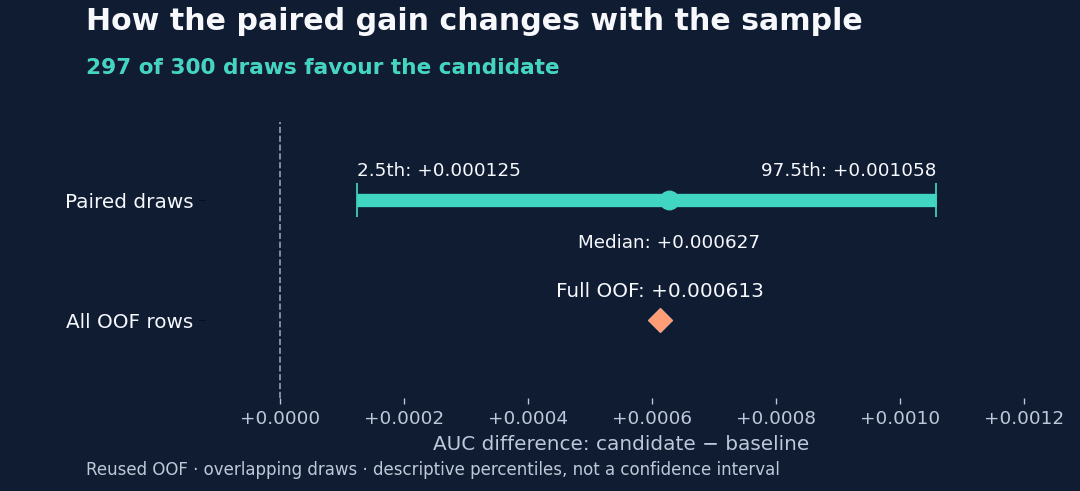

In [ ]:
paired_sampling = pd.DataFrame([{'Rows per draw': '60,000', 'Draws': '300', 'Full OOF gain': '0.000613', 'Mean sampled gain': '0.000612', 'Sampled gain SD': '0.000244', '2.5th percentile': '0.000125', 'Median': '0.000627', '97.5th percentile': '0.001058', 'Candidate ahead': '99%'}]).T.rename(columns={0: 'Value'})
display(styled_table(paired_sampling))

The candidate scored higher in **297 of 300 draws**. The draw percentiles describe this fixed pair of saved scores; they are not a confidence interval or a probability that the candidate will win on the public or private leaderboard. This is a retrospective diagnostic, not a preregistered significance test. The OOF folds have been reused in development, and the predictions are already ranked within folds, so pooled AUC also depends on how fold score scales align. The calculation neither refits models nor captures model-training, test-distribution or public-to-private shift.

To apply the method to your own aligned held-out predictions, draw one index array per repetition and use it for both AUCs. Keep each row's label and both scores together. Choosing model weights on the same samples can make the comparison optimistic. The private row-level inputs used here are not distributed with this notebook.

In [ ]:
# Optional sketch: provide your own aligned arrays; nothing runs by default.
# rng = np.random.default_rng(20261107)
# deltas = []
# for _ in range(300):
#     ix = rng.choice(len(y_oof), size=60000, replace=False)
#     deltas.append(roc_auc_score(y_oof[ix], candidate_oof[ix]) - roc_auc_score(y_oof[ix], baseline_oof[ix]))

### What do matching source balances tell us?

[Evgeny Dvorkin's source-data exploration](https://www.kaggle.com/code/evgendvorkin/s6e11-deep-eda-original-data-artifacts) prompted this follow-up. We compare exact numeric `account_balance_usd` matches where that balance occurs once in the original dataset. The original row's fraud label defines the groups; the rates below use the competition training labels. This is a description of the training data, not a model or a test-set result.

In [ ]:
# Recompute the aggregate from the train and original data already loaded above.
balance_counts = original['account_balance_usd'].value_counts()
source_unique = original.loc[original['account_balance_usd'].map(balance_counts).eq(1)].set_index('account_balance_usd')[target]
source_label = train['account_balance_usd'].map(source_unique)
balance_rows = []
for original_label in (0, 1):
    mask = source_label.eq(original_label)
    balances = train.loc[mask, 'account_balance_usd'].value_counts()
    positives = int(train.loc[mask, target].sum())
    balance_rows.append({'Original fraud label': original_label, 'Train rows': int(mask.sum()),
                         'Fraud in train': positives, 'Train fraud rate': positives / int(mask.sum()),
                         'Distinct balances': int(balances.size)})
balance_summary = pd.DataFrame(balance_rows).set_index('Original fraud label')
assert list(balance_summary['Train rows']) == [509244, 9621]
assert list(balance_summary['Fraud in train']) == [8478, 201]
display(styled_table(balance_summary, {'Train rows': '{:,.0f}', 'Fraud in train': '{:,.0f}',
                                      'Train fraud rate': '{:.4%}', 'Distinct balances': '{:,.0f}'}))
del source_label, source_unique, balance_counts, mask, balances

There are also 74,929 train rows whose balance matches multiple original rows and 106,166 with no match. The 9,621 rows in the original-fraud group come from only **231 distinct balances**. Repeated balances occur across the five development folds, so those rows and fold results are not independent.

We chose this field after seeing the public EDA. The difference reproduces that descriptive observation; it does not establish row copying, leakage, or a model improvement. We also ran a separate exploratory shuffle by balance cluster; its exchangeability assumptions are unverified, and it is not reproduced in this cell. This check uses no fitted model and produces no test predictions.

A separate question for the GLM-offset tree is whether its training margins should be generated by models that did not fit those rows. A fair comparison must rebuild target-dependent encodings and feature selection inside each inner fit. We have not measured this change on the competition data.

### Three further comparisons

Averaging three tree seeds improved OOF AUC by +0.0000094 (4/5 folds); a 50/50 logit-rank blend gained +0.0000026 (3/5). Both missed the gate. Earlier null and canary controls covered seed 42 only, and neither OOF check validated test-time aggregation. Feature pairs had been selected using all training labels; GLM fitting margins were in-sample. [Danil Malyshev's GLM fusion notebook](https://www.kaggle.com/code/malyshevdanil/fraud-signal-lab-gpt-2-and-glm-fusion) inspired the logit-rank comparison.

A budgeted GPT-2 adaptation reduced the 90/10 blend's OOF AUC from **0.9513073 to 0.9483873** (-0.0029200), lower on all five folds; GPT-2 alone scored 0.8238594. Each fold used one epoch on 30,000 fitting rows and one feature order. This adaptation of [Masaya Kawamata's target-first recipe](https://www.kaggle.com/code/masayakawamata/s6e11-gpt-2-target-first-classifier-cv-0-9500) omitted the source-data replica and does not establish how the full recipe performs. The folds were reused, and pooled fold ranks depend on relative scales. A synthetic held-out-label check passed, but no GPT-specific shuffled-label or target-copy canary fits were run. The candidate failed its gate; no test predictions or new submission were made.

<a id="s22"></a>

## 22. Does higher AUC catch more fraud at a fixed review budget?

The earlier fixed 80/20 H10–GLM blend improves AUC, but catches slightly less fraud when we review the highest-scoring 2% of transactions. With one pooled OOF queue, it catches **6,461 fraud cases versus H10's 6,470**, out of 14,000 reviews. Giving each validation fold its own 2% queue also leaves a small loss: 6,469 versus 6,473.

These are descriptive results from the same reused development predictions. AUC summarizes the full ranking; a review budget examines one part of it. Neither measurement alone establishes a deployment policy.

[Nikitas Rafael Nikitas's review-budget analysis](https://www.kaggle.com/code/rafanikitas/s6e11-fraud-from-auc-to-review-budgets) motivated this check. We compare our own frozen H10 and fixed 80/20 predictions. No model is fitted and no new submission is made for this audit.

In [ ]:
import base64 as s15_b64,zlib as s15_zlib
s15_payload=json.loads(s15_zlib.decompress(s15_b64.b64decode('eNrNfflzG8uR5r/SwQkb5BMI1n1Qi51w2ONdb8za3rFn9wc+BqLR3SAxAgEYDUii32r/9v2yGlcfRRKCNPKzgwL6qKrM/Cqvyir8crEqssUqv7j95SJbFem6yEebdXZxeyGYMNecXzPxVy5uJbtVfiCYEtq9Y+yWsYv+RblO15sSz2aLp+WsWBe4tlwt1otsMRuVj6nQBje1lkUhC21S44WTrNATNJ0XmcgnaE2pgiufyVTpzGS+4IXF94Jrw/PMMZ9SR9lqulwfmnQTPh4rN1ZW8QnLOJpS2ipTWC1YoXg2UblXhcryNC/UWBjrpRJjLguWZ5mdoEkQXRwaNFxmuSucYRM7kSLFyBj3jBc6TQvBJqlNrbI8M6l0jAmlJxggY3nqx5bjGhqczpeb9egxLR+Lkrg5S8fFrByl83w0zcOVZbp+RF95uk5v1qt0Oh9k5Ueibk+WLdKUs7HLOfor1MRoiy8p+jVCCSW5lG6c525sUhDsDNeCpxnLWOEn41xffOlfPHI2WiwmR/2tirJIV9njiCTKORM3ZQEpj9OHm1UxKVbFPCtu8Mpgvnw+Hs3YOW1TxowTWc75uNAqFV45zlI1SYtiLFNZTJwYs2Ji9USbCbFJjXPwmXtnaDSTxaxJ/puGs3uvOSavjDZWajkxLuMG/FITn6ZM2jTNmXLW+Nw6SD/LMHBvPc9ymaXMSl5kQBiN6WH21OBQ9lhkH8obwPkBWLxZrqYfMRFGi80aIr2h5zHozWxddrFJ5XYCQXAMoUizXBvlTM5dlmZajeUkz6yRTgnJXAqOOonxjw3AlFvmJpBtYNP0M7FgVgAsLw4tA5ymAFCnwDy3YEhu89QKpySzrHAQRDGRupBGmFR5PzGpS623kgE7Oi0Y3uUTIzNhwBwMZbX4BGkZ771hGNgq3eSj9WKdzi5uOTfO9y+2vLi4vfvlYrzJH4r1xS0bMI65v5hNs2eMZLlYzIr8glqbFfheFvNyup5+nK5pwIAoUfh6T2UxKzJopItbyxieSbP1Jp2N8Gi2ni7mVbe4wzRUhuFCGKn1rqnDy8oovDwrHjCEJxLs4ZaQ1PcSOnBablvEVHPU3u4vEZylsxndk954rRR4B8UjvJZ12f0nU6V5lCrlW1QpdUSXrlNlHcjSFnpSc6MMqMqL2TodHZ7BcLziTGvjoYOgyK3aPVTrhxFvDswzxu1GDthkGxqdNrtLs0UJ7CgMZl6sR9W1B+hFYlWNtDTP6U2jaldXxdPiY+AjWvjbptgUo+l8XazKYstI4xzb3dnMwyXLxf7Sf6RZlpLpYwMPqXvBpXISPGcW9mGzXkwmo/W00uZbzAZuNIXcFGj1auCsYVDSaBGgkbiJdtFgPkrXo91D/PB+7fKXNrRO7hxaSXGnoWad0v6Uvrequ5rk9AkNNiYulxiBaEBcSGmPx8TD/OpCOPMAiFPMKQe9rUwb4J65CL6VFi14W6Ms084JqWGkavCGHZPQv0ZaoFdLE5u0b6TIyhhFjlnLpIB2lVxY20ESV1GS2jOWRqsxj6xiltdJ8px5D4GDZoDcd05YQZbSK8xb72F1fMd8vQ4T1mv4Mpj3Hi4FqNCtGUudH89Y156wpmu+CtY9X7nsnq9wb3xjvkImqnO+Migs7qVxVkj+pb9DKX8jSl1NptCNMT0sGaEK3QE/XHXJlN7tlKlmLdsCIGoMmkN40Ov8WKaKCSBegSALuQmhT4VpgySpYyQJDZJgwazVlh1ke0QSiaEbpt60SEJPWpG3ZZwhXhyTxI0AyczCYnirWjCt8CdI6VrvMG+gfxWPGRYGqZPt8XComDyYkT1OG4bFt2F6Lbtw6k+EqRJNs8JhPbtgipiEabiryhjydg84FV+HUx7FKQwN8GMwKeDdiQ5/AZrv7brHKi/gTjroF6GVrwvVIlqSSkG5MC/FmTAl/HVTxMkDgvbTDkIXXQSZKEGuRZABejhiF0WmojHxoEGh/QS8Zicc053a9M0oRVRCuhf2SHDBjXlVm5Kv08RpJ0zJa+vEqYmpU6dbOKWBd6hTjodhwLSCD+jsAafy63DK4jiF1dfWew6rLMiDbevTmFurSG4NsXK4NkwIh5BcGtXQp3AtrBbWwSdV58FUkt7rNvrwY7x31Apz2nT5MUpHcdomCP41TLYl8DCp6wQp7rkBvuDMg/JumFoOTSARfksuMT1tBKbawjpZzHyD+UCCb8OU12Fq2yhVnSjl3SgVPIZSq1ooFd1GXzlE+OADXBXpxAGl6qtQirA86slB41gEBBoeGELotlCdjyof11I+pCodInJPTqiuR5QOrikMhIDYueTWnIlTJ6IkEU6FwayD/WSiiyQbJUm3SPIMjoxUwjtMQdsgySBsVQ7kRlDKFNxjMNcbbR08Ih0NJmE30ZWEQYJqDjP8FZhy1hFNnmL0RQymRrRgyjphCv0PRbr7y7/cE1BjmZJiNQoY/ofJlUgTz5Wodq7kOFkiG7kSdAPMaThtzP7QTIlSUZp0y6E18qVMCWYPvFC0iCA0Am7jFOlqRd4YXF8d9RSO+hFCinamRDcyJR062HUmSmQkUcKjiRLRSpRw150oAXUIYAQMiKVQuDtR0qGMa/5BPVOhEaQqxHFQTPDyT0qT9C/4SV1BFVt4OdLBq4R/q07qSpzUlYHGR/wuJC2a6NN6kqf1xDUhWQoYcwDTnNSVOk1UiGgQYsCzUAiNpTkro3UiSgycU0RRTBvNg036fijhUmkNpgKPSvnvChKHkIMBkl4DkPJ7ogTKSMLRRxijqsD/+6FEA5IORh4+vlL6h6Qe1Rkmw4uoz25bvpBh9liV1w2Gdsxoii8VHEAnz8s9nkcSi7p37TxVjSJeJ0mGkAFqRhsndHdSR1DiDqbfUsQCB1fFso+y1pV2tmUFbcPBEx1pHd0ZicRcPHVKJGI6rSDldKB2nQZxQp6df/zHkKuiIIEiBEoS2jMTO2eRFA2ubNsF5S+4awaTb5+6iabJDXSvt14ZjzHFImZV83RlG6e+jlP5xiR5DKQ6mtRpxyHdrpolFnPhrWFCaHt28vEciSp/Qg7ERhdgFaLOo7yO+IEYVSesTtnatGvkyDWZYwO7YjDvKPfWpU9rEbPkcBhiCrVmjKCp5esJyI4F2OvOmJmLCFj599Oo8geANapR29UCdYXazEAyLSl54WDl9I9UqC+kIFvujD096ygo1QwF64TzGKiL6VBZrw3w7tV0jmlDU5+ETBtFpm0jU3Yik9bjqHJNUChgz806niVHJqILc+2sYw2Yop6i20sLUQFXPxCZLIpM3046mripd5Y5MnWeSSmNOGsNR9QzM+obLuHwk13S9hKO0N3JcQ8uwzIiPEfM1co6ihfqs5YrjGf1lflGkn8EAIJVaS4PJsJgd6z2UNVGBAAWurOBAGVqouG1hKPWUtNykIPfY5zy52Ucz6TK8DhVvkVVHcsajcKl87QwqbQXEY8AWPdaIbgk5w5GM+oQ1GYN523PVbFGnrFr5dx3V3i4CKC9jyNadKz3dCcbNXeOkc8DbWD9V1ZlbUV5SE9wyx2DKjBCMCGN/K5lWR29C8xQrWkpFFTRctF/fnZEhEXwTqVNpSmaCo/g7cBZk214c2FiCXWQZJvwBo1MI2YCEDmre78aGDdKahghTitJZ6VHhKW1tQhN6ADTxFLNtBedJOk4SbJFkgvlWd7SwjNndT1EpaHEQsTQjksVXQFz3jOu4VfADsuIKWJUeqThd8FcSRfqP15Oj5g3Ln81lnn2E1ex7nkrLG9aIhib7mVaWtJDTM2DwXVnJkeEiy3TCkawsZhO6Aj9dSLVxwJPcF63xApn1zBaZAYipWxoZbrGLNXkkYU9y2eC9+tiRCncg/kyyqEjqTqJ4lGibHv6McrFWVb90zA0HAjVlKrVKmZopIK+ElRVZKiS1MYNDZQKPaA52Ce1atcUyNfdpuvOBS0ZqfxVkdVacvSaaPWiu/SFSlGMpPI7eMxnJklEyOB3qyAHFjIYdqrI5axLrpK7qA4yLbBaSXllKFaI0ahaLg/sp4VK6AwfSvDOw6olz6ibJtJzVO8kEUtY30lSdP4Fz69BEoTkpdGwyfhQxypI1IjDPKaHhdV4va7g5SwJFeRBt3oqZcO86PDx5et5527NGnGJpIxpVulamlV2a1YEUtpA+8DHh9k8M0mCOR0Fq4crTUWdmpBnXadkZVSyri1ZKqWFSNAkTBqVSR2LFiLjuK/hHdjTnYCGZo3VSAoypg4RBPwQGkUnTSyqWJloue2ajLO3tMyrlKs7Ace2AnD++tLX6yr5rEKdELwORAbCvJZ87lwk6YxITaRG+4DJJlqVbKH1UBpzjFbtlKBiCMp+Wc/PTJxgZkfVkANaMY0x3/GXmy6TaU1csm33zkPXQFtTFayTrK6I4M/CviFgxAARy5ypW23cXjAHZsOnhSve7YXHaerwwuEr0WSGJ46gjblXSGrp1ph/6mnZiDYRMG8t823/1L26d4B14VJFcKlMDJei7Z8K251q9pxGDdVP+yJezpS06rN+aK5ERrMKoi1wUU+3NnIl1jiEoPCPEeO5H5sr8fFcCW9TxV4gSlEc4ATFHiqic8mfRdjPaKeO0PAzVNyfPc6fWsfaToJqbDnQHdWH16o7cxJxaQVj8cwJ60gGsjdkA7+qTAuv1xMXJkS7QhAqXKgP+1YFOK2uLJXq01ZLQ59OrAgTp3VFGw0QQjqIhBn/DStwOrqCXw5la2kzWliB+FYVOG1Z0UKMIRUI94Kr71in1QET+NPawgVSTujvCRILgMCps1RbzU6snToVJIZSYpQFEd8XImievCYnvTVWy+8IEWjAsJVXC0UQ+SFpSPf1hoOHPcgRn06Ylk+nGy4PVXEoQ1xg0p2XePwHouKNjttre+fMG900KU8Ndg1vB7u+s3wFwCQ/hSNKt4KfnUY8R0YumhzWvJ1FdD5WEqCVN5SW2IWHZ4a6Z5EUhx1vw87FXUl4Gs7Kfa3V2fUrNa9VSmNfw6p9a/mKtBGwRmMKbVtgVd1FAh7OmaCNqRpwPjeLeI5gX8q4uZY7DecnKth2xu0HYRWOejyJ6NpJxHhJjqaTGA4VV/a8rZ61UittOvbQNZDK5RvrBFSkTkCpE7Iy3VuSTTiogHZV0TlG56YQz0PqCxnEdjj7glb9tgnEc0hi8cnn27GsbawweeeYkF4L5rXjkZxhbYdnqAaNnOtQq5Tw7NXUTGfSsDN41TF42ig821Zf++6koRWIM0M1pKOjaM5LGp5nIkXcRLqOVe5adXXdRsKQcb/fOf8jzX48wy1Ym6YXym1qZasuZvehGBVI97D5RnPP31S2aoXwbWXK3gBX0alNxalr3aq9IqPFW8pWm7lE/T1PxZLK+8gyckepndMsemCUaSeMBQThvab0oKhi3oPsoWXpFXRPh+1YcV768GQy7Atk8BYZtAuZSfhmDIJiTTosbUCW8NqUjGznJMkyyRlNYsecj2XCOe0LcPBXPTO2qlpoZgsbxa1Sv3GPgGERBIdlrC4I02pIMx8utYmc/iA9RzDi6Xga5tRXllltxXhIMDB4j4IZcE+hB31ahuHUMquu3oFQQY4OpOFPyg59s/wG7WXoRrZyCkG7Fiqk4LvOv+JGR08W4q3MAHBuhacEIxxXa+prVtUpURxWGCD2p4eddZoc4zGaNBU8WQpw6eCWLpqihZHAB2vRpIRwFsLDzFOsFp1Q4ALegUfw0vFE59yVUMvMk0kECoRlsa3YAEkwzgxRrNLKvF4NoNoz13cX/EbqrDiLlK4YY5v1kSZsie4qj/QWAY3WUiJmP7fQirZ+RbQwF0Cp0M5RvOW7SleMi5Wu6HY1gJCUNGDdtekI3zwcPybgxHBx5vlCNhzA001TKPvxiBkc/KZOrDobpcn6Dpq4FQixOeHINWlCfEiHighajfHn5EjsAI3TAXOKDjXCZC+umX61HoC9fYtP7JQhEcmS0EJa8/AAySLeEsIbR+ec0eEq5xZboeNIRYBmAlCFVtWIk4CkLu1qo3lXLVrFVvCAEC3DptKWCcpQ1aSLmMU4NEjVAlqdd4QLVLWOEUX7b+hMQKGpALWTJhOlybUQq+nMJyotMcIpXafIGzoaFcOViCgijtGbXXsDziF4J0fS0a761wLRjuSzOA2rLHbQhW9jldturFIZGjxDr6Vlzp2ZKKFakphYCVUWU8ZSuUeXVKM7fOncoLbNBMPhvCMaxBSoA5UOHw6HgnLI3LozgapYfPbBE7BUZcG8OZmkDjdAcnf4n3iFpjfXrkiOEXqoUCYtPtpvVbsSNhF3nyhoYrhkuoVLpyJHtRlp4OmROrDnVlUZbyLV1YgIVShx1zBLvFOKxkQNpGjHk7C1tI8OsZSg87Dqzpw83oh93rKICdvHu0lSVolQTm+h5LtJknGrIFvApONqrMQ8M7RPzNdpojptC4PH6JA19fXZvCo9IjWCTwUOODrEy79WW23fmsvjLHpMgoydFsSbu3ots927esk7p3PrQadwr6RHvv1RWHDuWFRJVfU9khkanetMNESPDTfts11FfbtlPQFIaWnraS1FwqoYc2bC5Eyy5GlpIB/ddUkWS9LZuIjQgOPukzPDxNa82tXmmVJdGwjc4OhwBXIZOr1a2QC5ZG9cTzFMn55AaR34Rkcsde9TA2G0mYKODuMUp35FtVXz+G7E0IzT+qfXVI994iFE/LSuPKJkeOeAtcW//NsV0rS7slXYjoiVPEzx7UppOrpC3AwpKooClfffrpSm3RXZUehF7RTcIuG+X7VVB0wkpiFtCLCYZJx/X5gYTltL6JA2EuH3xImDWyzojHiqrg+1l98RKJRdomM4KbbS6rsCxVEMBO9cOx+8oP/8pKQ9w3rwsHcj4rlL1fL5Gm4e7RKyBu620frM3Z7nUWFFPP5wbSpesOxcI8o6/Hn9KH5SSNHdnrUyG+5fPR/jrSsIXMROHhA25uUZ1wpJpIh4eQ6+PQy8NYL7c/OQ5wnWxQUr2iFJ9OQ2+Gu0W08JTFSpmD4zVj6LJBsnSbZJ0i/RtN/HCUmdX6r1eomBfjWzE0lDythvRwgfxWs7hJbdR2UI2nZNZ2zDmgl7dhryDOHauCISbUWkZY3jjSyk9VRMSr8vYbz7cXh9KbHaXrbStdN2m2nIVmL1lTQkHSAb062v7+b42jQkk7E0ZPyHiXz7vN3utVmHoQa1SvZDnp2GPEew/IXscsv0U2lyrHbkqFyUSu1+JFi5jtOk2zQ1qDgc3I7Y6R9ancbOx5LRI6GNbKvT7mVIOjNBc+epCPLsY/nP9E7j5l+2zb+Lnl5OBwBL9CZo3VPbH4hQEz2YRIcTKhok2ZdcVcHVnrBztyTXD8RUqn2Wm3o9Ixk5JCuWkYz90gn9aFL7h966C7U1FaMAq56HSoj7L/c0rk+j8Iuc0/nDaDKlHzdk1dVyM36alkR2da2cLdYl8aIsVmFMd3SCD22r7VO6gX7ODO3Npk+hkbuLfyuW4UdVZ8/JpizyJC8+FrPF8qmYrxO0kk8DBeX7ZL5IpvMcT+MP7j1iAi0268FF/+L3hLvrKmmalM/z9WOxnmbX9DOiST5NH+bg7jTro4V1givFcrZ4rtoPmVVq4o+L5Df//ttksUpmRZoXq/EC7EimT8sVGBuenZZJNkunTxji+DlZP+J74F0CYU3DMP5SLNMVSEloblc3yyRd4YnkKE+bpPN09lxOy914VhhPmlWdrItyfQ2hFglhaVlQs78tpjNwPVktNvOcPjxMP6LhZbG6Dh3pX+36Wn9aJE8LdEgzD0NM5/hTJFVV3f659wn9GC2N62kB4JbJpymomSdFmj3uOXIP7JeLzSqjLPPP4X81Lv/pT78/Ym05SH6zWqXPSfiJ1zJZzGfPQWBAypqGDL4Wn4FHkJ4AakVZDqpGf56Dx4vVOgGOH/df5punJRhVJvPl/toynee4gv8v85/nPwMEk6Sa6aNA1mVJP1gLrk5z/FkuiN/ATT/ZqZOr25/nCf6rOv7XdPUAZifVWxjoqly/T8p1CvWV/OF3yXpaXI9XRfohsAdAA9fm9LOeRE71y7V7EqjVD8kQ1K8viY5BBpFd7vpNfgKm5pf7EV1dXVWvzBbQKqPFCnDDy/PlYFZ8LkHq5SVIuNs/f99PrqtRHl3btZE9LoAtvL6/dXfU7N3th/v77YMhS4IHJ7NFut4y6656/e6a399vGwTdI+i6LTUYVLl5umx1nwyH2xavjt7bD6b9anWr471/Sv5wNKmJfGLwlH4tmWZEGjhY/cZrAHPxGVwlgG+Fj9uDqqUFbhMjl/ngd5j5v1+lT8XlL73doHu3x6DohXHhWou0ftVa93+9aY536uL5cjWgYY8+pjNMwsvD63fbTvrhNYgxLbMiTOHh3e/TWVn0k7+uNsX91WDX2GC9GAXsX16R6KqmwEhSC3htkJZQqutRSnNtVPwNxvKyYmy/on7L01Wx3qzmye7WLz3SB73bOgqJB1tD2bv9gG+VXHq31b8RNvTqybje7RYvR60171bD+EJztpq1T0VabsD0y+c+pn35YTcx18stdJ7v6PJ9wM/VFRTJfm6VH/YXK0pIE25f2t6pseCY9Gci+cgL6d3um6jxYt4gvddwS/DETaO9w8vrZfPtDscELVzjwaS39xjoxZt5Mp2AVmiWIvnjYl40W6q8kPDogXi8cviyf/WI21tlT8yGtYDRKT7tGJ6CdcfCwH0wdty4Si/smBr8lvoEv3weDvlV8mt6Dn//HzWyV3BQsN0Pk+HCw9T29uHg2rSfZt1Nbz2eyPMdrYeZs6PguhrZMBnfNSV4f522r9XaCAO93g8gNNIl5NBS542qOUgODxyuDofj46+3B+nXB/8uDGA4JBrebYdRPRscu+ERQ4gP/zcIEHI9dgibD/06OeLVfu4gNOndpv3ekV/fux33e8dOMS7c7ZAZKN59bqK34SOH9w7fwqtHX5tv1xzn3u32Q793cJ8xyfG336t70PtHg8hfmJuBqaCW/un32r41NRQ+NNtoe9u92+Nv/d6R1927Df90t7F1wuuv34QXjuZzcDdHR54xzdHg80z6yTglq/I0/byb4s99ujXphxu4jglzB7mnZbAhl+kVnNUVFAH8v7vms/cN3M9ml+kA9usJc/il10gv/q/gGm/dwacNZtu4gFtYXON18oUXwROkMZSDXq0bUq0YIcgGV8gTuroC1nGRPsJ5zmH410dPPNP9X1iff6k1U39oQg/RpVU6fygudUMtEGmNVu8mw+GH+33bgd4PRO++BVD5L+Qyw+7TD86TnxL88UAtnMU14JeMYZeTNfmaawof0F2T3oqt5WO6LIbD5+rDEXebvG29izFPywkCs3UBcQ7oUsWmy8v0v0Id/voy/S/Qubs7h5abbW5/tX54d/8+BBBDwklFbWXuoEPIApfDX7asprb2Xi41Sb/cRqcDIWw/1l/0XBVYhKd6VUDS6/d2BS01bUf/7dQgunpPruWhz/0T2WKJy3eXPdI2fRrw1X1lDamj4XDXS2UU7y7L9eryw1V4cCvbtkzv633Q/Tm8yP42SKDBXwatGARy1b+sqUZi5lWTEvqPuEbc/HuxWpRbZvbHGB44mhfAyaxF3q77EGn0YeGp84rm227PbOvtgVnDrrCIcIRm+vtoqLsVGurOWR+Sd/q+GuBdGMj9EM23X9xJ646YdT+kNt6T0Lbfqxbqr5ErApMz3L8a2HrfP3w/5mxDLlv0o43K5xsO0VT1sf4ghD38pVeFrL3bHenAXcAIOYD0b79H1VS929724KoewWj38HAIQFcY6h1F8b0u//innw7O1pbAq37vqNIlOMRl16u9sG7du737JXwij/yotQqw1Ob2E1regrhDM91/6WQX8efzXdM+3of3P4f3F5/utuO4B0/D1+bTDf5WKmOQLimAu8QbDQE0GRmZHBROkSTe9UYBBkMM4n3jRg0PJPCas7IdSRVQlAdrma/ST5fVzX6yRGy+M4yHtMNytljPpuPq8uH7YFMWl73fPDz0riJvDJbP9CmkJGbr6iF8GKyyP0NvPpWDzRJ2gWLQCazBYJI+TWcAXe93xX+k/3uT/CWdl9CB4V45/TsAyEW/l36GhSiX0zn+WS+WvdsqUnwhKK29spo+PK53L/XK9GMxmT4M8uW0R8f4fdmp+tXwbhUEvwqCD/wh1y0wsRf06OpuN3Hug+i2okdzfepwSJSWmzFxoLzkfdHHHSJjeAky1MBe9R9WUDrLIht9oFn4aZqvH0crMpSEc97nA3G/G9DnI2MjoBXDw8OBlFtzhw7v2P1gnK4uP1+Hmzeif8cZ+2m11RwHx/OIrtV9PzzczxazxWrY+yctabWo1w/abNj773jzqqOLd80uauB7W1fcuonT+65C9ixx7EawpGqn0TH5H5/X0wz29XM/fKiyTMO73p+rBF7Q50BM5VvBdiaV7ew/7/qgiZpk6QYYSC5/ddXDHXhrl6xvDx7PoTuopPUMGP8LtHQifoUXl2kG3XabhBmfbKnszxbZEB7xZN3rE1g/FYSxYW9MnTdahd9MimBCuRdM+QqG9FJABmdXB8dh2g+MK+abp4Kypper1dVxzLNtcV18Xl9OaV5/vmzLuh+XzdVPkN07EZs5k58vfsHLtVDmnl65fTcQky/JcvnzRf8xHfaygrzx3hEV/JhoHiDzCFgOuO3fre4aoUoDIwMpYgj5TZ6H1Awc48mRIHudvb0LvV3vuwsR0At9ZWMrtN/39edV8XG62JToY509wrUJ7zd6Sj9/nEGpAD67VtJ0rMYZWvk0HLjG04Tf5x1+n0/C7+cGfktKZRDXKRV4+e5qm5b/GL5eX4U8YNVYeww7UP+fxxQe9yNplDz59FjMKW6nBv7bv/7Pf34Tpt8KUr4FaVv072R/GmBBvmf79lX/4wFfV5FWmyK+RpvvWm1W964CYCsT0NH2rl34OA9TxI2fhwNxtdfqUObLLe9+t6CFi+QRDUFItC4SYFKtLVTYTGnlIsy8hKBUfEoqYwHWolmmwkgO/K0mjonzGv0HculVRBG6DzAs/g6pHS8H0aLDUeCb/LxhbGwT433fG5asYT/KtH6Pqz5jbDvG4ERXyxyVp7dNjk1LRObHaqppL45HSYMfzdLnxQYih686vGMU7+g+Qh8v76/eB15WhveSPI7+JM2KbYOfHhGm9a7ek/HMIDREptOHq8pduaCVysV6gUdp9bRcp+tNeXG7W1UtgMdi9FSsV9NsROPeVMlxvJatwgraaLPO8Lxgwlxzfs3EX7m4FepW8oHknmv/DtqNsQuqqFyH7QNB0DSbKklialS2qVPe9FyZhqWpIPCdufhnNBgiE2pwvyRU5SmSBTmAQZCg56HgqrWmt10i6idHC4l9dIZpQkt8NxVckgXA+TT9exVnY2bSMuN2fpe0SlalGohxldoZIQQeTfNwhaSAwdF64E1YxBxk5Uca9WMqtMEdZ4s05Wzscm5TW6iJ0RZfUp4Z2ihG2zOkG+e5G5s0p52FXAueZixjhZ+Mc33xJazjjxaLyVF/tASarrLHEUmEcyZuyoIkmT7crIpJsSrmWXGDVwbz5fPxaMZUTJnSr2SLLOd8XGiVCq8cZ6mapEUxlqksJk6MWTGxeqLNZJLaVI3zMR1t5czFtgy2Qf6bhrN7rzkmrwxVaGo5MS7jBvxSE5+mTNo0zZly1vgc5kzlWYaBe+t5lsssZVZy2FYVOPQwe2pwqFrXudlC4waz8iOl3DC1IMwben7rknaxSeV2AkFwDAFzOtdGOZNzl6WZVmM5yTNrpFNCMpeCo452wY2NVTa3zE0g24t6xcLLQ8sAJ8rydArMcwuG5DZPLZ1+xiwrHARRTKQupBEmVd5PTOpS662EchM6LRje5RMjM2HAHAwlnU0f5qTmRqHromvPS1XbHOrfd2UV/PBRHD7Kw0e1+4g+9lRUi0flNqhyDJi4uF0j3P/S3x/ffLvbh9Q4QgfN7LXmQT0FtfE0ncOngFd9sd21FHZ33G3PdUkQz1x/CFo8WG88tJgX26t/2zsFkD7+NrJqF/e056laACfp0AJrNbqf5lfbBFPogzJfQcXTW+9pcZ2CtmoJB+p+Ax0fntnRBE/j85JGup49B81YjMKyLymzYrdeB6W1GKfj6Qzq7mgZL5keeghNU6oq6MrtamuVrawyGtW98Ngg+eNilxSsVsNDdqda+xwQLksYjHneLQXiKB1/3qfqGLBluVktYUkwYHh1FG9NJ9NQR1Fmq+mSFoaOyw+gc2FRV5QuwkvJmNbAqw5uQjkAqesn0vVlsQ/vaUSV4QnS3FMUiLnY1rDsCb04Lk05vnqoj9nX3Oze3a0sjZ8rA7S/ERZqjq4etZzOihUJkzL2N7sKmG1BS4Ivq1m6vPkf28KW/sW+XmI/fFpErsQGXBV7BG232x29sR/4TTXsINdlOl0FNiOAKAmelcYgBv17yCEnf/hdBbUFPLIpufXUYViXR+N/IHsF4zcrkse0JBf8Kdjcg5msXAFooE3+vNWD9B6tk08zChJoaNTHehEsd5VNp4KR3SyvFstnz0k12xM2cD9hcr5jA/ET3sCj/wI2PYdxgbIirCGSW0fJ5OSxmOXXVPhwsNhBcEcraNt258BxJS5KEhH+w439rNs6CqFEZrtm31zhP6rswXiz1aIsr7d6MPk4TcPkINlURSDkf6C130AUOvCh3E7DIu+jqWy2CdNzXjykAf+VkIK7UULLYoJAE2ZFVdATVEt4u9Itf4JOwuyDxKGb0g9F+il9ruSIGzvHMdSJ3MB526yKQfJncAkT5HGB7uHFrtLtlKrkj4l/XCuDOTdbfBokvyW2rpM/Tj9MMbgqdAue1a7GhqJoIoPaSLMP88UnwPOBBvf0tJlTKRFQVgb2PS3WZDqphCD5t+LlOqp9gVRCDtH7o6HBySpCgobAigm3LVFqFUz1MWHWiw3kkx/raRAQGEpOHwUNR9VT5KG9rTDsrYVmX778f7MwBW4=')))
recorded_queue_audit=s15_payload['record']
queue_audit_source_dir=output/'queue_audit_source'
queue_audit_source_dir.mkdir(exist_ok=True)
(queue_audit_source_dir/'audit_core.py').write_text(s15_payload['source'])
(queue_audit_source_dir/'protocol.json').write_text(json.dumps(s15_payload['protocol'],indent=2))
(output/'recorded_queue_audit.json').write_text(json.dumps(recorded_queue_audit,indent=2));

In [ ]:
s15_primary=[r for r in recorded_queue_audit['results'] if r['budget']==.02]
s15_rows=[]
for r in s15_primary:
    s15_rows.append({'Queue':'Pooled OOF' if r['policy']=='pooled' else 'Separate folds',
        'Reviews':r['h10']['selected'],'H10 catches':r['h10']['fraud_selected'],
        'Blend catches':r['fixed_blend']['fraud_selected'],
        'Net catches':r['net_fraud_gain'],'Recall change (pp)':100*r['delta_recall']})
display(styled_table(pd.DataFrame(s15_rows).set_index('Queue'),{'Recall change (pp)':'{:+.3f}'}))

In [ ]:
fig,ax=plt.subplots(figsize=(7.3,4.3),dpi=100)
s15_plot_rows=[r for r in recorded_queue_audit['results'] if r['budget']==.02]
s15_y=np.arange(2)
ax.barh(s15_y-.18,[r['fraud_rescued'] for r in s15_plot_rows],.32,color='#178f85',label='Additional fraud caught')
ax.barh(s15_y+.18,[-r['fraud_lost'] for r in s15_plot_rows],.32,color='#cb7259',label='Previous catches lost')
ax.axvline(0,color='#aab4bc',lw=.8)
ax.set_yticks(s15_y,['Pooled OOF','Separate folds']);ax.invert_yaxis()
ax.set_xlim(-65,65)
for i,r in enumerate(s15_plot_rows):
    ax.text(r['fraud_rescued']+2,i-.18,str(r['fraud_rescued']),va='center',fontsize=12)
    ax.text(-r['fraud_lost']-2,i+.18,str(r['fraud_lost']),ha='right',va='center',fontsize=12)
ax.set_xlabel('Fraud cases leaving (-) or entering (+) the review queue',fontsize=12)
ax.set_title('At 2% capacity, the blend loses more catches',loc='left',fontsize=14,pad=40)
ax.legend(frameon=False,fontsize=11,loc='lower left',bbox_to_anchor=(0,1.01),ncol=2)
ax.tick_params(labelsize=12);ax.spines[['top','right']].set_visible(False);fig.tight_layout()
show_figure(fig,'Each policy reviews 14,000 of 699,960 transactions. The pooled blend catches 40 additional fraud cases but loses 49 previous catches; separate fold queues add 46 and lose 50. These are descriptive changes on reused development OOF predictions.','queue_audit.png')

At the primary 2% budget, the pooled blend queue adds 40 fraud catches and loses 49 previous catches. Separate fold queues add 46 and lose 50. The small negative direction survives this change in queue construction; we do not treat it as a statistically established difference.

We fixed 2% as the primary budget and 1%/5% as sensitivity checks before computing these queue metrics. At 1% the blend catches 11 more fraud cases in the pooled queue and eight more with separate queues. At 5% the gains are six and three. These different signs show why a higher overall AUC does not guarantee more catches at every capacity. We do not choose a budget or change blend weights from this table.

### How the queues are constructed

We sort scores from largest to smallest, then take `ceil(budget * rows)` transactions. IDs break exact score ties in ascending order without using labels. At 2%, both policies review exactly 14,000 rows: one pooled queue or 2,800 rows in each of five folds. Every primary cutoff is unique, so the ID tie-break does not affect these results.

Separate fold queues check sensitivity to the relative score scales of different fitted models. They are a diagnostic construction, not the recipe used to rank test transactions. At 5%, ceiling rounding selects 34,998 rows in the pooled queue and 35,000 across separate queues. Comparisons between H10 and the blend use equal capacity within each policy.

All five fold differences and the extra budgets are exported below. These folds have overlapping training data and have been used for earlier development. We make no independence or significance claim, and the selected H9/H10 submissions remain unchanged.

In [ ]:
s15_details=[]
for r in recorded_queue_audit['results']:
    s15_details.append({'Budget':r['budget'],'Queue':r['policy'],'Reviews':r['h10']['selected'],
        'H10 recall':r['h10']['recall'],'Blend recall':r['fixed_blend']['recall'],
        'H10 precision':r['h10']['precision'],'Blend precision':r['fixed_blend']['precision'],
        'Fraud rescued':r['fraud_rescued'],'Fraud lost':r['fraud_lost'],'Net catches':r['net_fraud_gain']})
s15_detail_table=pd.DataFrame(s15_details)
s15_detail_table.to_csv(output/'queue_budget_comparison.csv',index=False)
s15_fold_rows=[{'Queue':r['policy'],'Fold':f['fold'],'H10 reviews':f['h10']['selected'],
    'Blend reviews':f['fixed_blend']['selected'],'Net catches':f['net_fraud_gain'],
    'Recall change (pp)':100*f['delta_recall']} for r in s15_primary for f in r['folds']]
pd.DataFrame(s15_fold_rows).to_csv(output/'queue_primary_folds.csv',index=False)
display(styled_table(pd.DataFrame(s15_fold_rows).set_index(['Queue','Fold']),{'Recall change (pp)':'{:+.3f}'}))
display(styled_table(s15_detail_table.set_index(['Budget','Queue']),{
    'H10 recall':'{:.2%}','Blend recall':'{:.2%}','H10 precision':'{:.2%}','Blend precision':'{:.2%}'}))

### Repeat the calculation with saved predictions

The temporary `audit_core.py` accepts aligned arrays and performs no fitting or network access. To repeat the method, supply an NPZ containing `ids`, `labels`, `folds`, `h10_oof` and `glm_oof`, then set `QUEUE_AUDIT_INPUTS` below to its path. The code constructs the same fixed 80/20 blend and reports every predefined budget. Leave the path as `None` for the default recorded view.

The caller must supply predictions for held-out rows in the same order and with matching folds. Array checks cannot prove how predictions were trained. A replay measures the supplied arrays and does not inherit the recorded audit's provenance.

In [ ]:
QUEUE_AUDIT_INPUTS = None  # Set a local NPZ path to audit your aligned OOF arrays.
if QUEUE_AUDIT_INPUTS is not None:
    import importlib.util as s15_import
    s15_spec=s15_import.spec_from_file_location('s15_queue_audit_core',queue_audit_source_dir/'audit_core.py')
    s15_core=s15_import.module_from_spec(s15_spec)
    s15_spec.loader.exec_module(s15_core)
    with np.load(QUEUE_AUDIT_INPUTS,allow_pickle=False) as s15_data:
        s15_fresh_rows,_=s15_core.audit_predictions(s15_data['labels'],s15_data['ids'],s15_data['folds'],
            s15_data['h10_oof'],.8*s15_data['h10_oof']+.2*s15_data['glm_oof'])
    (output/'queue_audit_replay.json').write_text(json.dumps({'results':s15_fresh_rows,
        'scope':'User-supplied predictions; this replay does not establish training provenance.'},indent=2))
    print('Queue audit complete. The primary submission.csv is unchanged.')
else:
    print('Showing the recorded queue audit. Supply aligned OOF arrays to repeat it without fitting models.')

<a id="s23"></a>

## 23. How often did the public top ten stay there?

A public leaderboard position is useful, but the final order can differ. Across S6E1 to S6E9, **40 of the 90 public top-ten places** also finished in the private top ten. Three episodes kept none; six kept at least five. The table below recalculates that count from the attached [Playground S6 leaderboard dataset](https://www.kaggle.com/datasets/georgymamarin/playground-series-s6-leaderboards).

In [ ]:
import glob as _shake_glob
_board_files = _shake_glob.glob('/kaggle/input/**/s6_leaderboards.csv', recursive=True)
_board_files = [p for p in _board_files if 'playground-series-s6-leaderboards' in p]
if len(_board_files) != 1:
    print('Attach exactly one georgymamarin/playground-series-s6-leaderboards dataset to reproduce the table.')
else:
    _boards = pd.read_csv(_board_files[0])
    _history = [f'S6E{i}' for i in range(1, 10)]
    _boards = _boards.loc[_boards.episode.isin(_history) & ~_boards.is_host_baseline.astype(bool)].copy()
    assert set(_boards.episode) == set(_history)
    _rows = []
    for _episode in _history:
        _group = _boards.loc[_boards.episode.eq(_episode)]
        _top = _group.loc[_group.public_rank.le(10)]
        assert len(_top) == 10 and _top.private_rank.notna().all()
        _rows.append({'Episode': _episode, 'Public top ten still in private top ten': int(_top.private_rank.le(10).sum())})
    _summary = pd.DataFrame(_rows).set_index('Episode')
    assert _summary.iloc[:, 0].sum() == 40 and (_summary.iloc[:, 0] == 0).sum() == 3 and (_summary.iloc[:, 0] >= 5).sum() == 6
    display(styled_table(_summary))
    print(f"Total retained: {_summary.iloc[:, 0].sum()} of {10 * len(_summary)} places")

These are team-level historical outcomes, not a forecast for S6E11. The public download records each team's best public submission, while the final private board reports a selected submission; the two can differ. Changes in order can therefore reflect submission choice as well as differences between the test partitions. Scores are rounded and the episodes use different metrics, so the table compares ranks within each episode rather than scores across episodes.

For the methods and limits of the season comparison, see the [Playground shakeup notebook](https://www.kaggle.com/code/georgymamarin/three-of-nine-s6-boards-erased-the-public-top-ten). The broader [Kaggle Shakeup Atlas](https://www.kaggle.com/datasets/georgymamarin/kaggle-shakeup-atlas) covers a different set of completed competitions; its medal analyses do not apply directly to Playground, which awards no medals. To study whether teams had a better file than their final choice, use [Kaggle submission histories](https://www.kaggle.com/datasets/georgymamarin/kaggle-submission-histories). Its private scores support hindsight analysis, not a selection rule available during S6E11. None of these datasets is used to train this fraud model or select its submissions.

## What to take away

At a 2% review budget, the recorded H10 queue catches **6,470** fraud cases versus **6,461** for the earlier 80/20 blend, despite the blend's higher AUC. The result describes reused OOF predictions; it is not a deployment estimate, and the row-level inputs are not included here.

You can run the included H10 recipe in your own copy. Its target encodings are fitted within each training fold. The later GLM-boost result and the small GPT-2 test are recorded exploratory studies; their full training pipelines are not reproduced here.

Which review budget or validation split would you test next? Share the setup and fold results, including comparisons that do not improve the baseline.

### Full contents

On Kaggle, use its notebook outline; these links work in standalone exports.

- [0. Run settings](#s0)
- [1. What is being predicted?](#s1)
- [2. The source is synthetic too](#s2)
- [3. Check every supplied predictor](#s3)
- [4. Where did the distributions move?](#s4)
- [5. Which subsets contain more fraud?](#s5)
- [6. Freeze validation before testing ideas](#s6)
- [7. Measure the baseline](#s7)
- [8. Test three hypotheses](#s8)
- [9. Export the reference and preserve its history](#s9)
- [10. Earlier experiments and controls](#s10)
- [17. Fit the current recipe and export](#s17)
- [18. Separate representation groups from column sampling](#s18)
- [19. Compare shallow trees and test exports](#s19)
- [20. Average three fixed model seeds](#s20)
- [21. Compare model ideas](#s21)
- [22. Does higher AUC catch more fraud at a fixed review budget?](#s22)
- [23. How often did the public top ten stay there?](#s23)

### Download the aggregate comparisons

The output contains `queue_budget_comparison.csv` and `queue_primary_folds.csv`. They summarize the earlier 80/20 blend and H10 at fixed review budgets; they contain no transaction IDs or individual predictions. Section 22 explains the reused OOF data and the limits of the comparison. A submission is written to the output only if you enabled `EXPORT_SUBMISSION_TO_WORKING` in your own copy.

In [ ]:
import shutil
public_output.mkdir(parents=True, exist_ok=True)
for name in ('queue_budget_comparison.csv', 'queue_primary_folds.csv'):
    source = output / name
    if not source.is_file():
        raise FileNotFoundError(f'Missing aggregate table: {name}')
    shutil.copyfile(source, public_output / name)
if EXPORT_SUBMISSION_TO_WORKING:
    source = output / 'submission.csv'
    if not source.is_file():
        raise FileNotFoundError('The current submission was not produced.')
    shutil.copyfile(source, public_output / 'submission.csv')
    print('Submission exported. Check your notebook output visibility and the competition rules.')
else:
    print('Only the aggregate review-budget tables were exported by this cell.')

### Playground walkthroughs

<div align="center">
<div style="display:inline-block;width:350px;max-width:100%;vertical-align:top;padding:4px;box-sizing:border-box;"><a href="https://www.kaggle.com/code/georgymamarin/s6e6-an-almost-exhaustive-stellar-class-eda">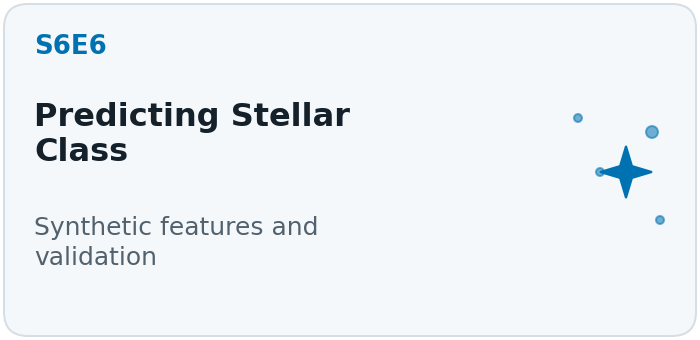</a></div>
<div style="display:inline-block;width:350px;max-width:100%;vertical-align:top;padding:4px;box-sizing:border-box;"><a href="https://www.kaggle.com/code/georgymamarin/s6e7-will-your-0-950-survive-the-private-split">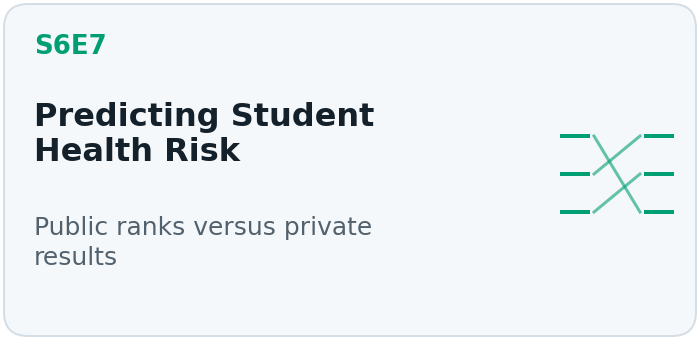</a></div>
<div style="display:inline-block;width:350px;max-width:100%;vertical-align:top;padding:4px;box-sizing:border-box;"><a href="https://www.kaggle.com/code/georgymamarin/s6e8-which-ideas-paid-and-which-ones-fooled-me">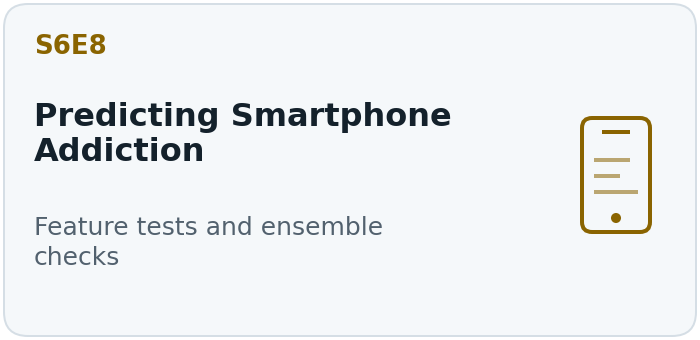</a></div>
<div style="display:inline-block;width:350px;max-width:100%;vertical-align:top;padding:4px;box-sizing:border-box;"><a href="https://www.kaggle.com/code/georgymamarin/s6e9-what-the-board-paid-for-eleven-submissions">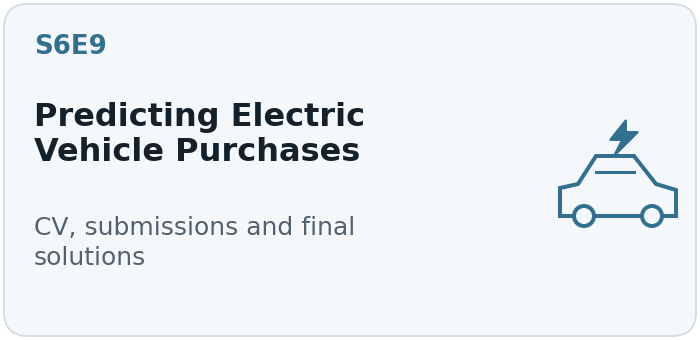</a></div>
<div style="display:inline-block;width:350px;max-width:100%;vertical-align:top;padding:4px;box-sizing:border-box;"><a href="https://www.kaggle.com/code/georgymamarin/s6e10-before-you-pick-your-final-two">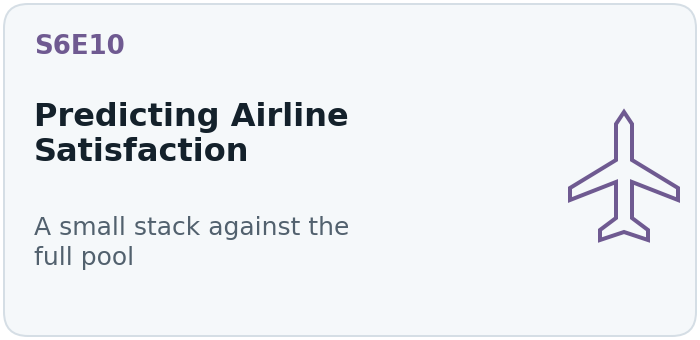</a></div>
</div>

### Sources and thanks

- [Evgeny Dvorkin's data investigation](https://www.kaggle.com/code/evgendvorkin/s6e11-deep-eda-original-data-artifacts) examines original-data fingerprints, risk interactions and all 24 predictors. It is a useful companion for readers who want to study the data before fitting a model.
- The [S6E11 competition page](https://www.kaggle.com/competitions/playground-series-s6e11) specifies the task, metric, files and source attribution.
- [Credit Card Fraud Detection 2026](https://www.kaggle.com/datasets/uditjain13/credit-card-fraud-detection-2026) provides the original CSV and the author's description of its synthetic generation.
- The [scikit-learn target-encoding guide](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.TargetEncoder.html) documents internal cross-fitting. The [XGBoost GPU guide](https://xgboost.readthedocs.io/en/stable/gpu/index.html) describes the CUDA device setting.
- The [LightGBM parameter guide](https://lightgbm.readthedocs.io/en/stable/Parameters.html) and the [scikit-learn ROC AUC documentation](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_auc_score.html) describe the model and scoring behaviour.
- [goodpjw2008's value and digit study](https://www.kaggle.com/code/goodpjw2008/s6e11-part-3-digits-leak-the-label-lb-0-95113) and [Alex Chilton's shallow-tree work](https://www.kaggle.com/code/alexchilton/credit-card-fraud-lb-0-9496-shallow-tree-stack) motivated the bounded representation ablations. Our fixed budgets, encoder implementation and models differ from their published ensembles.
- Will Guesdon's [refined LightGBM recipe](https://www.kaggle.com/code/wguesdon/s6e11-refined-lightgbm) informed H5; [Aphoristic Artist's EDA](https://www.kaggle.com/code/aphoristicartist/s6e11-fraud-eda-3-gbdts-blend-lb-0-9468) motivated the flag-count test.
- The [SciPy permutation-test documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.permutation_test.html) explains randomised-test p-value counting. Our scripts implement the specified conditional fixed-count Monte Carlo tests directly.

We thank the organisers, the source author and the library maintainers. If you try another source-transfer or category-encoding recipe, please share its held-out score, fold deltas and exact training setup. Please include results that failed to improve the baseline too.